# 🤖 NewsBot Intelligence System
### Beyond Classification: Turning News Articles into Structured Intelligence

**Course:** ITAI 2373 | Natural Language Processing  
**Assignment:** Midterm Project  
**Author:** Huong Thi Hue Nguyen
**Date:** October 17, 2026
**Project Type:** Individual Project, Independently Developed  
**GitHub:** https://github.com/iamhuongthn/ITAI2373-NewsBot-Midterm

---

## Project Overview

News articles contain more than topics. They contain people, organizations, events, financial information, opinions, and relationships that are difficult to capture with a single category label.

For this midterm, I independently developed **NewsBot Intelligence System**, an end-to-end NLP prototype that transforms unstructured news articles into structured, interpretable information.

My approach is to treat classification as the starting point, not the final result. NewsBot identifies an article's category and combines that prediction with sentiment, emotion associations, grammatical patterns, syntactic relationships, and named entity recognition.

The goal is not simply to produce predictions. It is to understand what information the system extracts, evaluate how reliable its outputs are, and identify where human review remains necessary.

## Business Problem

News publishers, content analysts, and media-monitoring teams process large volumes of unstructured information.

NewsBot explores three practical questions:

1. **What is the article about?** Classify it into a relevant news category.
2. **What information does it contain?** Extract entities, linguistic patterns, sentiment, and relationships.
3. **How reliable is the analysis?** Evaluate classification performance, inspect extraction errors, and report limitations.

The prototype demonstrates how traditional NLP techniques can support content organization, information discovery, and media analysis.

## Dataset

**Source:** BBC News Classification Dataset  
https://www.kaggle.com/competitions/learn-ai-bbc/data

| Dataset Property | Result |
|---|---:|
| Original articles | 1,490 |
| Missing-value removals | 0 |
| Exact duplicate removals | 50 |
| Final articles | 1,440 |
| Training articles | 1,152 |
| Testing articles | 288 |
| News categories | 5 |

The five categories are Business, Entertainment, Politics, Sport, and Tech.

The dataset does not include original publication dates or independent headlines. This limits temporal analysis and headline-specific evaluation.

## NLP Implementation

The system integrates eight modules:

| Module | Implementation |
|---|---|
| 1. Real-World NLP Context | Problem definition and dataset exploration |
| 2. Text Preprocessing | Normalization, tokenization, stopword removal, and lemmatization |
| 3. TF-IDF | Vocabulary, word importance, and category-specific terms |
| 4. POS Analysis | Grammatical patterns across news categories |
| 5. Syntax Analysis | Dependency parsing and subject-verb-object patterns |
| 6. Sentiment and Emotion | VADER sentiment and NRC emotion associations |
| 7. Classification | Naive Bayes, Logistic Regression, and SVM |
| 8. Named Entity Recognition | Entity extraction, manual validation, and co-occurrence |

## Evaluation Approach

I used a stratified 80/20 train/test split and five-fold cross-validation on the training data.

TF-IDF and numerical transformations are fitted within cross-validation folds to reduce data leakage.

The primary model-selection metric is macro F1. Held-out accuracy, classification reports, confusion matrices, feature experiments, and manual NER review provide additional evidence.

I also tested the integrated system using seven synthetic articles and two external-source examples.

The external examples demonstrate end-to-end processing on text outside the BBC dataset. They are not treated as a statistically reliable external accuracy benchmark.

## Expected Output

NewsBot processes article text and produces:

- Predicted news category and model-estimated probabilities
- Sentiment polarity and interpretation
- Named entities and entity types
- Syntactic and grammatical information
- Interpretable insights

**Project focus:** Build a functional NLP system whose results can be measured, explained, and improved, rather than adding complexity without evidence of its value.


---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [x] **Module 1:** NLP applications and real-world context
- [x] **Module 2:** Text preprocessing pipeline
- [x] **Module 3:** TF-IDF feature extraction
- [x] **Module 4:** POS tagging analysis
- [x] **Module 5:** Syntax parsing and semantic analysis
- [x] **Module 6:** Sentiment and emotion analysis
- [x] **Module 7:** Text classification system
- [x] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# # Install required packages (run this cell first!)
# !pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
# !python -m spacy download en_core_web_sm
# %pip install -q --force-reinstall "NRCLex==3.0.0"

# # Download NLTK data
# import nltk
# nltk.download('punkt')
# nltk.download('stopwords')
# nltk.download('wordnet')
# nltk.download('vader_lexicon')
# nltk.download('averaged_perceptron_tagger')

# print("✅ All packages installed successfully!")


# ============================================================
# ENVIRONMENT SETUP AND DEPENDENCY VALIDATION
# ============================================================

import sys
import subprocess
import importlib.util
import nltk

# ------------------------------------------------------------
# 1. Install Python dependencies
# ------------------------------------------------------------

packages = [
    "spacy",
    "scikit-learn",
    "nltk",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "wordcloud",
    "plotly",
    "networkx",
    "scipy",
    "NRCLex==3.0.0"
]

subprocess.check_call([
    sys.executable,
    "-m", "pip", "install",
    "-q",
    *packages
])

print("Python dependencies installed.")

# ------------------------------------------------------------
# 2. Verify spaCy English model
# ------------------------------------------------------------

if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.check_call([
        sys.executable,
        "-m", "spacy",
        "download", "en_core_web_sm"
    ])

import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy English model available.")

# ------------------------------------------------------------
# 3. Check NLTK resources
# ------------------------------------------------------------

# Only download missing resources.
# Do not bypass NLTK proxy security checks.

resources = {
    "punkt_tab": "tokenizers/punkt_tab/english/",
    "stopwords": "corpora/stopwords",
    "wordnet": "corpora/wordnet.zip",
    "omw-1.4": "corpora/omw-1.4.zip",
    "vader_lexicon": "sentiment/vader_lexicon.zip",
    "averaged_perceptron_tagger_eng":
        "taggers/averaged_perceptron_tagger_eng/"
}

missing_resources = []

for resource, location in resources.items():

    try:
        nltk.data.find(location)
        print(f"Available: {resource}")

    except LookupError:
        print(f"Missing: {resource}")
        missing_resources.append(resource)

# ------------------------------------------------------------
# 4. Download missing resources if permitted
# ------------------------------------------------------------

if missing_resources:

    print("\nAttempting to download missing resources...")

    for resource in missing_resources:

        try:
            success = nltk.download(
                resource,
                quiet=True,
                raise_on_error=True
            )

            if not success:
                print(f"Download unsuccessful: {resource}")

        except Exception as exc:
            print(
                f"Could not download {resource}: "
                f"{type(exc).__name__}: {exc}"
            )

# ------------------------------------------------------------
# 5. Verify resources after installation
# ------------------------------------------------------------

still_missing = []

for resource, location in resources.items():

    try:
        nltk.data.find(location)

    except LookupError:
        still_missing.append(resource)

if still_missing:

    raise RuntimeError(
        "Required NLTK resources are unavailable: "
        + ", ".join(still_missing)
        + ". Install them from an approved source "
        "or use a runtime where they are preinstalled."
    )

# ------------------------------------------------------------
# 6. Validate NLP functionality
# ------------------------------------------------------------

from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nrclex import NRCLex

tokens = word_tokenize("NewsBot analyzes news articles.")

assert len(tokens) > 0
assert len(pos_tag(tokens)) == len(tokens)
assert len(stopwords.words("english")) > 0

lemmatizer = WordNetLemmatizer()
assert lemmatizer.lemmatize("cars") == "car"

sia = SentimentIntensityAnalyzer()
assert isinstance(
    sia.polarity_scores("This is excellent."),
    dict
)

nrc_test = NRCLex("joy fear trust")

print("\nNLP environment validation passed.")
print("NLTK, spaCy, VADER, and NRCLex are available.")


Python dependencies installed.
spaCy English model available.
Missing: punkt_tab
Missing: stopwords
Missing: wordnet
Missing: omw-1.4
Missing: vader_lexicon
Missing: averaged_perceptron_tagger_eng

Attempting to download missing resources...

NLP environment validation passed.
NLTK, spaCy, VADER, and NRCLex are available.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.


### Dataset Quality and Cleaning

The BBC News training dataset originally contained 1,490 records.

Before analysis, we removed records with missing article text or category labels and eliminated exact duplicate article content.

The resulting dataset contains 1,440 unique articles across five categories: Business, Entertainment, Politics, Sport, and Tech.

This cleaning step reduces repeated information and helps prevent identical articles from appearing in both training and testing datasets.

The notebook records the number of missing-value removals and exact duplicates separately to make preprocessing transparent and reproducible.

**Limitation:** Exact duplicate removal does not guarantee that near-duplicate articles or closely related news reports are absent.


In [ ]:
# # Load your dataset
# # 💡 TIP: If using the provided dataset, upload it to Colab first
# # 💡 TIP: You can also use sample datasets like BBC News or 20 Newsgroups

# # Option 1: Load provided dataset
# # df = pd.read_csv('news_dataset.csv')

# # Option 2: Load BBC News dataset (if using alternative)
# # You can download this from: https://www.kaggle.com/c/learn-ai-bbc/data

# # Option 3: Create sample data for testing (remove this when you have real data)
# sample_data = {
#     'article_id': range(1, 11),
#     'title': [
#         'Apple Inc. Reports Record Quarterly Earnings',
#         'Manchester United Defeats Chelsea 3-1',
#         'New AI Technology Revolutionizes Healthcare',
#         'President Biden Announces Climate Initiative',
#         'Netflix Releases New Original Series',
#         'Tesla Stock Rises After Production Update',
#         'Olympic Games Begin in Paris',
#         'Google Launches New Search Algorithm',
#         'Congress Passes Infrastructure Bill',
#         'Disney+ Subscriber Numbers Grow'
#     ],
#     'content': [
#         'Apple Inc. announced record quarterly earnings today, with CEO Tim Cook highlighting strong iPhone sales and services revenue growth.',
#         'Manchester United secured a convincing 3-1 victory over Chelsea at Old Trafford, with goals from Marcus Rashford and Bruno Fernandes.',
#         'A breakthrough AI system developed by researchers at Stanford University shows promise for early disease detection in medical imaging.',
#         'President Joe Biden unveiled a comprehensive climate change initiative aimed at reducing carbon emissions by 50% over the next decade.',
#         'Netflix premiered its latest original series to critical acclaim, featuring an ensemble cast and innovative storytelling techniques.',
#         'Tesla shares jumped 8% in after-hours trading following the company\'s announcement of increased production capacity at its Texas facility.',
#         'The 2024 Olympic Games officially began in Paris with a spectacular opening ceremony attended by world leaders and celebrities.',
#         'Google introduced a new search algorithm that promises more accurate and contextually relevant results for users worldwide.',
#         'The U.S. Congress passed a bipartisan infrastructure bill allocating $1.2 trillion for roads, bridges, and broadband expansion.',
#         'Disney+ reported strong subscriber growth in Q3, reaching 150 million subscribers globally across all markets.'
#     ],
#     'category': ['Business', 'Sports', 'Technology', 'Politics', 'Entertainment',
#                 'Business', 'Sports', 'Technology', 'Politics', 'Entertainment'],
#     'date': ['2024-01-15'] * 10,
#     'source': ['TechNews', 'SportsTimes', 'TechDaily', 'PoliticsToday', 'EntertainmentWeekly',
#               'BusinessWire', 'SportsCentral', 'TechReview', 'NewsNow', 'ShowBiz']
# }

# df = pd.DataFrame(sample_data)

# print(f"📊 Dataset loaded successfully!")
# print(f"📈 Shape: {df.shape}")
# print(f"📋 Columns: {list(df.columns)}")

# # Display first few rows
# df.head()



# Load your dataset
# Dataset: BBC News Classification Dataset
# Download: https://www.kaggle.com/c/learn-ai-bbc/data

import pandas as pd
from google.colab import files
from pathlib import Path

# Step 1: Upload BBC News Train.csv

# ============================================================
# DATASET LOADING: REUSE EXISTING BBC NEWS FILE
# ============================================================
DATA_DIR = Path("/content")
DATASET_PATH = DATA_DIR / "BBC News Train.csv"

# Upload only if the canonical dataset is missing.
if not DATASET_PATH.is_file():
    from google.colab import files

    print("BBC News dataset not found. Upload it once.")
    uploaded = files.upload()

    if not uploaded:
        raise FileNotFoundError("No dataset was uploaded.")

    uploaded_name = next(iter(uploaded))
    uploaded_path = DATA_DIR / uploaded_name

    if uploaded_path != DATASET_PATH:
        uploaded_path.rename(DATASET_PATH)

else:
    print("Reusing existing BBC News dataset.")

# Step 2: Load the dataset
# df = pd.read_csv('BBC News Train.csv')
df = pd.read_csv(DATASET_PATH)

print(f"Dataset: {DATASET_PATH.name}")
print(f"Rows: {len(df)}")
print(f"Columns: {list(df.columns)}")

# Step 3: Rename columns to match the original notebook
df = df.rename(columns={
    'ArticleId': 'article_id',
    'Text': 'content',
    'Category': 'category'
})

# Step 4: Add missing columns expected by the notebook
df['title'] = df['content'].str[:100]
df['date'] = pd.NaT
df['source'] = 'BBC News'

# Step 5: Keep the same column structure
df = df[
    ['article_id', 'title', 'content',
     'category', 'date', 'source']
]

# Step 6: Data quality and duplicate removal

original_count = len(df)

# Count missing values before removing rows.
missing_content = int(df['content'].isna().sum())
missing_category = int(df['category'].isna().sum())

# Remove rows with missing article text or category.
df = df.dropna(
    subset=['content', 'category']
).copy()

after_missing_removal = len(df)

removed_missing = (
    original_count - after_missing_removal
)

# Remove exact duplicate article content.
duplicate_count = int(
    df.duplicated(subset=['content']).sum()
)

df = df.drop_duplicates(
    subset=['content']
).copy()

final_count = len(df)

removed_duplicates = (
    after_missing_removal - final_count
)

total_removed = original_count - final_count

# ------------------------------------------------------------
# 7. Display data-cleaning audit
# ------------------------------------------------------------

cleaning_summary = pd.DataFrame({
    'Stage': [
        'Original dataset',
        'After missing-value removal',
        'After duplicate removal'
    ],
    'Articles': [
        original_count,
        after_missing_removal,
        final_count
    ]
})

print("\nDATA CLEANING SUMMARY")
print("=" * 60)

display(cleaning_summary)

print(f"Original articles: {original_count}")
print(f"Missing content values: {missing_content}")
print(f"Missing category values: {missing_category}")
print(f"Rows removed for missing values: {removed_missing}")
print(f"Exact duplicate articles removed: {removed_duplicates}")
print(f"Total rows removed: {total_removed}")
print(f"Final articles: {final_count}")

print(
    f"Data retention: "
    f"{final_count / original_count * 100:.2f}%"
)

assert (
    original_count
    == final_count + removed_missing + removed_duplicates
)

assert df['content'].notna().all()
assert df['category'].notna().all()
assert not df.duplicated(subset=['content']).any()

print("\nDATASET READY")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

display(df.head())




BBC News dataset not found. Upload it once.


Saving BBC News Train.csv to BBC News Train.csv
Dataset: BBC News Train.csv
Rows: 1490
Columns: ['ArticleId', 'Text', 'Category']

DATA CLEANING SUMMARY


,Stage,Articles
0,Original dataset,1490
1,After missing-value removal,1490
2,After duplicate removal,1440


Original articles: 1490
Missing content values: 0
Missing category values: 0
Rows removed for missing values: 0
Exact duplicate articles removed: 50
Total rows removed: 50
Final articles: 1440
Data retention: 96.64%

DATASET READY
Shape: (1440, 6)
Columns: ['article_id', 'title', 'content', 'category', 'date', 'source']


,article_id,title,content,category,date,source
0,1833,worldcom ex-boss launches defence lawyers defe...,worldcom ex-boss launches defence lawyers defe...,business,NaT,BBC News
1,154,german business confidence slides german busin...,german business confidence slides german busin...,business,NaT,BBC News
2,1101,bbc poll indicates economic gloom citizens in ...,bbc poll indicates economic gloom citizens in ...,business,NaT,BBC News
3,1976,lifestyle governs mobile choice faster bett...,lifestyle governs mobile choice faster bett...,tech,NaT,BBC News
4,917,enron bosses in $168m payout eighteen former e...,enron bosses in $168m payout eighteen former e...,business,NaT,BBC News


📊 DATASET OVERVIEW
Total articles: 1440
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']
Date range: Not available in BBC dataset
Unique sources: 1

📈 CATEGORY DISTRIBUTION
category
sport            342
business         335
politics         266
entertainment    263
tech             234
Name: count, dtype: int64


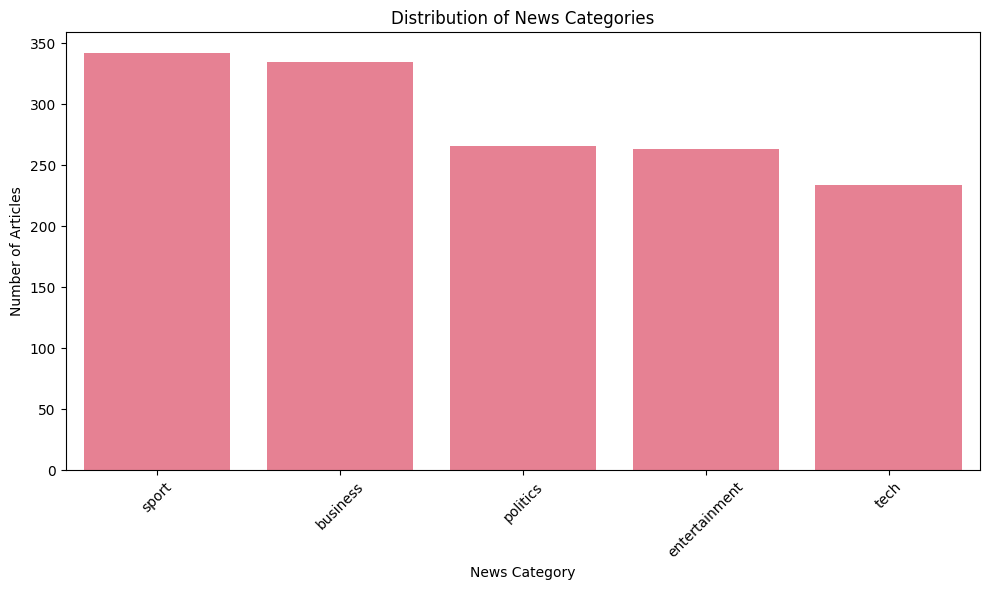


🔍 MISSING VALUES
article_id       0
title            0
content          0
category         0
date          1440
source           0
dtype: int64

Missing required fields:
content     0
category    0
dtype: int64

📝 TEXT LENGTH ANALYSIS
count    1440.000000
mean      385.215972
std       212.167106
min        90.000000
25%       253.000000
50%       337.000000
75%       468.250000
max      3345.000000
Name: word_count, dtype: float64

Average words per category:
category
tech             509.2
politics         451.6
sport            336.9
entertainment    335.4
business         334.3
Name: word_count, dtype: float64


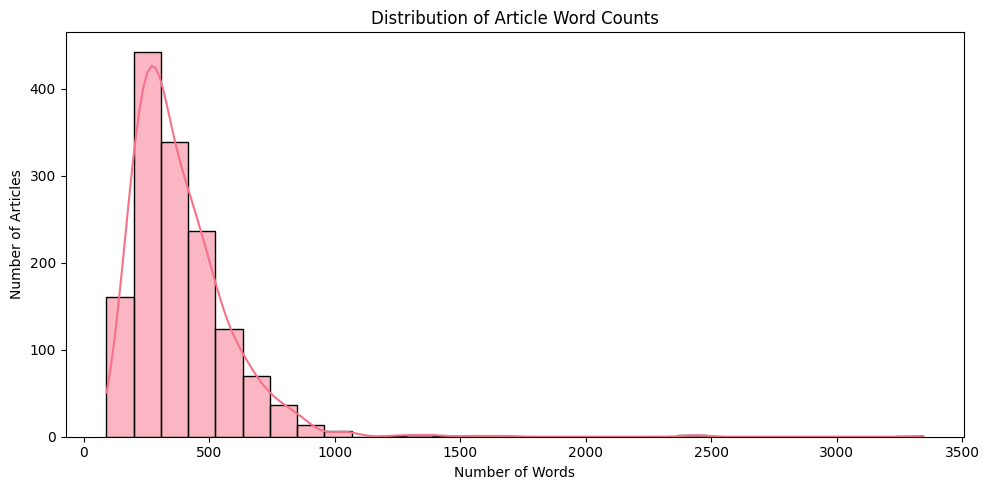

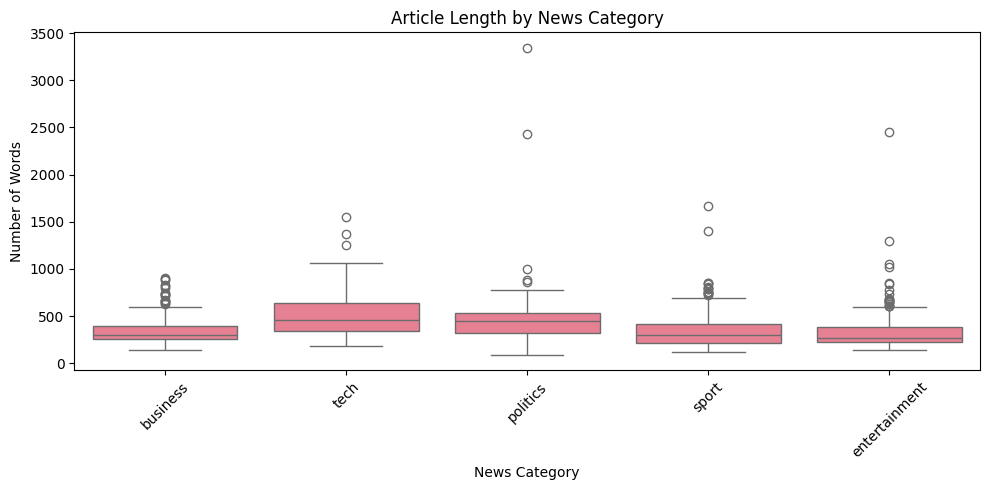


📰 SOURCE DISTRIBUTION
source
BBC News    1440
Name: count, dtype: int64

Note: All articles are from the BBC News dataset.
Source comparison is not applicable.

⚠️ DATA QUALITY CHECK
Duplicate articles: 0
Empty articles: 0
Short articles (<50 words): 0
Missing categories: 0

Category balance (%):
category
sport            23.75
business         23.26
politics         18.47
entertainment    18.26
tech             16.25
Name: count, dtype: float64

✅ EXPLORATORY DATA ANALYSIS COMPLETE
Articles analyzed: 1440
Categories: 5
Average article length: 385.2 words
Median article length: 337.0 words
Duplicate articles: 0
Empty articles: 0
Short articles: 0

Dataset exploration completed.
Ready for Module 2: Text Preprocessing Pipeline.


In [ ]:
# # Basic dataset exploration
# print("📊 DATASET OVERVIEW")
# print("=" * 50)
# print(f"Total articles: {len(df)}")
# print(f"Unique categories: {df['category'].nunique()}")
# print(f"Categories: {df['category'].unique().tolist()}")
# print(f"Date range: {df['date'].min()} to {df['date'].max()}")
# print(f"Unique sources: {df['source'].nunique()}")

# print("\n📈 CATEGORY DISTRIBUTION")
# print("=" * 50)
# category_counts = df['category'].value_counts()
# print(category_counts)

# # Visualize category distribution
# plt.figure(figsize=(10, 6))
# sns.countplot(data=df, x='category', order=category_counts.index)
# plt.title('Distribution of News Categories')
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

# # 💡 STUDENT TASK: Add your own exploratory analysis here
# # - Check for missing values
# # - Analyze text length distribution
# # - Examine source distribution
# # - Look for any data quality issues

# ============================================================
# MODULE 1: BASIC DATASET EXPLORATION
# NewsBot Intelligence System - Midterm Project
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")

# Date range (BBC dataset does not provide dates)
if df['date'].notna().any():
    print(f"Date range: {df['date'].min()} to {df['date'].max()}")
else:
    print("Date range: Not available in BBC dataset")

print(f"Unique sources: {df['source'].nunique()}")

# ============================================================
# CATEGORY DISTRIBUTION
# ============================================================

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)

category_counts = df['category'].value_counts()
print(category_counts)

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xlabel('News Category')
plt.ylabel('Number of Articles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# STUDENT TASK 1: CHECK FOR MISSING VALUES
# ============================================================

print("\n🔍 MISSING VALUES")
print("=" * 50)

print(df.isnull().sum())

print("\nMissing required fields:")
print(df[['content', 'category']].isnull().sum())

# ============================================================
# STUDENT TASK 2: TEXT LENGTH DISTRIBUTION
# ============================================================

df['word_count'] = df['content'].str.split().str.len()
df['char_count'] = df['content'].str.len()

print("\n📝 TEXT LENGTH ANALYSIS")
print("=" * 50)

print(df['word_count'].describe())

print("\nAverage words per category:")
print(
    df.groupby('category')['word_count']
      .mean()
      .round(1)
      .sort_values(ascending=False)
)

# Word count histogram
plt.figure(figsize=(10, 5))
sns.histplot(df['word_count'], bins=30, kde=True)
plt.title('Distribution of Article Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Number of Articles')
plt.tight_layout()
plt.show()

# Article length by category
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='category', y='word_count')
plt.title('Article Length by News Category')
plt.xlabel('News Category')
plt.ylabel('Number of Words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# STUDENT TASK 3: SOURCE DISTRIBUTION
# ============================================================

print("\n📰 SOURCE DISTRIBUTION")
print("=" * 50)

source_counts = df['source'].value_counts()
print(source_counts)

print("\nNote: All articles are from the BBC News dataset.")
print("Source comparison is not applicable.")

# ============================================================
# STUDENT TASK 4: DATA QUALITY CHECK
# ============================================================

print("\n⚠️ DATA QUALITY CHECK")
print("=" * 50)

duplicate_articles = df['content'].duplicated().sum()
empty_articles = df['content'].str.strip().eq('').sum()
short_articles = (df['word_count'] < 50).sum()
missing_categories = df['category'].isnull().sum()

print(f"Duplicate articles: {duplicate_articles}")
print(f"Empty articles: {empty_articles}")
print(f"Short articles (<50 words): {short_articles}")
print(f"Missing categories: {missing_categories}")

print("\nCategory balance (%):")
category_percentages = (
    category_counts / len(df) * 100
).round(2)

print(category_percentages)

# ============================================================
# FINAL EXPLORATORY ANALYSIS SUMMARY
# ============================================================

print("\n✅ EXPLORATORY DATA ANALYSIS COMPLETE")
print("=" * 50)

print(f"Articles analyzed: {len(df)}")
print(f"Categories: {df['category'].nunique()}")
print(f"Average article length: {df['word_count'].mean():.1f} words")
print(f"Median article length: {df['word_count'].median():.1f} words")
print(f"Duplicate articles: {duplicate_articles}")
print(f"Empty articles: {empty_articles}")
print(f"Short articles: {short_articles}")

print("\nDataset exploration completed.")
print("Ready for Module 2: Text Preprocessing Pipeline.")


## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
# # Initialize preprocessing tools
# lemmatizer = WordNetLemmatizer()
# stop_words = set(stopwords.words('english'))

# def clean_text(text):
#     """
#     Comprehensive text cleaning function

#     💡 TIP: This function should handle:
#     - HTML tags and entities
#     - URLs and email addresses
#     - Special characters and numbers
#     - Extra whitespace
#     """
#     if pd.isna(text):
#         return ""

#     # Convert to string and lowercase
#     text = str(text).lower()

#     # 🚀 YOUR CODE HERE: Implement text cleaning
#     # Remove HTML tags
#     text = re.sub(r'<[^>]+>', '', text)

#     # Remove URLs
#     text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

#     # Remove email addresses
#     text = re.sub(r'\S+@\S+', '', text)

#     # Remove special characters and digits (keep only letters and spaces)
#     text = re.sub(r'[^a-zA-Z\s]', '', text)

#     # Remove extra whitespace
#     text = re.sub(r'\s+', ' ', text).strip()

#     return text

# def preprocess_text(text, remove_stopwords=True, lemmatize=True):
#     """
#     Complete preprocessing pipeline

#     💡 TIP: This function should:
#     - Clean the text
#     - Tokenize into words
#     - Remove stop words (optional)
#     - Lemmatize words (optional)
#     - Return processed text
#     """
#     # Clean text
#     text = clean_text(text)

#     if not text:
#         return ""

#     # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
#     # Tokenize
#     tokens = word_tokenize(text)

#     # Remove stop words if requested
#     if remove_stopwords:
#         tokens = [token for token in tokens if token not in stop_words]

#     # Lemmatize if requested
#     if lemmatize:
#         tokens = [lemmatizer.lemmatize(token) for token in tokens]

#     # Filter out very short words
#     tokens = [token for token in tokens if len(token) > 2]

#     return ' '.join(tokens)

# # Test the preprocessing function
# sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
# print("Original text:")
# print(sample_text)
# print("\nCleaned text:")
# print(clean_text(sample_text))
# print("\nFully preprocessed text:")
# print(preprocess_text(sample_text))


# ============================================================
# MODULE 2: TEXT PREPROCESSING PIPELINE
# NewsBot Intelligence System - Midterm Project
# ============================================================

import re
import html
import pandas as pd
import nltk

from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

# ------------------------------------------------------------
# STEP 1: Download required NLTK resources
# ------------------------------------------------------------

for resource in [
    'punkt',
    'punkt_tab',
    'stopwords',
    'wordnet',
    'omw-1.4',
    'averaged_perceptron_tagger_eng'
]:
    nltk.download(resource, quiet=True)

# ------------------------------------------------------------
# STEP 2: Initialize preprocessing tools
# ------------------------------------------------------------

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Preserve negation words for sentiment analysis
negation_words = {
    'no', 'not', 'nor', 'never',
    'against', 'without'
}

stop_words = stop_words - negation_words

# ------------------------------------------------------------
# STEP 3: Text cleaning function
# ------------------------------------------------------------

def clean_text(text):
    """
    Clean raw news article text.

    Handles:
    - Missing values
    - HTML tags and entities
    - URLs and email addresses
    - Lowercase normalization
    - Special characters
    - Extra whitespace

    Preserves numbers because dates, percentages,
    financial values and statistics are important
    in news articles.
    """

    if pd.isna(text):
        return ""

    # Convert to string
    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    # Remove email addresses
    text = re.sub(
        r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b',
        ' ',
        text
    )

    # Expand common English contractions
    contractions = {
        "can't": "cannot",
        "won't": "will not",
        "n't": " not",
        "'re": " are",
        "'ve": " have",
        "'ll": " will",
        "'d": " would",
        "'m": " am",
        "'s": " is"
    }

    for contraction, expansion in contractions.items():
        text = text.replace(contraction, expansion)

    # Convert to lowercase
    text = text.lower()

    # Remove special characters but preserve numbers
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# ------------------------------------------------------------
# STEP 4: POS-aware lemmatization
# ------------------------------------------------------------

def get_wordnet_pos(treebank_tag):
    """
    Convert NLTK POS tags to WordNet POS tags
    for more accurate lemmatization.
    """

    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN


# ------------------------------------------------------------
# STEP 5: Complete preprocessing pipeline
# ------------------------------------------------------------

def preprocess_text(
    text,
    remove_stopwords=True,
    lemmatize=True
):
    """
    Complete NLP preprocessing pipeline.

    Steps:
    1. Clean raw text
    2. Tokenize into words
    3. Remove stop words (optional)
    4. Apply POS-aware lemmatization (optional)
    5. Remove uninformative short tokens
    6. Return processed text
    """

    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stop words
    if remove_stopwords:
        tokens = [
            token for token in tokens
            if token not in stop_words
        ]

    # POS-aware lemmatization
    if lemmatize and tokens:
        tagged_tokens = pos_tag(tokens)

        tokens = [
            lemmatizer.lemmatize(
                token,
                get_wordnet_pos(tag)
            )
            for token, tag in tagged_tokens
        ]

    # Filter short tokens while preserving
    # negation words and meaningful numbers
    tokens = [
        token for token in tokens
        if len(token) > 2
        or token in negation_words
        or token.isdigit()
    ]

    return ' '.join(tokens)


# ------------------------------------------------------------
# STEP 6: Test preprocessing function
# ------------------------------------------------------------

sample_text = (
    "Apple Inc. announced record quarterly earnings today! "
    "Revenue increased by 15% to $120 billion in 2024. "
    "Visit https://apple.com for more info. "
    "The company isn't expecting a decline. "
    "#TechNews"
)

print("=" * 60)
print("TEXT PREPROCESSING TEST")
print("=" * 60)

print("\nOriginal text:")
print(sample_text)

print("\nCleaned text:")
print(clean_text(sample_text))

print("\nFully preprocessed text:")
print(preprocess_text(sample_text))


# ------------------------------------------------------------
# STEP 7: Test edge cases
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EDGE CASE TESTING")
print("=" * 60)

test_cases = {
    "Missing value": None,
    "Empty text": "",
    "HTML content": "<p>Apple &amp; Google announced updates.</p>",
    "URL and email": "Visit https://example.com or email test@example.com",
    "Numbers": "Revenue increased 25% in 2024.",
    "Negation": "The company did not report a loss.",
    "Extra spaces": "This    is     a    test.",
    "Mixed case": "ARTIFICIAL Intelligence Is Growing FAST!"
}

for case_name, text in test_cases.items():
    print(f"\n{case_name}")
    print(f"Input: {text}")
    print(f"Output: {preprocess_text(text)}")


# ------------------------------------------------------------
# STEP 8: Preprocess the real BBC News dataset
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PREPROCESSING BBC NEWS DATASET")
print("=" * 60)

# Preserve original text for sentiment, NER,
# POS tagging and dependency parsing
df['original_content'] = df['content'].copy()

# Clean text
df['cleaned_text'] = df['content'].apply(clean_text)

# Fully preprocess text
df['processed_text'] = df['content'].apply(preprocess_text)

# Calculate before/after word counts
df['original_word_count'] = (
    df['original_content'].str.split().str.len()
)

df['processed_word_count'] = (
    df['processed_text'].str.split().str.len()
)

# Calculate reduction percentage
original_total = df['original_word_count'].sum()
processed_total = df['processed_word_count'].sum()

reduction = (
    (original_total - processed_total) / original_total * 100
    if original_total > 0 else 0
)

print(f"Total articles processed: {len(df)}")
print(f"Original total words: {original_total:,}")
print(f"Processed total words: {processed_total:,}")
print(f"Word count reduction: {reduction:.2f}%")

print("\nAverage words per article:")
print(
    f"Before: {df['original_word_count'].mean():.1f}"
)
print(
    f"After: {df['processed_word_count'].mean():.1f}"
)

print("\nEmpty processed articles:",
      (df['processed_text'] == '').sum())


# ------------------------------------------------------------
# STEP 9: Display preprocessing examples
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PREPROCESSING EXAMPLES")
print("=" * 60)

for i in range(min(3, len(df))):
    row = df.iloc[i]

    print(f"\nARTICLE {i + 1}")
    print(f"Category: {row['category']}")

    print("\nOriginal:")
    print(row['original_content'][:300])

    print("\nProcessed:")
    print(row['processed_text'][:300])

    print("-" * 60)


# ------------------------------------------------------------
# STEP 10: Final preprocessing summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MODULE 2 PREPROCESSING COMPLETE")
print("=" * 60)

print("Completed:")
print("✓ Text cleaning and normalization")
print("✓ HTML and URL removal")
print("✓ Tokenization")
print("✓ Stop word removal")
print("✓ POS-aware lemmatization")
print("✓ Negation preservation")
print("✓ Number preservation")
print("✓ Edge case testing")
print("✓ Before/after word count analysis")

print("\nDataset columns:")
print(df.columns.tolist())

print("\nReady for Module 3: TF-IDF Feature Extraction")


TEXT PREPROCESSING TEST

Original text:
Apple Inc. announced record quarterly earnings today! Revenue increased by 15% to $120 billion in 2024. Visit https://apple.com for more info. The company isn't expecting a decline. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today revenue increased by 15 to 120 billion in 2024 visit for more info the company is not expecting a decline technews

Fully preprocessed text:
apple inc announce record quarterly earnings today revenue increase 15 120 billion 2024 visit info company not expect decline technews

EDGE CASE TESTING

Missing value
Input: None
Output: 

Empty text
Input: 
Output: 

HTML content
Input: <p>Apple &amp; Google announced updates.</p>
Output: apple google announce update

URL and email
Input: Visit https://example.com or email test@example.com
Output: visit email

Numbers
Input: Revenue increased 25% in 2024.
Output: revenue increase 25 2024

Negation
Input: The company did not report a loss.
Output: comp

🧹 Preprocessing all articles...
✅ Preprocessing complete!
Total articles processed: 1440

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Category: business
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  ...
Processed: worldcom bos launch defence lawyer defend former worldcom chief bernie ebbers against battery fraud charge call company whistleblower first witness cynthia cooper worldcom head internal accounting ale...

Example 2:
Category: business
Original: german business confidence slides german business confidence fell in february knocking hopes of a speedy recovery in europe s largest economy.  munich-based research institute ifo said that its confid...
Processed: german business confidence slides german business confidence fell february knocking hop speedy recovery europe large economy munich base research institute ifo say co

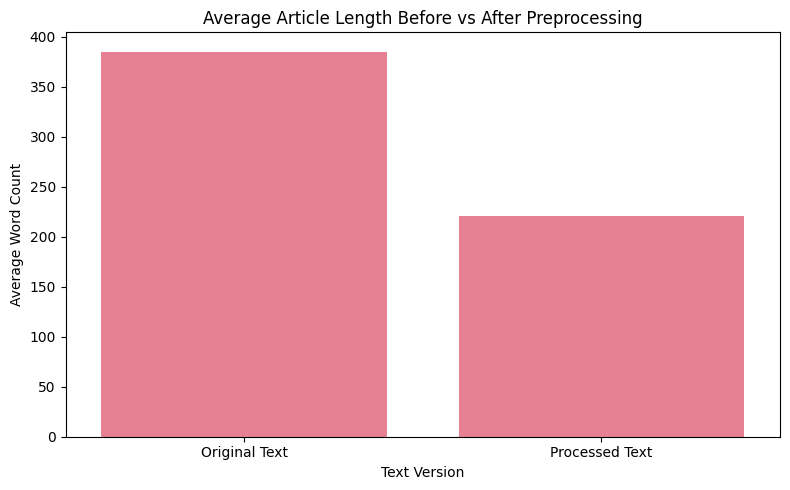


🔤 VOCABULARY ANALYSIS
Unique words before: 24,778
Unique words after: 20,268
Vocabulary reduction: 18.20%


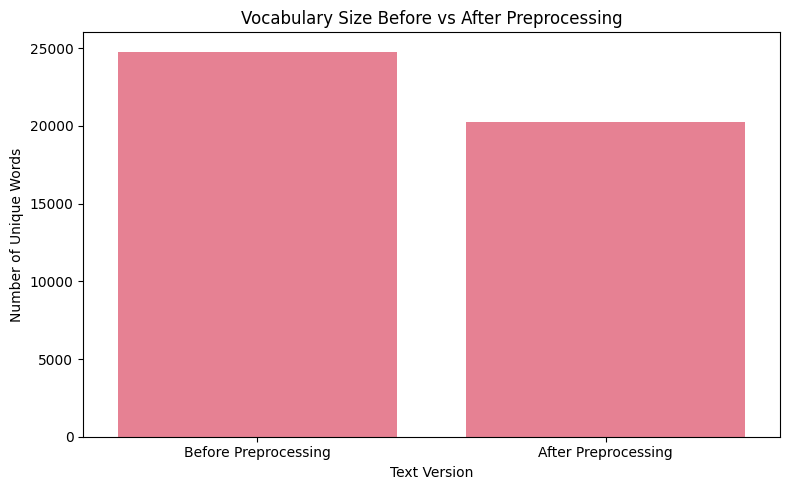


🏆 MOST COMMON WORDS AFTER PREPROCESSING


,Word,Frequency
0,say,5707
1,not,2260
2,year,2107
3,would,1652
4,make,1414
5,also,1366
6,new,1313
7,people,1246
8,one,1230
9,take,1097


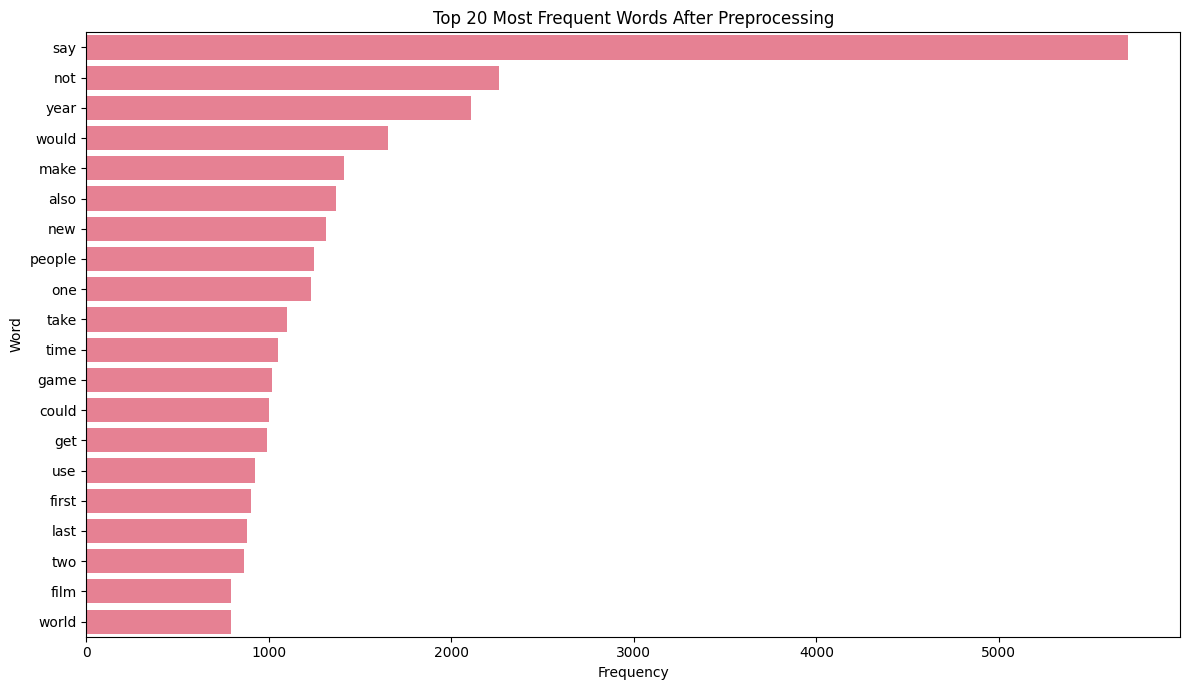


📊 PREPROCESSING RESULTS BY CATEGORY


,Articles,Avg_Words_Before,Avg_Words_After,Reduction_Percent
category,,,,
business,335,334.27,201.36,39.76
entertainment,263,335.44,194.57,42.00
politics,266,451.64,250.07,44.63
sport,342,336.88,189.89,43.63
tech,234,509.22,288.74,43.30



✅ MODULE 2: PREPROCESSING ANALYSIS COMPLETE
Articles processed: 1440
Average words before: 385.22
Average words after: 220.59
Word count reduction: 42.74%
Unique words before: 24,778
Unique words after: 20,268
Vocabulary reduction: 18.20%

Completed student tasks:
✓ Calculate average text length before and after
✓ Count unique words before and after
✓ Identify most common words after preprocessing
✓ Visualize preprocessing results
✓ Compare preprocessing impact by category

Ready for Module 3: TF-IDF Feature Extraction


In [ ]:
# # Apply preprocessing to the dataset
# print("🧹 Preprocessing all articles...")

# # Create new columns for processed text
# df['title_clean'] = df['title'].apply(clean_text)
# df['content_clean'] = df['content'].apply(clean_text)
# df['title_processed'] = df['title'].apply(preprocess_text)
# df['content_processed'] = df['content'].apply(preprocess_text)

# # Combine title and content for full article analysis
# df['full_text'] = df['title'] + ' ' + df['content']
# df['full_text_processed'] = df['full_text'].apply(preprocess_text)

# print("✅ Preprocessing complete!")

# # Show before and after examples
# print("\n📝 BEFORE AND AFTER EXAMPLES")
# print("=" * 60)
# for i in range(min(3, len(df))):
#     print(f"\nExample {i+1}:")
#     print(f"Original: {df.iloc[i]['full_text'][:100]}...")
#     print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# # 💡 STUDENT TASK: Analyze the preprocessing results
# # - Calculate average text length before and after
# # - Count unique words before and after
# # - Identify the most common words after preprocessing



# ============================================================
# MODULE 2: APPLY PREPROCESSING TO THE DATASET
# NewsBot Intelligence System - Midterm Project
# ============================================================

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# STEP 1: Apply preprocessing to all articles
# ------------------------------------------------------------

print("🧹 Preprocessing all articles...")

# Ensure title and content are valid strings
df['title'] = df['title'].fillna('').astype(str)
df['content'] = df['content'].fillna('').astype(str)

# Create new columns for cleaned and processed text
df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)

df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
# BBC titles are generated from article content, so avoid
# duplicating the opening text in the combined field.
if df['source'].eq('BBC News').all():
    df['full_text'] = df['content']
else:
    df['full_text'] = (
        df['title'].str.strip() + ' ' +
        df['content'].str.strip()
    ).str.strip()

df['full_text_processed'] = (
    df['full_text'].apply(preprocess_text)
)

print("✅ Preprocessing complete!")
print(f"Total articles processed: {len(df)}")


# ------------------------------------------------------------
# STEP 2: Show before and after examples
# ------------------------------------------------------------

print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)

for i in range(min(3, len(df))):
    print(f"\nExample {i + 1}:")
    print(f"Category: {df.iloc[i]['category']}")
    print(f"Original: {df.iloc[i]['full_text'][:200]}...")
    print(
        f"Processed: "
        f"{df.iloc[i]['full_text_processed'][:200]}..."
    )


# ------------------------------------------------------------
# STUDENT TASK 1: Average text length before and after
# ------------------------------------------------------------

print("\n📏 TEXT LENGTH ANALYSIS")
print("=" * 60)

df['original_word_count'] = (
    df['full_text'].str.split().str.len()
)

df['processed_word_count'] = (
    df['full_text_processed'].str.split().str.len()
)

avg_before = df['original_word_count'].mean()
avg_after = df['processed_word_count'].mean()

total_before = df['original_word_count'].sum()
total_after = df['processed_word_count'].sum()

reduction_percent = (
    (total_before - total_after) / total_before * 100
    if total_before > 0 else 0
)

print(f"Average words before: {avg_before:.2f}")
print(f"Average words after: {avg_after:.2f}")
print(f"Total words before: {total_before:,}")
print(f"Total words after: {total_after:,}")
print(f"Word count reduction: {reduction_percent:.2f}%")

# Visualize average word counts
plt.figure(figsize=(8, 5))

sns.barplot(
    x=['Original Text', 'Processed Text'],
    y=[avg_before, avg_after]
)

plt.title('Average Article Length Before vs After Preprocessing')
plt.xlabel('Text Version')
plt.ylabel('Average Word Count')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STUDENT TASK 2: Count unique words before and after
# ------------------------------------------------------------

print("\n🔤 VOCABULARY ANALYSIS")
print("=" * 60)

# Use the same cleaning rules for a fair comparison
# before stopword removal and lemmatization.
original_tokens = [
    word
    for text in df['full_text'].apply(clean_text)
    for word in text.split()
]

processed_tokens = [
    word
    for text in df['full_text_processed']
    for word in text.split()
]

original_vocab = set(original_tokens)
processed_vocab = set(processed_tokens)

unique_before = len(original_vocab)
unique_after = len(processed_vocab)

vocab_reduction = (
    (unique_before - unique_after) / unique_before * 100
    if unique_before > 0 else 0
)

print(f"Unique words before: {unique_before:,}")
print(f"Unique words after: {unique_after:,}")
print(f"Vocabulary reduction: {vocab_reduction:.2f}%")

# Visualize vocabulary size
plt.figure(figsize=(8, 5))

sns.barplot(
    x=['Before Preprocessing', 'After Preprocessing'],
    y=[unique_before, unique_after]
)

plt.title('Vocabulary Size Before vs After Preprocessing')
plt.xlabel('Text Version')
plt.ylabel('Number of Unique Words')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STUDENT TASK 3: Most common words after preprocessing
# ------------------------------------------------------------

print("\n🏆 MOST COMMON WORDS AFTER PREPROCESSING")
print("=" * 60)

word_frequencies = Counter(processed_tokens)

top_20_words = word_frequencies.most_common(20)

top_words_df = pd.DataFrame(
    top_20_words,
    columns=['Word', 'Frequency']
)

display(top_words_df)

# Visualize top 20 words
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_words_df,
    x='Frequency',
    y='Word'
)

plt.title('Top 20 Most Frequent Words After Preprocessing')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 6: Compare preprocessing results by category
# ------------------------------------------------------------

print("\n📊 PREPROCESSING RESULTS BY CATEGORY")
print("=" * 60)

category_summary = (
    df.groupby('category')
      .agg(
          Articles=('category', 'size'),
          Avg_Words_Before=('original_word_count', 'mean'),
          Avg_Words_After=('processed_word_count', 'mean')
      )
      .round(2)
)

category_summary['Reduction_Percent'] = (
    (
        category_summary['Avg_Words_Before'] -
        category_summary['Avg_Words_After']
    ) /
    category_summary['Avg_Words_Before'].replace(0, float('nan'))
    * 100
).round(2)

display(category_summary)

# ------------------------------------------------------------
# STEP 7: Final preprocessing summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 2: PREPROCESSING ANALYSIS COMPLETE")
print("=" * 60)

print(f"Articles processed: {len(df)}")
print(f"Average words before: {avg_before:.2f}")
print(f"Average words after: {avg_after:.2f}")
print(f"Word count reduction: {reduction_percent:.2f}%")
print(f"Unique words before: {unique_before:,}")
print(f"Unique words after: {unique_after:,}")
print(f"Vocabulary reduction: {vocab_reduction:.2f}%")

print("\nCompleted student tasks:")
print("✓ Calculate average text length before and after")
print("✓ Count unique words before and after")
print("✓ Identify most common words after preprocessing")
print("✓ Visualize preprocessing results")
print("✓ Compare preprocessing impact by category")

print("\nReady for Module 3: TF-IDF Feature Extraction")


## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

🔢 Creating TF-IDF features...
Total articles: 1440
Empty processed articles: 0

⚙️ TF-IDF PARAMETER COMPARISON


,Configuration,Max Features,Ngram Range,Vocabulary Size,Nonzero Values,Sparsity (%)
0,Unigrams,3000,"(1, 1)",3000,167262,96.13
1,Unigrams + Bigrams,5000,"(1, 2)",5000,194300,97.30
2,Extended Vocabulary,8000,"(1, 2)",8000,215064,98.13



TF-IDF MATRIX SUMMARY
✅ TF-IDF matrix created!
📊 Shape: (1440, 5000)
📝 Vocabulary size: 5000
🔢 Nonzero values: 194,300
🔢 Sparsity: 97.30%

Selected parameters:
5000
Ngram range: (1, 2)
Min document frequency: 2
Max document frequency: 0.8

🔍 SAMPLE TF-IDF FEATURES


,000,000 job,000 new,000 people,000 year,000m,05,10,10 000,10 000m
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0.046949,0,0
2,0.036766,0,0,0.06484,0,0,0,0,0,0



🏆 TOP 20 TERMS BY AVERAGE TF-IDF


,Term,Average TF-IDF
0,year,0.025370
1,not,0.024623
2,would,0.021386
3,make,0.020287
4,also,0.019973
5,new,0.019386
6,one,0.018653
7,take,0.017992
8,people,0.017642
9,time,0.017443


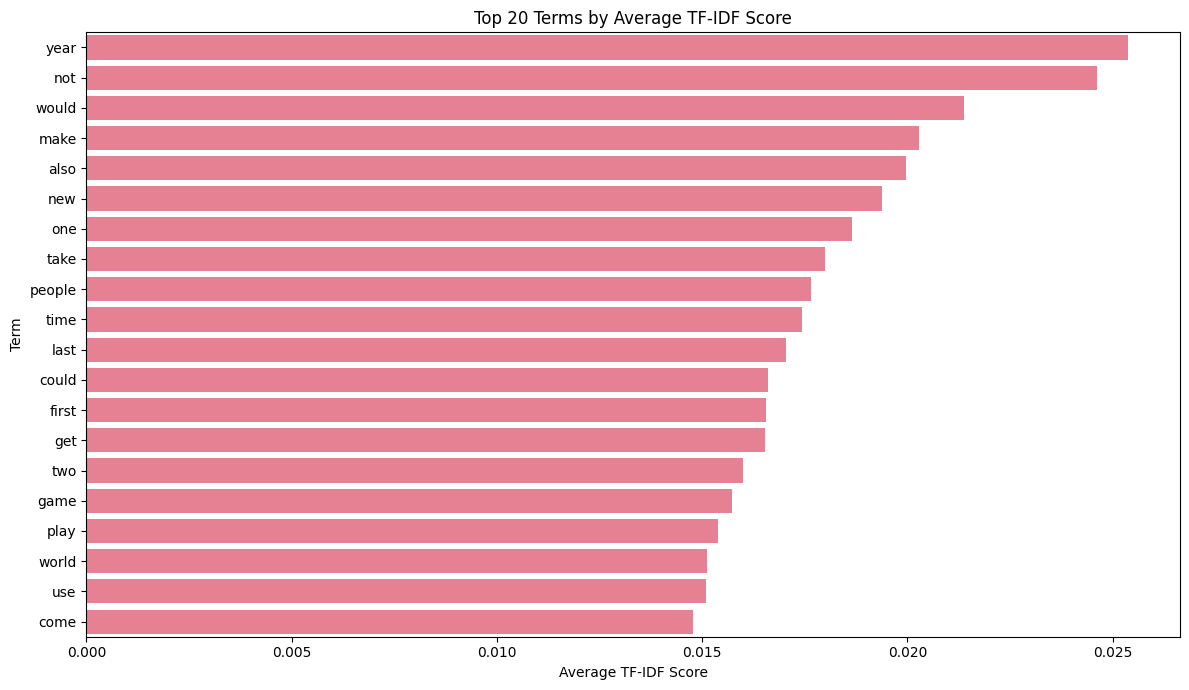


📚 TOP TF-IDF TERMS BY NEWS CATEGORY

Category: business
---------------------------------------------


,Term,Average TF-IDF
0,firm,0.037858
1,company,0.037150
2,market,0.035364
3,year,0.031211
4,share,0.029246
5,growth,0.029072
6,bank,0.028342
7,rise,0.028262
8,economy,0.027841
9,sale,0.026151



Category: entertainment
---------------------------------------------


,Term,Average TF-IDF
0,film,0.065487
1,star,0.047475
2,award,0.042254
3,best,0.033404
4,actor,0.032256
5,show,0.031046
6,year,0.031010
7,music,0.029918
8,include,0.028497
9,oscar,0.026618



Category: politics
---------------------------------------------


,Term,Average TF-IDF
0,labour,0.048986
1,election,0.048507
2,party,0.044048
3,government,0.043363
4,blair,0.043151
5,minister,0.042954
6,tory,0.040057
7,would,0.039501
8,not,0.033546
9,plan,0.031193



Category: sport
---------------------------------------------


,Term,Average TF-IDF
0,game,0.041152
1,win,0.038468
2,play,0.035020
3,player,0.032439
4,match,0.032284
5,champion,0.029760
6,team,0.028860
7,england,0.028029
8,against,0.027647
9,not,0.027163



Category: tech
---------------------------------------------


,Term,Average TF-IDF
0,use,0.045691
1,people,0.042547
2,user,0.040073
3,technology,0.038485
4,computer,0.035053
5,software,0.033495
6,mobile,0.032255
7,phone,0.031500
8,service,0.031035
9,net,0.030167


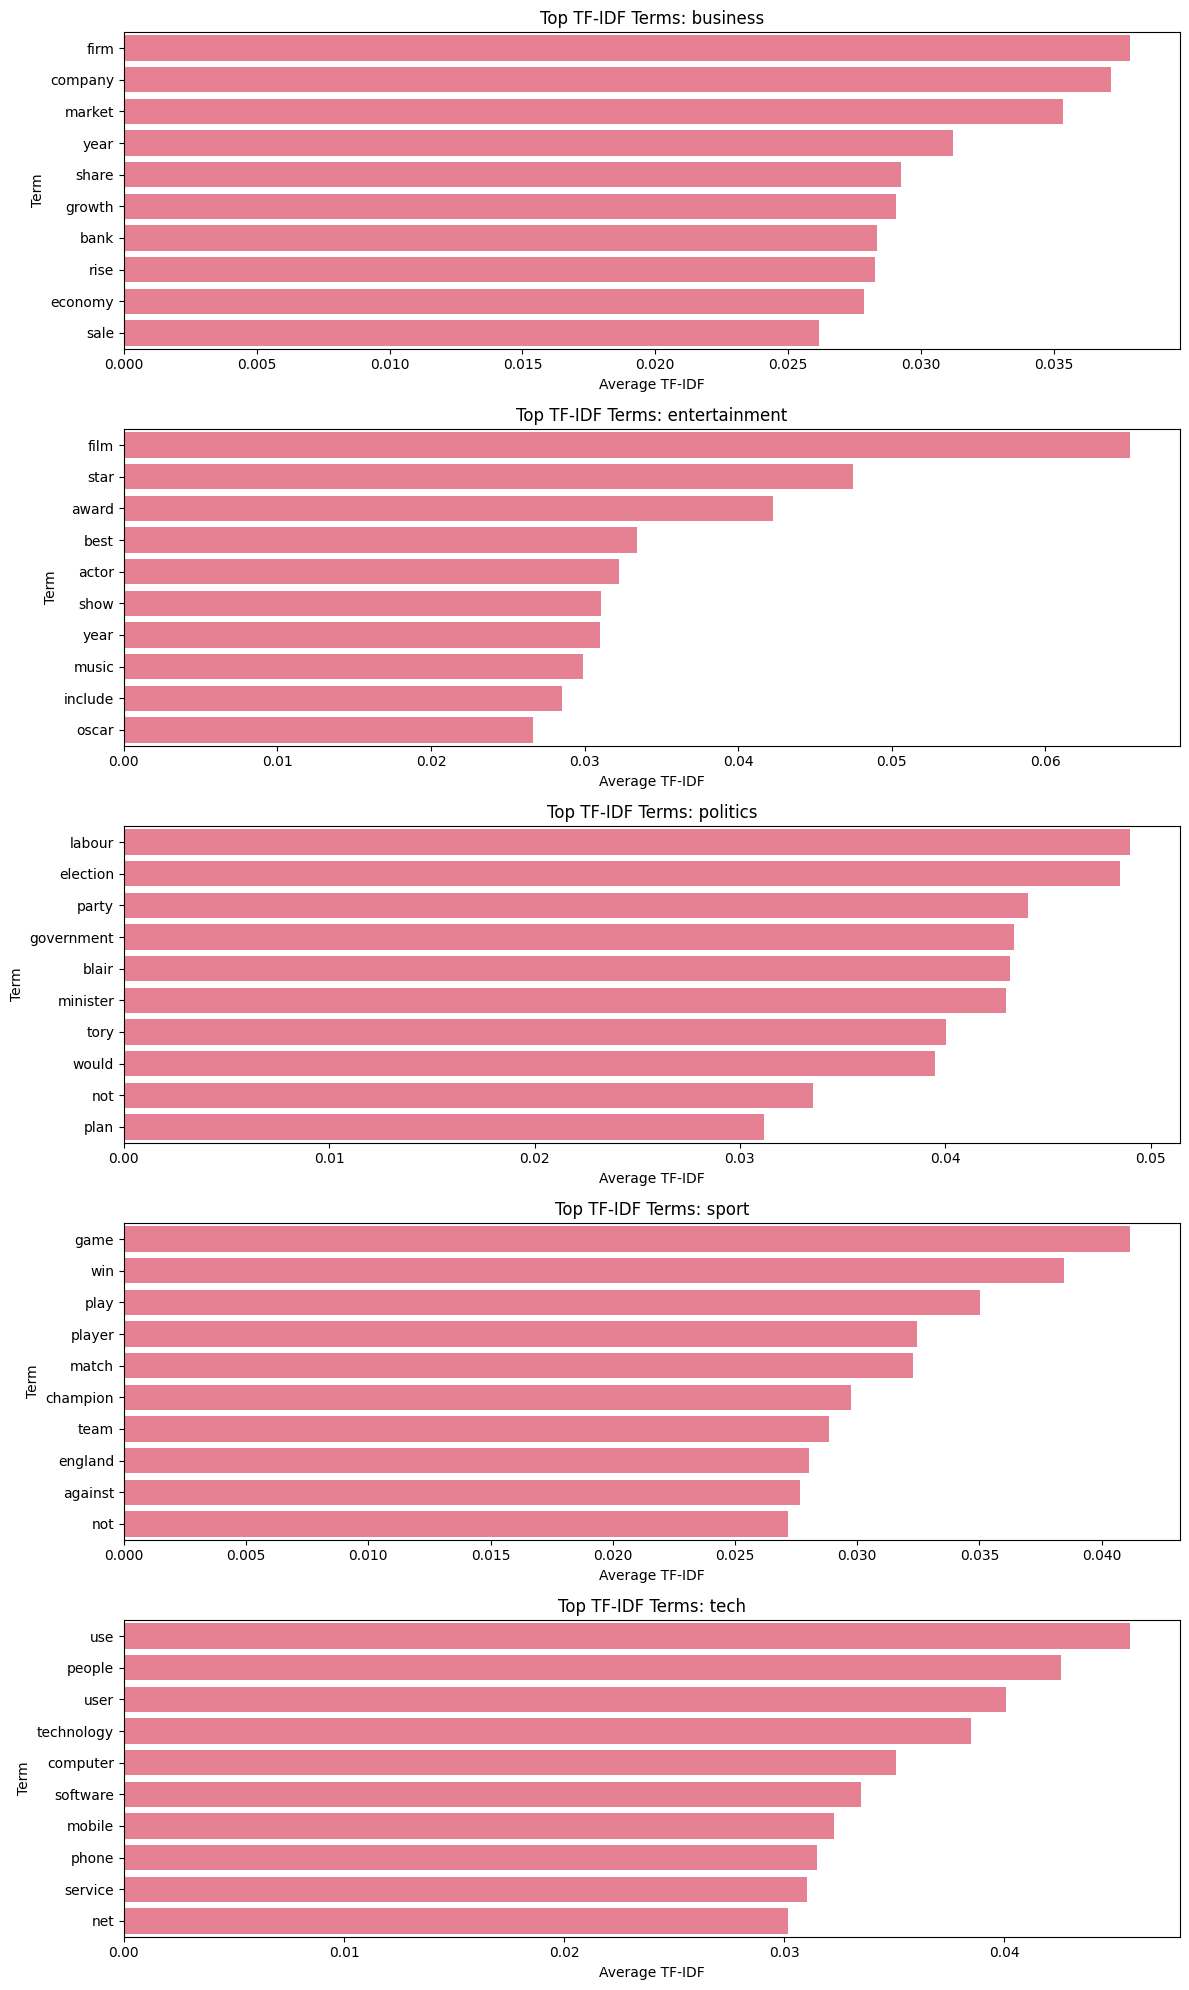

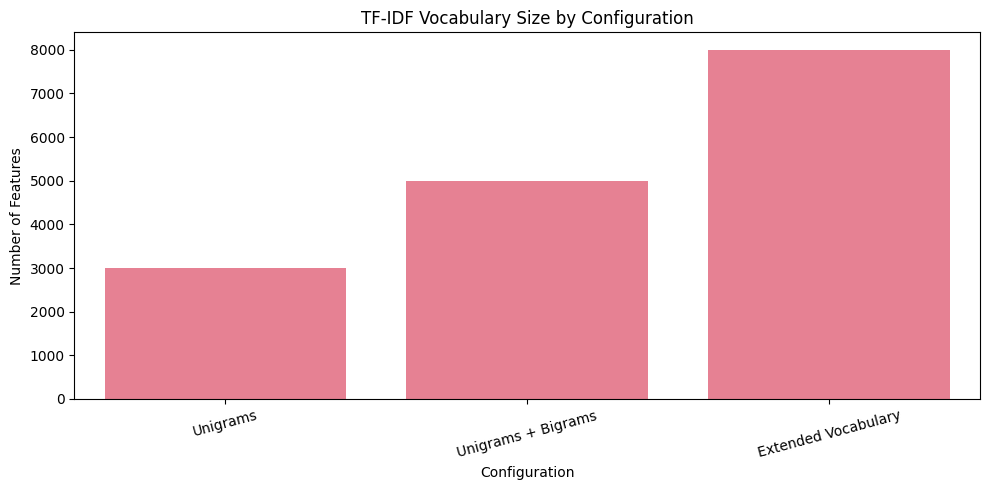


✅ MODULE 3: TF-IDF ANALYSIS COMPLETE
Articles analyzed: 1440
TF-IDF features: 5000
Matrix sparsity: 97.30%
Categories analyzed: 5

Completed:
✓ TF-IDF feature extraction
✓ Unigram and bigram analysis
✓ Parameter configuration comparison
✓ Vocabulary and sparsity analysis
✓ Top 20 TF-IDF terms
✓ Category-specific feature analysis
✓ TF-IDF visualizations

Note: This TF-IDF matrix is for exploratory analysis.
For Module 7 classification, fit TF-IDF only
on training data to prevent data leakage.

Ready for the next TF-IDF analysis cell.


In [ ]:
# # Create TF-IDF vectorizer
# # 💡 TIP: Experiment with different parameters:
# # - max_features: limit vocabulary size
# # - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# # - min_df: ignore terms that appear in less than min_df documents
# # - max_df: ignore terms that appear in more than max_df fraction of documents

# tfidf_vectorizer = TfidfVectorizer(
#     max_features=5000,  # Limit vocabulary for computational efficiency
#     ngram_range=(1, 2),  # Include unigrams and bigrams
#     min_df=2,  # Ignore terms that appear in less than 2 documents
#     max_df=0.8  # Ignore terms that appear in more than 80% of documents
# )

# # Fit and transform the processed text
# print("🔢 Creating TF-IDF features...")
# tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
# feature_names = tfidf_vectorizer.get_feature_names_out()

# print(f"✅ TF-IDF matrix created!")
# print(f"📊 Shape: {tfidf_matrix.shape}")
# print(f"📝 Vocabulary size: {len(feature_names)}")
# print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# # Convert to DataFrame for easier analysis
# tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
# tfidf_df['category'] = df['category'].values

# print("\n🔍 Sample TF-IDF features:")
# print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features


# ============================================================
# MODULE 3: TF-IDF FEATURE EXTRACTION AND ANALYSIS
# NewsBot Intelligence System - Midterm Project
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------------------
# STEP 1: Prepare processed text
# ------------------------------------------------------------

print("🔢 Creating TF-IDF features...")
print("=" * 60)

texts = df['full_text_processed'].fillna('').astype(str)

print(f"Total articles: {len(texts)}")
print(f"Empty processed articles: {(texts.str.strip() == '').sum()}")

# ------------------------------------------------------------
# STEP 2: Compare TF-IDF parameter configurations
# ------------------------------------------------------------

print("\n⚙️ TF-IDF PARAMETER COMPARISON")
print("=" * 60)

configurations = [
    {
        'name': 'Unigrams',
        'max_features': 3000,
        'ngram_range': (1, 1),
        'min_df': 2,
        'max_df': 0.8
    },
    {
        'name': 'Unigrams + Bigrams',
        'max_features': 5000,
        'ngram_range': (1, 2),
        'min_df': 2,
        'max_df': 0.8
    },
    {
        'name': 'Extended Vocabulary',
        'max_features': 8000,
        'ngram_range': (1, 2),
        'min_df': 2,
        'max_df': 0.9
    }
]

comparison_results = []

for config in configurations:

    vectorizer = TfidfVectorizer(
        max_features=config['max_features'],
        ngram_range=config['ngram_range'],
        min_df=config['min_df'],
        max_df=config['max_df']
    )

    matrix = vectorizer.fit_transform(texts)

    total_elements = matrix.shape[0] * matrix.shape[1]

    sparsity = (
        (1 - matrix.nnz / total_elements) * 100
        if total_elements > 0 else 0
    )

    comparison_results.append({
        'Configuration': config['name'],
        'Max Features': config['max_features'],
        'Ngram Range': str(config['ngram_range']),
        'Vocabulary Size': matrix.shape[1],
        'Nonzero Values': matrix.nnz,
        'Sparsity (%)': round(sparsity, 2)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

# ------------------------------------------------------------
# STEP 3: Create final TF-IDF vectorizer
# ------------------------------------------------------------

# Selected configuration for the exploratory analysis
# Model performance will be evaluated in Module 7.

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.8,
    sublinear_tf=True
)

# Fit and transform processed articles
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

feature_names = tfidf_vectorizer.get_feature_names_out()

# ------------------------------------------------------------
# STEP 4: Display TF-IDF statistics
# ------------------------------------------------------------

total_elements = (
    tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
)

sparsity = (
    (1 - tfidf_matrix.nnz / total_elements) * 100
    if total_elements > 0 else 0
)

print("\n" + "=" * 60)
print("TF-IDF MATRIX SUMMARY")
print("=" * 60)

print("✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Nonzero values: {tfidf_matrix.nnz:,}")
print(f"🔢 Sparsity: {sparsity:.2f}%")

print("\nSelected parameters:")
print(tfidf_vectorizer.get_params()['max_features'])
print("Ngram range:", tfidf_vectorizer.ngram_range)
print("Min document frequency:", tfidf_vectorizer.min_df)
print("Max document frequency:", tfidf_vectorizer.max_df)

# ------------------------------------------------------------
# STEP 5: Convert TF-IDF matrix to DataFrame
# ------------------------------------------------------------

# Keep sparse representation to reduce memory usage
tfidf_df = pd.DataFrame.sparse.from_spmatrix(
    tfidf_matrix,
    columns=feature_names,
    index=df.index
)

tfidf_df['category'] = df['category'].values

print("\n🔍 SAMPLE TF-IDF FEATURES")
print("=" * 60)

display(
    tfidf_df.iloc[:3, :10]
)

# ------------------------------------------------------------
# STEP 6: Identify highest average TF-IDF terms
# ------------------------------------------------------------

print("\n🏆 TOP 20 TERMS BY AVERAGE TF-IDF")
print("=" * 60)

mean_tfidf = np.asarray(
    tfidf_matrix.mean(axis=0)
).ravel()

top_indices = np.argsort(mean_tfidf)[-20:][::-1]

top_terms_df = pd.DataFrame({
    'Term': feature_names[top_indices],
    'Average TF-IDF': mean_tfidf[top_indices]
})

display(top_terms_df)

# Visualize top TF-IDF terms
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_terms_df,
    x='Average TF-IDF',
    y='Term'
)

plt.title('Top 20 Terms by Average TF-IDF Score')
plt.xlabel('Average TF-IDF Score')
plt.ylabel('Term')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 7: Category-specific TF-IDF analysis
# ------------------------------------------------------------

print("\n📚 TOP TF-IDF TERMS BY NEWS CATEGORY")
print("=" * 60)

category_top_terms = {}

for category in sorted(df['category'].unique()):

    category_mask = (
        df['category'].to_numpy() == category
    )

    category_matrix = tfidf_matrix[category_mask]

    category_mean = np.asarray(
        category_matrix.mean(axis=0)
    ).ravel()

    category_top_indices = np.argsort(
        category_mean
    )[-10:][::-1]

    category_terms = feature_names[category_top_indices]
    category_scores = category_mean[category_top_indices]

    category_top_terms[category] = list(category_terms)

    print(f"\nCategory: {category}")
    print("-" * 45)

    category_terms_df = pd.DataFrame({
        'Term': category_terms,
        'Average TF-IDF': category_scores
    })

    display(category_terms_df)

# ------------------------------------------------------------
# STEP 8: Visualize category-specific terms
# ------------------------------------------------------------

categories = sorted(df['category'].unique())

fig, axes = plt.subplots(
    len(categories),
    1,
    figsize=(12, 4 * len(categories))
)

axes = np.atleast_1d(axes)

for ax, category in zip(axes, categories):

    category_mask = (
        df['category'].to_numpy() == category
    )

    category_mean = np.asarray(
        tfidf_matrix[category_mask].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(
        category_mean
    )[-10:][::-1]

    sns.barplot(
        x=category_mean[top_idx],
        y=feature_names[top_idx],
        ax=ax
    )

    ax.set_title(f'Top TF-IDF Terms: {category}')
    ax.set_xlabel('Average TF-IDF')
    ax.set_ylabel('Term')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 9: Visualize parameter comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_df,
    x='Configuration',
    y='Vocabulary Size'
)

plt.title('TF-IDF Vocabulary Size by Configuration')
plt.xlabel('Configuration')
plt.ylabel('Number of Features')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 10: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 3: TF-IDF ANALYSIS COMPLETE")
print("=" * 60)

print(f"Articles analyzed: {tfidf_matrix.shape[0]}")
print(f"TF-IDF features: {tfidf_matrix.shape[1]}")
print(f"Matrix sparsity: {sparsity:.2f}%")
print(f"Categories analyzed: {len(categories)}")

print("\nCompleted:")
print("✓ TF-IDF feature extraction")
print("✓ Unigram and bigram analysis")
print("✓ Parameter configuration comparison")
print("✓ Vocabulary and sparsity analysis")
print("✓ Top 20 TF-IDF terms")
print("✓ Category-specific feature analysis")
print("✓ TF-IDF visualizations")

print("\nNote: This TF-IDF matrix is for exploratory analysis.")
print("For Module 7 classification, fit TF-IDF only")
print("on training data to prevent data leakage.")

print("\nReady for the next TF-IDF analysis cell.")


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS
---------------------------------------------
  firm: 0.0379
  company: 0.0372
  market: 0.0354
  year: 0.0312
  share: 0.0292
  growth: 0.0291
  bank: 0.0283
  rise: 0.0283
  economy: 0.0278
  sale: 0.0262

📰 ENTERTAINMENT
---------------------------------------------
  film: 0.0655
  star: 0.0475
  award: 0.0423
  best: 0.0334
  actor: 0.0323
  show: 0.0310
  year: 0.0310
  music: 0.0299
  include: 0.0285
  oscar: 0.0266

📰 POLITICS
---------------------------------------------
  labour: 0.0490
  election: 0.0485
  party: 0.0440
  government: 0.0434
  blair: 0.0432
  minister: 0.0430
  tory: 0.0401
  would: 0.0395
  not: 0.0335
  plan: 0.0312

📰 SPORT
---------------------------------------------
  game: 0.0412
  win: 0.0385
  play: 0.0350
  player: 0.0324
  match: 0.0323
  champion: 0.0298
  team: 0.0289
  england: 0.0280
  against: 0.0276
  not: 0.0272

📰 TECH
---------------------------------------------
  use: 0.0457
  people: 0.0425
  

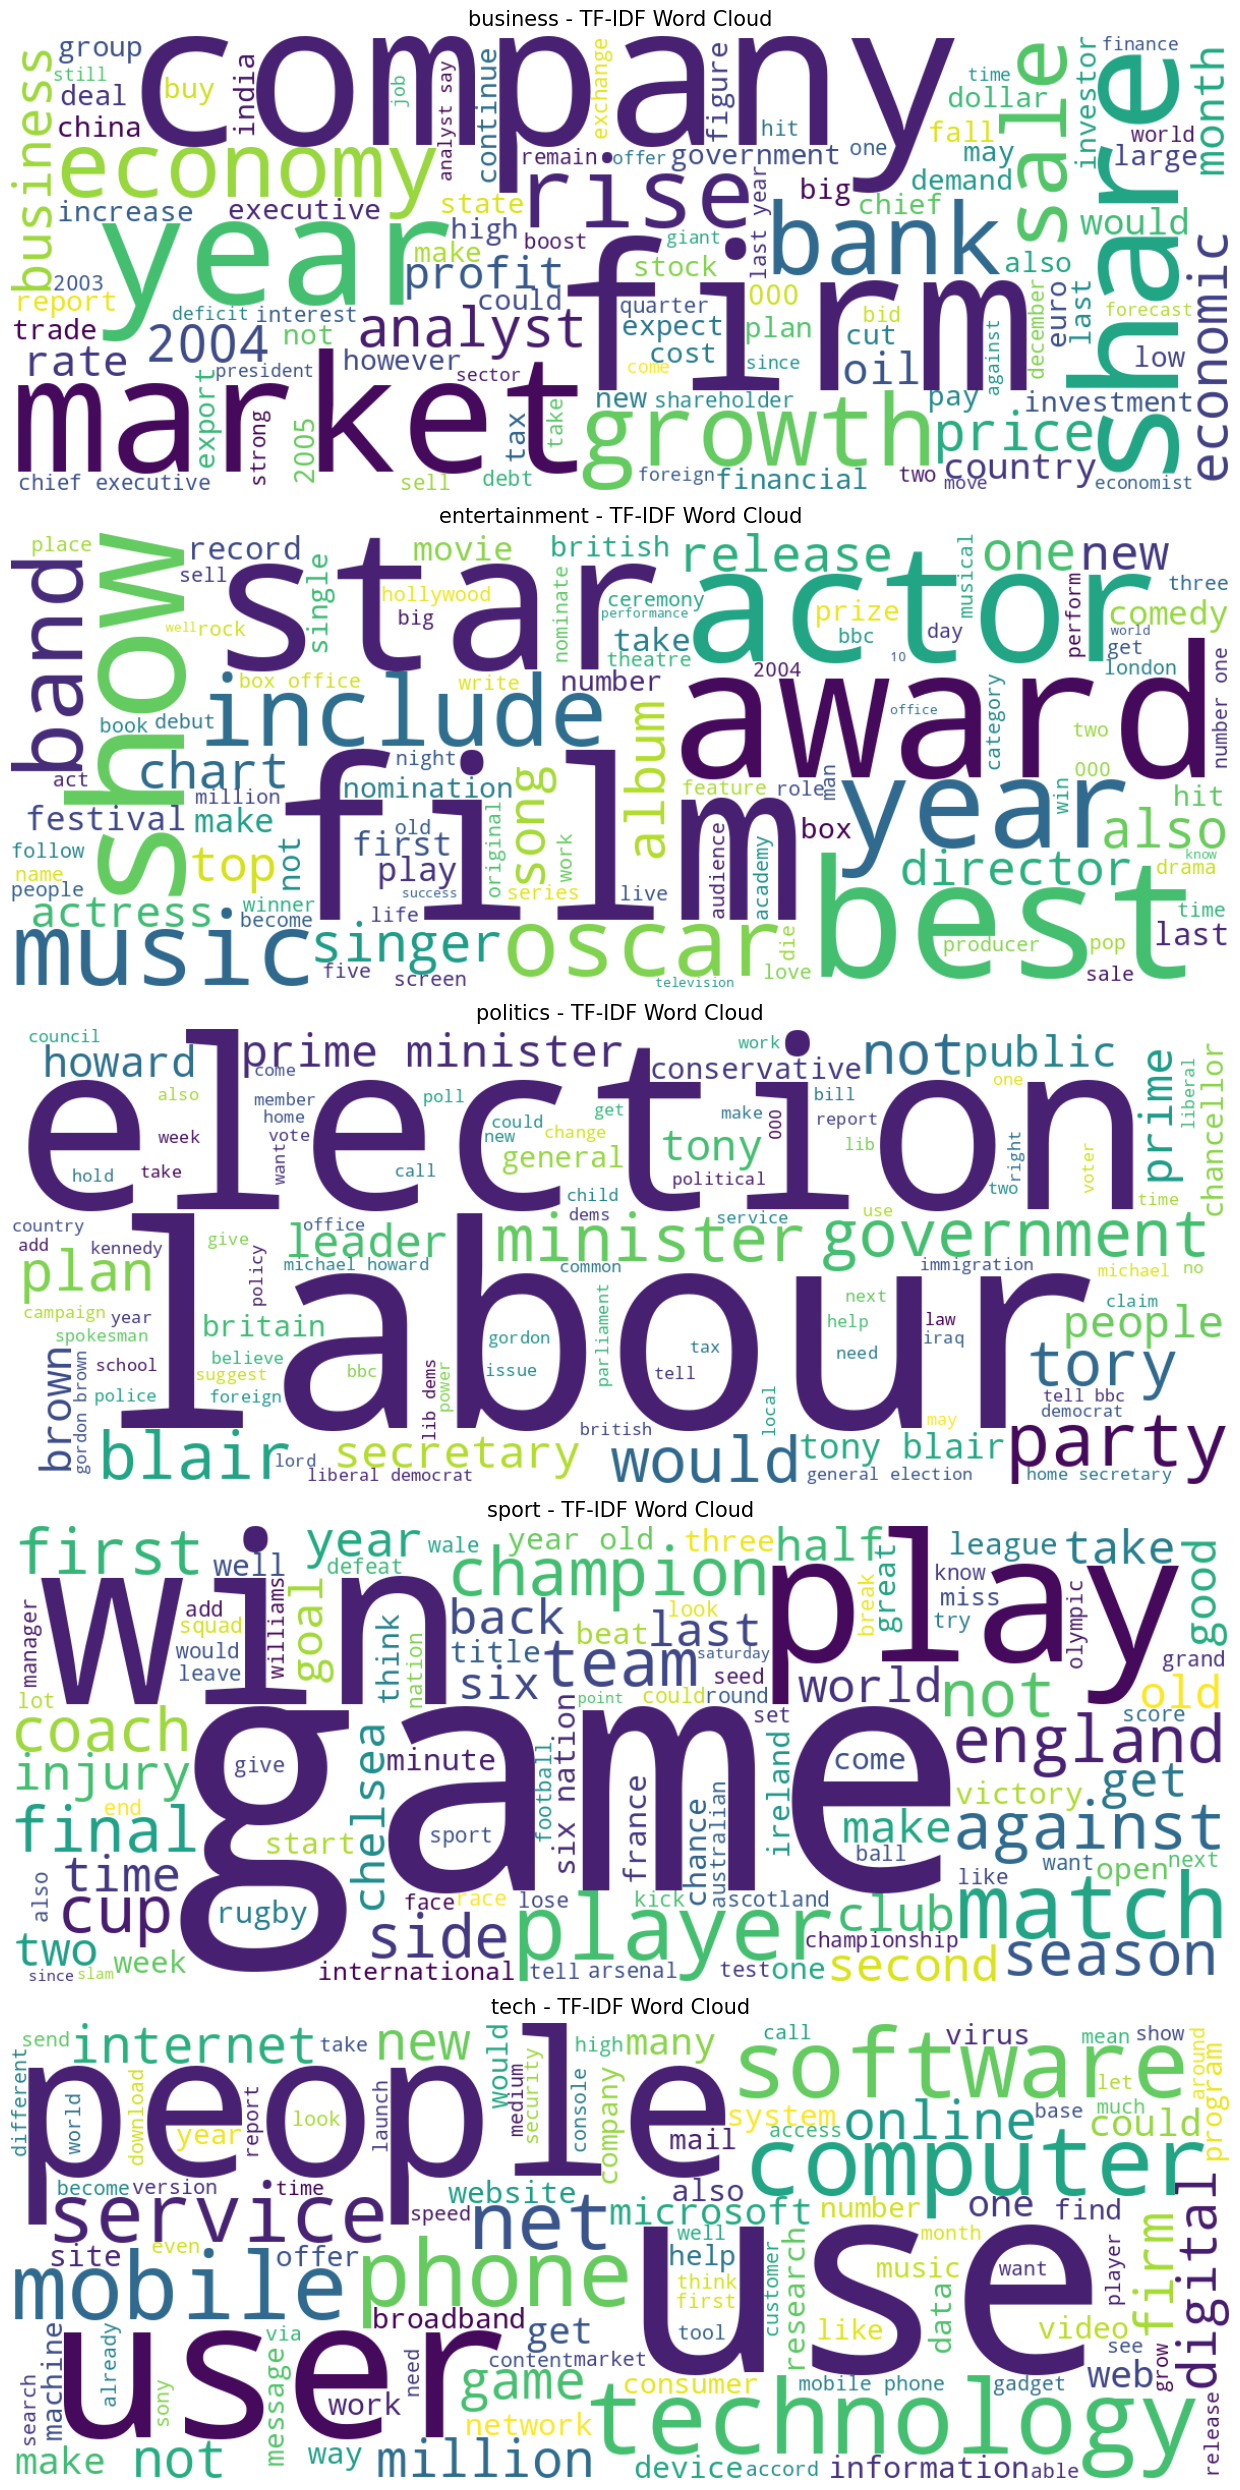


📊 GENERATING TOP TERM BAR CHARTS


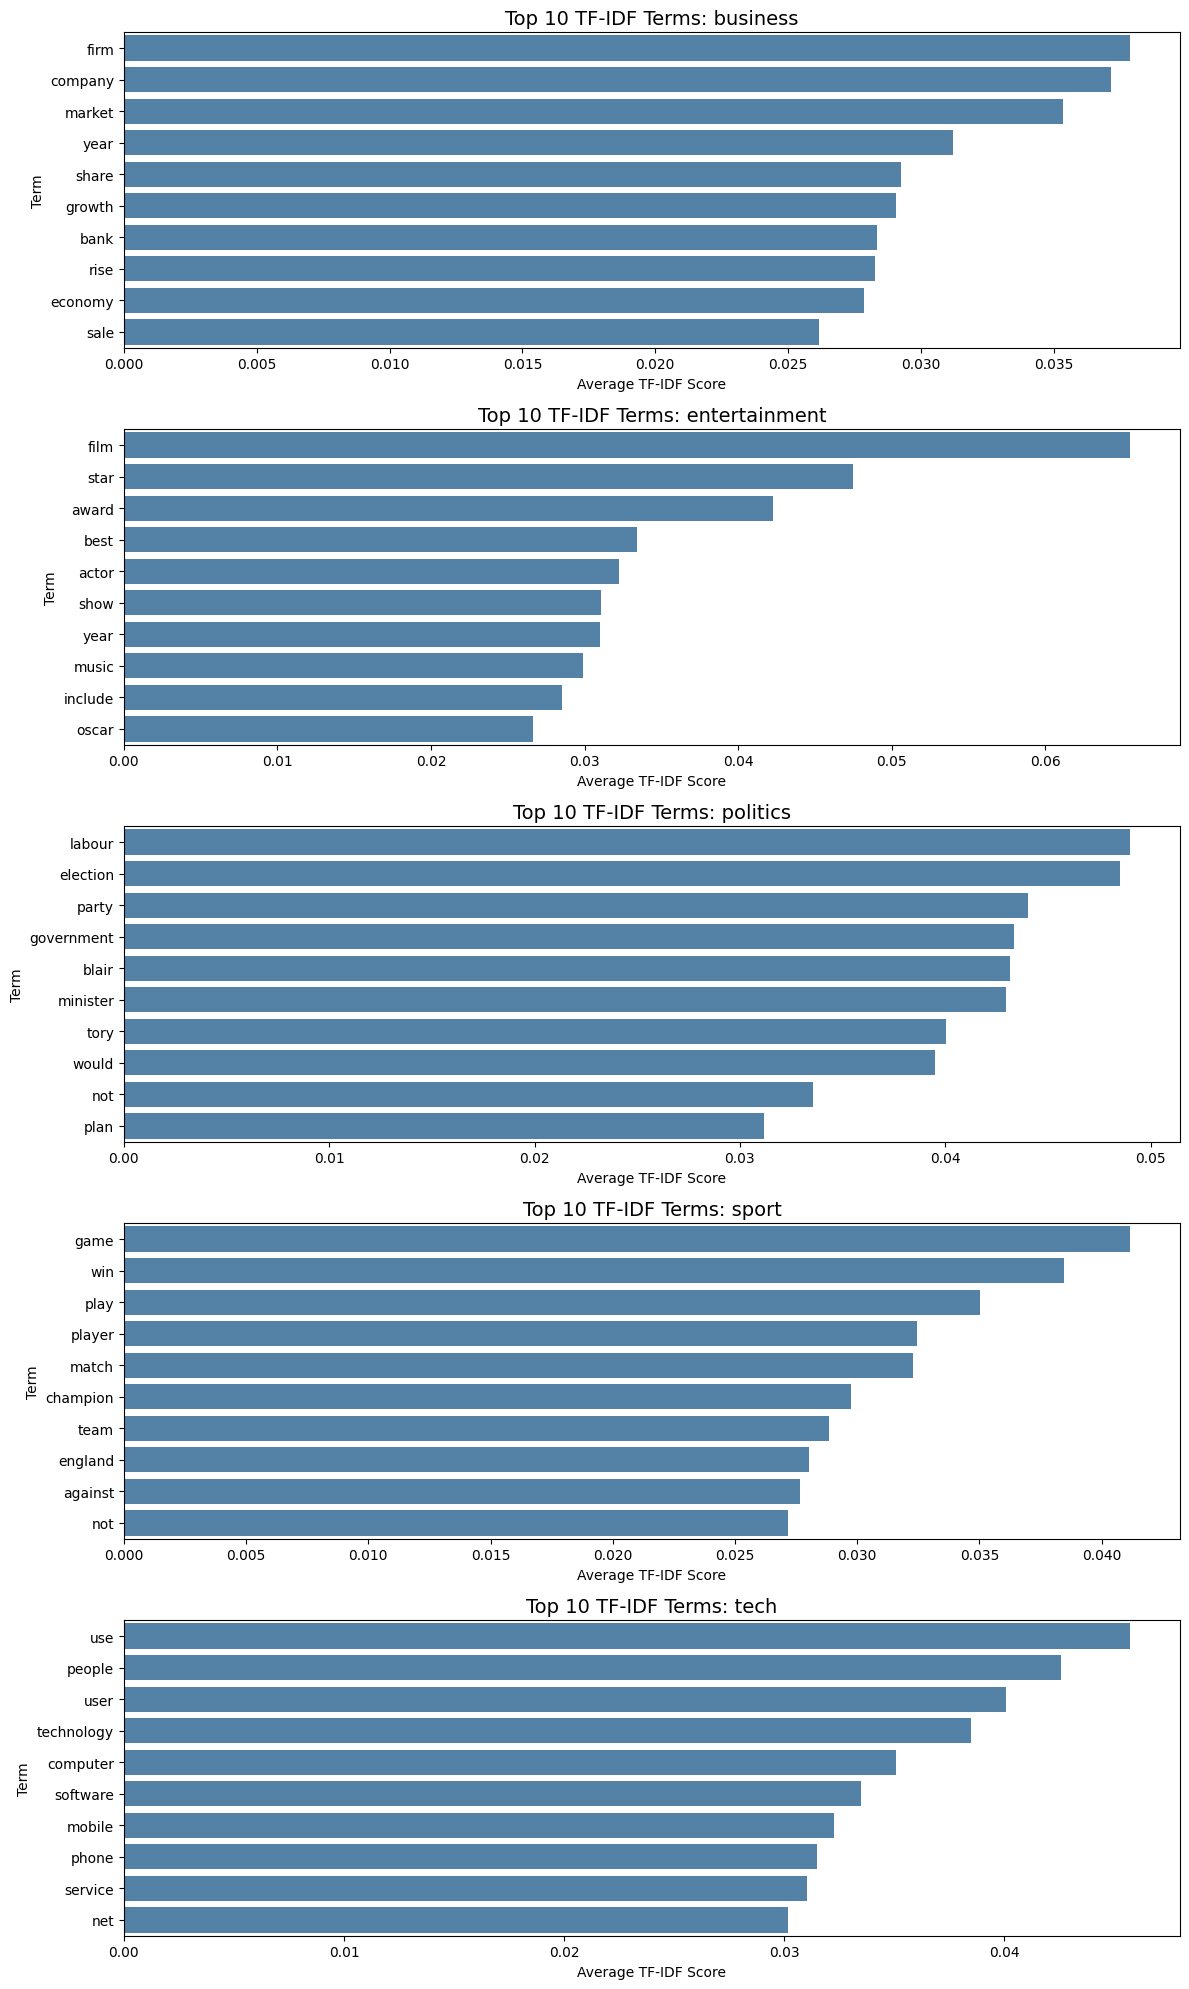


🔥 GENERATING CROSS-CATEGORY TF-IDF HEATMAP


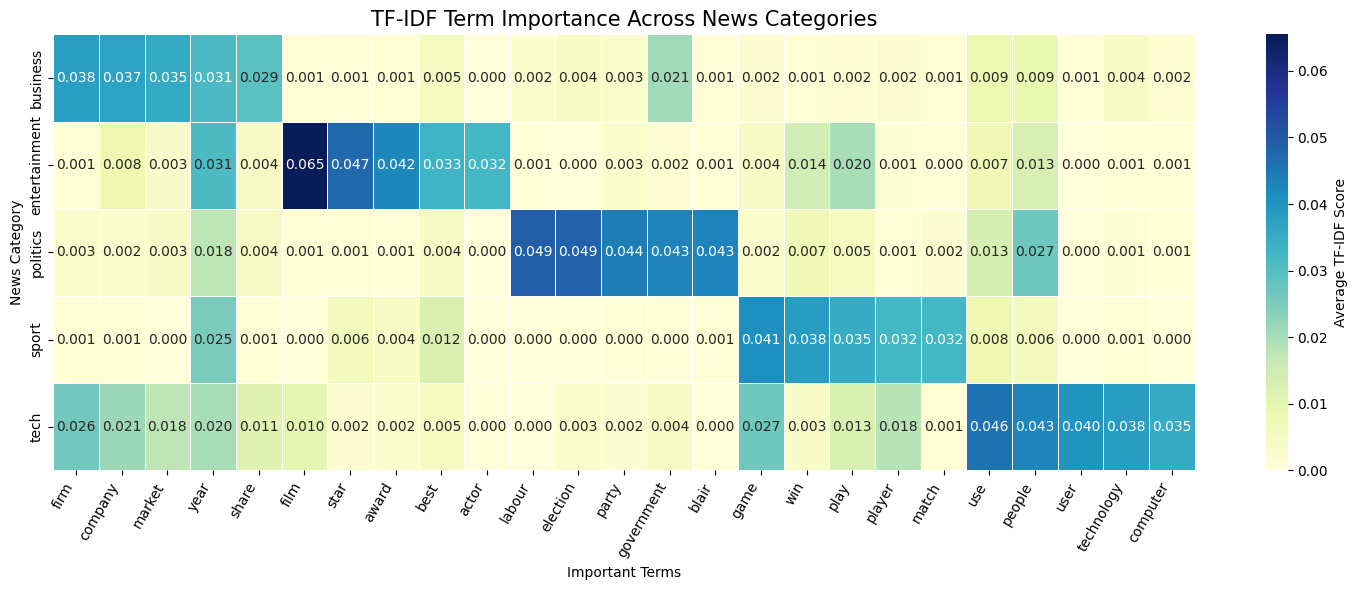


🔍 CATEGORY-DISTINCTIVE TERMS

BUSINESS:
  firm: 0.0301
  market: 0.0293
  company: 0.0290
  growth: 0.0267
  bank: 0.0267

ENTERTAINMENT:
  film: 0.0625
  star: 0.0450
  award: 0.0403
  actor: 0.0321
  best: 0.0269

POLITICS:
  labour: 0.0481
  election: 0.0468
  blair: 0.0425
  party: 0.0420
  tory: 0.0401

SPORT:
  game: 0.0324
  win: 0.0319
  match: 0.0311
  champion: 0.0292
  player: 0.0269

TECH:
  user: 0.0398
  technology: 0.0369
  use: 0.0364
  computer: 0.0343
  software: 0.0332

📋 CATEGORY TF-IDF SUMMARY


,Category,Articles,Top Term,Top Term Score,Top 5 Terms
0,business,335,firm,0.0379,"firm, company, market, year, share"
1,entertainment,263,film,0.0655,"film, star, award, best, actor"
2,politics,266,labour,0.0490,"labour, election, party, government, blair"
3,sport,342,game,0.0412,"game, win, play, player, match"
4,tech,234,use,0.0457,"use, people, user, technology, computer"



✅ MODULE 3: TF-IDF CATEGORY ANALYSIS COMPLETE
Categories analyzed: 5
TF-IDF features: 5000
Word clouds generated: 5
Bar charts generated: 5
Cross-category heatmap generated: Yes

Completed student tasks:
✓ Top TF-IDF terms by category
✓ Word clouds for each category
✓ Bar charts of important terms
✓ Heatmap of term importance
✓ Category-distinctive term analysis
✓ Category comparison summary

Ready for Module 4: Part-of-Speech Analysis


In [ ]:
# # Analyze most important terms per category
# def get_top_tfidf_terms(category, n_terms=10):
#     """
#     Get top TF-IDF terms for a specific category

#     💡 TIP: This function should:
#     - Filter data for the specific category
#     - Calculate mean TF-IDF scores for each term
#     - Return top N terms with highest scores
#     """
#     # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
#     category_data = tfidf_df[tfidf_df['category'] == category]

#     # Calculate mean TF-IDF scores for this category (excluding the category column)
#     mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

#     return mean_scores.head(n_terms)

# # Analyze top terms for each category
# print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
# print("=" * 50)

# categories = df['category'].unique()
# category_terms = {}

# for category in categories:
#     top_terms = get_top_tfidf_terms(category, n_terms=10)
#     category_terms[category] = top_terms

#     print(f"\n📰 {category.upper()}:")
#     for term, score in top_terms.items():
#         print(f"  {term}: {score:.4f}")

# # 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# # - Word clouds for each category
# # - Bar charts of top terms
# # - Heatmap of term importance across categories


# ============================================================
# MODULE 3: CATEGORY-SPECIFIC TF-IDF ANALYSIS
# NewsBot Intelligence System - Midterm Project
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import subprocess
import sys

from scipy.sparse import issparse

# Install WordCloud if necessary
try:
    from wordcloud import WordCloud
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "wordcloud"
    ])
    from wordcloud import WordCloud


# ------------------------------------------------------------
# STEP 1: Get top TF-IDF terms for each category
# ------------------------------------------------------------

def get_top_tfidf_terms(category, n_terms=10):
    """
    Return the top N terms with the highest average
    TF-IDF scores for a specific news category.

    Uses the sparse TF-IDF matrix for efficiency.
    """

    category_mask = (
        df['category'].to_numpy() == category
    )

    if not category_mask.any():
        raise ValueError(f"Unknown category: {category}")

    category_matrix = tfidf_matrix[category_mask]

    mean_scores = np.asarray(
        category_matrix.mean(axis=0)
    ).ravel()

    top_indices = np.argsort(
        mean_scores
    )[-n_terms:][::-1]

    return pd.Series(
        mean_scores[top_indices],
        index=feature_names[top_indices],
        name=category
    )


# ------------------------------------------------------------
# STEP 2: Analyze top terms for each category
# ------------------------------------------------------------

print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 60)

categories = sorted(df['category'].unique())
category_terms = {}

for category in categories:

    top_terms = get_top_tfidf_terms(
        category,
        n_terms=10
    )

    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}")
    print("-" * 45)

    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")


# ------------------------------------------------------------
# STUDENT TASK 1: Word clouds for each category
# ------------------------------------------------------------

print("\n☁️ GENERATING CATEGORY WORD CLOUDS")
print("=" * 60)

# Word clouds use average TF-IDF weights rather
# than raw word frequencies.

fig, axes = plt.subplots(
    len(categories),
    1,
    figsize=(14, 5 * len(categories))
)

axes = np.atleast_1d(axes)

for ax, category in zip(axes, categories):

    category_mask = (
        df['category'].to_numpy() == category
    )

    category_matrix = tfidf_matrix[category_mask]

    mean_scores = np.asarray(
        category_matrix.mean(axis=0)
    ).ravel()

    # Select highest-weighted terms
    top_indices = np.argsort(
        mean_scores
    )[-100:][::-1]

    frequencies = {
        feature_names[i]: float(mean_scores[i])
        for i in top_indices
        if mean_scores[i] > 0
    }

    if frequencies:
        wordcloud = WordCloud(
            width=1200,
            height=450,
            background_color='white',
            max_words=100,
            colormap='viridis',
            random_state=42
        ).generate_from_frequencies(frequencies)

        ax.imshow(wordcloud, interpolation='bilinear')
    else:
        ax.text(
            0.5, 0.5,
            "No terms available",
            ha='center',
            va='center'
        )

    ax.set_title(
        f'{category} - TF-IDF Word Cloud',
        fontsize=15
    )

    ax.axis('off')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STUDENT TASK 2: Bar charts of top TF-IDF terms
# ------------------------------------------------------------

print("\n📊 GENERATING TOP TERM BAR CHARTS")
print("=" * 60)

fig, axes = plt.subplots(
    len(categories),
    1,
    figsize=(12, 4 * len(categories))
)

axes = np.atleast_1d(axes)

for ax, category in zip(axes, categories):

    top_terms = category_terms[category]

    plot_df = pd.DataFrame({
        'Term': top_terms.index,
        'Average TF-IDF': top_terms.values
    })

    sns.barplot(
        data=plot_df,
        x='Average TF-IDF',
        y='Term',
        ax=ax,
        color='steelblue'
    )

    ax.set_title(
        f'Top 10 TF-IDF Terms: {category}',
        fontsize=14
    )

    ax.set_xlabel('Average TF-IDF Score')
    ax.set_ylabel('Term')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STUDENT TASK 3: Heatmap of term importance
# ------------------------------------------------------------

print("\n🔥 GENERATING CROSS-CATEGORY TF-IDF HEATMAP")
print("=" * 60)

# Collect the top 5 terms from each category
selected_terms = []

for category in categories:
    selected_terms.extend(
        category_terms[category].head(5).index.tolist()
    )

# Remove duplicates while preserving order
selected_terms = list(dict.fromkeys(selected_terms))

# Create category-term importance matrix
heatmap_data = pd.DataFrame(
    index=categories,
    columns=selected_terms,
    dtype=float
)

feature_index = {
    term: i
    for i, term in enumerate(feature_names)
}

for category in categories:

    category_mask = (
        df['category'].to_numpy() == category
    )

    category_mean = np.asarray(
        tfidf_matrix[category_mask].mean(axis=0)
    ).ravel()

    for term in selected_terms:
        heatmap_data.loc[category, term] = (
            category_mean[feature_index[term]]
        )

heatmap_data = heatmap_data.fillna(0.0)

plt.figure(
    figsize=(max(14, len(selected_terms) * 0.6), 6)
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Average TF-IDF Score'}
)

plt.title(
    'TF-IDF Term Importance Across News Categories',
    fontsize=15
)

plt.xlabel('Important Terms')
plt.ylabel('News Category')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 6: Identify category-distinctive terms
# ------------------------------------------------------------

print("\n🔍 CATEGORY-DISTINCTIVE TERMS")
print("=" * 60)

# Compare each category's average TF-IDF
# with the average across other categories.

category_mean_matrix = {}

for category in categories:

    mask = df['category'].to_numpy() == category

    category_mean_matrix[category] = np.asarray(
        tfidf_matrix[mask].mean(axis=0)
    ).ravel()

for category in categories:

    current_scores = category_mean_matrix[category]

    other_categories = [
        c for c in categories
        if c != category
    ]

    other_scores = np.mean(
        [
            category_mean_matrix[c]
            for c in other_categories
        ],
        axis=0
    )

    distinctiveness = current_scores - other_scores

    top_indices = np.argsort(
        distinctiveness
    )[-5:][::-1]

    print(f"\n{category.upper()}:")

    for i in top_indices:
        print(
            f"  {feature_names[i]}: "
            f"{distinctiveness[i]:.4f}"
        )


# ------------------------------------------------------------
# STEP 7: Summary table
# ------------------------------------------------------------

print("\n📋 CATEGORY TF-IDF SUMMARY")
print("=" * 60)

summary_rows = []

for category in categories:

    top_terms = category_terms[category]

    summary_rows.append({
        'Category': category,
        'Articles': int(
            (df['category'] == category).sum()
        ),
        'Top Term': top_terms.index[0],
        'Top Term Score': round(
            float(top_terms.iloc[0]), 4
        ),
        'Top 5 Terms': ', '.join(
            top_terms.head(5).index
        )
    })

category_summary_df = pd.DataFrame(summary_rows)

display(category_summary_df)


# ------------------------------------------------------------
# STEP 8: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 3: TF-IDF CATEGORY ANALYSIS COMPLETE")
print("=" * 60)

print(f"Categories analyzed: {len(categories)}")
print(f"TF-IDF features: {len(feature_names)}")
print(f"Word clouds generated: {len(categories)}")
print(f"Bar charts generated: {len(categories)}")
print("Cross-category heatmap generated: Yes")

print("\nCompleted student tasks:")
print("✓ Top TF-IDF terms by category")
print("✓ Word clouds for each category")
print("✓ Bar charts of important terms")
print("✓ Heatmap of term importance")
print("✓ Category-distinctive term analysis")
print("✓ Category comparison summary")

print("\nReady for Module 4: Part-of-Speech Analysis")


## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

🏷️ Analyzing POS patterns...

✅ POS analysis complete!
📊 Articles analyzed: 1440
📊 Detailed POS tags found: 36
📊 Total POS feature columns: 46

📝 Sample POS analysis:


,JJ,NNS,NN,VBG,IN,DT,VBP,VBN,PRP$,VBD,...,EX,RBS,FW,WP$,$,NNP,NNPS,POS,UH,SYM
0,0.093333,0.123333,0.233333,0.030000,0.116667,0.070000,0.026667,0.043333,0.013333,0.063333,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.123457,0.074074,0.237654,0.033951,0.141975,0.086420,0.015432,0.030864,0.006173,0.064815,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.085770,0.085770,0.187135,0.027290,0.130604,0.101365,0.019493,0.033138,0.017544,0.066277,...,0.001949,0.005848,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.091772,0.113924,0.147152,0.023734,0.129747,0.066456,0.049051,0.022152,0.014241,0.049051,...,0.001582,0.001582,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.099150,0.084986,0.220963,0.036827,0.133144,0.110482,0.016997,0.028329,0.016997,0.042493,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



📊 OVERALL POS DISTRIBUTION


,POS Category,Average Proportion
0,Noun,0.296450
1,Verb,0.186096
2,Preposition,0.149533
3,Adjective,0.106132
4,Determiner,0.102567
5,Pronoun,0.045591
6,Adverb,0.039606
7,Conjunction,0.027844
8,Number,0.025846
9,Other,0.020335


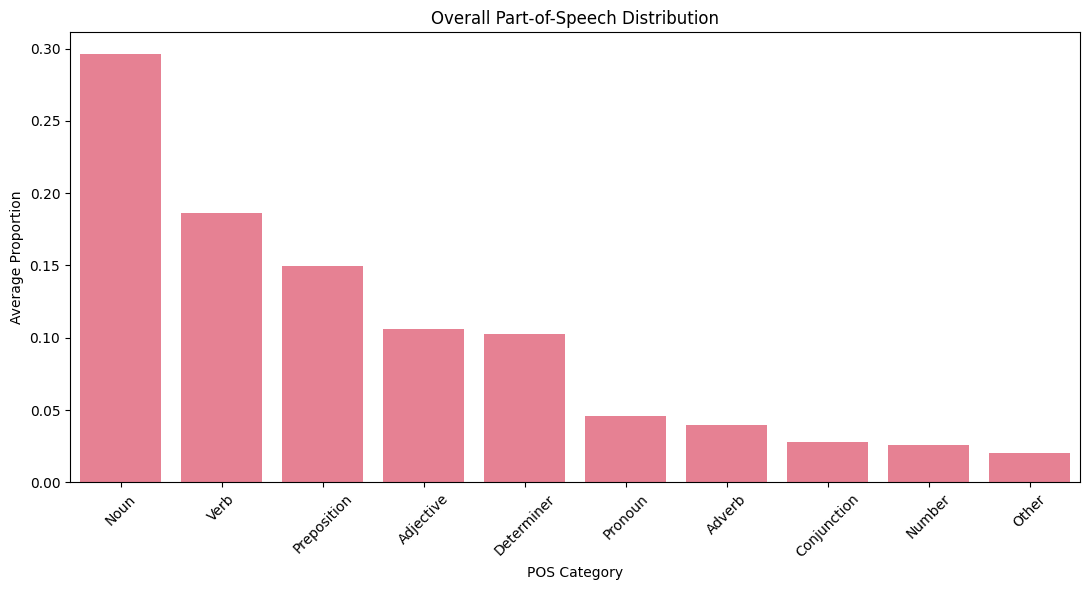


📰 POS DISTRIBUTION BY NEWS CATEGORY


,Adjective,Noun,Verb,Preposition,Determiner,Pronoun,Number,Adverb,Conjunction,Other
category,,,,,,,,,,
business,0.1060,0.3088,0.1770,0.1580,0.1030,0.0342,0.0374,0.0342,0.0240,0.0173
entertainment,0.1068,0.3164,0.1782,0.1428,0.1031,0.0463,0.0294,0.0347,0.0273,0.0150
politics,0.0994,0.2883,0.1983,0.1485,0.1079,0.0478,0.0155,0.0401,0.0281,0.0261
sport,0.1120,0.2810,0.1905,0.1449,0.0961,0.0577,0.0213,0.0455,0.0303,0.0207
tech,0.1046,0.2881,0.1877,0.1529,0.1047,0.0409,0.0238,0.0436,0.0300,0.0235


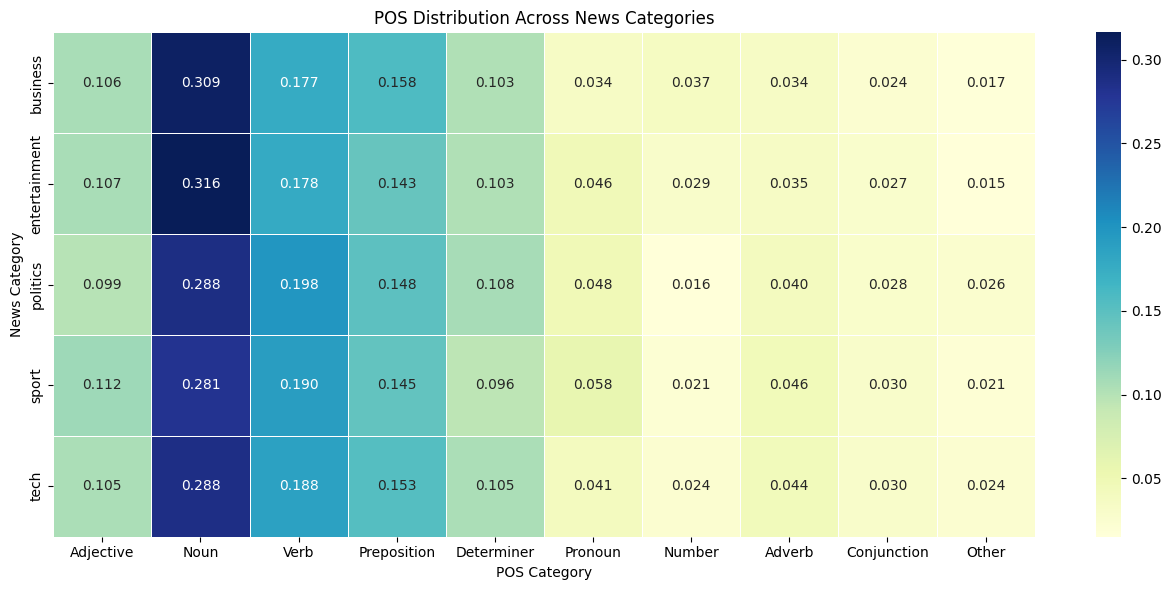


🔍 WRITING STYLE COMPARISON
Average percentage of major POS categories:


,Noun,Verb,Adjective,Adverb,Number
category,,,,,
business,30.88,17.70,10.60,3.42,3.74
entertainment,31.64,17.82,10.68,3.47,2.94
politics,28.83,19.83,9.94,4.01,1.55
sport,28.10,19.05,11.20,4.55,2.13
tech,28.81,18.77,10.46,4.36,2.38


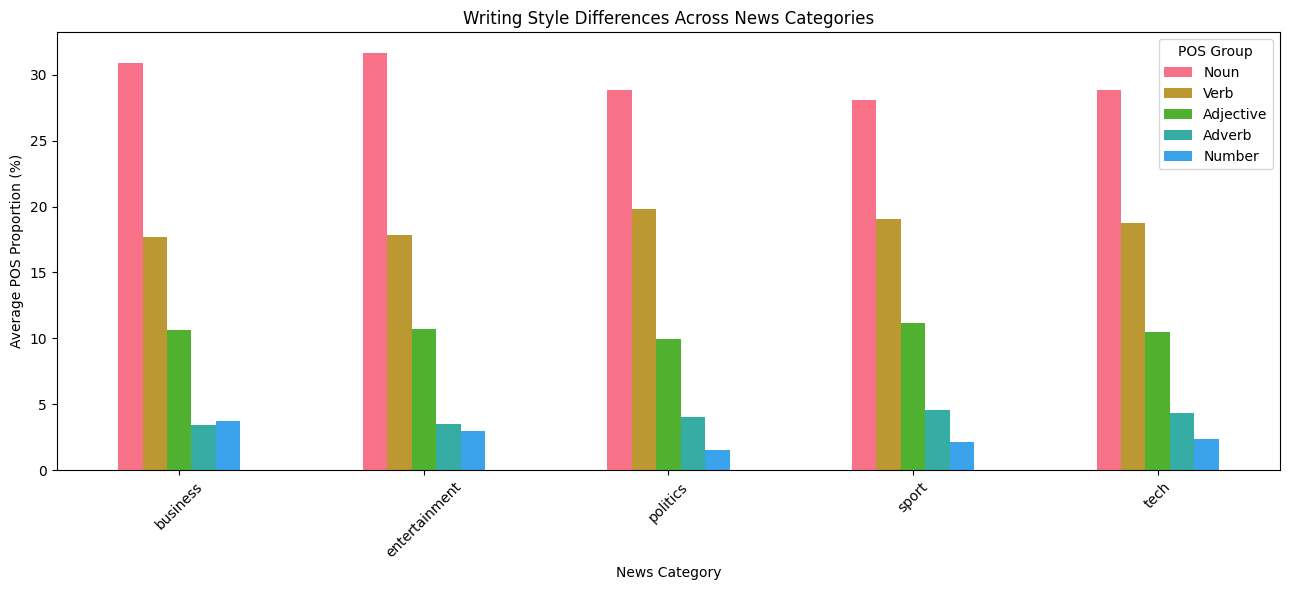


🧩 COMMON POS PATTERNS
Articles sampled: 50

Top 10 grammatical patterns:
Preposition -> Determiner -> Noun: 442
Determiner -> Adjective -> Noun: 410
Noun -> Preposition -> Noun: 394
Adjective -> Noun -> Preposition: 389
Noun -> Preposition -> Determiner: 388
Noun -> Noun -> Verb: 377
Determiner -> Noun -> Preposition: 347
Verb -> Determiner -> Noun: 327
Adjective -> Noun -> Noun: 320
Adjective -> Noun -> Verb: 268

📈 CATEGORY WRITING STYLE INSIGHTS
Highest Noun proportion: entertainment (31.64%)
Highest Verb proportion: politics (19.83%)
Highest Adjective proportion: sport (11.20%)
Highest Adverb proportion: sport (4.55%)
Highest Number proportion: business (3.74%)

✅ MODULE 4: POS ANALYSIS COMPLETE
Articles analyzed: 1440
News categories: 5
Detailed POS tags: 36

Completed:
✓ Text tokenization
✓ POS tagging
✓ Detailed POS proportions
✓ Major grammatical category analysis
✓ Cross-category POS comparison
✓ Writing style analysis
✓ Common grammatical pattern extraction
✓ POS distributio

In [ ]:
# def analyze_pos_patterns(text):
#     """
#     Analyze POS patterns in text

#     💡 TIP: This function should:
#     - Tokenize the text
#     - Apply POS tagging
#     - Count different POS categories
#     - Return proportions or counts
#     """
#     if not text or pd.isna(text):
#         return {}

#     # 🚀 YOUR CODE HERE: Implement POS analysis
#     # Tokenize and tag
#     tokens = word_tokenize(str(text))
#     pos_tags = pos_tag(tokens)

#     # Count POS categories
#     pos_counts = Counter([tag for word, tag in pos_tags])
#     total_words = len(pos_tags)

#     if total_words == 0:
#         return {}

#     # Convert to proportions
#     pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

#     return pos_proportions

# # Apply POS analysis to all articles
# print("🏷️ Analyzing POS patterns...")

# # Analyze POS for each article
# pos_results = []
# for idx, row in df.iterrows():
#     pos_analysis = analyze_pos_patterns(row['full_text'])
#     pos_analysis['category'] = row['category']
#     pos_analysis['article_id'] = row['article_id']
#     pos_results.append(pos_analysis)

# # Convert to DataFrame
# pos_df = pd.DataFrame(pos_results).fillna(0)

# print(f"✅ POS analysis complete!")
# print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# # Show sample results
# print("\n📝 Sample POS analysis:")
# print(pos_df.head())


# ============================================================
# MODULE 4: PART-OF-SPEECH (POS) PATTERN ANALYSIS
# NewsBot Intelligence System - Midterm Project
# ============================================================

import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk import word_tokenize, pos_tag
from collections import Counter

# ------------------------------------------------------------
# STEP 1: Download required NLTK resources
# ------------------------------------------------------------

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# ------------------------------------------------------------
# STEP 2: Define POS categories
# ------------------------------------------------------------

# Penn Treebank POS tags grouped into major categories
POS_GROUPS = {
    'Noun': ['NN', 'NNS', 'NNP', 'NNPS'],
    'Verb': ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'],
    'Adjective': ['JJ', 'JJR', 'JJS'],
    'Adverb': ['RB', 'RBR', 'RBS', 'WRB'],
    'Pronoun': ['PRP', 'PRP$', 'WP', 'WP$'],
    'Determiner': ['DT', 'PDT', 'WDT'],
    'Preposition': ['IN', 'TO'],
    'Conjunction': ['CC'],
    'Number': ['CD']
}

def get_pos_group(tag):
    """Map a detailed POS tag to a major POS category."""

    for group, tags in POS_GROUPS.items():
        if tag in tags:
            return group

    return 'Other'


# ------------------------------------------------------------
# STEP 3: POS analysis function
# ------------------------------------------------------------

def analyze_pos_patterns(text):
    """
    Analyze grammatical patterns in news article text.

    Steps:
    1. Tokenize raw text
    2. Apply POS tagging
    3. Count detailed POS tags
    4. Calculate POS proportions
    5. Calculate major grammatical group proportions

    Returns a dictionary containing normalized POS features.
    """

    if not isinstance(text, str) or not text.strip():
        return {}

    # Tokenize text
    tokens = word_tokenize(text)

    # Keep word and number tokens, excluding punctuation
    tokens = [
        token for token in tokens
        if any(char.isalnum() for char in token)
    ]

    if not tokens:
        return {}

    # Apply POS tagging
    pos_tags = pos_tag(tokens)

    # Count detailed POS tags
    pos_counts = Counter(
        tag for word, tag in pos_tags
    )

    # Count major POS groups
    group_counts = Counter(
        get_pos_group(tag)
        for word, tag in pos_tags
    )

    total_words = len(pos_tags)

    # Detailed POS proportions
    pos_proportions = {
        tag: count / total_words
        for tag, count in pos_counts.items()
    }

    # Major POS group proportions
    group_proportions = {
        f'GROUP_{group}': count / total_words
        for group, count in group_counts.items()
    }

    # Combine detailed and grouped features
    results = {
        **pos_proportions,
        **group_proportions
    }

    return results


# ------------------------------------------------------------
# STEP 4: Apply POS analysis to all articles
# ------------------------------------------------------------

print("🏷️ Analyzing POS patterns...")
print("=" * 60)

pos_results = []

for idx, row in df.iterrows():

    # Use original text to preserve grammar
    pos_analysis = analyze_pos_patterns(
        row['full_text']
    )

    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']

    pos_results.append(pos_analysis)

# Convert results to DataFrame
pos_df = pd.DataFrame(pos_results)

# Fill missing POS features with zero
feature_columns = [
    col for col in pos_df.columns
    if col not in ['category', 'article_id']
]

pos_df[feature_columns] = (
    pos_df[feature_columns].fillna(0)
)

# Identify detailed POS tags
detailed_pos_columns = [
    col for col in feature_columns
    if not col.startswith('GROUP_')
]

print("\n✅ POS analysis complete!")
print(f"📊 Articles analyzed: {len(pos_df)}")
print(f"📊 Detailed POS tags found: {len(detailed_pos_columns)}")
print(f"📊 Total POS feature columns: {len(feature_columns)}")

print("\n📝 Sample POS analysis:")
display(pos_df.head())


# ------------------------------------------------------------
# STEP 5: Analyze overall POS distribution
# ------------------------------------------------------------

print("\n📊 OVERALL POS DISTRIBUTION")
print("=" * 60)

group_columns = [
    col for col in pos_df.columns
    if col.startswith('GROUP_')
]

overall_pos = (
    pos_df[group_columns]
    .mean()
    .sort_values(ascending=False)
)

overall_pos.index = (
    overall_pos.index.str.replace(
        'GROUP_', '', regex=False
    )
)

overall_pos_df = pd.DataFrame({
    'POS Category': overall_pos.index,
    'Average Proportion': overall_pos.values
})

display(overall_pos_df)

# Visualize overall POS distribution
plt.figure(figsize=(11, 6))

sns.barplot(
    data=overall_pos_df,
    x='POS Category',
    y='Average Proportion'
)

plt.title('Overall Part-of-Speech Distribution')
plt.xlabel('POS Category')
plt.ylabel('Average Proportion')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 6: Compare POS distribution across news categories
# ------------------------------------------------------------

print("\n📰 POS DISTRIBUTION BY NEWS CATEGORY")
print("=" * 60)

category_pos = (
    pos_df.groupby('category')[group_columns]
    .mean()
)

category_pos.columns = (
    category_pos.columns.str.replace(
        'GROUP_', '', regex=False
    )
)

display(category_pos.round(4))

# Heatmap of POS proportions across categories
plt.figure(figsize=(13, 6))

sns.heatmap(
    category_pos,
    annot=True,
    fmt='.3f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('POS Distribution Across News Categories')
plt.xlabel('POS Category')
plt.ylabel('News Category')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 7: Compare major grammatical features
# ------------------------------------------------------------

print("\n🔍 WRITING STYLE COMPARISON")
print("=" * 60)

key_groups = [
    'Noun',
    'Verb',
    'Adjective',
    'Adverb',
    'Number'
]

available_groups = [
    group for group in key_groups
    if group in category_pos.columns
]

style_comparison = (
    category_pos[available_groups] * 100
).round(2)

print("Average percentage of major POS categories:")
display(style_comparison)

# Grouped bar chart
style_comparison.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title('Writing Style Differences Across News Categories')
plt.xlabel('News Category')
plt.ylabel('Average POS Proportion (%)')
plt.xticks(rotation=45)
plt.legend(title='POS Group')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 8: Extract common grammatical patterns
# ------------------------------------------------------------

print("\n🧩 COMMON POS PATTERNS")
print("=" * 60)

def extract_pos_patterns(text, pattern_length=3):
    """
    Extract sequences of POS groups from text.
    Example: Adjective -> Noun -> Verb
    """

    if not isinstance(text, str) or not text.strip():
        return Counter()

    tokens = word_tokenize(text)

    # Keep alphanumeric tokens
    tokens = [
        token for token in tokens
        if any(char.isalnum() for char in token)
    ]

    if len(tokens) < pattern_length:
        return Counter()

    tagged = pos_tag(tokens)

    groups = [
        get_pos_group(tag)
        for word, tag in tagged
    ]

    patterns = [
        ' -> '.join(groups[i:i + pattern_length])
        for i in range(len(groups) - pattern_length + 1)
    ]

    return Counter(patterns)


# Use up to 50 articles for pattern exploration
sample_size = min(50, len(df))

pattern_counts = Counter()

for text in df['full_text'].head(sample_size):
    pattern_counts.update(
        extract_pos_patterns(text, pattern_length=3)
    )

print(f"Articles sampled: {sample_size}")
print("\nTop 10 grammatical patterns:")

for pattern, count in pattern_counts.most_common(10):
    print(f"{pattern}: {count}")


# ------------------------------------------------------------
# STEP 9: Identify category writing-style differences
# ------------------------------------------------------------

print("\n📈 CATEGORY WRITING STYLE INSIGHTS")
print("=" * 60)

for group in available_groups:

    highest_category = (
        category_pos[group].idxmax()
    )

    highest_value = (
        category_pos[group].max() * 100
    )

    print(
        f"Highest {group} proportion: "
        f"{highest_category} ({highest_value:.2f}%)"
    )


# ------------------------------------------------------------
# STEP 10: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 4: POS ANALYSIS COMPLETE")
print("=" * 60)

print(f"Articles analyzed: {len(pos_df)}")
print(f"News categories: {df['category'].nunique()}")
print(f"Detailed POS tags: {len(detailed_pos_columns)}")

print("\nCompleted:")
print("✓ Text tokenization")
print("✓ POS tagging")
print("✓ Detailed POS proportions")
print("✓ Major grammatical category analysis")
print("✓ Cross-category POS comparison")
print("✓ Writing style analysis")
print("✓ Common grammatical pattern extraction")
print("✓ POS distribution visualizations")

print("\nReady for Module 5: Syntax Parsing and Semantic Analysis")


📊 POS PATTERNS BY CATEGORY

🎯 KEY POS PATTERNS BY CATEGORY


,NN,NNS,NNP,NNPS,VB,VBD,VBG,VBN,VBP,VBZ,JJ,JJR,JJS,RB,RBR,RBS,CD
category,,,,,,,,,,,,,,,,,
business,0.2286,0.0792,0.0009,0.0000,0.0352,0.0447,0.0218,0.0298,0.0191,0.0265,0.0977,0.0048,0.0035,0.0299,0.0020,0.0006,0.0374
entertainment,0.2545,0.0613,0.0007,0.0000,0.0297,0.0498,0.0208,0.0314,0.0215,0.0250,0.0990,0.0027,0.0052,0.0302,0.0011,0.0011,0.0294
politics,0.2159,0.0715,0.0007,0.0002,0.0471,0.0494,0.0223,0.0319,0.0233,0.0244,0.0942,0.0034,0.0018,0.0348,0.0016,0.0004,0.0155
sport,0.2296,0.0508,0.0006,0.0000,0.0406,0.0493,0.0189,0.0262,0.0293,0.0262,0.1080,0.0021,0.0019,0.0402,0.0014,0.0003,0.0213
tech,0.1979,0.0895,0.0007,0.0000,0.0445,0.0317,0.0254,0.0282,0.0268,0.0311,0.0965,0.0055,0.0026,0.0369,0.0025,0.0008,0.0238


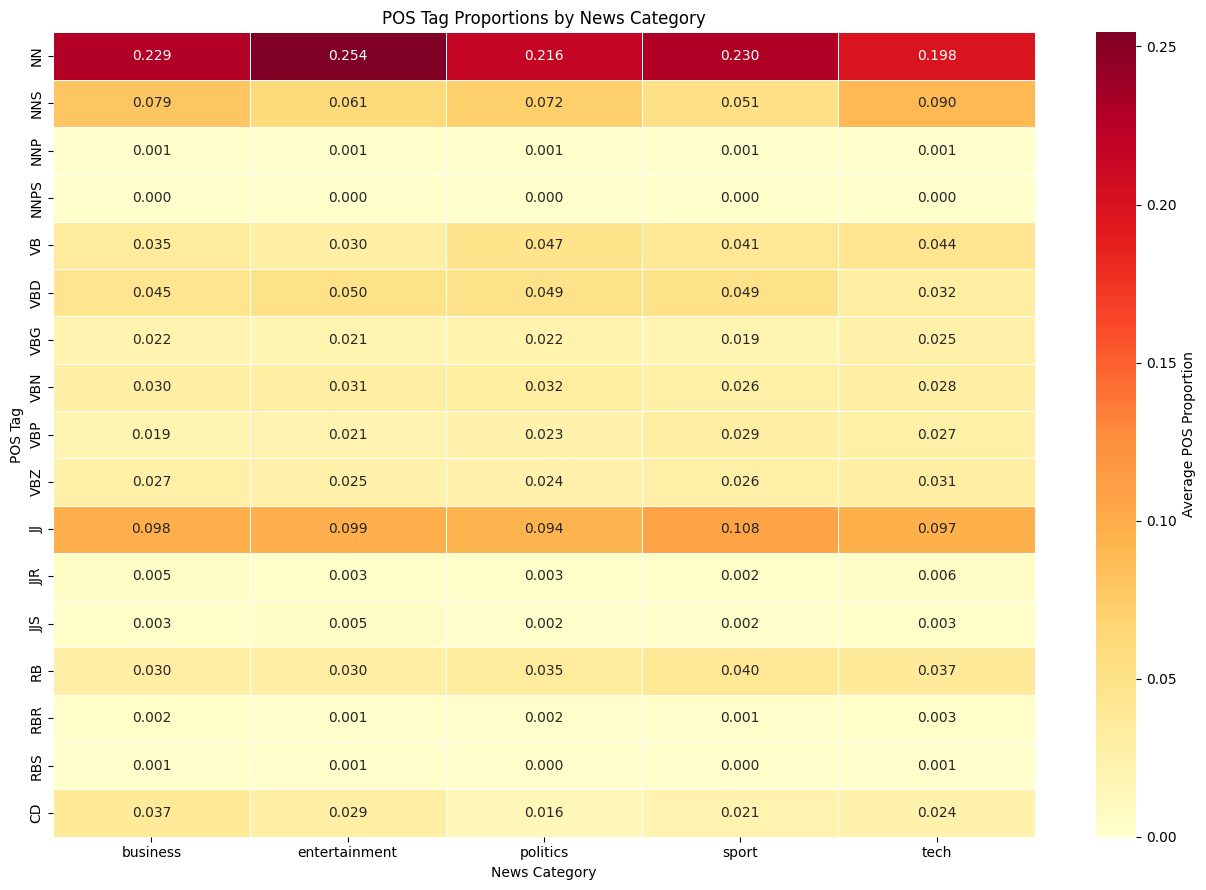


📚 MAJOR POS GROUP COMPARISON


,Nouns,Verbs,Adjectives,Adverbs,Numbers,Proper Nouns,Action Verbs
category,,,,,,,
business,30.88,17.70,10.60,3.26,3.74,0.10,10.16
entertainment,31.64,17.82,10.68,3.23,2.94,0.07,10.04
politics,28.83,19.83,9.94,3.68,1.55,0.09,11.87
sport,28.10,19.05,11.20,4.19,2.13,0.06,10.88
tech,28.81,18.77,10.46,4.02,2.38,0.07,10.16



🔍 NOUN VS VERB ANALYSIS


,Nouns,Verbs
category,,
business,30.88,17.70
entertainment,31.64,17.82
politics,28.83,19.83
sport,28.10,19.05
tech,28.81,18.77


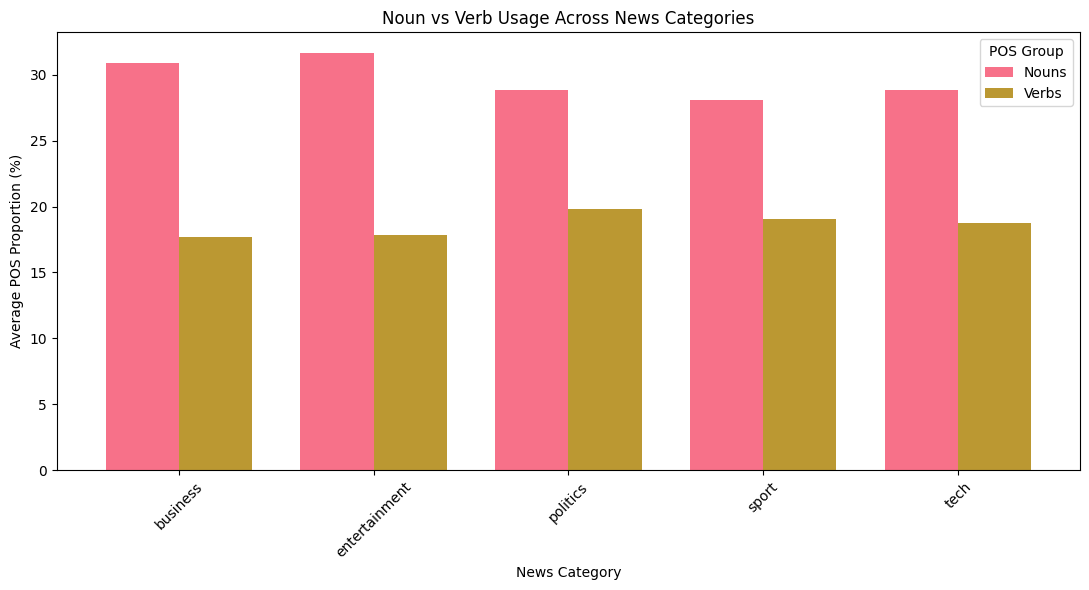

Highest noun usage: entertainment (31.64%)
Highest verb usage: politics (19.83%)

🔢 NUMBER (CD) USAGE ANALYSIS


,Number Usage (%)
category,
business,3.74
entertainment,2.94
tech,2.38
sport,2.13
politics,1.55


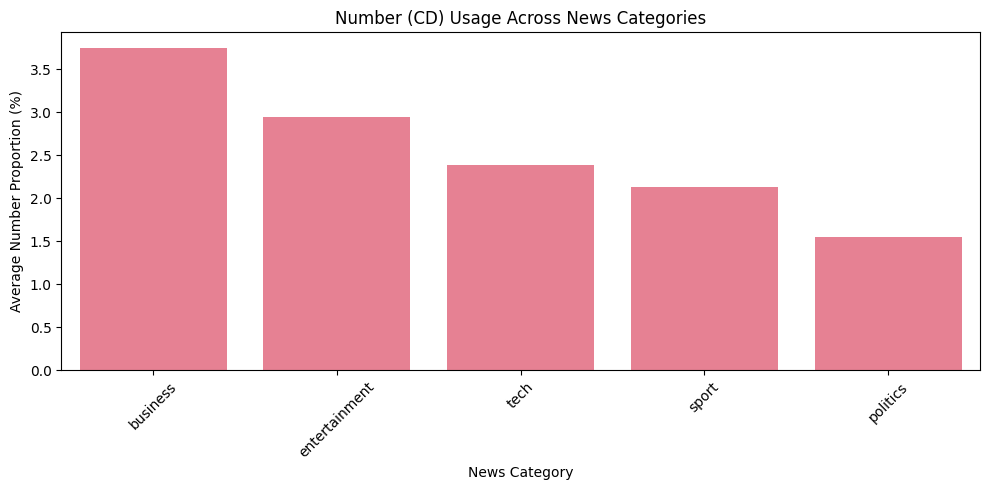

Highest number usage: business

🎨 ADJECTIVE USAGE ANALYSIS


,Adjective Usage (%)
category,
sport,11.20
entertainment,10.68
business,10.60
tech,10.46
politics,9.94


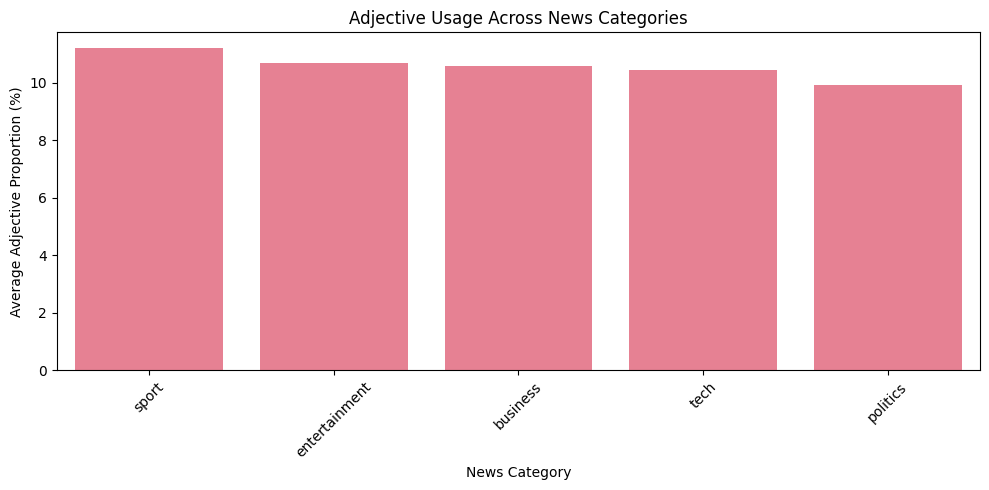

Highest adjective usage: sport (11.20%)
Lowest adjective usage: politics (9.94%)

💡 ANALYSIS QUESTIONS AND RESULTS

Q1. Which category has the highest proportion
    of proper nouns (NNP/NNPS)?
Answer: business (0.10%)
Interpretation: Proper nouns often identify people, organizations, and locations.

Q2. Which category uses the most
    action verbs (VB, VBD, VBG)?
Answer: politics (11.87%)
Interpretation: This category has the highest proportion of the selected verb forms.

Q3. Are there interesting patterns
    in adjective (JJ) usage?
Highest JJ usage: sport (10.80%)
Lowest JJ usage: politics (9.42%)
Interpretation: Differences may reflect descriptive writing patterns, but POS proportions alone do not establish sentiment.

Q4. How does number (CD) usage
    vary across categories?
Highest: business (3.74%)
Lowest: politics (1.55%)
Interpretation: Numeric tokens can represent financial figures, dates, scores, or statistics.

🔥 MAJOR POS GROUP HEATMAP


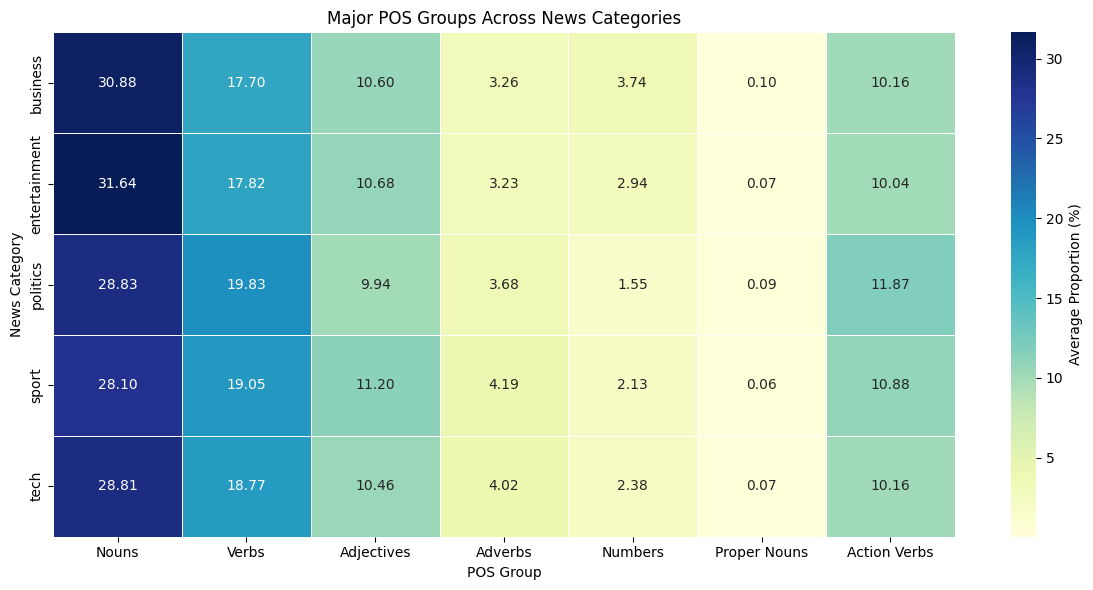


✅ MODULE 4: POS CATEGORY ANALYSIS COMPLETE
Categories analyzed: 5
Detailed POS tags analyzed: 17

Key findings:
✓ Highest noun usage: entertainment
✓ Highest verb usage: politics
✓ Highest proper noun usage: business
✓ Highest action verb usage: politics
✓ Highest adjective usage: sport
✓ Highest number usage: business

Completed student tasks:
✓ Compare noun and verb usage
✓ Analyze business number usage
✓ Compare adjective usage
✓ Answer all four instructor questions
✓ Generate POS comparison visualizations

Ready for Module 5: Syntax Parsing and Semantic Analysis


In [ ]:
# # Analyze POS patterns by category
# print("📊 POS PATTERNS BY CATEGORY")
# print("=" * 50)

# # Group by category and calculate mean proportions
# pos_by_category = pos_df.groupby('category').mean()

# # Focus on major POS categories
# major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
#              'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# # Filter to only include major POS tags that exist in our data
# available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

# if available_pos:
#     pos_summary = pos_by_category[available_pos]

#     print("\n🎯 Key POS patterns by category:")
#     print(pos_summary.round(4))

#     # Create visualization
#     plt.figure(figsize=(12, 8))
#     sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
#     plt.title('POS Tag Proportions by News Category')
#     plt.xlabel('Category')
#     plt.ylabel('POS Tag')
#     plt.tight_layout()
#     plt.show()

#     # 💡 STUDENT TASK: Analyze the patterns
#     # - Which categories use more nouns vs verbs?
#     # - Do business articles have more numbers (CD)?
#     # - Are there differences in adjective usage?

#     print("\n💡 ANALYSIS QUESTIONS:")
#     print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
#     print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
#     print("3. Are there interesting patterns in adjective (JJ) usage?")
#     print("4. How does number (CD) usage vary across categories?")
# else:
#     print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")


# ============================================================
# MODULE 4: POS PATTERNS BY NEWS CATEGORY
# NewsBot Intelligence System - Midterm Project
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# STEP 1: Calculate average POS proportions by category
# ------------------------------------------------------------

print("📊 POS PATTERNS BY CATEGORY")
print("=" * 60)

# Exclude article_id from averaging
pos_by_category = (
    pos_df.groupby('category')
    .mean(numeric_only=True)
)

# Focus on major POS tags
major_pos = [
    'NN', 'NNS', 'NNP', 'NNPS',
    'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
    'JJ', 'JJR', 'JJS',
    'RB', 'RBR', 'RBS',
    'CD'
]

# Select available POS tags
available_pos = [
    pos for pos in major_pos
    if pos in pos_by_category.columns
]

if not available_pos:
    raise ValueError(
        "No major POS tags found. "
        "Check the previous POS analysis cell."
    )

pos_summary = pos_by_category[available_pos]

print("\n🎯 KEY POS PATTERNS BY CATEGORY")
display(pos_summary.round(4))


# ------------------------------------------------------------
# STEP 2: Heatmap of detailed POS tag proportions
# ------------------------------------------------------------

plt.figure(figsize=(13, 9))

sns.heatmap(
    pos_summary.T,
    annot=True,
    cmap='YlOrRd',
    fmt='.3f',
    linewidths=0.5,
    cbar_kws={'label': 'Average POS Proportion'}
)

plt.title('POS Tag Proportions by News Category')
plt.xlabel('News Category')
plt.ylabel('POS Tag')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 3: Calculate major grammatical categories
# ------------------------------------------------------------

print("\n📚 MAJOR POS GROUP COMPARISON")
print("=" * 60)

pos_groups = {
    'Nouns': ['NN', 'NNS', 'NNP', 'NNPS'],
    'Verbs': ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'],
    'Adjectives': ['JJ', 'JJR', 'JJS'],
    'Adverbs': ['RB', 'RBR', 'RBS'],
    'Numbers': ['CD'],
    'Proper Nouns': ['NNP', 'NNPS'],
    'Action Verbs': ['VB', 'VBD', 'VBG']
}

grouped_pos = pd.DataFrame(
    index=pos_by_category.index
)

for group, tags in pos_groups.items():

    existing_tags = [
        tag for tag in tags
        if tag in pos_by_category.columns
    ]

    if existing_tags:
        grouped_pos[group] = (
            pos_by_category[existing_tags].sum(axis=1)
        )
    else:
        grouped_pos[group] = 0.0

# Convert proportions to percentages
grouped_pos_percent = (grouped_pos * 100).round(2)

display(grouped_pos_percent)


# ------------------------------------------------------------
# STEP 4: Compare nouns vs verbs
# ------------------------------------------------------------

print("\n🔍 NOUN VS VERB ANALYSIS")
print("=" * 60)

noun_verb_comparison = grouped_pos_percent[
    ['Nouns', 'Verbs']
]

display(noun_verb_comparison)

ax = noun_verb_comparison.plot(
    kind='bar',
    figsize=(11, 6),
    width=0.75
)

plt.title('Noun vs Verb Usage Across News Categories')
plt.xlabel('News Category')
plt.ylabel('Average POS Proportion (%)')
plt.xticks(rotation=45)
plt.legend(title='POS Group')
plt.tight_layout()
plt.show()

highest_nouns = grouped_pos['Nouns'].idxmax()
highest_verbs = grouped_pos['Verbs'].idxmax()

print(
    f"Highest noun usage: {highest_nouns} "
    f"({grouped_pos_percent.loc[highest_nouns, 'Nouns']:.2f}%)"
)

print(
    f"Highest verb usage: {highest_verbs} "
    f"({grouped_pos_percent.loc[highest_verbs, 'Verbs']:.2f}%)"
)


# ------------------------------------------------------------
# STEP 5: Analyze number usage in business articles
# ------------------------------------------------------------

print("\n🔢 NUMBER (CD) USAGE ANALYSIS")
print("=" * 60)

number_usage = (
    grouped_pos_percent['Numbers']
    .sort_values(ascending=False)
)

display(number_usage.to_frame('Number Usage (%)'))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=number_usage.index,
    y=number_usage.values
)

plt.title('Number (CD) Usage Across News Categories')
plt.xlabel('News Category')
plt.ylabel('Average Number Proportion (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

highest_numbers = number_usage.idxmax()

print(f"Highest number usage: {highest_numbers}")

if 'Business' in number_usage.index:

    business_numbers = number_usage['Business']

    print(
        f"Business number usage: "
        f"{business_numbers:.2f}%"
    )

    if highest_numbers == 'Business':
        print(
            "Finding: Business has the highest "
            "average proportion of numeric tokens."
        )
    else:
        print(
            f"Finding: {highest_numbers} has a higher "
            "average numeric-token proportion than Business."
        )


# ------------------------------------------------------------
# STEP 6: Analyze adjective usage
# ------------------------------------------------------------

print("\n🎨 ADJECTIVE USAGE ANALYSIS")
print("=" * 60)

adjective_usage = (
    grouped_pos_percent['Adjectives']
    .sort_values(ascending=False)
)

display(adjective_usage.to_frame('Adjective Usage (%)'))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=adjective_usage.index,
    y=adjective_usage.values
)

plt.title('Adjective Usage Across News Categories')
plt.xlabel('News Category')
plt.ylabel('Average Adjective Proportion (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

highest_adjectives = adjective_usage.idxmax()

print(
    f"Highest adjective usage: {highest_adjectives} "
    f"({adjective_usage.max():.2f}%)"
)

print(
    f"Lowest adjective usage: {adjective_usage.idxmin()} "
    f"({adjective_usage.min():.2f}%)"
)


# ------------------------------------------------------------
# STEP 7: Answer instructor's four analysis questions
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("💡 ANALYSIS QUESTIONS AND RESULTS")
print("=" * 60)

# Question 1: Proper nouns
proper_noun_usage = grouped_pos_percent[
    'Proper Nouns'
]

top_proper_noun_category = proper_noun_usage.idxmax()

print("\nQ1. Which category has the highest proportion")
print("    of proper nouns (NNP/NNPS)?")

print(
    f"Answer: {top_proper_noun_category} "
    f"({proper_noun_usage.max():.2f}%)"
)

print(
    "Interpretation: Proper nouns often identify "
    "people, organizations, and locations."
)


# Question 2: Action verbs
action_verb_usage = grouped_pos_percent[
    'Action Verbs'
]

top_action_verb_category = action_verb_usage.idxmax()

print("\nQ2. Which category uses the most")
print("    action verbs (VB, VBD, VBG)?")

print(
    f"Answer: {top_action_verb_category} "
    f"({action_verb_usage.max():.2f}%)"
)

print(
    "Interpretation: This category has the highest "
    "proportion of the selected verb forms."
)


# Question 3: Adjectives
print("\nQ3. Are there interesting patterns")
print("    in adjective (JJ) usage?")

jj_usage = (
    pos_by_category['JJ'] * 100
    if 'JJ' in pos_by_category.columns
    else pd.Series(0.0, index=pos_by_category.index)
)

print(
    f"Highest JJ usage: {jj_usage.idxmax()} "
    f"({jj_usage.max():.2f}%)"
)

print(
    f"Lowest JJ usage: {jj_usage.idxmin()} "
    f"({jj_usage.min():.2f}%)"
)

print(
    "Interpretation: Differences may reflect "
    "descriptive writing patterns, but POS "
    "proportions alone do not establish sentiment."
)


# Question 4: Numbers
print("\nQ4. How does number (CD) usage")
print("    vary across categories?")

print(
    f"Highest: {number_usage.idxmax()} "
    f"({number_usage.max():.2f}%)"
)

print(
    f"Lowest: {number_usage.idxmin()} "
    f"({number_usage.min():.2f}%)"
)

print(
    "Interpretation: Numeric tokens can represent "
    "financial figures, dates, scores, or statistics."
)


# ------------------------------------------------------------
# STEP 8: Overall POS heatmap
# ------------------------------------------------------------

print("\n🔥 MAJOR POS GROUP HEATMAP")
print("=" * 60)

plt.figure(figsize=(12, 6))

sns.heatmap(
    grouped_pos_percent,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Average Proportion (%)'}
)

plt.title('Major POS Groups Across News Categories')
plt.xlabel('POS Group')
plt.ylabel('News Category')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 9: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 4: POS CATEGORY ANALYSIS COMPLETE")
print("=" * 60)

print(f"Categories analyzed: {len(pos_by_category)}")
print(f"Detailed POS tags analyzed: {len(available_pos)}")

print("\nKey findings:")
print(f"✓ Highest noun usage: {highest_nouns}")
print(f"✓ Highest verb usage: {highest_verbs}")
print(f"✓ Highest proper noun usage: {top_proper_noun_category}")
print(f"✓ Highest action verb usage: {top_action_verb_category}")
print(f"✓ Highest adjective usage: {highest_adjectives}")
print(f"✓ Highest number usage: {highest_numbers}")

print("\nCompleted student tasks:")
print("✓ Compare noun and verb usage")
print("✓ Analyze business number usage")
print("✓ Compare adjective usage")
print("✓ Answer all four instructor questions")
print("✓ Generate POS comparison visualizations")

print("\nReady for Module 5: Syntax Parsing and Semantic Analysis")


## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!
Articles analyzed: 10

📝 SYNTACTIC ANALYSIS EXAMPLES

📰 Article 1 (business)
  Sentences: 15
  Tokens: 346
  Average sentence length: 20.33
  Noun phrases: ['-', 'boss', 'defence lawyers']
  Verb phrases: ['launches', 'defending', 'have']
  Subjects: ['-', 'boss', 'worldcom']
  Objects: ['lawyers', 'ebbers', 'battery']
  SVO patterns: [{'subject': '-', 'verb': 'launch', 'object': 'lawyers'}, {'subject': 'boss', 'verb': 'launch', 'object': 'lawyers'}, {'subject': 's', 'verb': 'alert', 'object': 'directors'}]

📰 Article 2 (business)
  Sentences: 15
  Tokens: 368
  Average sentence length: 21.73
  Noun phrases: ['german business confidence', 'german business confidence', 'february']
  Verb phrases: ['slides', 'fell', 'knocking']
  Subjects: ['confidence', 'slides', 'ifo']
  Objects: ['confidence', 'february', 'hopes']
  SVO patterns: [{'subject': 'confidence', 'verb': 'slide', 'object': 'confidence'}, {'subject': 'slides', 

,article_id,category,sentences,tokens,avg_sentence_length,noun_phrases,verb_phrases,svo_patterns,dependency_types
0,1833,business,15,346,20.333333,83,54,25,32
1,154,business,15,368,21.733333,75,60,22,31
2,1976,tech,31,724,20.451613,176,134,45,36
3,1582,politics,17,336,16.705882,80,60,14,31
4,651,sport,19,415,19.473684,94,73,19,31
5,1797,entertainment,8,267,28.750000,75,31,27,28
6,1866,entertainment,10,300,25.200000,61,34,21,30
7,1683,politics,25,660,23.120000,159,126,33,37
8,707,sport,19,463,22.052632,108,55,35,31
9,1552,tech,14,300,19.071429,72,60,16,29



🔗 MOST COMMON DEPENDENCY RELATIONS


,Dependency,Frequency
0,prep,384
1,pobj,375
2,det,324
3,nsubj,322
4,compound,316
5,amod,247
6,dobj,212
7,aux,176
8,ROOT,173
9,advmod,149


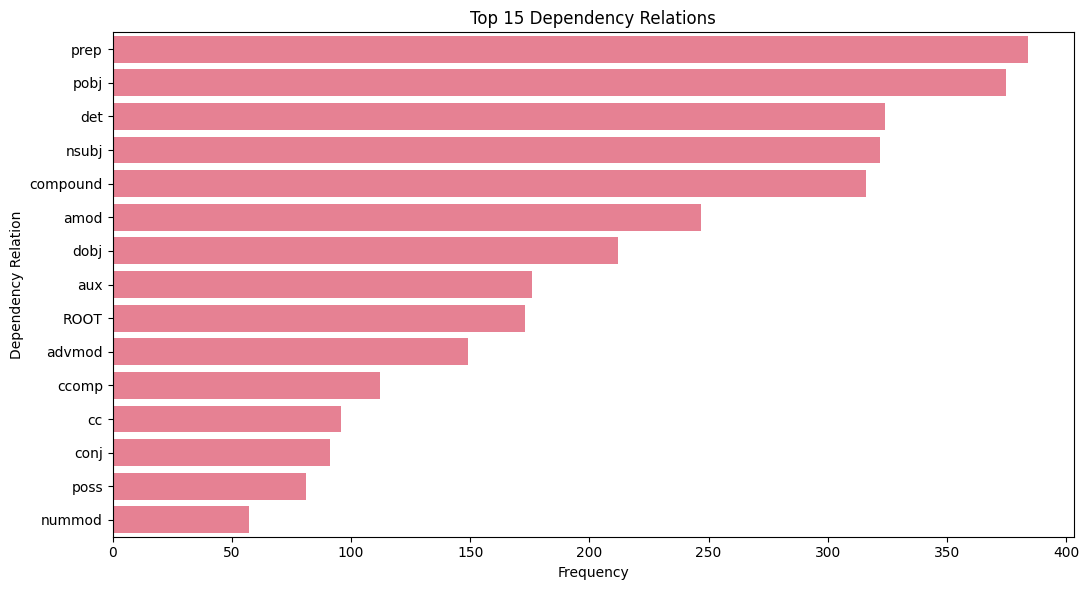


📰 SYNTAX COMPARISON BY NEWS CATEGORY


,sentences,tokens,avg_sentence_length,noun_phrases,verb_phrases,svo_patterns,dependency_types
category,,,,,,,
business,15.0,357.0,21.03,79.0,57.0,23.5,31.5
entertainment,9.0,283.5,26.98,68.0,32.5,24.0,29.0
politics,21.0,498.0,19.91,119.5,93.0,23.5,34.0
sport,19.0,439.0,20.76,101.0,64.0,27.0,31.0
tech,22.5,512.0,19.76,124.0,97.0,30.5,32.5


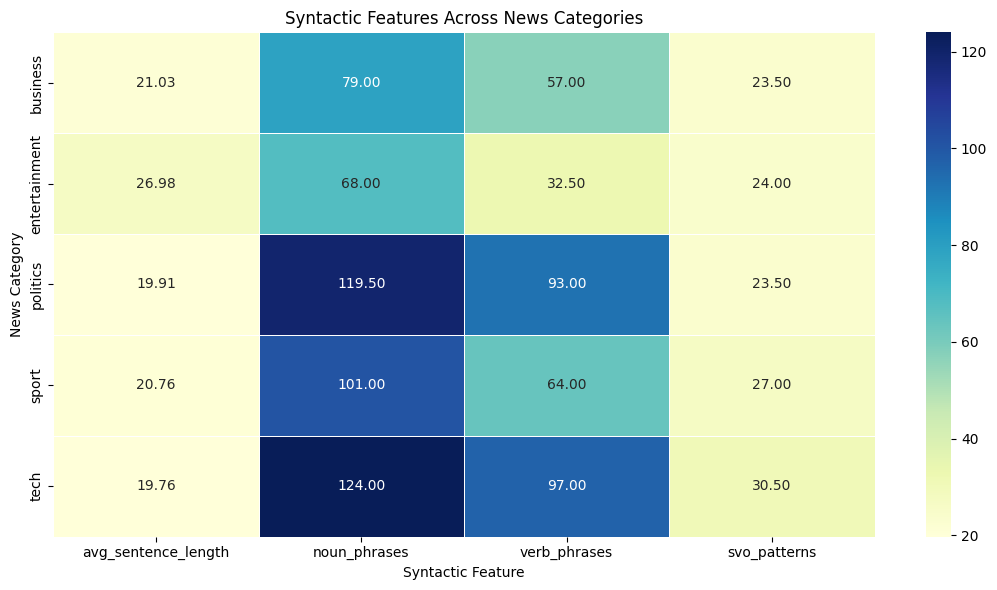


🧩 SUBJECT-VERB-OBJECT RELATIONSHIPS


,Category,Subject,Verb,Object
0,business,-,launch,lawyers
1,business,boss,launch,lawyers
2,business,s,alert,directors
3,business,s,alert,practices
4,business,s,alert,2002
5,business,confidence,slide,confidence
6,business,slides,fall,february
7,business,index,fall,95.5
8,business,index,fall,february
9,business,index,fall,97.5



💡 SYNTACTIC ANALYSIS FINDINGS
Longest average sentences: entertainment
Most noun phrases per article: tech
Most extracted SVO patterns: tech

Note: These findings are based on a small sample and should not be treated as representative of the entire dataset.

✅ MODULE 5: SYNTAX ANALYSIS COMPLETE
Articles analyzed: 10
Dependency types found: 39
Total SVO patterns: 50

Completed:
✓ Dependency parsing
✓ Subject and object extraction
✓ Noun phrase extraction
✓ Verb phrase extraction
✓ Subject-verb-object relationship extraction
✓ Syntactic complexity indicators
✓ Cross-category syntax comparison
✓ Dependency relation visualization

Ready for the next Module 5 analysis cell.


In [ ]:
# def extract_syntactic_features(text):
#     """
#     Extract syntactic features using spaCy dependency parsing

#     💡 TIP: This function should extract:
#     - Dependency relations
#     - Subject-verb-object patterns
#     - Noun phrases
#     - Verb phrases
#     """
#     if not text or pd.isna(text):
#         return {}

#     # Process text with spaCy
#     doc = nlp(str(text))

#     features = {
#         'num_sentences': len(list(doc.sents)),
#         'num_tokens': len(doc),
#         'dependency_relations': [],
#         'noun_phrases': [],
#         'verb_phrases': [],
#         'subjects': [],
#         'objects': []
#     }

#     # 🚀 YOUR CODE HERE: Extract syntactic features

#     # Extract dependency relations
#     for token in doc:
#         if not token.is_space and not token.is_punct:
#             features['dependency_relations'].append(token.dep_)

#     # Extract noun phrases
#     for chunk in doc.noun_chunks:
#         features['noun_phrases'].append(chunk.text.lower())

#     # Extract subjects and objects
#     for token in doc:
#         if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
#             features['subjects'].append(token.text.lower())
#         elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
#             features['objects'].append(token.text.lower())

#     # Count dependency types
#     dep_counts = Counter(features['dependency_relations'])
#     features['dependency_counts'] = dict(dep_counts)

#     return features

# # Apply syntactic analysis to sample articles
# print("🌳 Performing syntactic analysis...")

# # Analyze first few articles (to save computation time)
# syntactic_results = []
# for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
#     features = extract_syntactic_features(row['full_text'])
#     features['category'] = row['category']
#     features['article_id'] = row['article_id']
#     syntactic_results.append(features)

# print("✅ Syntactic analysis complete!")

# # Display results
# for i, result in enumerate(syntactic_results):
#     print(f"\n📰 Article {i+1} ({result['category']}):")
#     print(f"  Sentences: {result['num_sentences']}")
#     print(f"  Tokens: {result['num_tokens']}")
#     print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
#     print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
#     print(f"  Objects: {result['objects'][:3]}...")  # Show first 3



# ============================================================
# MODULE 5: SYNTAX PARSING AND SEMANTIC ANALYSIS
# NewsBot Intelligence System - Midterm Project
# ============================================================

import pandas as pd
import numpy as np
import spacy
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

# ------------------------------------------------------------
# STEP 1: Initialize spaCy
# ------------------------------------------------------------

try:
    nlp
except NameError:
    nlp = spacy.load("en_core_web_sm")

# ------------------------------------------------------------
# STEP 2: Extract syntactic features
# ------------------------------------------------------------

def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing.

    Features:
    - Sentence and token counts
    - Dependency relations
    - Subject-verb-object (SVO) patterns
    - Noun phrases
    - Verb phrases
    - Subjects and objects
    - Syntactic complexity indicators
    """

    if not isinstance(text, str) or not text.strip():
        return {}

    # Process original article text
    doc = nlp(text)

    sentences = list(doc.sents)

    features = {
        'num_sentences': len(sentences),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': [],
        'svo_patterns': [],
        'dependency_counts': {}
    }

    # --------------------------------------------------------
    # Extract dependency relations
    # --------------------------------------------------------

    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(
                token.dep_
            )

    # --------------------------------------------------------
    # Extract noun phrases
    # --------------------------------------------------------

    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(
            chunk.text.lower()
        )

    # --------------------------------------------------------
    # Extract subjects and objects
    # --------------------------------------------------------

    subject_deps = {
        'nsubj', 'nsubjpass', 'csubj', 'csubjpass'
    }

    object_deps = {
        'dobj', 'obj', 'iobj', 'pobj', 'attr', 'oprd'
    }

    for token in doc:

        if token.dep_ in subject_deps:
            features['subjects'].append(
                token.text.lower()
            )

        if token.dep_ in object_deps:
            features['objects'].append(
                token.text.lower()
            )

    # --------------------------------------------------------
    # Extract verb phrases
    # --------------------------------------------------------

    for token in doc:

        if token.pos_ in ['VERB', 'AUX']:

            # Include auxiliary verbs, negation and particles
            phrase_tokens = [
                child for child in token.children
                if child.dep_ in [
                    'aux', 'auxpass', 'neg', 'prt'
                ]
            ]

            phrase_tokens.append(token)

            phrase_tokens = sorted(
                phrase_tokens,
                key=lambda t: t.i
            )

            phrase = ' '.join(
                t.text for t in phrase_tokens
            )

            features['verb_phrases'].append(
                phrase.lower()
            )

    # --------------------------------------------------------
    # Extract subject-verb-object patterns
    # --------------------------------------------------------

    for token in doc:

        if token.pos_ != 'VERB':
            continue

        subjects = [
            child for child in token.children
            if child.dep_ in subject_deps
        ]

        objects = [
            child for child in token.children
            if child.dep_ in object_deps
        ]

        # Include objects connected through prepositions
        for child in token.children:
            if child.dep_ == 'prep':
                objects.extend([
                    grandchild
                    for grandchild in child.children
                    if grandchild.dep_ == 'pobj'
                ])

        for subject in subjects:
            for obj in objects:

                svo = {
                    'subject': subject.text.lower(),
                    'verb': token.lemma_.lower(),
                    'object': obj.text.lower()
                }

                features['svo_patterns'].append(svo)

    # --------------------------------------------------------
    # Count dependency types
    # --------------------------------------------------------

    dep_counts = Counter(
        features['dependency_relations']
    )

    features['dependency_counts'] = dict(dep_counts)

    # --------------------------------------------------------
    # Calculate syntactic complexity indicators
    # --------------------------------------------------------

    features['avg_sentence_length'] = (
        len([
            token for token in doc
            if not token.is_punct and not token.is_space
        ]) / len(sentences)
        if sentences else 0
    )

    features['num_noun_phrases'] = len(
        features['noun_phrases']
    )

    features['num_verb_phrases'] = len(
        features['verb_phrases']
    )

    features['num_svo_patterns'] = len(
        features['svo_patterns']
    )

    features['unique_dependency_types'] = len(
        dep_counts
    )

    return features


# ------------------------------------------------------------
# STEP 3: Apply syntactic analysis to sample articles
# ------------------------------------------------------------

print("🌳 Performing syntactic analysis...")
print("=" * 60)

# Select examples across categories for better comparison
sample_df = (
    df.groupby('category', group_keys=False)
      .head(2)
      .reset_index(drop=True)
)

syntactic_results = []

for idx, row in sample_df.iterrows():

    features = extract_syntactic_features(
        row['full_text']
    )

    features['category'] = row['category']
    features['article_id'] = row['article_id']

    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")
print(f"Articles analyzed: {len(syntactic_results)}")


# ------------------------------------------------------------
# STEP 4: Display article-level syntactic results
# ------------------------------------------------------------

print("\n📝 SYNTACTIC ANALYSIS EXAMPLES")
print("=" * 60)

for i, result in enumerate(syntactic_results):

    print(
        f"\n📰 Article {i + 1} "
        f"({result['category']})"
    )

    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")

    print(
        f"  Average sentence length: "
        f"{result['avg_sentence_length']:.2f}"
    )

    print(
        f"  Noun phrases: "
        f"{result['noun_phrases'][:3]}"
    )

    print(
        f"  Verb phrases: "
        f"{result['verb_phrases'][:3]}"
    )

    print(
        f"  Subjects: "
        f"{result['subjects'][:3]}"
    )

    print(
        f"  Objects: "
        f"{result['objects'][:3]}"
    )

    print(
        f"  SVO patterns: "
        f"{result['svo_patterns'][:3]}"
    )


# ------------------------------------------------------------
# STEP 5: Create syntactic feature summary
# ------------------------------------------------------------

print("\n📊 SYNTACTIC FEATURE SUMMARY")
print("=" * 60)

summary_rows = []

for result in syntactic_results:

    summary_rows.append({
        'article_id': result['article_id'],
        'category': result['category'],
        'sentences': result['num_sentences'],
        'tokens': result['num_tokens'],
        'avg_sentence_length':
            result['avg_sentence_length'],
        'noun_phrases':
            result['num_noun_phrases'],
        'verb_phrases':
            result['num_verb_phrases'],
        'svo_patterns':
            result['num_svo_patterns'],
        'dependency_types':
            result['unique_dependency_types']
    })

syntactic_df = pd.DataFrame(summary_rows)

display(syntactic_df)


# ------------------------------------------------------------
# STEP 6: Analyze dependency relation frequencies
# ------------------------------------------------------------

print("\n🔗 MOST COMMON DEPENDENCY RELATIONS")
print("=" * 60)

all_dependencies = Counter()

for result in syntactic_results:
    all_dependencies.update(
        result['dependency_counts']
    )

top_dependencies = all_dependencies.most_common(15)

dependency_df = pd.DataFrame(
    top_dependencies,
    columns=['Dependency', 'Frequency']
)

display(dependency_df)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=dependency_df,
    x='Frequency',
    y='Dependency'
)

plt.title('Top 15 Dependency Relations')
plt.xlabel('Frequency')
plt.ylabel('Dependency Relation')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 7: Compare syntactic features across categories
# ------------------------------------------------------------

print("\n📰 SYNTAX COMPARISON BY NEWS CATEGORY")
print("=" * 60)

category_syntax = (
    syntactic_df.groupby('category')
    .mean(numeric_only=True)
    .drop(columns=['article_id'], errors='ignore')
    .round(2)
)

display(category_syntax)

# Select key features for comparison
key_features = [
    'avg_sentence_length',
    'noun_phrases',
    'verb_phrases',
    'svo_patterns'
]

plt.figure(figsize=(11, 6))

sns.heatmap(
    category_syntax[key_features],
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Syntactic Features Across News Categories')
plt.xlabel('Syntactic Feature')
plt.ylabel('News Category')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 8: Display extracted SVO relationships
# ------------------------------------------------------------

print("\n🧩 SUBJECT-VERB-OBJECT RELATIONSHIPS")
print("=" * 60)

svo_rows = []

for result in syntactic_results:

    for pattern in result['svo_patterns'][:5]:

        svo_rows.append({
            'Category': result['category'],
            'Subject': pattern['subject'],
            'Verb': pattern['verb'],
            'Object': pattern['object']
        })

svo_df = pd.DataFrame(
    svo_rows,
    columns=['Category', 'Subject', 'Verb', 'Object']
)

display(svo_df.head(20))


# ------------------------------------------------------------
# STEP 9: Extract useful findings
# ------------------------------------------------------------

print("\n💡 SYNTACTIC ANALYSIS FINDINGS")
print("=" * 60)

if not category_syntax.empty:

    longest_sentences = (
        category_syntax['avg_sentence_length'].idxmax()
    )

    most_noun_phrases = (
        category_syntax['noun_phrases'].idxmax()
    )

    most_svo = (
        category_syntax['svo_patterns'].idxmax()
    )

    print(
        f"Longest average sentences: "
        f"{longest_sentences}"
    )

    print(
        f"Most noun phrases per article: "
        f"{most_noun_phrases}"
    )

    print(
        f"Most extracted SVO patterns: "
        f"{most_svo}"
    )

print(
    "\nNote: These findings are based on a small "
    "sample and should not be treated as "
    "representative of the entire dataset."
)


# ------------------------------------------------------------
# STEP 10: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 5: SYNTAX ANALYSIS COMPLETE")
print("=" * 60)

print(f"Articles analyzed: {len(syntactic_results)}")
print(f"Dependency types found: {len(all_dependencies)}")
print(f"Total SVO patterns: {len(svo_df)}")

print("\nCompleted:")
print("✓ Dependency parsing")
print("✓ Subject and object extraction")
print("✓ Noun phrase extraction")
print("✓ Verb phrase extraction")
print("✓ Subject-verb-object relationship extraction")
print("✓ Syntactic complexity indicators")
print("✓ Cross-category syntax comparison")
print("✓ Dependency relation visualization")

print("\nReady for the next Module 5 analysis cell.")


🌳 DEPENDENCY PARSING VISUALIZATION

📝 Sample sentence:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  

🌳 Dependency Parse Visualization:



🔍 ANALYZING SYNTACTIC COMPLEXITY
Articles selected: 150

Articles per category:
category
business         30
entertainment    30
politics         30
sport            30
tech             30
Name: count, dtype: int64

✅ Syntactic analysis complete!

📊 SYNTACTIC COMPLEXITY BY CATEGORY


,avg_sentence_length,avg_dependency_distance,subordinate_clauses,noun_phrase_count,verb_count
category,,,,,
business,21.88,2.54,20.13,79.63,38.10
entertainment,21.49,2.54,20.07,86.83,39.07
politics,22.26,2.50,44.00,126.67,68.50
sport,19.31,2.56,22.73,89.70,42.63
tech,22.10,2.49,36.40,131.07,63.93


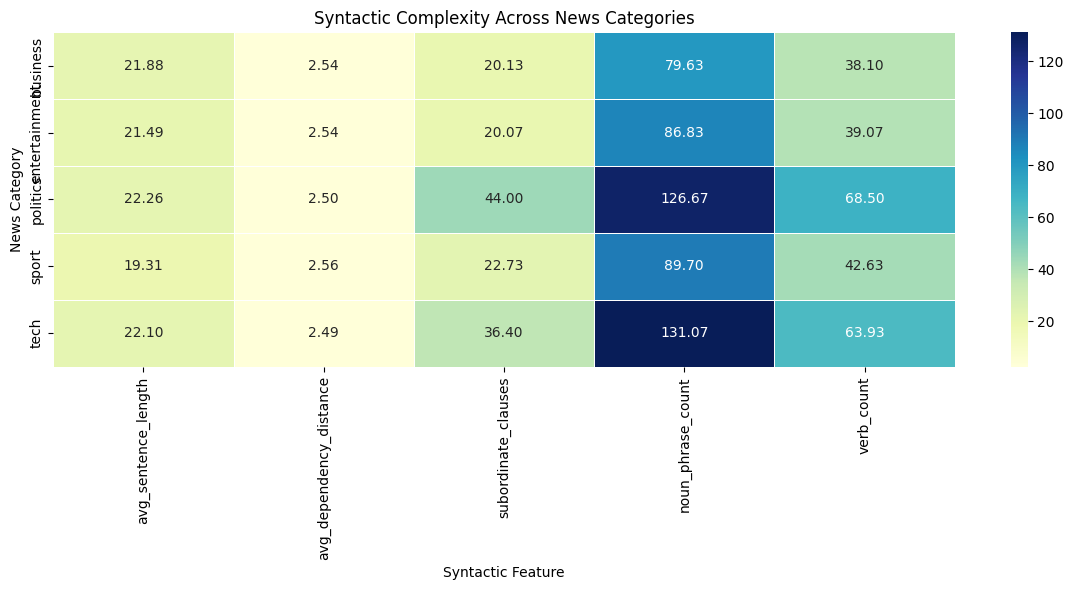

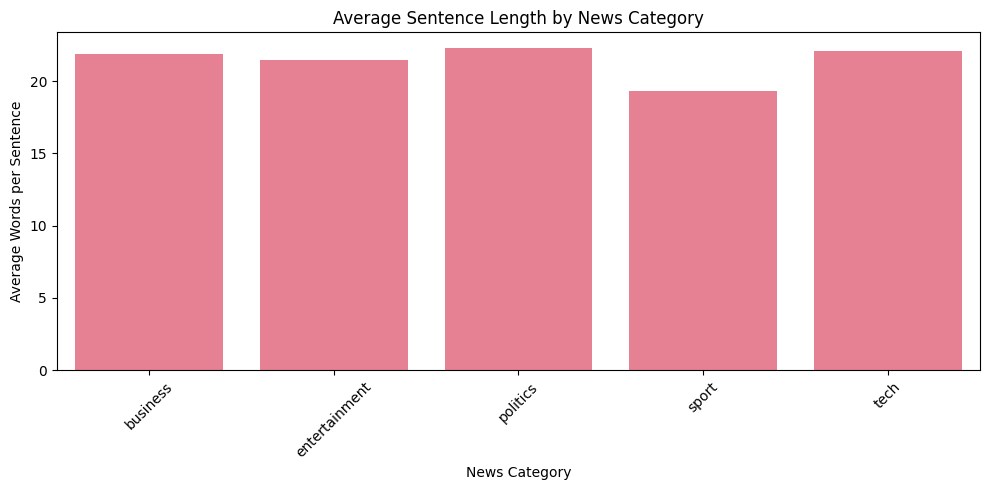


🧩 ACTION PATTERNS: WHO DID WHAT?
Total action patterns: 2961

Sample subject-verb-object relationships:


,article_id,category,subject,verb,object
0,2048,business,chief,fall,low
1,2048,business,chief,fall,departure
2,2048,business,tellier,leave,company
3,2048,business,tellier,leave,restructuring
4,2048,business,that,control,firm
5,2048,business,part,take,role
6,2048,business,part,take,structure
7,2048,business,which,begin,january
8,2048,business,it,earn,10
9,2048,business,it,earn,quarter



Most common action verbs:


,Frequency
verb,
have,136
take,86
make,70
play,69
tell,63
win,60
go,56
get,51
s,51


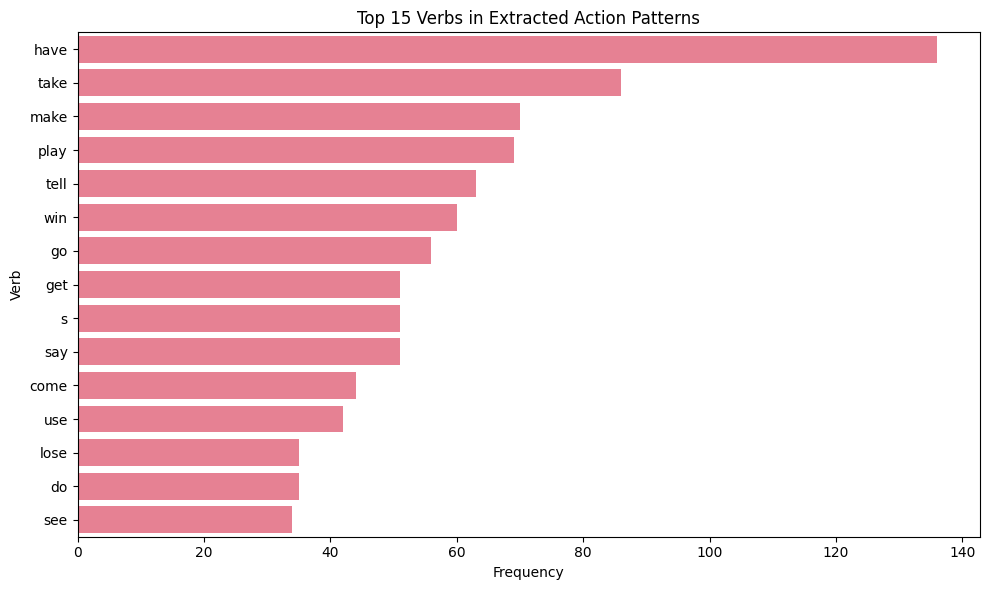


🔗 COMMON DEPENDENCY RELATIONS BY CATEGORY

📰 BUSINESS


,dependency,count,proportion
6,prep,1117,0.119083
12,pobj,1044,0.111301
14,det,964,0.102772
4,compound,719,0.076652
1,nsubj,713,0.076013
11,amod,709,0.075586
5,dobj,434,0.046269
13,ROOT,429,0.045736
2,aux,403,0.042964
0,advmod,350,0.037313



📰 ENTERTAINMENT


,dependency,count,proportion
42,compound,1144,0.116473
44,prep,1003,0.102118
45,pobj,966,0.098351
51,det,891,0.090715
43,nsubj,739,0.075239
54,amod,731,0.074425
46,ROOT,473,0.048157
49,dobj,469,0.047750
47,aux,359,0.036551
53,advmod,323,0.032885



📰 POLITICS


,dependency,count,proportion
92,prep,1357,0.096309
89,det,1309,0.092903
86,nsubj,1296,0.091980
93,pobj,1291,0.091625
85,compound,1054,0.074805
90,amod,930,0.066004
96,aux,841,0.059688
88,dobj,744,0.052803
95,ROOT,641,0.045493
106,advmod,521,0.036977



📰 SPORT


,dependency,count,proportion
132,prep,1060,0.106234
141,nsubj,983,0.098517
134,pobj,965,0.096713
140,det,851,0.085288
133,compound,809,0.081078
138,amod,575,0.057627
129,ROOT,545,0.054620
135,aux,525,0.052616
131,dobj,487,0.048807
149,advmod,435,0.043596



📰 TECH


,dependency,count,proportion
180,prep,1581,0.108749
181,pobj,1487,0.102284
175,det,1344,0.092447
173,nsubj,1203,0.082749
184,amod,1071,0.073669
177,compound,1037,0.071330
176,dobj,798,0.054891
178,aux,778,0.053515
174,ROOT,656,0.045123
188,advmod,612,0.042097


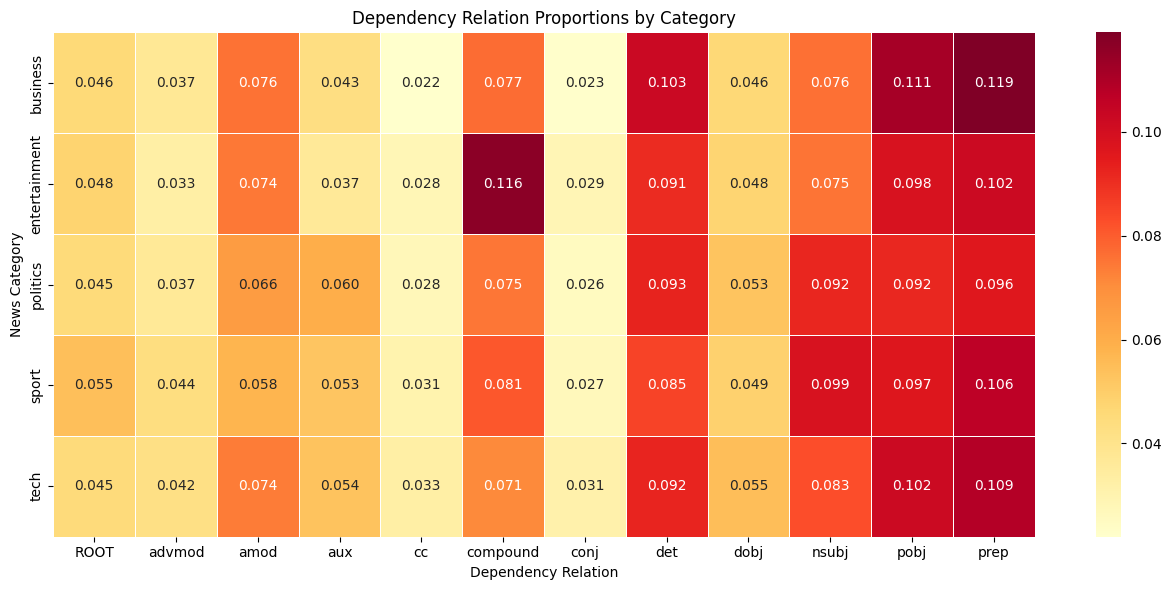


🤖 SYNTAX FEATURES FOR CLASSIFICATION
Feature matrix shape: (150, 5)
Label vector shape: (150,)

Syntax features:


,avg_sentence_length,avg_dependency_distance,subordinate_clause_ratio,noun_phrase_ratio,verb_ratio
0,24.083333,2.523466,0.065744,0.228374,0.131488
1,22.333333,2.628906,0.067164,0.272388,0.123134
2,23.333333,2.970149,0.057143,0.265714,0.111429
3,22.631579,2.338200,0.058140,0.267442,0.127907
4,25.166667,2.620690,0.086093,0.235099,0.165563



Feature summary:


,avg_sentence_length,avg_dependency_distance,subordinate_clause_ratio,noun_phrase_ratio,verb_ratio
count,150.000,150.000,150.000,150.000,150.000
mean,21.407,2.528,0.072,0.265,0.130
std,3.029,0.214,0.021,0.022,0.022
min,11.684,2.082,0.015,0.205,0.076
25%,19.468,2.399,0.058,0.251,0.118
50%,21.633,2.506,0.071,0.265,0.132
75%,23.329,2.672,0.089,0.278,0.144
max,28.789,3.110,0.120,0.327,0.175



Note: These syntax features cover only the sampled articles. For full-dataset classification, extract features for every training and test article using the same method.

💡 SYNTACTIC ANALYSIS FINDINGS
Highest avg_sentence_length: politics (22.26)
Highest avg_dependency_distance: sport (2.56)
Highest subordinate_clauses: politics (44.00)
Highest noun_phrase_count: tech (131.07)
Highest verb_count: politics (68.50)

Interpretation: These results describe syntactic differences within the sampled articles. They do not establish statistical significance or causal relationships.

✅ MODULE 5: EXTENDED SYNTAX ANALYSIS COMPLETE
Articles analyzed: 150
Categories: 5
Action patterns extracted: 2961
Syntax features created: 5

Completed student tasks:
✓ Dependency parsing visualization
✓ Syntactic complexity comparison
✓ Action pattern extraction
✓ Dependency frequency analysis
✓ Cross-category dependency heatmap
✓ Syntax feature engineering

Ready for Module 6: Sentiment and Emotion Analysis


In [ ]:
# # Visualize dependency parsing for a sample sentence
# from spacy import displacy

# # Choose a sample sentence
# sample_sentence = df.iloc[0]['content']  # First article's content
# print(f"📝 Sample sentence: {sample_sentence}")

# # Process with spaCy
# doc = nlp(sample_sentence)

# # Display dependency tree (this works best in Jupyter)
# print("\n🌳 Dependency Parse Visualization:")
# try:
#     # This will create an interactive visualization in Jupyter
#     displacy.render(doc, style="dep", jupyter=True)
# except:
#     # Fallback: print dependency information
#     print("\n🔗 Dependency Relations:")
#     for token in doc:
#         if not token.is_space and not token.is_punct:
#             print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# # 💡 STUDENT TASK: Extend syntactic analysis
# # - Compare syntactic complexity across categories
# # - Extract action patterns (who did what)
# # - Identify most common dependency relations per category
# # - Create features for classification based on syntax


# ============================================================
# MODULE 5: DEPENDENCY PARSING AND SYNTACTIC ANALYSIS
# NewsBot Intelligence System - Midterm Project
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
from spacy import displacy
from IPython.display import display, HTML

# ------------------------------------------------------------
# STEP 1: Visualize dependency parsing
# ------------------------------------------------------------

print("🌳 DEPENDENCY PARSING VISUALIZATION")
print("=" * 60)

# Use the first sentence instead of the entire article
# to keep the dependency tree readable.
sample_text = df.iloc[0]['content']
sample_doc = nlp(sample_text)

sample_sentence = next(iter(sample_doc.sents), None)

if sample_sentence is not None:
    print(f"\n📝 Sample sentence:\n{sample_sentence.text}")

    print("\n🌳 Dependency Parse Visualization:")

    try:
        displacy.render(
            sample_sentence,
            style="dep",
            jupyter=True,
            options={
                "compact": True,
                "distance": 100,
                "font": "Arial"
            }
        )
    except Exception as e:
        print(f"Visualization unavailable: {e}")

        print("\n🔗 Dependency Relations:")
        for token in sample_sentence:
            if not token.is_space and not token.is_punct:
                print(
                    f"{token.text:15} "
                    f"{token.dep_:12} "
                    f"{token.head.text}"
                )


# ------------------------------------------------------------
# STEP 2: Extract syntactic complexity features
# ------------------------------------------------------------

def calculate_syntactic_complexity(doc):
    """
    Calculate interpretable syntactic features.

    Features:
    - Sentence count
    - Average sentence length
    - Average dependency distance
    - Subordinate clause count
    - Noun phrase count
    - Verb count
    """

    sentences = list(doc.sents)

    valid_tokens = [
        token for token in doc
        if not token.is_punct and not token.is_space
    ]

    num_sentences = len(sentences)
    num_tokens = len(valid_tokens)

    avg_sentence_length = (
        num_tokens / num_sentences
        if num_sentences else 0
    )

    dependency_distances = [
        abs(token.i - token.head.i)
        for token in valid_tokens
        if token.head != token
    ]

    avg_dependency_distance = (
        np.mean(dependency_distances)
        if dependency_distances else 0
    )

    subordinate_clauses = sum(
        token.dep_ in [
            'advcl', 'ccomp', 'xcomp', 'acl', 'relcl'
        ]
        for token in doc
    )

    noun_phrase_count = len(list(doc.noun_chunks))

    verb_count = sum(
        token.pos_ == 'VERB'
        for token in doc
    )

    return {
        'num_sentences': num_sentences,
        'num_tokens': num_tokens,
        'avg_sentence_length': avg_sentence_length,
        'avg_dependency_distance': avg_dependency_distance,
        'subordinate_clauses': subordinate_clauses,
        'noun_phrase_count': noun_phrase_count,
        'verb_count': verb_count
    }


# ------------------------------------------------------------
# STEP 3: Extract action patterns (who did what)
# ------------------------------------------------------------

def extract_action_patterns(doc):
    """
    Extract simple subject-verb-object relationships.

    Example:
    Apple announced earnings
    -> Apple | announce | earnings

    This is a rule-based approximation and may not
    capture complex or passive constructions.
    """

    patterns = []

    subject_deps = {'nsubj', 'csubj'}
    object_deps = {'dobj', 'obj', 'iobj', 'attr'}

    for token in doc:

        if token.pos_ != 'VERB':
            continue

        subjects = [
            child for child in token.children
            if child.dep_ in subject_deps
        ]

        objects = [
            child for child in token.children
            if child.dep_ in object_deps
        ]

        # Include objects of prepositions
        for child in token.children:
            if child.dep_ == 'prep':
                objects.extend([
                    grandchild
                    for grandchild in child.children
                    if grandchild.dep_ == 'pobj'
                ])

        for subject in subjects:
            for obj in objects:

                patterns.append({
                    'subject': subject.text,
                    'verb': token.lemma_,
                    'object': obj.text
                })

    return patterns


# ------------------------------------------------------------
# STEP 4: Analyze a stratified sample from each category
# ------------------------------------------------------------

print("\n🔍 ANALYZING SYNTACTIC COMPLEXITY")
print("=" * 60)

# Use 30 articles per category for a manageable
# but more representative comparison.
SAMPLE_PER_CATEGORY = 30
RANDOM_STATE = 42

sample_parts = []

for category, group in df.groupby('category'):
    sample_parts.append(
        group.sample(
            n=min(SAMPLE_PER_CATEGORY, len(group)),
            random_state=RANDOM_STATE
        )
    )

syntax_sample_df = pd.concat(
    sample_parts,
    ignore_index=True
)

print(f"Articles selected: {len(syntax_sample_df)}")
print("\nArticles per category:")
print(syntax_sample_df['category'].value_counts())

syntax_feature_rows = []
action_rows = []
dependency_by_category = defaultdict(Counter)

# Process articles efficiently with spaCy
docs = nlp.pipe(
    syntax_sample_df['content'].astype(str).tolist(),
    batch_size=16
)

for (_, row), doc in zip(
    syntax_sample_df.iterrows(), docs
):

    category = row['category']
    article_id = row['article_id']

    # Extract syntactic complexity
    features = calculate_syntactic_complexity(doc)

    features['article_id'] = article_id
    features['category'] = category

    syntax_feature_rows.append(features)

    # Extract action patterns
    actions = extract_action_patterns(doc)

    for action in actions:
        action_rows.append({
            'article_id': article_id,
            'category': category,
            'subject': action['subject'],
            'verb': action['verb'],
            'object': action['object']
        })

    # Count dependency relations
    dependency_by_category[category].update(
        token.dep_
        for token in doc
        if not token.is_space and not token.is_punct
    )

# Create DataFrames
syntax_features_df = pd.DataFrame(syntax_feature_rows)

action_patterns_df = pd.DataFrame(
    action_rows,
    columns=[
        'article_id', 'category',
        'subject', 'verb', 'object'
    ]
)

print("\n✅ Syntactic analysis complete!")


# ------------------------------------------------------------
# STUDENT TASK 1: Compare syntactic complexity
# ------------------------------------------------------------

print("\n📊 SYNTACTIC COMPLEXITY BY CATEGORY")
print("=" * 60)

complexity_columns = [
    'avg_sentence_length',
    'avg_dependency_distance',
    'subordinate_clauses',
    'noun_phrase_count',
    'verb_count'
]

complexity_summary = (
    syntax_features_df.groupby('category')
    [complexity_columns]
    .mean()
    .round(2)
)

display(complexity_summary)

# Heatmap of category-level complexity
plt.figure(figsize=(12, 6))

sns.heatmap(
    complexity_summary,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Syntactic Complexity Across News Categories')
plt.xlabel('Syntactic Feature')
plt.ylabel('News Category')
plt.tight_layout()
plt.show()

# Average sentence length comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=syntax_features_df,
    x='category',
    y='avg_sentence_length',
    errorbar=None
)

plt.title('Average Sentence Length by News Category')
plt.xlabel('News Category')
plt.ylabel('Average Words per Sentence')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STUDENT TASK 2: Extract action patterns
# ------------------------------------------------------------

print("\n🧩 ACTION PATTERNS: WHO DID WHAT?")
print("=" * 60)

print(f"Total action patterns: {len(action_patterns_df)}")

print("\nSample subject-verb-object relationships:")
display(action_patterns_df.head(20))

if not action_patterns_df.empty:

    print("\nMost common action verbs:")

    top_action_verbs = (
        action_patterns_df['verb']
        .value_counts()
        .head(15)
    )

    display(top_action_verbs.to_frame('Frequency'))

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=top_action_verbs.values,
        y=top_action_verbs.index
    )

    plt.title('Top 15 Verbs in Extracted Action Patterns')
    plt.xlabel('Frequency')
    plt.ylabel('Verb')
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# STUDENT TASK 3: Common dependencies per category
# ------------------------------------------------------------

print("\n🔗 COMMON DEPENDENCY RELATIONS BY CATEGORY")
print("=" * 60)

dependency_rows = []

for category, counts in dependency_by_category.items():

    total = sum(counts.values())

    for dep, count in counts.items():
        dependency_rows.append({
            'category': category,
            'dependency': dep,
            'count': count,
            'proportion': count / total if total else 0
        })

dependency_category_df = pd.DataFrame(
    dependency_rows
)

for category in sorted(df['category'].unique()):

    category_deps = (
        dependency_category_df[
            dependency_category_df['category'] == category
        ]
        .sort_values('count', ascending=False)
        .head(10)
    )

    print(f"\n📰 {category.upper()}")
    display(
        category_deps[
            ['dependency', 'count', 'proportion']
        ]
    )

# Select most common dependencies overall
top_dependencies = (
    dependency_category_df.groupby('dependency')['count']
    .sum()
    .nlargest(12)
    .index
)

dependency_heatmap = (
    dependency_category_df[
        dependency_category_df['dependency'].isin(
            top_dependencies
        )
    ]
    .pivot(
        index='category',
        columns='dependency',
        values='proportion'
    )
    .fillna(0)
)

plt.figure(figsize=(13, 6))

sns.heatmap(
    dependency_heatmap,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Dependency Relation Proportions by Category')
plt.xlabel('Dependency Relation')
plt.ylabel('News Category')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STUDENT TASK 4: Create syntax features for classification
# ------------------------------------------------------------

print("\n🤖 SYNTAX FEATURES FOR CLASSIFICATION")
print("=" * 60)

# Normalize article-level count features by
# token count to reduce article-length bias.
syntax_features_df['subordinate_clause_ratio'] = (
    syntax_features_df['subordinate_clauses'] /
    syntax_features_df['num_tokens'].clip(lower=1)
)

syntax_features_df['noun_phrase_ratio'] = (
    syntax_features_df['noun_phrase_count'] /
    syntax_features_df['num_tokens'].clip(lower=1)
)

syntax_features_df['verb_ratio'] = (
    syntax_features_df['verb_count'] /
    syntax_features_df['num_tokens'].clip(lower=1)
)

syntax_feature_columns = [
    'avg_sentence_length',
    'avg_dependency_distance',
    'subordinate_clause_ratio',
    'noun_phrase_ratio',
    'verb_ratio'
]

# Feature matrix for sampled articles
X_syntax = syntax_features_df[
    syntax_feature_columns
].copy()

# Corresponding category labels
y_syntax = syntax_features_df['category'].copy()

print(f"Feature matrix shape: {X_syntax.shape}")
print(f"Label vector shape: {y_syntax.shape}")

print("\nSyntax features:")
display(X_syntax.head())

print("\nFeature summary:")
display(X_syntax.describe().round(3))

print(
    "\nNote: These syntax features cover only "
    "the sampled articles. For full-dataset "
    "classification, extract features for every "
    "training and test article using the same method."
)


# ------------------------------------------------------------
# STEP 9: Automatically summarize key findings
# ------------------------------------------------------------

print("\n💡 SYNTACTIC ANALYSIS FINDINGS")
print("=" * 60)

for feature in complexity_columns:

    highest_category = complexity_summary[feature].idxmax()
    highest_value = complexity_summary[feature].max()

    print(
        f"Highest {feature}: "
        f"{highest_category} ({highest_value:.2f})"
    )

print(
    "\nInterpretation: These results describe "
    "syntactic differences within the sampled "
    "articles. They do not establish statistical "
    "significance or causal relationships."
)


# ------------------------------------------------------------
# STEP 10: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 5: EXTENDED SYNTAX ANALYSIS COMPLETE")
print("=" * 60)

print(f"Articles analyzed: {len(syntax_features_df)}")
print(f"Categories: {syntax_features_df['category'].nunique()}")
print(f"Action patterns extracted: {len(action_patterns_df)}")
print(f"Syntax features created: {len(syntax_feature_columns)}")

print("\nCompleted student tasks:")
print("✓ Dependency parsing visualization")
print("✓ Syntactic complexity comparison")
print("✓ Action pattern extraction")
print("✓ Dependency frequency analysis")
print("✓ Cross-category dependency heatmap")
print("✓ Syntax feature engineering")

print("\nReady for Module 6: Sentiment and Emotion Analysis")


## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

SENTIMENT AND EMOTION ANALYSIS

ANALYZER VALIDATION


,Text,Sentiment,Compound,Dominant Emotion,Emotion Total
0,The company reported excellent financial results.,positive,0.5719,joy,1.0
1,Residents experienced fear and terror during t...,negative,-0.7650,anger,1.0
2,Investors expressed anger and outrage over the...,negative,-0.8658,anger,1.0
3,The team celebrated with joy and happiness.,positive,0.9022,joy,1.0
4,The community experienced sadness and grief.,negative,-0.7269,sadness,1.0



PASS: NRC emotion analyzer is functioning.

ANALYZING ARTICLE SENTIMENT
Articles analyzed: 1440

Sample sentiment results:


,category,full_sentiment,full_label,pos_score,neu_score,neg_score
0,business,-0.9701,negative,0.063,0.793,0.144
1,business,0.7623,positive,0.117,0.786,0.096
2,business,-0.9318,negative,0.083,0.809,0.108
3,tech,0.9554,positive,0.058,0.916,0.026
4,business,-0.9486,negative,0.078,0.807,0.115



OVERALL SENTIMENT DISTRIBUTION


,Articles
full_label,
positive,1013
neutral,11
negative,416


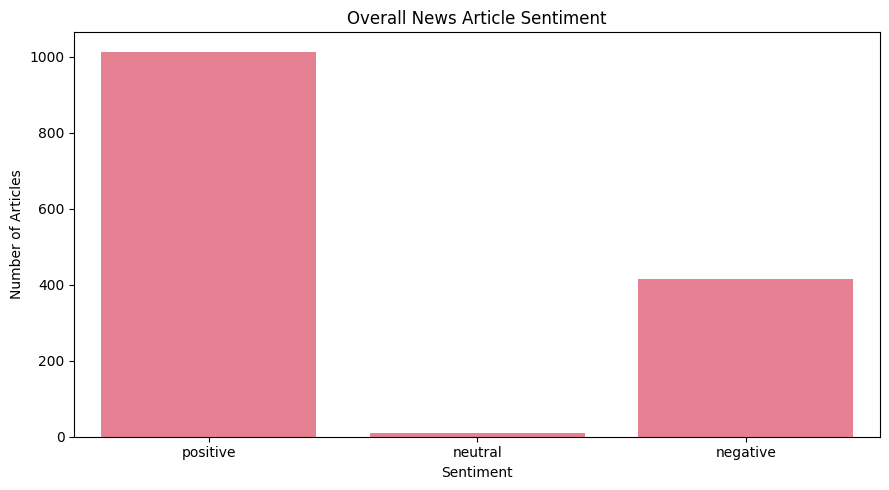


SENTIMENT BY NEWS CATEGORY


full_label,positive,neutral,negative
category,,,
business,62.09,1.49,36.42
entertainment,80.23,0.76,19.01
politics,53.01,0.38,46.62
sport,78.95,0.29,20.76
tech,78.21,0.85,20.94


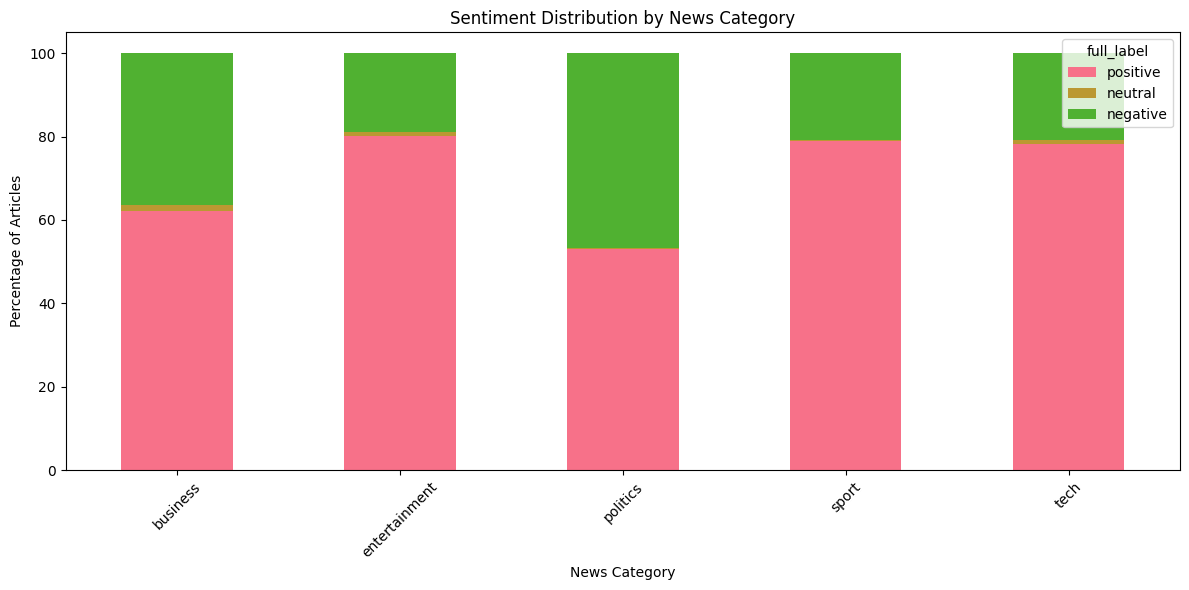


SENTIMENT INTENSITY DISTRIBUTION


,Articles
emotional_tone,
Strong Positive,957
Strong Negative,367
Mild Positive,56
Mild Negative,49
Neutral,11



NRC EMOTION EXPERIMENT
Articles sampled: 150

EMOTION VALIDATION
Articles with emotion matches: 150
Articles without matches: 0

Sample emotion results:


,category,dominant_emotion,anger,anticipation,disgust,fear,joy,sadness,surprise,trust
0,business,trust,0.041667,0.333333,0.000000,0.041667,0.041667,0.125000,0.041667,0.375000
1,business,anger,0.226415,0.056604,0.113208,0.169811,0.018868,0.169811,0.018868,0.226415
2,business,trust,0.071429,0.107143,0.000000,0.071429,0.071429,0.250000,0.035714,0.392857
3,business,trust,0.140845,0.126761,0.098592,0.154930,0.084507,0.112676,0.028169,0.253521
4,business,trust,0.020000,0.240000,0.020000,0.160000,0.100000,0.040000,0.020000,0.400000
5,business,trust,0.071429,0.142857,0.000000,0.071429,0.071429,0.214286,0.000000,0.428571
6,business,trust,0.000000,0.184211,0.026316,0.026316,0.210526,0.000000,0.105263,0.447368
7,business,fear,0.250000,0.166667,0.000000,0.416667,0.000000,0.000000,0.000000,0.166667
8,business,anticipation,0.072727,0.345455,0.036364,0.090909,0.090909,0.018182,0.072727,0.272727
9,business,trust,0.068182,0.181818,0.022727,0.090909,0.090909,0.113636,0.090909,0.340909



PASS: Emotion results validated.

EMOTION ASSOCIATIONS BY CATEGORY


,anger,anticipation,disgust,fear,joy,sadness,surprise,trust
category,,,,,,,,
business,0.089,0.202,0.043,0.117,0.089,0.102,0.046,0.312
entertainment,0.064,0.172,0.048,0.077,0.190,0.094,0.104,0.252
politics,0.104,0.182,0.046,0.150,0.090,0.100,0.054,0.275
sport,0.084,0.208,0.043,0.092,0.136,0.102,0.077,0.258
tech,0.085,0.215,0.046,0.131,0.119,0.079,0.082,0.243


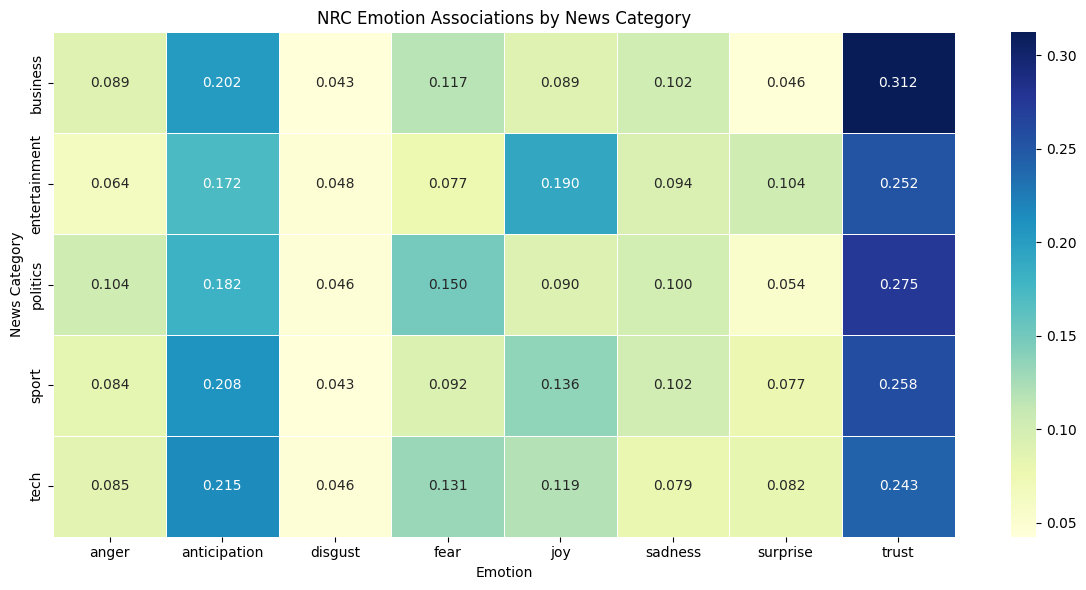


DOMINANT EMOTION BY CATEGORY
business: trust (0.312)
entertainment: trust (0.252)
politics: trust (0.275)
sport: trust (0.258)
tech: trust (0.243)

MODULE 6: SENTIMENT AND EMOTION ANALYSIS COMPLETE
VADER articles analyzed: 1440
NRC articles sampled: 150
Emotion categories: 8
Articles with emotion matches: 150
Articles without matches: 0

Completed:
✓ VADER sentiment analysis
✓ Sentiment distribution by category
✓ Sentiment intensity analysis
✓ NRC emotion association analysis
✓ Emotion score validation
✓ Cross-category emotion heatmap

Limitations:
NRC emotion scores represent lexical associations, not verified emotional states.
The emotion experiment uses a stratified sample of 30 articles per category.

Ready for Module 6: Sentiment Pattern Analysis


In [ ]:
# # Initialize sentiment analyzer
# sia = SentimentIntensityAnalyzer()

# def analyze_sentiment(text):
#     """
#     Analyze sentiment using VADER sentiment analyzer

#     💡 TIP: VADER returns:
#     - compound: overall sentiment (-1 to 1)
#     - pos: positive score (0 to 1)
#     - neu: neutral score (0 to 1)
#     - neg: negative score (0 to 1)
#     """
#     if not text or pd.isna(text):
#         return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

#     # 🚀 YOUR CODE HERE: Implement sentiment analysis
#     scores = sia.polarity_scores(str(text))

#     # Add interpretation
#     if scores['compound'] >= 0.05:
#         scores['sentiment_label'] = 'positive'
#     elif scores['compound'] <= -0.05:
#         scores['sentiment_label'] = 'negative'
#     else:
#         scores['sentiment_label'] = 'neutral'

#     return scores

# # Apply sentiment analysis to all articles
# print("😊 Analyzing sentiment...")

# sentiment_results = []
# for idx, row in df.iterrows():
#     # Analyze both title and content
#     title_sentiment = analyze_sentiment(row['title'])
#     content_sentiment = analyze_sentiment(row['content'])
#     full_sentiment = analyze_sentiment(row['full_text'])

#     result = {
#         'article_id': row['article_id'],
#         'category': row['category'],
#         'title_sentiment': title_sentiment['compound'],
#         'title_label': title_sentiment['sentiment_label'],
#         'content_sentiment': content_sentiment['compound'],
#         'content_label': content_sentiment['sentiment_label'],
#         'full_sentiment': full_sentiment['compound'],
#         'full_label': full_sentiment['sentiment_label'],
#         'pos_score': full_sentiment['pos'],
#         'neu_score': full_sentiment['neu'],
#         'neg_score': full_sentiment['neg']
#     }
#     sentiment_results.append(result)

# # Convert to DataFrame
# sentiment_df = pd.DataFrame(sentiment_results)

# print("✅ Sentiment analysis complete!")
# print(f"📊 Analyzed {len(sentiment_df)} articles")

# # Display sample results
# print("\n📝 Sample sentiment results:")
# print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())



# ============================================================
# MODULE 6: SENTIMENT AND EMOTION ANALYSIS
# NewsBot Intelligence System - Midterm Project
# ============================================================

import sys
import subprocess
import numpy as np
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.sentiment import SentimentIntensityAnalyzer

# ------------------------------------------------------------
# STEP 1: Initialize NLP resources
# ------------------------------------------------------------

nltk.download('vader_lexicon', quiet=True)

try:
    from nrclex import NRCLex
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "nrclex"
    ])
    from nrclex import NRCLex

sia = SentimentIntensityAnalyzer()

EMOTION_LABELS = [
    'anger',
    'anticipation',
    'disgust',
    'fear',
    'joy',
    'sadness',
    'surprise',
    'trust'
]

RANDOM_STATE = 42
EMOTION_SAMPLE_PER_CATEGORY = 30

print("SENTIMENT AND EMOTION ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# STEP 2: VADER sentiment analysis
# ------------------------------------------------------------

def analyze_sentiment(text):
    """
    Estimate sentiment polarity using VADER.

    Returns compound, positive, neutral, negative,
    and an overall sentiment label.
    """

    if not isinstance(text, str) or not text.strip():
        return {
            'compound': 0.0,
            'pos': 0.0,
            'neu': 1.0,
            'neg': 0.0,
            'sentiment_label': 'neutral'
        }

    scores = sia.polarity_scores(text)

    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# ------------------------------------------------------------
# STEP 3: NRC emotion association analysis
# ------------------------------------------------------------


def analyze_emotions(text):
    """
    Estimate eight NRC emotion associations using NRCLex 3.x.

    Returns normalized emotion scores.
    A zero-score result indicates no matched emotion terms.
    """

    empty_scores = {
        label: 0.0
        for label in EMOTION_LABELS
    }

    if not isinstance(text, str) or not text.strip():
        return empty_scores.copy()

    emotion_result = NRCLex(text)

    # NRCLex 3.x exposes raw emotion association counts.
    raw_scores = emotion_result.raw_emotion_scores

    if not isinstance(raw_scores, dict):
        raise TypeError(
            "NRCLex returned an unexpected emotion-score format."
        )

    scores = {
        label: float(raw_scores.get(label, 0.0))
        for label in EMOTION_LABELS
    }

    total = sum(scores.values())

    if total > 0:
        scores = {
            label: value / total
            for label, value in scores.items()
        }

    return scores


def get_dominant_emotion(scores):
    """
    Return the highest-scoring emotion.
    Return unknown if no emotion is detected.
    """

    if not scores:
        return 'unknown'

    if max(scores.values()) <= 0:
        return 'unknown'

    return max(scores, key=scores.get)

# ------------------------------------------------------------
# STEP 4: Validate both analyzers
# ------------------------------------------------------------

print("\nANALYZER VALIDATION")
print("=" * 60)

test_sentences = [
    "The company reported excellent financial results.",
    "Residents experienced fear and terror during the storm.",
    "Investors expressed anger and outrage over the losses.",
    "The team celebrated with joy and happiness.",
    "The community experienced sadness and grief."
]

validation_rows = []

for sentence in test_sentences:

    sentiment = analyze_sentiment(sentence)
    emotions = analyze_emotions(sentence)

    dominant = get_dominant_emotion(emotions)

    validation_rows.append({
        'Text': sentence,
        'Sentiment': sentiment['sentiment_label'],
        'Compound': sentiment['compound'],
        'Dominant Emotion': dominant,
        'Emotion Total': sum(emotions.values())
    })

validation_df = pd.DataFrame(validation_rows)

display(validation_df)

# Fail early if the NRC analyzer is not working
validation_scores = analyze_emotions(
    "fear anger joy sadness trust"
)

if sum(validation_scores.values()) <= 0:
    raise RuntimeError(
        "NRC validation failed: no emotion "
        "associations were detected."
    )

print("\nPASS: NRC emotion analyzer is functioning.")

# ------------------------------------------------------------
# STEP 5: Apply VADER to all articles
# ------------------------------------------------------------

print("\nANALYZING ARTICLE SENTIMENT")
print("=" * 60)

sentiment_results = []

for _, row in df.iterrows():

    title_sentiment = analyze_sentiment(
        row['title']
    )

    content_sentiment = analyze_sentiment(
        row['content']
    )

    full_sentiment = analyze_sentiment(
        row['full_text']
    )

    sentiment_results.append({
        'article_id': row['article_id'],
        'category': row['category'],

        'title_sentiment':
            title_sentiment['compound'],
        'title_label':
            title_sentiment['sentiment_label'],

        'content_sentiment':
            content_sentiment['compound'],
        'content_label':
            content_sentiment['sentiment_label'],

        'full_sentiment':
            full_sentiment['compound'],
        'full_label':
            full_sentiment['sentiment_label'],

        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    })

sentiment_df = pd.DataFrame(sentiment_results)

assert len(sentiment_df) == len(df)
assert sentiment_df['article_id'].is_unique

print(f"Articles analyzed: {len(sentiment_df)}")

print("\nSample sentiment results:")
display(
    sentiment_df[
        [
            'category',
            'full_sentiment',
            'full_label',
            'pos_score',
            'neu_score',
            'neg_score'
        ]
    ].head()
)

# ------------------------------------------------------------
# STEP 6: Overall sentiment distribution
# ------------------------------------------------------------

print("\nOVERALL SENTIMENT DISTRIBUTION")
print("=" * 60)

sentiment_counts = (
    sentiment_df['full_label']
    .value_counts()
    .reindex(
        ['positive', 'neutral', 'negative'],
        fill_value=0
    )
)

display(sentiment_counts.to_frame('Articles'))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title('Overall News Article Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Articles')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 7: Sentiment distribution by category
# ------------------------------------------------------------

print("\nSENTIMENT BY NEWS CATEGORY")
print("=" * 60)

sentiment_by_category = pd.crosstab(
    sentiment_df['category'],
    sentiment_df['full_label'],
    normalize='index'
).mul(100)

sentiment_by_category = sentiment_by_category.reindex(
    columns=['positive', 'neutral', 'negative'],
    fill_value=0
)

display(sentiment_by_category.round(2))

sentiment_by_category.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Sentiment Distribution by News Category')
plt.xlabel('News Category')
plt.ylabel('Percentage of Articles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 8: Sentiment intensity analysis
# ------------------------------------------------------------

def classify_emotional_tone(compound):
    """
    Categorize VADER sentiment intensity.
    This is not discrete emotion recognition.
    """

    if compound >= 0.5:
        return 'Strong Positive'
    elif compound >= 0.05:
        return 'Mild Positive'
    elif compound <= -0.5:
        return 'Strong Negative'
    elif compound <= -0.05:
        return 'Mild Negative'
    else:
        return 'Neutral'


sentiment_df['emotional_tone'] = (
    sentiment_df['full_sentiment']
    .apply(classify_emotional_tone)
)

print("\nSENTIMENT INTENSITY DISTRIBUTION")
print("=" * 60)

display(
    sentiment_df['emotional_tone']
    .value_counts()
    .to_frame('Articles')
)

# ------------------------------------------------------------
# STEP 9: Sample articles for NRC analysis
# ------------------------------------------------------------

print("\nNRC EMOTION EXPERIMENT")
print("=" * 60)

emotion_sample = pd.concat(
    [
        group.sample(
            n=min(
                EMOTION_SAMPLE_PER_CATEGORY,
                len(group)
            ),
            random_state=RANDOM_STATE
        )
        for _, group in df.groupby('category')
    ],
    ignore_index=True
)

emotion_rows = []

for _, row in emotion_sample.iterrows():

    scores = analyze_emotions(row['content'])

    emotion_rows.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'dominant_emotion':
            get_dominant_emotion(scores),
        **scores
    })

emotion_df = pd.DataFrame(emotion_rows)

print(f"Articles sampled: {len(emotion_df)}")

# ------------------------------------------------------------
# STEP 10: Validate emotion results
# ------------------------------------------------------------

print("\nEMOTION VALIDATION")
print("=" * 60)

emotion_df['emotion_total'] = (
    emotion_df[EMOTION_LABELS].sum(axis=1)
)

matched_articles = int(
    (emotion_df['emotion_total'] > 0).sum()
)

unmatched_articles = int(
    (emotion_df['emotion_total'] == 0).sum()
)

assert not emotion_df[EMOTION_LABELS].isna().any().any()

assert np.isfinite(
    emotion_df[EMOTION_LABELS].to_numpy()
).all()

assert (
    emotion_df[EMOTION_LABELS].to_numpy() >= 0
).all()

if matched_articles == 0:
    raise RuntimeError(
        "NRC emotion analysis failed: "
        "no articles contain emotion associations."
    )

print(f"Articles with emotion matches: {matched_articles}")
print(f"Articles without matches: {unmatched_articles}")

print("\nSample emotion results:")
display(
    emotion_df[
        ['category', 'dominant_emotion'] + EMOTION_LABELS
    ].head(10)
)

print("\nPASS: Emotion results validated.")

# ------------------------------------------------------------
# STEP 11: Compare emotions across categories
# ------------------------------------------------------------

print("\nEMOTION ASSOCIATIONS BY CATEGORY")
print("=" * 60)

emotion_by_category = (
    emotion_df.groupby('category')[EMOTION_LABELS]
    .mean()
)

display(emotion_by_category.round(3))

plt.figure(figsize=(12, 6))

sns.heatmap(
    emotion_by_category,
    annot=True,
    fmt='.3f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('NRC Emotion Associations by News Category')
plt.xlabel('Emotion')
plt.ylabel('News Category')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 12: Dominant emotion by category
# ------------------------------------------------------------

print("\nDOMINANT EMOTION BY CATEGORY")
print("=" * 60)

for category, scores in emotion_by_category.iterrows():

    dominant = get_dominant_emotion(
        scores.to_dict()
    )

    if dominant == 'unknown':
        print(f"{category}: unknown")
    else:
        print(
            f"{category}: {dominant} "
            f"({scores[dominant]:.3f})"
        )

# ------------------------------------------------------------
# STEP 13: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MODULE 6: SENTIMENT AND EMOTION ANALYSIS COMPLETE")
print("=" * 60)

print(f"VADER articles analyzed: {len(sentiment_df)}")
print(f"NRC articles sampled: {len(emotion_df)}")
print(f"Emotion categories: {len(EMOTION_LABELS)}")
print(f"Articles with emotion matches: {matched_articles}")
print(f"Articles without matches: {unmatched_articles}")

print("\nCompleted:")
print("✓ VADER sentiment analysis")
print("✓ Sentiment distribution by category")
print("✓ Sentiment intensity analysis")
print("✓ NRC emotion association analysis")
print("✓ Emotion score validation")
print("✓ Cross-category emotion heatmap")

print("\nLimitations:")
print(
    "NRC emotion scores represent lexical associations, "
    "not verified emotional states."
)
print(
    "The emotion experiment uses a stratified "
    "sample of 30 articles per category."
)

print("\nReady for Module 6: Sentiment Pattern Analysis")


📊 SENTIMENT AND EMOTION ANALYSIS BY CATEGORY

📈 SENTIMENT STATISTICS BY CATEGORY


full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
business              0.2381  0.8372 -0.9985  0.9995    0.0924    0.8371   
entertainment         0.5900  0.6865 -0.9978  0.9999    0.1362    0.8093   
politics              0.0541  0.8798 -0.9984  0.9999    0.0946    0.8183   
sport                 0.5492  0.7272 -0.9967  0.9996    0.1355    0.7938   
tech                  0.5330  0.7479 -0.9991  0.9993    0.0898    0.8598   

              neg_score  
                   mean  
category                 
business         0.0705  
entertainment    0.0545  
politics         0.0871  
sport            0.0707  
tech             0.0504


📊 SENTIMENT DISTRIBUTION (%) BY CATEGORY


full_label,positive,neutral,negative
category,,,
business,62.09,1.49,36.42
entertainment,80.23,0.76,19.01
politics,53.01,0.38,46.62
sport,78.95,0.29,20.76
tech,78.21,0.85,20.94


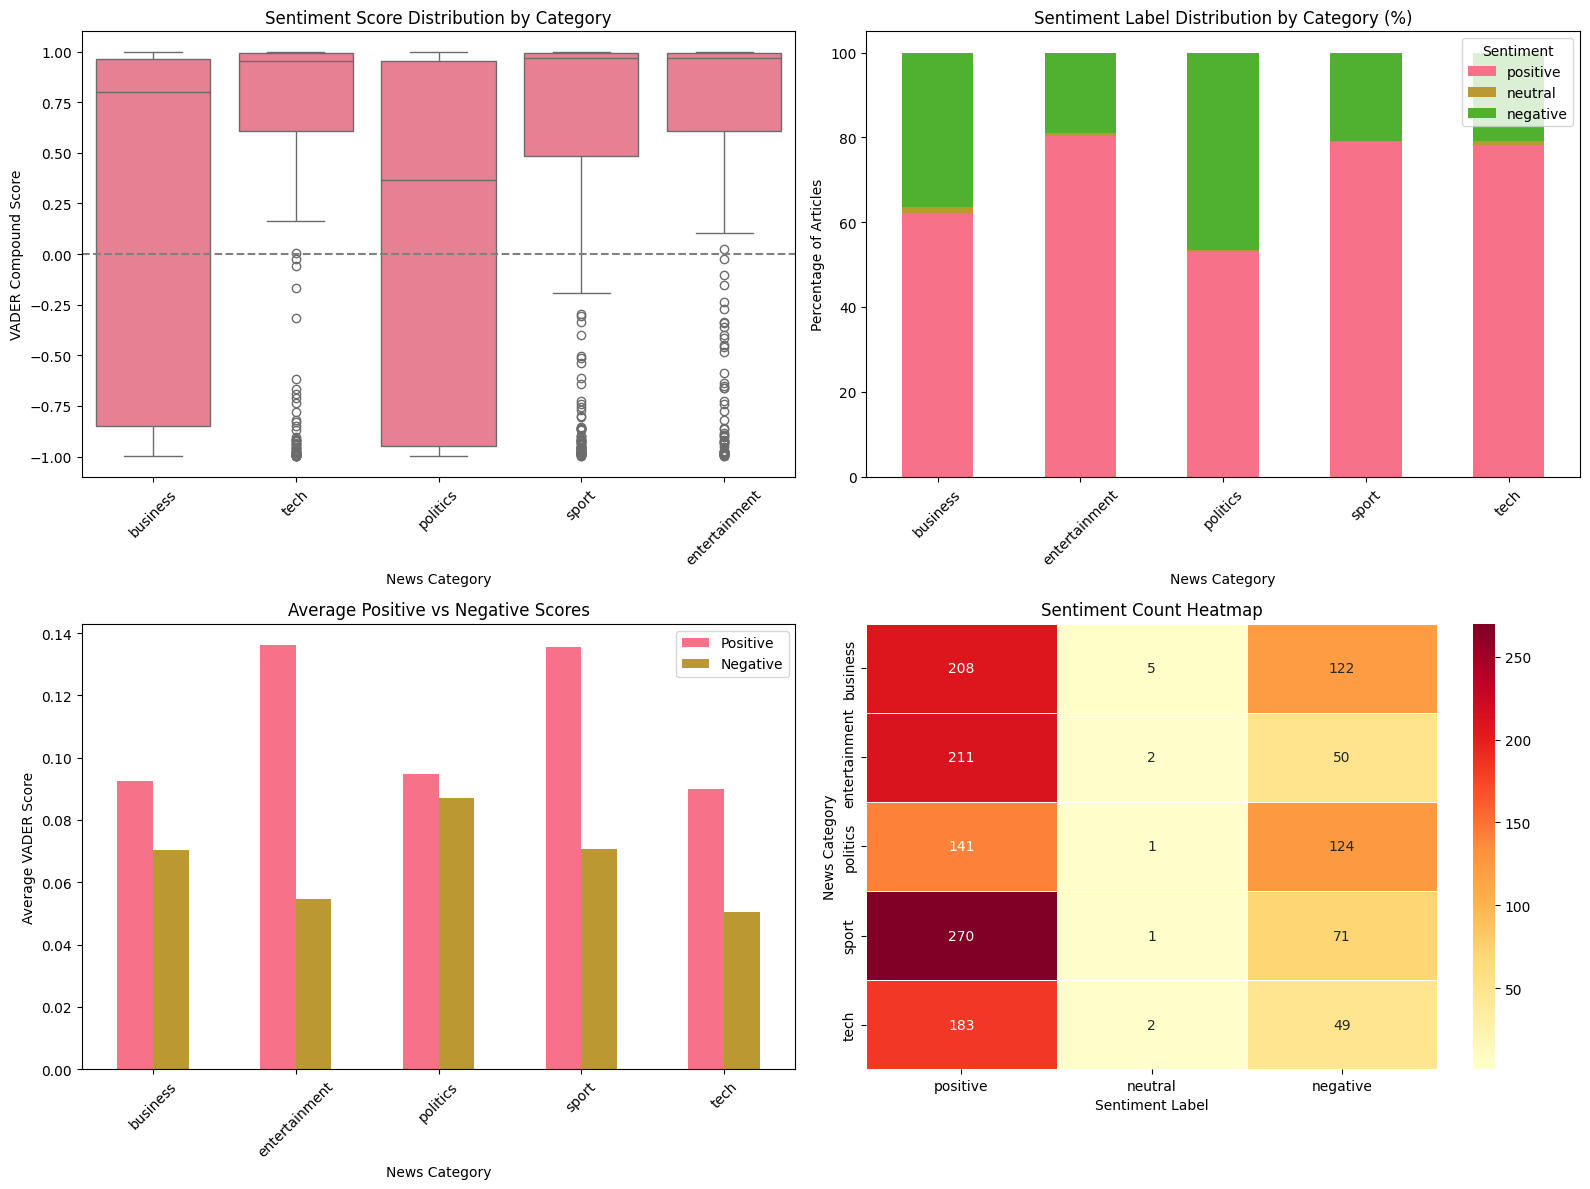


💡 Q1: WHICH CATEGORIES ARE MOST POSITIVE/NEGATIVE?


,Average Compound Score
category,
entertainment,0.5900
sport,0.5492
tech,0.5330
business,0.2381
politics,0.0541



Highest average sentiment: entertainment (0.5900)
Lowest average sentiment: politics (0.0541)
Highest positive article percentage: entertainment (80.23%)
Highest negative article percentage: politics (46.62%)

💡 Q2: TITLE VS CONTENT SENTIMENT


,Avg_Title_Sentiment,Avg_Content_Sentiment,Avg_Absolute_Difference,Label_Agreement
category,,,,
business,0.024,0.238,0.677,52.239
entertainment,0.173,0.590,0.649,57.414
politics,-0.073,0.054,0.723,50.752
sport,0.066,0.549,0.717,54.971
tech,0.079,0.533,0.711,50.855



Overall title/content sentiment agreement: 53.33%


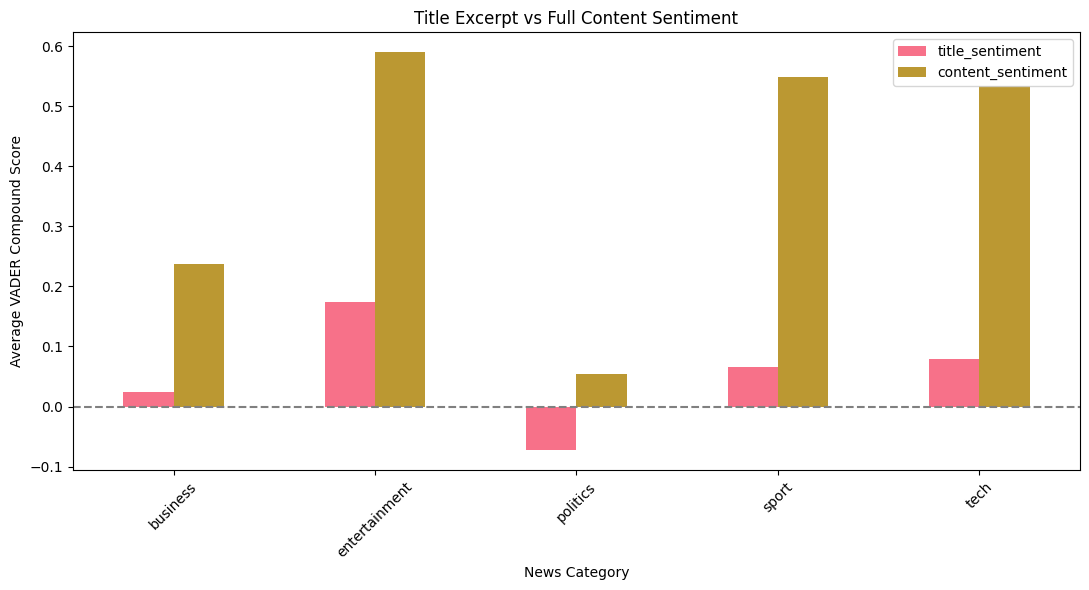


Note: This is an excerpt-versus-article comparison, not a real headline-versus-body study.

💡 Q3: SENTIMENT VARIATION WITHIN CATEGORIES


,mean,std,min,max,median,range
category,,,,,,
business,0.2381,0.8372,-0.9985,0.9995,0.8020,1.9980
entertainment,0.5900,0.6865,-0.9978,0.9999,0.9677,1.9977
politics,0.0541,0.8798,-0.9984,0.9999,0.3646,1.9983
sport,0.5492,0.7272,-0.9967,0.9996,0.9659,1.9963
tech,0.5330,0.7479,-0.9991,0.9993,0.9554,1.9984


Highest variation: politics (SD: 0.8798)
Lowest variation: entertainment (SD: 0.6865)


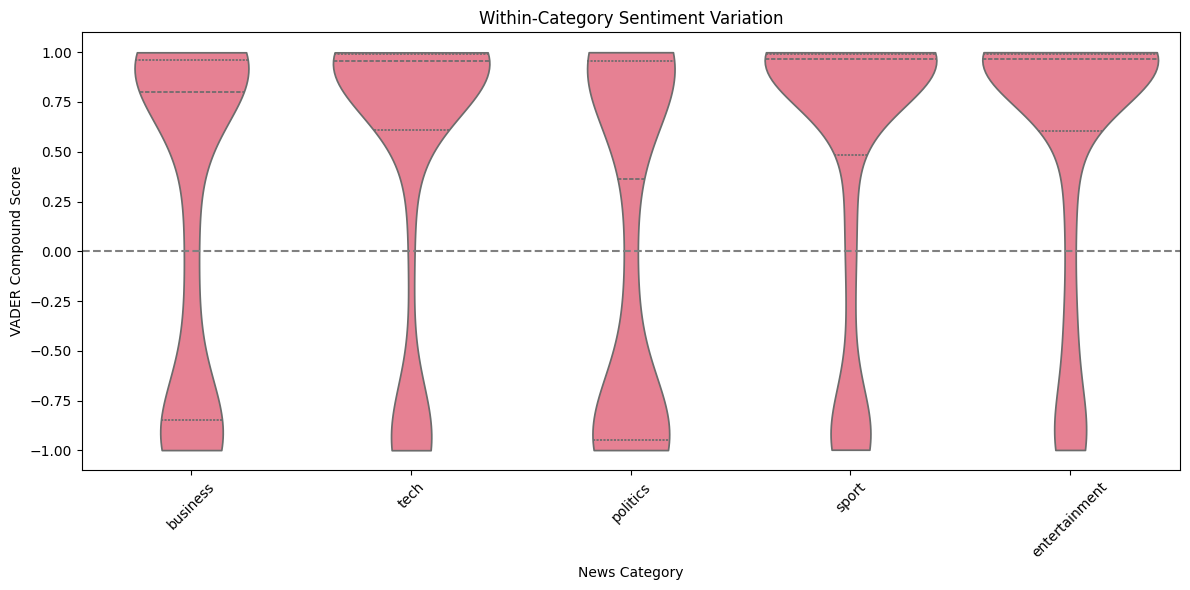


💡 Q4: SENTIMENT AS CLASSIFICATION FEATURES
Sentiment features: (1440, 4)
Category labels: (1440,)


,full_sentiment,pos_score,neu_score,neg_score
0,-0.9701,0.063,0.793,0.144
1,0.7623,0.117,0.786,0.096
2,-0.9318,0.083,0.809,0.108
3,0.9554,0.058,0.916,0.026
4,-0.9486,0.078,0.807,0.115


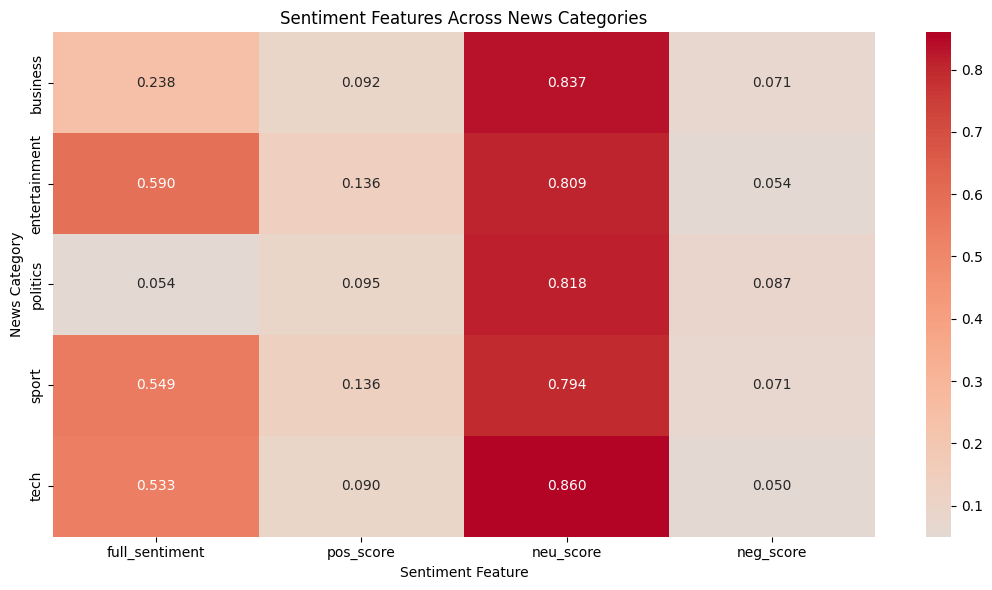


Sentiment features can be combined with TF-IDF. Their value must be tested against a TF-IDF-only baseline using training-only validation.

🎭 NRC EMOTION ANALYSIS BY CATEGORY

Average emotion association scores:


,anger,anticipation,disgust,fear,joy,sadness,surprise,trust
category,,,,,,,,
business,0.089,0.202,0.043,0.117,0.089,0.102,0.046,0.312
entertainment,0.064,0.172,0.048,0.077,0.190,0.094,0.104,0.252
politics,0.104,0.182,0.046,0.150,0.090,0.100,0.054,0.275
sport,0.084,0.208,0.043,0.092,0.136,0.102,0.077,0.258
tech,0.085,0.215,0.046,0.131,0.119,0.079,0.082,0.243



Dominant emotion by category:


,Category,Dominant Emotion,Dominant Score
0,business,trust,0.312
1,entertainment,trust,0.252
2,politics,trust,0.275
3,sport,trust,0.258
4,tech,trust,0.243


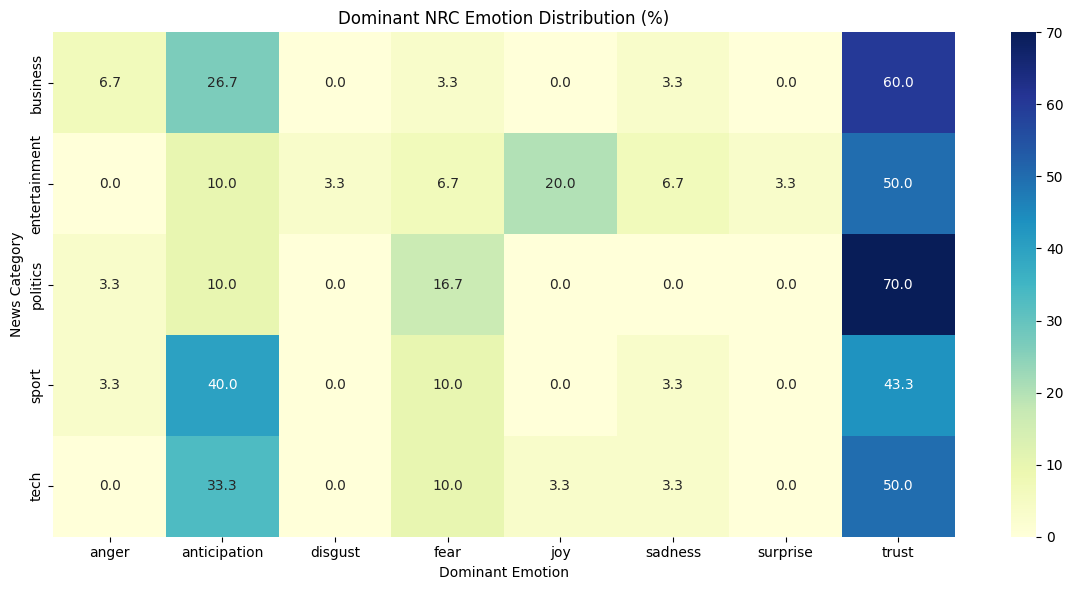


Interpretation: These are lexicon-based emotion associations, not verified emotional states or manually labeled emotions.

💼 BUSINESS INTELLIGENCE APPLICATIONS
1. Monitor sentiment differences across news topics.
2. Identify categories with unusually negative or positive language.
3. Compare emotional vocabulary patterns across news categories.
4. Evaluate whether sentiment features improve news classification.

Limitation: Sentiment and emotion lexicons do not measure factual accuracy or media bias.

✅ MODULE 6: SENTIMENT PATTERN ANALYSIS COMPLETE
Articles analyzed: 1440
Categories: 5

Highest average sentiment: entertainment
Lowest average sentiment: politics
Highest sentiment variation: politics
Title/content agreement: 53.33%
NRC emotion sample: 150 articles

Completed:
✓ Sentiment statistics by category
✓ Sentiment distribution visualizations
✓ Most positive and negative categories
✓ Title versus content comparison
✓ Within-category sentiment variation
✓ Sentiment feature analysi

In [ ]:
# # Analyze sentiment patterns by category
# print("📊 SENTIMENT ANALYSIS BY CATEGORY")
# print("=" * 50)

# # Calculate sentiment statistics by category
# sentiment_by_category = sentiment_df.groupby('category').agg({
#     'full_sentiment': ['mean', 'std', 'min', 'max'],
#     'pos_score': 'mean',
#     'neu_score': 'mean',
#     'neg_score': 'mean'
# }).round(4)

# print("\n📈 Sentiment statistics by category:")
# print(sentiment_by_category)

# # Sentiment distribution by category
# sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
# sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

# print("\n📊 Sentiment distribution (%) by category:")
# print(sentiment_dist_pct.round(2))

# # Create visualizations
# fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# # 1. Sentiment scores by category
# sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
# axes[0,0].set_title('Sentiment Score Distribution by Category')
# axes[0,0].tick_params(axis='x', rotation=45)

# # 2. Sentiment label distribution
# sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
# axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
# axes[0,1].tick_params(axis='x', rotation=45)
# axes[0,1].legend(title='Sentiment')

# # 3. Positive vs Negative scores
# category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
# category_means.plot(kind='bar', ax=axes[1,0])
# axes[1,0].set_title('Average Positive vs Negative Scores by Category')
# axes[1,0].tick_params(axis='x', rotation=45)
# axes[1,0].legend(['Positive', 'Negative'])

# # 4. Sentiment vs Category heatmap
# sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
#                                          columns='full_label', aggfunc='count', fill_value=0)
# sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
# axes[1,1].set_title('Sentiment Count Heatmap')

# plt.tight_layout()
# plt.show()

# # 💡 STUDENT TASK: Analyze sentiment patterns
# # - Which categories are most positive/negative?
# # - Are there differences between title and content sentiment?
# # - How does sentiment vary within categories?
# # - Can sentiment be used as a feature for classification?


# ============================================================
# MODULE 6: SENTIMENT AND EMOTION PATTERNS BY CATEGORY
# NewsBot Intelligence System - Midterm Project
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("📊 SENTIMENT AND EMOTION ANALYSIS BY CATEGORY")
print("=" * 60)

# ------------------------------------------------------------
# STEP 1: Calculate sentiment statistics by category
# ------------------------------------------------------------

sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 SENTIMENT STATISTICS BY CATEGORY")
display(sentiment_by_category)

# ------------------------------------------------------------
# STEP 2: Sentiment distribution by category
# ------------------------------------------------------------

sentiment_dist = pd.crosstab(
    sentiment_df['category'],
    sentiment_df['full_label']
)

sentiment_dist = sentiment_dist.reindex(
    columns=['positive', 'neutral', 'negative'],
    fill_value=0
)

sentiment_dist_pct = (
    sentiment_dist.div(
        sentiment_dist.sum(axis=1),
        axis=0
    ).fillna(0) * 100
)

print("\n📊 SENTIMENT DISTRIBUTION (%) BY CATEGORY")
display(sentiment_dist_pct.round(2))

# ------------------------------------------------------------
# STEP 3: Original four sentiment visualizations
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Sentiment score distribution
sns.boxplot(
    data=sentiment_df,
    x='category',
    y='full_sentiment',
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    'Sentiment Score Distribution by Category'
)
axes[0, 0].set_xlabel('News Category')
axes[0, 0].set_ylabel('VADER Compound Score')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].axhline(
    0, color='gray', linestyle='--'
)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(
    kind='bar',
    stacked=True,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    'Sentiment Label Distribution by Category (%)'
)
axes[0, 1].set_xlabel('News Category')
axes[0, 1].set_ylabel('Percentage of Articles')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].legend(title='Sentiment')

# 3. Positive vs negative scores
category_means = (
    sentiment_df.groupby('category')[
        ['pos_score', 'neg_score']
    ].mean()
)

category_means.plot(
    kind='bar',
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    'Average Positive vs Negative Scores'
)
axes[1, 0].set_xlabel('News Category')
axes[1, 0].set_ylabel('Average VADER Score')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend(['Positive', 'Negative'])

# 4. Sentiment count heatmap
sns.heatmap(
    sentiment_dist,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=axes[1, 1]
)

axes[1, 1].set_title('Sentiment Count Heatmap')
axes[1, 1].set_xlabel('Sentiment Label')
axes[1, 1].set_ylabel('News Category')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STUDENT TASK 1: Most positive and negative categories
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("💡 Q1: WHICH CATEGORIES ARE MOST POSITIVE/NEGATIVE?")
print("=" * 60)

average_compound = (
    sentiment_df.groupby('category')['full_sentiment']
    .mean()
    .sort_values(ascending=False)
)

display(
    average_compound.round(4).to_frame(
        'Average Compound Score'
    )
)

most_positive_category = average_compound.idxmax()
most_negative_category = average_compound.idxmin()

print(
    f"\nHighest average sentiment: "
    f"{most_positive_category} "
    f"({average_compound.max():.4f})"
)

print(
    f"Lowest average sentiment: "
    f"{most_negative_category} "
    f"({average_compound.min():.4f})"
)

highest_positive_pct = (
    sentiment_dist_pct['positive'].idxmax()
)

highest_negative_pct = (
    sentiment_dist_pct['negative'].idxmax()
)

print(
    f"Highest positive article percentage: "
    f"{highest_positive_pct} "
    f"({sentiment_dist_pct.loc[highest_positive_pct, 'positive']:.2f}%)"
)

print(
    f"Highest negative article percentage: "
    f"{highest_negative_pct} "
    f"({sentiment_dist_pct.loc[highest_negative_pct, 'negative']:.2f}%)"
)

# ------------------------------------------------------------
# STUDENT TASK 2: Title vs content sentiment
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("💡 Q2: TITLE VS CONTENT SENTIMENT")
print("=" * 60)

# BBC does not provide actual article headlines.
# The title column is a generated excerpt.

sentiment_df['title_content_difference'] = (
    sentiment_df['title_sentiment'] -
    sentiment_df['content_sentiment']
)

sentiment_df['absolute_sentiment_difference'] = (
    sentiment_df['title_content_difference'].abs()
)

sentiment_df['title_content_agreement'] = (
    sentiment_df['title_label'] ==
    sentiment_df['content_label']
)

title_content_summary = (
    sentiment_df.groupby('category')
    .agg(
        Avg_Title_Sentiment=(
            'title_sentiment', 'mean'
        ),
        Avg_Content_Sentiment=(
            'content_sentiment', 'mean'
        ),
        Avg_Absolute_Difference=(
            'absolute_sentiment_difference', 'mean'
        ),
        Label_Agreement=(
            'title_content_agreement', 'mean'
        )
    )
)

title_content_summary['Label_Agreement'] *= 100

display(title_content_summary.round(3))

overall_agreement = (
    sentiment_df['title_content_agreement'].mean()
    * 100
)

print(
    f"\nOverall title/content sentiment agreement: "
    f"{overall_agreement:.2f}%"
)

title_content_means = (
    sentiment_df.groupby('category')[
        ['title_sentiment', 'content_sentiment']
    ].mean()
)

title_content_means.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Title Excerpt vs Full Content Sentiment')
plt.xlabel('News Category')
plt.ylabel('Average VADER Compound Score')
plt.xticks(rotation=45)
plt.axhline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

print(
    "\nNote: This is an excerpt-versus-article "
    "comparison, not a real headline-versus-body study."
)

# ------------------------------------------------------------
# STUDENT TASK 3: Sentiment variation within categories
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("💡 Q3: SENTIMENT VARIATION WITHIN CATEGORIES")
print("=" * 60)

variation_summary = (
    sentiment_df.groupby('category')['full_sentiment']
    .agg(['mean', 'std', 'min', 'max', 'median'])
    .round(4)
)

variation_summary['range'] = (
    variation_summary['max'] -
    variation_summary['min']
)

display(variation_summary)

highest_variation = (
    variation_summary['std'].idxmax()
)

lowest_variation = (
    variation_summary['std'].idxmin()
)

print(
    f"Highest variation: {highest_variation} "
    f"(SD: {variation_summary.loc[highest_variation, 'std']:.4f})"
)

print(
    f"Lowest variation: {lowest_variation} "
    f"(SD: {variation_summary.loc[lowest_variation, 'std']:.4f})"
)

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=sentiment_df,
    x='category',
    y='full_sentiment',
    inner='quartile',
    cut=0
)

plt.title('Within-Category Sentiment Variation')
plt.xlabel('News Category')
plt.ylabel('VADER Compound Score')
plt.xticks(rotation=45)
plt.axhline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STUDENT TASK 4: Sentiment as classification features
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("💡 Q4: SENTIMENT AS CLASSIFICATION FEATURES")
print("=" * 60)

sentiment_feature_columns = [
    'full_sentiment',
    'pos_score',
    'neu_score',
    'neg_score'
]

X_sentiment = sentiment_df[
    sentiment_feature_columns
].copy()

y_sentiment = sentiment_df['category'].copy()

print(f"Sentiment features: {X_sentiment.shape}")
print(f"Category labels: {y_sentiment.shape}")

display(X_sentiment.head())

sentiment_feature_means = (
    sentiment_df.groupby('category')[
        sentiment_feature_columns
    ].mean()
)

plt.figure(figsize=(11, 6))

sns.heatmap(
    sentiment_feature_means,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0
)

plt.title('Sentiment Features Across News Categories')
plt.xlabel('Sentiment Feature')
plt.ylabel('News Category')
plt.tight_layout()
plt.show()

print(
    "\nSentiment features can be combined with TF-IDF. "
    "Their value must be tested against a TF-IDF-only "
    "baseline using training-only validation."
)

# ------------------------------------------------------------
# STEP 8: Compare NRC emotion analysis results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("🎭 NRC EMOTION ANALYSIS BY CATEGORY")
print("=" * 60)

if 'emotion_df' in globals() and not emotion_df.empty:

    emotion_by_category = (
        emotion_df.groupby('category')[EMOTION_LABELS]
        .mean()
    )

    print("\nAverage emotion association scores:")
    display(emotion_by_category.round(3))

    # Dominant emotion by category
    emotion_summary = pd.DataFrame({
        'Category': emotion_by_category.index,
        'Dominant Emotion': (
            emotion_by_category.idxmax(axis=1).values
        ),
        'Dominant Score': (
            emotion_by_category.max(axis=1).values
        )
    })

    print("\nDominant emotion by category:")
    display(emotion_summary.round(3))

    # Distribution of dominant emotion labels
    dominant_emotion_dist = pd.crosstab(
        emotion_df['category'],
        emotion_df['dominant_emotion'],
        normalize='index'
    ).mul(100)

    plt.figure(figsize=(12, 6))

    sns.heatmap(
        dominant_emotion_dist,
        annot=True,
        fmt='.1f',
        cmap='YlGnBu'
    )

    plt.title('Dominant NRC Emotion Distribution (%)')
    plt.xlabel('Dominant Emotion')
    plt.ylabel('News Category')
    plt.tight_layout()
    plt.show()

    print(
        "\nInterpretation: These are lexicon-based "
        "emotion associations, not verified emotional "
        "states or manually labeled emotions."
    )

else:
    print(
        "Emotion experiment results are unavailable. "
        "Run the sentiment and emotion analysis section first."
    )

# ------------------------------------------------------------
# STEP 9: Business intelligence interpretation
# ------------------------------------------------------------

print("\n💼 BUSINESS INTELLIGENCE APPLICATIONS")
print("=" * 60)

print(
    "1. Monitor sentiment differences across news topics."
)

print(
    "2. Identify categories with unusually negative "
    "or positive language."
)

print(
    "3. Compare emotional vocabulary patterns "
    "across news categories."
)

print(
    "4. Evaluate whether sentiment features improve "
    "news classification."
)

print(
    "\nLimitation: Sentiment and emotion lexicons "
    "do not measure factual accuracy or media bias."
)

# ------------------------------------------------------------
# STEP 10: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 6: SENTIMENT PATTERN ANALYSIS COMPLETE")
print("=" * 60)

print(f"Articles analyzed: {len(sentiment_df)}")
print(f"Categories: {sentiment_df['category'].nunique()}")

print(f"\nHighest average sentiment: {most_positive_category}")
print(f"Lowest average sentiment: {most_negative_category}")
print(f"Highest sentiment variation: {highest_variation}")
print(f"Title/content agreement: {overall_agreement:.2f}%")

if 'emotion_df' in globals():
    print(f"NRC emotion sample: {len(emotion_df)} articles")

print("\nCompleted:")
print("✓ Sentiment statistics by category")
print("✓ Sentiment distribution visualizations")
print("✓ Most positive and negative categories")
print("✓ Title versus content comparison")
print("✓ Within-category sentiment variation")
print("✓ Sentiment feature analysis")
print("✓ NRC emotion comparison")
print("✓ Business intelligence interpretation")

print("\nReady for Module 7: Multi-Class Classification")





## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# # Prepare features for classification
# print("🔧 Preparing features for classification...")

# # 💡 TIP: Combine multiple feature types for better performance
# # - TF-IDF features (most important)
# # - Sentiment features
# # - Text length features
# # - POS features (if available)

# # Create feature matrix
# X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# # Add sentiment features
# sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# # Add text length features
# length_features = np.array([
#     df['full_text'].str.len(),  # Character length
#     df['full_text'].str.split().str.len(),  # Word count
#     df['title'].str.len(),  # Title length
# ]).T

# # 🚀 YOUR CODE HERE: Combine all features
# X_combined = np.hstack([
#     X_tfidf,
#     sentiment_features,
#     length_features
# ])

# # Target variable
# y = df['category'].values

# print(f"✅ Feature matrix prepared!")
# print(f"📊 Feature matrix shape: {X_combined.shape}")
# print(f"🎯 Number of classes: {len(np.unique(y))}")
# print(f"📋 Classes: {np.unique(y)}")

# # Split data into train and test sets
# X_train, X_test, y_train, y_test = train_test_split(
#     X_combined, y, test_size=0.2, random_state=42, stratify=y
# )

# print(f"\n📈 Data split:")
# print(f"  Training set: {X_train.shape[0]} samples")
# print(f"  Test set: {X_test.shape[0]} samples")



# ============================================================
# MODULE 7: FEATURE PREPARATION
# NewsBot Intelligence System - Midterm Project
# ============================================================

import numpy as np
import pandas as pd

from scipy.sparse import hstack, vstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# STEP 1: Configuration
# ------------------------------------------------------------

print("🔧 Preparing features for classification...")
print("=" * 60)

RANDOM_STATE = 42
TEST_SIZE = 0.20

# ------------------------------------------------------------
# STEP 2: Validate input data
# ------------------------------------------------------------

required_columns = [
    'article_id',
    'category',
    'full_text',
    'full_text_processed',
    'title'
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing dataset columns: {missing_columns}"
    )

if df['article_id'].duplicated().any():
    raise ValueError("Duplicate article IDs found.")

if sentiment_df['article_id'].duplicated().any():
    raise ValueError("Duplicate sentiment article IDs.")

if pos_df['article_id'].duplicated().any():
    raise ValueError("Duplicate POS article IDs.")

print(f"Total articles: {len(df)}")
print(f"Categories: {df['category'].nunique()}")
print("✓ Input data validated")

# ------------------------------------------------------------
# STEP 3: Align sentiment features
# ------------------------------------------------------------

sentiment_columns = [
    'full_sentiment',
    'pos_score',
    'neu_score',
    'neg_score'
]

sentiment_aligned = df[['article_id']].merge(
    sentiment_df[
        ['article_id'] + sentiment_columns
    ],
    on='article_id',
    how='left',
    validate='one_to_one',
    sort=False
)

if sentiment_aligned[sentiment_columns].isna().any().any():
    raise ValueError(
        "Missing sentiment features. "
        "Check Module 6."
    )

sentiment_features = (
    sentiment_aligned[sentiment_columns]
    .to_numpy(dtype=float)
)

print("✓ Sentiment features aligned")

# ------------------------------------------------------------
# STEP 4: Prepare text length features
# ------------------------------------------------------------

length_feature_names = [
    'character_count',
    'word_count',
    'title_length'
]

length_features = pd.DataFrame({
    'character_count':
        df['full_text'].fillna('').str.len().to_numpy(),

    'word_count':
        df['full_text'].fillna('').str.split().str.len().to_numpy(),

    'title_length':
        df['title'].fillna('').str.len().to_numpy()
})

print("✓ Text length features prepared")

# ------------------------------------------------------------
# STEP 5: Align POS features
# ------------------------------------------------------------

pos_feature_names = [
    'GROUP_Noun',
    'GROUP_Verb',
    'GROUP_Adjective',
    'GROUP_Adverb',
    'GROUP_Number',
    'GROUP_Pronoun',
    'GROUP_Determiner',
    'GROUP_Preposition',
    'GROUP_Conjunction'
]

available_pos_features = [
    col for col in pos_feature_names
    if col in pos_df.columns
]

if available_pos_features:

    pos_aligned = df[['article_id']].merge(
        pos_df[
            ['article_id'] + available_pos_features
        ],
        on='article_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    if pos_aligned[available_pos_features].isna().any().any():
        raise ValueError(
            "Missing POS features. Check Module 4."
        )

    pos_features = (
        pos_aligned[available_pos_features]
        .to_numpy(dtype=float)
    )

else:
    pos_features = np.empty((len(df), 0))
    print("⚠️ No POS features available")

print(f"✓ POS features prepared: {len(available_pos_features)}")

# ------------------------------------------------------------
# STEP 6: Create unified feature DataFrame
# ------------------------------------------------------------

# Keep text and numerical features in one DataFrame.
# ColumnTransformer will transform them inside CV folds.

X = pd.DataFrame({
    'processed_text':
        df['full_text_processed']
        .fillna('')
        .astype(str)
        .to_numpy()
})

for col in sentiment_columns:
    X[col] = sentiment_aligned[col].to_numpy(dtype=float)

for col in length_feature_names:
    X[col] = length_features[col].to_numpy(dtype=float)

for col in available_pos_features:
    X[col] = pos_aligned[col].to_numpy(dtype=float)

numerical_feature_names = (
    sentiment_columns +
    length_feature_names +
    available_pos_features
)

# Target variable
y = df['category'].to_numpy()

if X.isna().any().any():
    raise ValueError("Missing feature values detected.")

print("\n📋 FEATURE SUMMARY")
print("=" * 60)

print(f"Feature DataFrame shape: {X.shape}")
print(f"Numerical features: {len(numerical_feature_names)}")
print(f"Classes: {np.unique(y)}")

# ------------------------------------------------------------
# STEP 7: Split data BEFORE fitting TF-IDF
# ------------------------------------------------------------

print("\n✂️ Creating stratified train/test split...")
print("=" * 60)

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train_raw = X.iloc[train_idx].copy()
X_test_raw = X.iloc[test_idx].copy()

y_train = y[train_idx]
y_test = y[test_idx]

print(f"Training articles: {len(y_train)}")
print(f"Testing articles: {len(y_test)}")

# ------------------------------------------------------------
# STEP 8: Define reusable TF-IDF configuration
# ------------------------------------------------------------

def make_tfidf():
    """
    Create a fresh TF-IDF vectorizer.

    A new instance is fitted independently
    inside each cross-validation fold.
    """

    return TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.8,
        sublinear_tf=True
    )

# ------------------------------------------------------------
# STEP 9: Define preprocessing pipeline
# ------------------------------------------------------------

def make_preprocessor(use_numeric=True):
    """
    Build a leakage-free feature transformer.

    TF-IDF:
        Fit vocabulary and IDF on training fold only.

    Numerical:
        Fit scaler on training fold only.

    Naive Bayes:
        Use TF-IDF only.

    Logistic Regression / SVM:
        Use TF-IDF + numerical features.
    """

    transformers = [
        (
            'tfidf',
            make_tfidf(),
            'processed_text'
        )
    ]

    if use_numeric and numerical_feature_names:

        transformers.append(
            (
                'numeric',
                StandardScaler(with_mean=False),
                numerical_feature_names
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        sparse_threshold=1.0
    )

# ------------------------------------------------------------
# STEP 10: Preview feature transformations
# ------------------------------------------------------------

print("\n🔢 Creating training feature preview...")
print("=" * 60)

# This preview is for inspection and compatibility.
# Model training creates fresh transformers inside each CV fold.

preview_preprocessor = make_preprocessor(
    use_numeric=True
)

X_train = preview_preprocessor.fit_transform(
    X_train_raw
)

X_test = preview_preprocessor.transform(
    X_test_raw
)

# Extract fitted components
tfidf_vectorizer = (
    preview_preprocessor.named_transformers_['tfidf']
)

numeric_scaler = (
    preview_preprocessor.named_transformers_['numeric']
)

feature_names = (
    tfidf_vectorizer.get_feature_names_out()
)

# TF-IDF-only matrices
X_train_tfidf = tfidf_vectorizer.transform(
    X_train_raw['processed_text']
)

X_test_tfidf = tfidf_vectorizer.transform(
    X_test_raw['processed_text']
)

# Keep original article order for descriptive analysis
combined_indices = np.concatenate([
    train_idx,
    test_idx
])

original_order = np.argsort(combined_indices)

X_combined = vstack([
    csr_matrix(X_train),
    csr_matrix(X_test)
], format='csr')[original_order]

X_tfidf = vstack([
    X_train_tfidf,
    X_test_tfidf
], format='csr')[original_order]

tfidf_matrix = X_tfidf

print(f"TF-IDF vocabulary size: {len(feature_names)}")
print(f"Training matrix: {X_train.shape}")
print(f"Testing matrix: {X_test.shape}")
print(f"Combined matrix: {X_combined.shape}")

# ------------------------------------------------------------
# STEP 11: Class distribution
# ------------------------------------------------------------

print("\n📊 TRAIN/TEST CLASS DISTRIBUTION")
print("=" * 60)

distribution_df = pd.DataFrame({
    'Training': pd.Series(y_train).value_counts(),
    'Testing': pd.Series(y_test).value_counts()
}).fillna(0).astype(int)

display(distribution_df)

# ------------------------------------------------------------
# STEP 12: Validate feature preparation
# ------------------------------------------------------------

print("\n🔍 FEATURE VALIDATION")
print("=" * 60)

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)

assert X_train.shape[1] == X_test.shape[1]
assert X_combined.shape[0] == len(df)

assert np.isfinite(
    csr_matrix(X_train).data
).all()

assert np.isfinite(
    csr_matrix(X_test).data
).all()

print("✓ Training/test labels aligned")
print("✓ Feature dimensions consistent")
print("✓ No invalid numerical values")
print("✓ Original article order restored")
print("✓ Preprocessing pipeline configured")

# ------------------------------------------------------------
# STEP 13: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 7: FEATURE PREPARATION COMPLETE")
print("=" * 60)

print(f"Total articles: {len(df)}")
print(f"Training: {len(y_train)}")
print(f"Testing: {len(y_test)}")

print(f"TF-IDF features: {len(feature_names)}")
print(f"Numerical features: {len(numerical_feature_names)}")
print(f"Total features: {X_train.shape[1]}")

print("\nCompleted:")
print("✓ Stratified train/test split")
print("✓ Sentiment feature alignment")
print("✓ POS feature alignment")
print("✓ Text length features")
print("✓ Reusable TF-IDF transformer")
print("✓ Reusable numerical scaler")
print("✓ Leakage-free pipeline configuration")
print("✓ Feature validation")

print("\nReady for Module 7: Model Training and Cross-Validation")



🔧 Preparing features for classification...
Total articles: 1440
Categories: 5
✓ Input data validated
✓ Sentiment features aligned
✓ Text length features prepared
✓ POS features prepared: 9

📋 FEATURE SUMMARY
Feature DataFrame shape: (1440, 17)
Numerical features: 16
Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

✂️ Creating stratified train/test split...
Training articles: 1152
Testing articles: 288

🔢 Creating training feature preview...
TF-IDF vocabulary size: 5000
Training matrix: (1152, 5016)
Testing matrix: (288, 5016)
Combined matrix: (1440, 5016)

📊 TRAIN/TEST CLASS DISTRIBUTION


,Training,Testing
business,268,67
entertainment,210,53
politics,213,53
sport,274,68
tech,187,47



🔍 FEATURE VALIDATION
✓ Training/test labels aligned
✓ Feature dimensions consistent
✓ No invalid numerical values
✓ Original article order restored
✓ Preprocessing pipeline configured

✅ MODULE 7: FEATURE PREPARATION COMPLETE
Total articles: 1440
Training: 1152
Testing: 288
TF-IDF features: 5000
Numerical features: 16
Total features: 5016

Completed:
✓ Stratified train/test split
✓ Sentiment feature alignment
✓ POS feature alignment
✓ Text length features
✓ Reusable TF-IDF transformer
✓ Reusable numerical scaler
✓ Leakage-free pipeline configuration
✓ Feature validation

Ready for Module 7: Model Training and Cross-Validation


🤖 TRAINING MULTIPLE CLASSIFIERS

Cross-validation configuration:
Folds: 5
Stratified: Yes
Shuffle: Yes
Primary metric: Macro F1

🔄 TRAINING NAIVE BAYES
------------------------------------------------------------

Cross-validation Macro F1 by fold:
[0.9679 0.9831 0.9731 0.9629 0.9636]
Mean CV Macro F1: 0.9701
CV Standard Deviation: 0.0074
Mean Training CV Macro F1: 0.9911

FINAL TEST RESULTS
Accuracy: 0.9444
Macro Precision: 0.9462
Macro Recall: 0.9366
Macro F1: 0.9403

Classification Report:
               precision    recall  f1-score   support

     business       0.92      0.99      0.95        67
entertainment       0.96      0.92      0.94        53
     politics       0.98      0.94      0.96        53
        sport       0.94      1.00      0.97        68
         tech       0.93      0.83      0.88        47

     accuracy                           0.94       288
    macro avg       0.95      0.94      0.94       288
 weighted avg       0.95      0.94      0.94       288


🔄 T

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,CV Mean,CV Std,CV Train F1
0,Naive Bayes,0.9444,0.9462,0.9366,0.9403,0.9701,0.0074,0.9911
1,SVM,0.9583,0.9584,0.9536,0.9557,0.9583,0.0246,0.9985
2,Logistic Regression,0.9271,0.9291,0.9201,0.9236,0.9099,0.0232,0.9798



MODEL COMPARISON METHODOLOGY
Naive Bayes: TF-IDF features only.
Logistic Regression: TF-IDF + scaled numerical features.
SVM: TF-IDF + scaled numerical features.

Models were evaluated using the same stratified training/test split.

🥇 SELECTED MODEL
Model: Naive Bayes
Cross-validation Macro F1: 0.9701
Test Accuracy: 0.9444
Test Macro F1: 0.9403

📈 CLASSIFIER PERFORMANCE VISUALIZATION


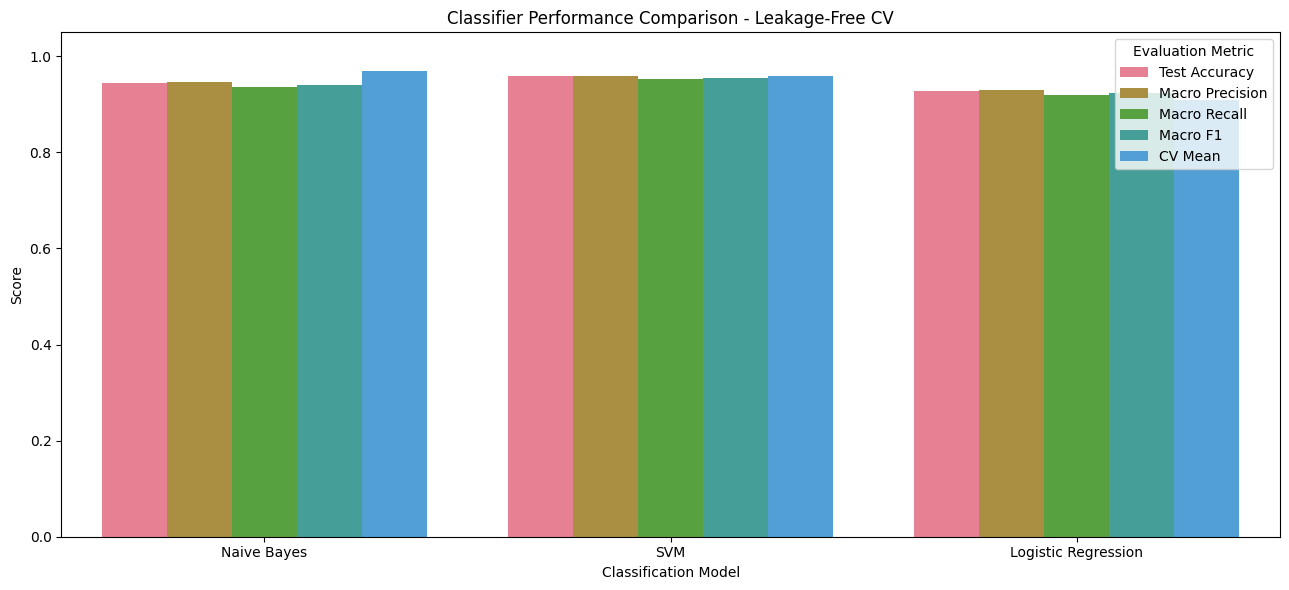


🔍 CONFUSION MATRIX ANALYSIS


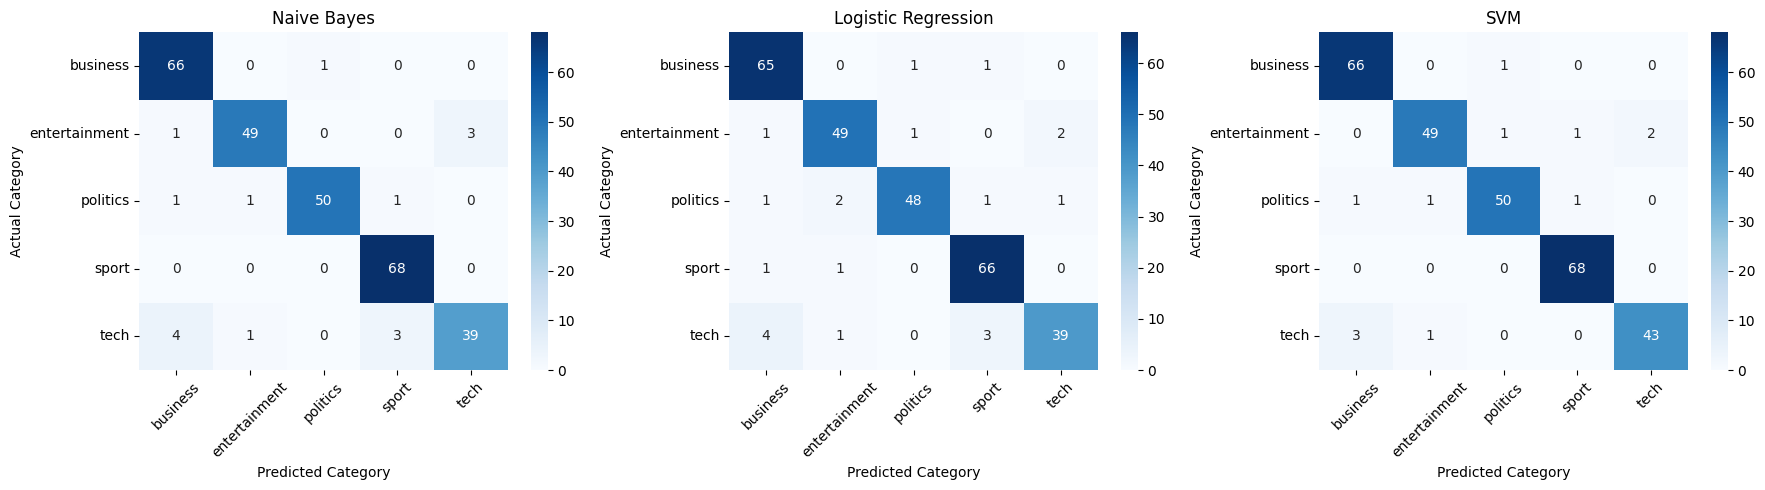


⚠️ CLASSIFICATION ERROR ANALYSIS
Selected model: Naive Bayes
Incorrect predictions: 16
Correct predictions: 272

Sample misclassified articles:


,Actual,Predicted,Article
0,tech,business,games maker fights for survival one of britain...
1,business,politics,world leaders gather to face uncertainty more ...
2,entertainment,business,uk world s biggest music buyer uk consumers ...
3,politics,entertainment,mp s shock at long lost daughter labour mp ste...
4,tech,sport,players sought for $1m prize uk gamers are get...
5,tech,business,us duo in first spam conviction a brother and ...
6,entertainment,tech,bbc should allow more scrutiny mps have urge...
7,politics,business,eu fraud clampdown urged eu member states are ...
8,entertainment,tech,help for indies in download sales a campaign h...
9,tech,business,argonaut founder rebuilds empire jez san the ...



📊 OVERFITTING CHECK


,Model,CV Train F1,CV Mean,Train-CV Gap
0,Naive Bayes,0.9911,0.9701,0.0210
1,SVM,0.9985,0.9583,0.0402
2,Logistic Regression,0.9798,0.9099,0.0699



A larger train-validation gap may indicate overfitting. Interpret it alongside test results.

🔍 PIPELINE VALIDATION
✓ All three classifiers trained
✓ Five-fold cross-validation completed
✓ TF-IDF fitted inside each CV fold
✓ Numerical scaling fitted inside each CV fold
✓ Held-out test data excluded from CV
✓ Best model selected using CV Macro F1

✅ MODULE 7: MODEL TRAINING COMPLETE
Models compared: 3
Training articles: 1152
Testing articles: 288

Selected model: Naive Bayes
CV Macro F1: 0.9701
Test Accuracy: 0.9444
Test Macro F1: 0.9403

Completed:
✓ Multinomial Naive Bayes
✓ Logistic Regression
✓ Support Vector Machine
✓ Leakage-free five-fold cross-validation
✓ Accuracy, precision, recall and macro F1
✓ Classification reports
✓ Confusion matrices
✓ Classification error analysis
✓ Overfitting comparison
✓ Cross-validation-based model selection

Ready for Module 7: Model Evaluation and Optimization


In [ ]:
# # Train and evaluate multiple classifiers
# print("🤖 Training multiple classifiers...")

# # Define classifiers to compare
# classifiers = {
#     'Naive Bayes': MultinomialNB(),
#     'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
#     'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
# }

# # 💡 TIP: For larger datasets, you might want to use SGDClassifier for efficiency
# # from sklearn.linear_model import SGDClassifier
# # classifiers['SGD'] = SGDClassifier(random_state=42)

# # Train and evaluate each classifier
# results = {}
# trained_models = {}

# for name, classifier in classifiers.items():
#     print(f"\n🔄 Training {name}...")

#     # 🚀 YOUR CODE HERE: Train and evaluate classifier
#     # Train the model
#     classifier.fit(X_train, y_train)

#     # Make predictions
#     y_pred = classifier.predict(X_test)
#     y_pred_proba = classifier.predict_proba(X_test) if hasattr(classifier, 'predict_proba') else None

#     # Calculate metrics
#     accuracy = accuracy_score(y_test, y_pred)

#     # Cross-validation score
#     cv_scores = cross_val_score(classifier, X_train, y_train, cv=3, scoring='accuracy')

#     # Store results
#     results[name] = {
#         'accuracy': accuracy,
#         'cv_mean': cv_scores.mean(),
#         'cv_std': cv_scores.std(),
#         'predictions': y_pred,
#         'probabilities': y_pred_proba
#     }

#     trained_models[name] = classifier

#     print(f"  ✅ Accuracy: {accuracy:.4f}")
#     print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# print("\n🏆 CLASSIFIER COMPARISON")
# print("=" * 50)
# comparison_df = pd.DataFrame({
#     'Model': list(results.keys()),
#     'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
#     'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
#     'CV Std': [results[name]['cv_std'] for name in results.keys()]
# })

# print(comparison_df.round(4))

# # Find best model
# best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
# print(f"\n🥇 Best performing model: {best_model_name}")



# ============================================================
# MODULE 7: MODEL TRAINING AND EVALUATION
# NewsBot Intelligence System - Midterm Project
# Leakage-Free Cross-Validation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# STEP 1: Initialize model comparison
# ------------------------------------------------------------

print("🤖 TRAINING MULTIPLE CLASSIFIERS")
print("=" * 60)

RANDOM_STATE = 42

# Define classifiers
classifiers = {
    'Naive Bayes': MultinomialNB(
        alpha=1.0
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=RANDOM_STATE
    ),

    'SVM': SVC(
        kernel='linear',
        probability=True,
        class_weight='balanced',
        random_state=RANDOM_STATE
    )
}

# ------------------------------------------------------------
# Model configuration and comparison methodology
# ------------------------------------------------------------

# Multinomial Naive Bayes uses nonnegative TF-IDF
# features because its input must be nonnegative.
#
# Logistic Regression and SVM use TF-IDF together
# with scaled sentiment, text-length, and POS features.
#
# These experiments compare complete model configurations.
# They do not isolate algorithm performance because
# the feature sets differ.

model_uses_numeric = {
    'Naive Bayes': False,
    'Logistic Regression': True,
    'SVM': True
}

# ------------------------------------------------------------
# STEP 2: Configure cross-validation
# ------------------------------------------------------------

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro'
}

print("\nCross-validation configuration:")
print("Folds: 5")
print("Stratified: Yes")
print("Shuffle: Yes")
print("Primary metric: Macro F1")

# ------------------------------------------------------------
# STEP 3: Train and evaluate classifiers
# ------------------------------------------------------------

results = {}
trained_models = {}
comparison_rows = []

for name, classifier in classifiers.items():

    print(f"\n🔄 TRAINING {name.upper()}")
    print("-" * 60)

    # Build a fresh pipeline for each classifier.
    # The feature transformer is fitted separately
    # inside every cross-validation fold.

    pipeline = Pipeline([
        (
            'features',
            make_preprocessor(
                use_numeric=model_uses_numeric[name]
            )
        ),
        (
            'classifier',
            clone(classifier)
        )
    ])

    # --------------------------------------------------------
    # Leakage-free cross-validation
    # --------------------------------------------------------

    cv_results = cross_validate(
        pipeline,
        X_train_raw,
        y_train,
        cv=cv_strategy,
        scoring=scoring,
        n_jobs=-1,
        error_score='raise',
        return_train_score=True
    )

    cv_accuracy = cv_results['test_accuracy']
    cv_f1 = cv_results['test_f1_macro']
    cv_precision = cv_results['test_precision_macro']
    cv_recall = cv_results['test_recall_macro']
    cv_train_f1 = cv_results['train_f1_macro']

    print("\nCross-validation Macro F1 by fold:")
    print(np.round(cv_f1, 4))

    print(
        f"Mean CV Macro F1: "
        f"{cv_f1.mean():.4f}"
    )

    print(
        f"CV Standard Deviation: "
        f"{cv_f1.std():.4f}"
    )

    print(
        f"Mean Training CV Macro F1: "
        f"{cv_train_f1.mean():.4f}"
    )

    # --------------------------------------------------------
    # Train final model on complete training split
    # --------------------------------------------------------

    pipeline.fit(
        X_train_raw,
        y_train
    )

    # Evaluate on held-out test data
    y_pred = pipeline.predict(
        X_test_raw
    )

    y_pred_proba = pipeline.predict_proba(
        X_test_raw
    )

    # --------------------------------------------------------
    # Calculate evaluation metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    results[name] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_macro': macro_f1,

        'cv_mean': cv_f1.mean(),
        'cv_std': cv_f1.std(),

        'cv_accuracy': cv_accuracy.mean(),
        'cv_precision': cv_precision.mean(),
        'cv_recall': cv_recall.mean(),
        'cv_train_f1': cv_train_f1.mean(),

        'cv_fold_scores': cv_f1,
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = pipeline

    comparison_rows.append({
        'Model': name,
        'Test Accuracy': accuracy,
        'Macro Precision': precision,
        'Macro Recall': recall,
        'Macro F1': macro_f1,
        'CV Mean': cv_f1.mean(),
        'CV Std': cv_f1.std(),
        'CV Train F1': cv_train_f1.mean()
    })

    print("\nFINAL TEST RESULTS")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall: {recall:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

# ------------------------------------------------------------
# STEP 4: Compare classifier performance
# ------------------------------------------------------------

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 60)

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df = comparison_df.sort_values(
    by='CV Mean',
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

print("\nMODEL COMPARISON METHODOLOGY")
print("=" * 60)

print(
    "Naive Bayes: TF-IDF features only."
)

print(
    "Logistic Regression: TF-IDF + scaled numerical features."
)

print(
    "SVM: TF-IDF + scaled numerical features."
)

print(
    "\nModels were evaluated using the same "
    "stratified training/test split."
)

# ------------------------------------------------------------
# STEP 5: Select best model
# ------------------------------------------------------------

# Select using training cross-validation,
# not held-out test accuracy.

best_model_name = comparison_df.iloc[0]['Model']

# This is a complete fitted sklearn Pipeline.
best_model = trained_models[best_model_name]

best_predictions = results[
    best_model_name
]['predictions']

print("\n🥇 SELECTED MODEL")
print("=" * 60)

print(f"Model: {best_model_name}")

print(
    f"Cross-validation Macro F1: "
    f"{results[best_model_name]['cv_mean']:.4f}"
)

print(
    f"Test Accuracy: "
    f"{results[best_model_name]['accuracy']:.4f}"
)

print(
    f"Test Macro F1: "
    f"{results[best_model_name]['f1_macro']:.4f}"
)

# ------------------------------------------------------------
# STEP 6: Visualize classifier comparison
# ------------------------------------------------------------

print("\n📈 CLASSIFIER PERFORMANCE VISUALIZATION")
print("=" * 60)

plot_df = comparison_df.melt(
    id_vars='Model',
    value_vars=[
        'Test Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1',
        'CV Mean'
    ],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_df,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title(
    'Classifier Performance Comparison - Leakage-Free CV'
)

plt.xlabel('Classification Model')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.legend(title='Evaluation Metric')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 7: Confusion matrices
# ------------------------------------------------------------

print("\n🔍 CONFUSION MATRIX ANALYSIS")
print("=" * 60)

class_labels = np.unique(y_test)

fig, axes = plt.subplots(
    1,
    len(classifiers),
    figsize=(6 * len(classifiers), 5)
)

axes = np.atleast_1d(axes)

for ax, (name, result) in zip(
    axes,
    results.items()
):

    cm = confusion_matrix(
        y_test,
        result['predictions'],
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Category')
    ax.set_ylabel('Actual Category')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 8: Analyze classification errors
# ------------------------------------------------------------

print("\n⚠️ CLASSIFICATION ERROR ANALYSIS")
print("=" * 60)

incorrect_mask = (
    best_predictions != y_test
)

error_count = int(
    incorrect_mask.sum()
)

print(f"Selected model: {best_model_name}")
print(f"Incorrect predictions: {error_count}")
print(f"Correct predictions: {len(y_test) - error_count}")

error_df = pd.DataFrame({
    'Actual': y_test[incorrect_mask],
    'Predicted': best_predictions[incorrect_mask],
    'Article': (
        df.iloc[test_idx[incorrect_mask]]
        ['full_text']
        .str.slice(0, 200)
        .to_numpy()
    )
})

print("\nSample misclassified articles:")
display(error_df.head(10))

# ------------------------------------------------------------
# STEP 9: Analyze training vs validation scores
# ------------------------------------------------------------

print("\n📊 OVERFITTING CHECK")
print("=" * 60)

overfitting_df = comparison_df[
    ['Model', 'CV Train F1', 'CV Mean']
].copy()

overfitting_df['Train-CV Gap'] = (
    overfitting_df['CV Train F1'] -
    overfitting_df['CV Mean']
)

display(overfitting_df.round(4))

print(
    "\nA larger train-validation gap may indicate "
    "overfitting. Interpret it alongside test results."
)

# ------------------------------------------------------------
# STEP 10: Final validation
# ------------------------------------------------------------

print("\n🔍 PIPELINE VALIDATION")
print("=" * 60)

assert len(trained_models) == 3
assert len(results) == 3
assert len(best_predictions) == len(y_test)

assert isinstance(
    best_model,
    Pipeline
)

assert 'features' in best_model.named_steps
assert 'classifier' in best_model.named_steps

print("✓ All three classifiers trained")
print("✓ Five-fold cross-validation completed")
print("✓ TF-IDF fitted inside each CV fold")
print("✓ Numerical scaling fitted inside each CV fold")
print("✓ Held-out test data excluded from CV")
print("✓ Best model selected using CV Macro F1")

# ------------------------------------------------------------
# STEP 11: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 7: MODEL TRAINING COMPLETE")
print("=" * 60)

print(f"Models compared: {len(trained_models)}")
print(f"Training articles: {len(y_train)}")
print(f"Testing articles: {len(y_test)}")

print(f"\nSelected model: {best_model_name}")

print(
    f"CV Macro F1: "
    f"{results[best_model_name]['cv_mean']:.4f}"
)

print(
    f"Test Accuracy: "
    f"{results[best_model_name]['accuracy']:.4f}"
)

print(
    f"Test Macro F1: "
    f"{results[best_model_name]['f1_macro']:.4f}"
)

print("\nCompleted:")
print("✓ Multinomial Naive Bayes")
print("✓ Logistic Regression")
print("✓ Support Vector Machine")
print("✓ Leakage-free five-fold cross-validation")
print("✓ Accuracy, precision, recall and macro F1")
print("✓ Classification reports")
print("✓ Confusion matrices")
print("✓ Classification error analysis")
print("✓ Overfitting comparison")
print("✓ Cross-validation-based model selection")

print("\nReady for Module 7: Model Evaluation and Optimization")




In [34]:

# ============================================================
# EXPORT MODEL COMPARISON RESULTS
# ============================================================

from pathlib import Path
import pandas as pd

output_dir = Path("/content")
output_path = output_dir / "model_comparison.csv"

# Export the existing model comparison results.
comparison_df.to_csv(output_path, index=False)

print("MODEL COMPARISON EXPORT")
print("=" * 60)
print(f"Saved to: {output_path}")
print(f"Models compared: {len(comparison_df)}")

display(comparison_df)

# Download for GitHub submission.
from google.colab import files
files.download(str(output_path))


MODEL COMPARISON EXPORT
Saved to: /content/model_comparison.csv
Models compared: 3


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,CV Mean,CV Std,CV Train F1
0,Naive Bayes,0.944444,0.946172,0.936557,0.940264,0.970123,0.007423,0.991112
1,SVM,0.958333,0.958433,0.953579,0.955696,0.958306,0.024615,0.998540
2,Logistic Regression,0.927083,0.929091,0.920143,0.923573,0.909858,0.023181,0.979754


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📊 DETAILED MODEL EVALUATION
Selected Model: Naive Bayes

Classification Report:
               precision    recall  f1-score   support

     business       0.92      0.99      0.95        67
entertainment       0.96      0.92      0.94        53
     politics       0.98      0.94      0.96        53
        sport       0.94      1.00      0.97        68
         tech       0.93      0.83      0.88        47

     accuracy                           0.94       288
    macro avg       0.95      0.94      0.94       288
 weighted avg       0.95      0.94      0.94       288



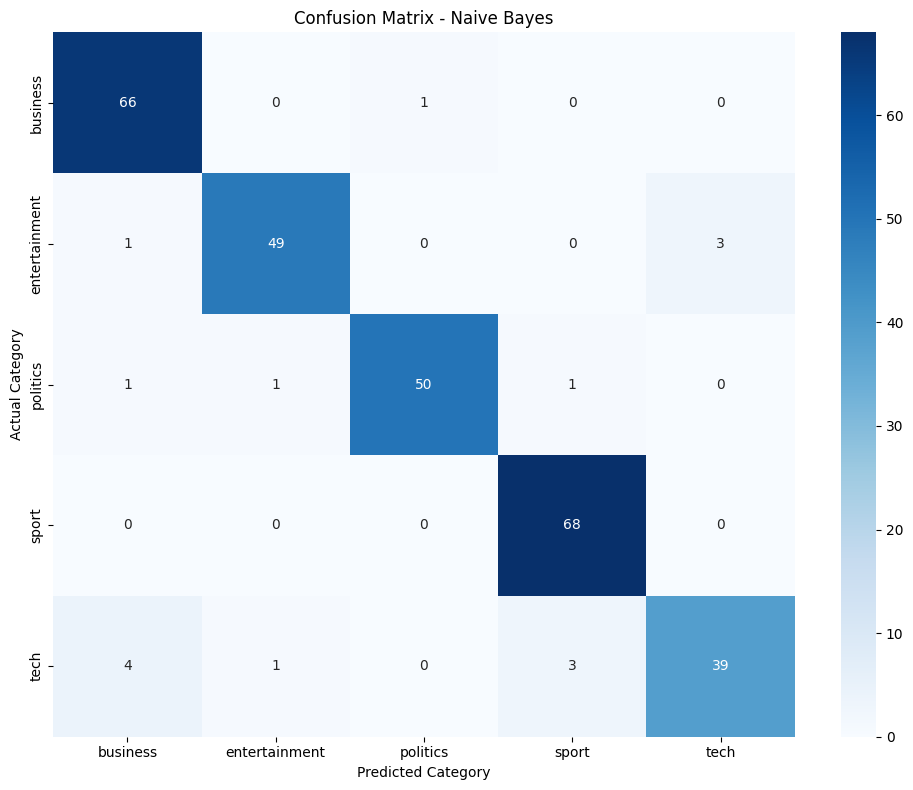

Test Accuracy: 0.9444
Test Macro F1: 0.9403

🔍 FEATURE IMPORTANCE
Selected classifier does not expose linear feature coefficients.

🧪 FEATURE COMBINATION EXPERIMENTS

Testing: TF-IDF Only
CV Macro F1: 0.9712

Testing: TF-IDF + Sentiment
CV Macro F1: 0.9533

Testing: TF-IDF + Sentiment + Length
CV Macro F1: 0.9433

Testing: TF-IDF + All Numerical
CV Macro F1: 0.9099


,Feature Set,CV Macro F1,CV Std
0,TF-IDF Only,0.9712,0.0098
1,TF-IDF + Sentiment,0.9533,0.0112
2,TF-IDF + Sentiment + Length,0.9433,0.0162
3,TF-IDF + All Numerical,0.9099,0.0232


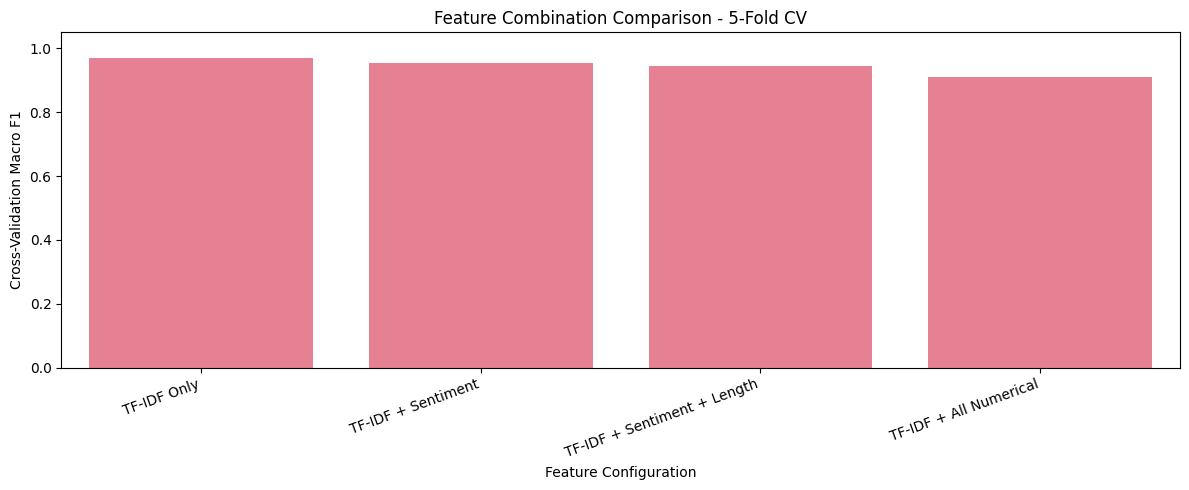


⚙️ HYPERPARAMETER TUNING

Best Parameters:
{'classifier__C': 10.0, 'classifier__class_weight': 'balanced', 'features__tfidf__max_features': 5000, 'features__tfidf__ngram_range': (1, 2)}
Best CV Macro F1: 0.9556
Tuned Test Accuracy: 0.9514
Tuned Test Macro F1: 0.9481


,param_features__tfidf__max_features,param_features__tfidf__ngram_range,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score
23,5000,"(1, 2)",10.0,balanced,0.9556,0.0223
21,3000,"(1, 2)",10.0,balanced,0.9548,0.0194
17,3000,"(1, 2)",10.0,None,0.9543,0.0228
19,5000,"(1, 2)",10.0,None,0.9538,0.0235
16,3000,"(1, 1)",10.0,None,0.9536,0.0219
22,5000,"(1, 1)",10.0,balanced,0.9529,0.0192
20,3000,"(1, 1)",10.0,balanced,0.9518,0.0210
18,5000,"(1, 1)",10.0,None,0.9504,0.0238
8,3000,"(1, 1)",1.0,None,0.9217,0.0178
9,3000,"(1, 2)",1.0,None,0.9213,0.0155



🧩 ADDITIONAL FEATURE ENGINEERING
Additional features:
✓ Average word length
✓ Lexical diversity
Extended CV Macro F1: 0.8978

⚖️ CLASS IMBALANCE ANALYSIS


,Count,Percentage
sport,274,23.78
business,268,23.26
politics,213,18.49
entertainment,210,18.23
tech,187,16.23


Largest/smallest class ratio: 1.47
Classes are reasonably balanced. Resampling is not necessary by default.


,Class Weight,CV Macro F1,CV Std
0,None,0.9098,0.0192
1,balanced,0.9099,0.0232



🏆 OPTIMIZATION SUMMARY


,Experiment,CV Macro F1,Test Macro F1
0,Selected Model - Cross-Validation,0.9701,0.9403
1,Tuned Logistic Regression,0.9556,0.9481
2,Logistic Regression + Extra Features,0.8978,NaN



Model selection should rely on training-only cross-validation, not repeated comparisons on the held-out test set.

✅ MODULE 7: MODEL EVALUATION COMPLETE
Selected Model: Naive Bayes
Selected Model CV Macro F1: 0.9701
Tuned Logistic Regression CV Macro F1: 0.9556

Completed student tasks:
✓ Detailed classification report
✓ Confusion matrix
✓ Pipeline-compatible feature importance
✓ Feature combination experiments
✓ Leakage-free hyperparameter tuning
✓ Additional text-style features
✓ Class imbalance analysis
✓ Class weighting comparison

Ready for Module 8: Named Entity Recognition


In [ ]:
# # Detailed evaluation of the best model
# best_model = trained_models[best_model_name]
# best_predictions = results[best_model_name]['predictions']

# print(f"📊 DETAILED EVALUATION: {best_model_name}")
# print("=" * 60)

# # Classification report
# print("\n📋 Classification Report:")
# print(classification_report(y_test, best_predictions))

# # Confusion matrix
# cm = confusion_matrix(y_test, best_predictions)
# plt.figure(figsize=(10, 8))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#             xticklabels=np.unique(y), yticklabels=np.unique(y))
# plt.title(f'Confusion Matrix - {best_model_name}')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.tight_layout()
# plt.show()

# # Feature importance (for Logistic Regression)
# if best_model_name == 'Logistic Regression':
#     print("\n🔍 Top Features by Category:")
#     feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
#                                                    'char_length', 'word_count', 'title_length']

#     classes = best_model.classes_
#     coefficients = best_model.coef_

#     for i, class_name in enumerate(classes):
#         top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
#         print(f"\n📰 {class_name}:")
#         for idx in reversed(top_indices):
#             if idx < len(feature_names_extended):
#                 print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# # 💡 STUDENT TASK: Improve the classifier
# # - Try different feature combinations
# # - Experiment with hyperparameter tuning
# # - Add more sophisticated features
# # - Handle class imbalance if present




# ============================================================
# MODULE 7: MODEL EVALUATION AND OPTIMIZATION
# NewsBot Intelligence System - Midterm Project
# Compatible with Cells 23 and 24
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# STEP 1: Detailed evaluation of selected model
# ------------------------------------------------------------

print("📊 DETAILED MODEL EVALUATION")
print("=" * 60)

best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"Selected Model: {best_model_name}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

class_labels = np.unique(y_test)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_labels
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.tight_layout()
plt.show()

print(
    f"Test Accuracy: "
    f"{accuracy_score(y_test, best_predictions):.4f}"
)

print(
    f"Test Macro F1: "
    f"{f1_score(y_test, best_predictions, average='macro'):.4f}"
)

# ------------------------------------------------------------
# STEP 2: Feature importance for linear models
# ------------------------------------------------------------

print("\n🔍 FEATURE IMPORTANCE")
print("=" * 60)

fitted_classifier = best_model.named_steps['classifier']
fitted_features = best_model.named_steps['features']

if hasattr(fitted_classifier, 'coef_'):

    feature_names_extended = (
        fitted_features.get_feature_names_out()
    )

    coefficients = fitted_classifier.coef_

    if coefficients.shape[1] == len(feature_names_extended):

        for i, class_name in enumerate(
            fitted_classifier.classes_
        ):

            top_indices = np.argsort(
                coefficients[i]
            )[-10:][::-1]

            print(f"\n📰 {class_name.upper()}")

            for idx in top_indices:
                print(
                    f"  {feature_names_extended[idx]}: "
                    f"{coefficients[i][idx]:.4f}"
                )

    else:
        print("Feature name count does not match coefficients.")

else:
    print(
        "Selected classifier does not expose "
        "linear feature coefficients."
    )

# ------------------------------------------------------------
# STEP 3: Feature combination experiments
# ------------------------------------------------------------

print("\n🧪 FEATURE COMBINATION EXPERIMENTS")
print("=" * 60)

# Use Logistic Regression for a controlled comparison.
# All preprocessing is fitted inside each CV fold.

feature_configurations = {
    'TF-IDF Only': [],

    'TF-IDF + Sentiment':
        sentiment_columns,

    'TF-IDF + Sentiment + Length':
        sentiment_columns + length_feature_names,

    'TF-IDF + All Numerical':
        numerical_feature_names
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

def build_feature_pipeline(numeric_columns):

    transformers = [
        (
            'tfidf',
            make_tfidf(),
            'processed_text'
        )
    ]

    if numeric_columns:
        transformers.append(
            (
                'numeric',
                StandardScaler(with_mean=False),
                numeric_columns
            )
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        sparse_threshold=1.0
    )

    return Pipeline([
        ('features', preprocessor),
        (
            'classifier',
            LogisticRegression(
                max_iter=2000,
                class_weight='balanced',
                random_state=RANDOM_STATE
            )
        )
    ])

feature_experiment_results = []

for name, numeric_columns in feature_configurations.items():

    print(f"\nTesting: {name}")

    model = build_feature_pipeline(
        numeric_columns
    )

    cv_scores = cross_validate(
        model,
        X_train_raw,
        y_train,
        cv=cv_strategy,
        scoring='f1_macro',
        n_jobs=-1,
        error_score='raise'
    )['test_score']

    feature_experiment_results.append({
        'Feature Set': name,
        'CV Macro F1': cv_scores.mean(),
        'CV Std': cv_scores.std()
    })

    print(f"CV Macro F1: {cv_scores.mean():.4f}")

feature_experiment_df = pd.DataFrame(
    feature_experiment_results
).sort_values(
    'CV Macro F1',
    ascending=False
).reset_index(drop=True)

display(feature_experiment_df.round(4))

plt.figure(figsize=(12, 5))

sns.barplot(
    data=feature_experiment_df,
    x='Feature Set',
    y='CV Macro F1'
)

plt.title('Feature Combination Comparison - 5-Fold CV')
plt.xlabel('Feature Configuration')
plt.ylabel('Cross-Validation Macro F1')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 4: Hyperparameter tuning
# ------------------------------------------------------------

print("\n⚙️ HYPERPARAMETER TUNING")
print("=" * 60)

# Tune both classifier regularization and TF-IDF settings.
# Every combination is evaluated using training-only CV.

tuning_pipeline = Pipeline([
    (
        'features',
        make_preprocessor(use_numeric=True)
    ),
    (
        'classifier',
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

parameter_grid = {
    'features__tfidf__max_features': [3000, 5000],
    'features__tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [0.1, 1.0, 10.0],
    'classifier__class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    error_score='raise'
)

grid_search.fit(
    X_train_raw,
    y_train
)

print("\nBest Parameters:")
print(grid_search.best_params_)

print(
    f"Best CV Macro F1: "
    f"{grid_search.best_score_:.4f}"
)

# Store tuned model separately.
# Preserve the model selected during cross-validation.
tuned_model = grid_search.best_estimator_

# Report held-out test performance once.
tuned_predictions = tuned_model.predict(
    X_test_raw
)

tuned_accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

tuned_f1 = f1_score(
    y_test,
    tuned_predictions,
    average='macro',
    zero_division=0
)

print(f"Tuned Test Accuracy: {tuned_accuracy:.4f}")
print(f"Tuned Test Macro F1: {tuned_f1:.4f}")

tuning_results_df = pd.DataFrame(
    grid_search.cv_results_
)[[
    'param_features__tfidf__max_features',
    'param_features__tfidf__ngram_range',
    'param_classifier__C',
    'param_classifier__class_weight',
    'mean_test_score',
    'std_test_score'
]]

display(
    tuning_results_df.sort_values(
        'mean_test_score',
        ascending=False
    ).head(10).round(4)
)

# ------------------------------------------------------------
# STEP 5: Additional text-style features
# ------------------------------------------------------------

print("\n🧩 ADDITIONAL FEATURE ENGINEERING")
print("=" * 60)

# Calculate simple text-style features without fitting
# vocabulary statistics on the full dataset.

def extract_extra_features(text):

    words = str(text).split()

    if not words:
        return 0.0, 0.0

    avg_word_length = np.mean([
        len(word) for word in words
    ])

    lexical_diversity = (
        len(set(word.lower() for word in words))
        / len(words)
    )

    return float(avg_word_length), float(lexical_diversity)

extra_values = [
    extract_extra_features(text)
    for text in df['full_text']
]

extra_df = pd.DataFrame(
    extra_values,
    columns=[
        'avg_word_length',
        'lexical_diversity'
    ]
)

X_extended = X.copy()

X_extended[
    ['avg_word_length', 'lexical_diversity']
] = extra_df.to_numpy()

X_train_extended_raw = X_extended.iloc[
    train_idx
].copy()

extra_numeric_columns = (
    numerical_feature_names +
    ['avg_word_length', 'lexical_diversity']
)

extended_model = build_feature_pipeline(
    extra_numeric_columns
)

extended_cv_scores = cross_validate(
    extended_model,
    X_train_extended_raw,
    y_train,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1,
    error_score='raise'
)['test_score']

extended_cv_f1 = extended_cv_scores.mean()

print("Additional features:")
print("✓ Average word length")
print("✓ Lexical diversity")

print(
    f"Extended CV Macro F1: "
    f"{extended_cv_f1:.4f}"
)

# ------------------------------------------------------------
# STEP 6: Class imbalance analysis
# ------------------------------------------------------------

print("\n⚖️ CLASS IMBALANCE ANALYSIS")
print("=" * 60)

class_distribution = (
    pd.Series(y_train)
    .value_counts()
)

class_percentages = (
    class_distribution / len(y_train) * 100
)

imbalance_df = pd.DataFrame({
    'Count': class_distribution,
    'Percentage': class_percentages
})

display(imbalance_df.round(2))

imbalance_ratio = (
    class_distribution.max()
    / class_distribution.min()
)

print(
    f"Largest/smallest class ratio: "
    f"{imbalance_ratio:.2f}"
)

if imbalance_ratio <= 1.5:
    print(
        "Classes are reasonably balanced. "
        "Resampling is not necessary by default."
    )
else:
    print(
        "Class imbalance is present. "
        "Compare weighting strategies."
    )

# Compare weighting using training CV only.
weight_results = []

for weight in [None, 'balanced']:

    weight_pipeline = Pipeline([
        (
            'features',
            make_preprocessor(use_numeric=True)
        ),
        (
            'classifier',
            LogisticRegression(
                max_iter=2000,
                class_weight=weight,
                random_state=RANDOM_STATE
            )
        )
    ])

    scores = cross_validate(
        weight_pipeline,
        X_train_raw,
        y_train,
        cv=cv_strategy,
        scoring='f1_macro',
        n_jobs=-1,
        error_score='raise'
    )['test_score']

    weight_results.append({
        'Class Weight': str(weight),
        'CV Macro F1': scores.mean(),
        'CV Std': scores.std()
    })

weight_comparison_df = pd.DataFrame(
    weight_results
)

display(weight_comparison_df.round(4))

# ------------------------------------------------------------
# STEP 7: Summarize optimization experiments
# ------------------------------------------------------------

print("\n🏆 OPTIMIZATION SUMMARY")
print("=" * 60)

optimization_summary = pd.DataFrame([
    {
        'Experiment': 'Selected Model - Cross-Validation',
        'CV Macro F1': results[best_model_name]['cv_mean'],
        'Test Macro F1': results[best_model_name]['f1_macro']
    },
    {
        'Experiment': 'Tuned Logistic Regression',
        'CV Macro F1': grid_search.best_score_,
        'Test Macro F1': tuned_f1
    },
    {
        'Experiment': 'Logistic Regression + Extra Features',
        'CV Macro F1': extended_cv_f1,
        'Test Macro F1': np.nan
    }
])

display(optimization_summary.round(4))

print(
    "\nModel selection should rely on training-only "
    "cross-validation, not repeated comparisons "
    "on the held-out test set."
)

# ------------------------------------------------------------
# STEP 8: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 7: MODEL EVALUATION COMPLETE")
print("=" * 60)

print(f"Selected Model: {best_model_name}")
print(
    f"Selected Model CV Macro F1: "
    f"{results[best_model_name]['cv_mean']:.4f}"
)

print(
    f"Tuned Logistic Regression CV Macro F1: "
    f"{grid_search.best_score_:.4f}"
)

print("\nCompleted student tasks:")
print("✓ Detailed classification report")
print("✓ Confusion matrix")
print("✓ Pipeline-compatible feature importance")
print("✓ Feature combination experiments")
print("✓ Leakage-free hyperparameter tuning")
print("✓ Additional text-style features")
print("✓ Class imbalance analysis")
print("✓ Class weighting comparison")

print("\nReady for Module 8: Named Entity Recognition")



## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [32]:

# ============================================================
# MODULE 8: NER REVIEW STORAGE CONFIGURATION
# ============================================================

from pathlib import Path
import shutil
import pandas as pd

# ------------------------------------------------------------
# 1. Configure local storage
# ------------------------------------------------------------

LOCAL_REVIEW_DIR = Path("/content")

LOCAL_REVIEW_PATH = (
    LOCAL_REVIEW_DIR / "newsbot_ner_manual_review.csv"
)

NER_REVIEW_PATH = LOCAL_REVIEW_PATH
NER_STORAGE_MODE = "Local Colab"

# ------------------------------------------------------------
# 2. Try Google Drive without blocking the notebook
# ------------------------------------------------------------

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:

    try:
        from google.colab import drive

        drive_path = Path("/content/drive")

        if not (
            drive_path / "MyDrive"
        ).is_dir():
            drive.mount(
                str(drive_path),
                timeout_ms=60000
            )

        drive_review_dir = (
            drive_path / "MyDrive" / "NewsBot_Midterm"
        )

        if not (
            drive_path / "MyDrive"
        ).is_dir():
            raise RuntimeError(
                "Google Drive is not accessible."
            )

        drive_review_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        drive_review_path = (
            drive_review_dir
            / "newsbot_ner_manual_review.csv"
        )

        # Preserve an existing Drive review.
        # Copy local progress only when Drive has no file.
        if (
            LOCAL_REVIEW_PATH.exists()
            and not drive_review_path.exists()
        ):
            shutil.copy2(
                LOCAL_REVIEW_PATH,
                drive_review_path
            )

        NER_REVIEW_PATH = drive_review_path
        NER_STORAGE_MODE = "Google Drive"

    except Exception as exc:

        print(
            "Google Drive unavailable:",
            str(exc)
        )

        print(
            "Continuing with local Colab storage."
        )

# ------------------------------------------------------------
# 3. Confirm storage configuration
# ------------------------------------------------------------

print("\nNER REVIEW STORAGE")
print("=" * 60)

print(f"Storage mode: {NER_STORAGE_MODE}")
print(f"Review path: {NER_REVIEW_PATH}")

if NER_REVIEW_PATH.exists():

    review = pd.read_csv(
        NER_REVIEW_PATH
    )

    span_reviewed = (
        review["correct_span"]
        .astype("string")
        .str.strip()
        .str.lower()
        .isin(["yes", "no"])
    )

    label_reviewed = (
        review["correct_label"]
        .astype("string")
        .str.strip()
        .str.lower()
        .isin(["yes", "no"])
    )

    completed = int(
        (span_reviewed & label_reviewed).sum()
    )

    print(
        f"Existing reviews: "
        f"{completed}/{len(review)}"
    )

else:

    print(
        "No review file found. "
        "NER extraction will create one."
    )

if NER_STORAGE_MODE == "Local Colab":
    print(
        "\nWARNING: Local files may disappear "
        "when the Colab runtime resets."
    )
else:
    print(
        "\nGoogle Drive persistence enabled."
    )



NER REVIEW STORAGE
Storage mode: Google Drive
Review path: /content/drive/MyDrive/NewsBot_Midterm/newsbot_ner_manual_review.csv
Existing reviews: 30/30

Google Drive persistence enabled.


In [ ]:
# def extract_entities(text):
#     """
#     Extract named entities using spaCy

#     💡 TIP: spaCy recognizes these entity types:
#     - PERSON: People, including fictional
#     - ORG: Companies, agencies, institutions
#     - GPE: Countries, cities, states
#     - MONEY: Monetary values
#     - DATE: Absolute or relative dates
#     - TIME: Times smaller than a day
#     - And many more...
#     """
#     if not text or pd.isna(text):
#         return []

#     # 🚀 YOUR CODE HERE: Implement entity extraction
#     doc = nlp(str(text))

#     entities = []
#     for ent in doc.ents:
#         entities.append({
#             'text': ent.text,
#             'label': ent.label_,
#             'start': ent.start_char,
#             'end': ent.end_char,
#             'description': spacy.explain(ent.label_)
#         })

#     return entities

# # Apply NER to all articles
# print("🔍 Extracting named entities...")

# all_entities = []
# article_entities = []

# for idx, row in df.iterrows():
#     entities = extract_entities(row['full_text'])

#     # Store entities for this article
#     article_entities.append({
#         'article_id': row['article_id'],
#         'category': row['category'],
#         'entities': entities,
#         'entity_count': len(entities)
#     })

#     # Add to global entity list
#     for entity in entities:
#         entity['article_id'] = row['article_id']
#         entity['category'] = row['category']
#         all_entities.append(entity)

# print(f"✅ Entity extraction complete!")
# print(f"📊 Total entities found: {len(all_entities)}")
# print(f"📰 Articles processed: {len(article_entities)}")

# # Convert to DataFrame for analysis
# entities_df = pd.DataFrame(all_entities)

# if not entities_df.empty:
#     print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
#     print("\n📝 Sample entities:")
#     print(entities_df[['text', 'label', 'category']].head(10))
# else:
#     print("⚠️ No entities found. This might happen with very short sample texts.")



# ============================================================
# MODULE 8: NAMED ENTITY RECOGNITION
# NewsBot Intelligence System - Midterm Project
# ============================================================

import pandas as pd
import numpy as np
import spacy
from pathlib import Path
from collections import Counter

print("🔍 NAMED ENTITY RECOGNITION")
print("=" * 60)

# ------------------------------------------------------------
# STEP 1: Initialize spaCy NER
# ------------------------------------------------------------

if 'nlp' not in globals() or 'ner' not in nlp.pipe_names:
    nlp = spacy.load("en_core_web_sm")

REQUIRED_ENTITY_TYPES = {
    'PERSON': 'People',
    'ORG': 'Organizations',
    'GPE': 'Countries, cities, states',
    'DATE': 'Dates',
    'MONEY': 'Monetary values'
}

print("spaCy pipeline:", nlp.pipe_names)

# ------------------------------------------------------------
# STEP 2: Define entity extraction function
# ------------------------------------------------------------

def extract_entities(text):
    """
    Extract named entities using spaCy.

    Returns entity text, type, character offsets,
    and entity type description.
    """

    if not isinstance(text, str) or not text.strip():
        return []

    doc = nlp(text)

    return [
        {
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': (
                spacy.explain(ent.label_) or ent.label_
            )
        }
        for ent in doc.ents
    ]

# ------------------------------------------------------------
# STEP 3: Test NER on sample text
# ------------------------------------------------------------

sample_text = (
    "Apple CEO Tim Cook announced in London on "
    "October 15, 2024 that the company invested "
    "$2 billion in artificial intelligence."
)

print("\n🧪 NER SAMPLE TEST")

for entity in extract_entities(sample_text):
    print(
        f"{entity['text']} -> {entity['label']}"
    )

# ------------------------------------------------------------
# STEP 4: Extract entities from all articles
# ------------------------------------------------------------

print("\n🔍 EXTRACTING ENTITIES FROM NEWS ARTICLES")

all_entities = []
article_entities = []

texts = df['full_text'].fillna('').astype(str).tolist()

disabled_components = [
    component
    for component in [
        'tagger', 'parser', 'attribute_ruler', 'lemmatizer'
    ]
    if component in nlp.pipe_names
]

docs = nlp.pipe(
    texts,
    batch_size=16,
    disable=disabled_components
)

for (_, row), doc in zip(df.iterrows(), docs):

    entities = []

    for ent in doc.ents:

        entity = {
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': (
                spacy.explain(ent.label_) or ent.label_
            )
        }

        entities.append(entity)

        all_entities.append({
            **entity,
            'article_id': row['article_id'],
            'category': row['category']
        })

    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

# ------------------------------------------------------------
# STEP 5: Create DataFrames
# ------------------------------------------------------------

entity_columns = [
    'text', 'label', 'start', 'end',
    'description', 'article_id', 'category'
]

entities_df = pd.DataFrame(
    all_entities,
    columns=entity_columns
)

article_entities_df = pd.DataFrame(article_entities)

print("\n✅ Entity extraction complete!")
print(f"Articles processed: {len(article_entities_df)}")
print(f"Total entity mentions: {len(entities_df)}")

print("\nSample entities:")
display(entities_df.head(10))

# ------------------------------------------------------------
# STEP 6: Entity type distribution
# ------------------------------------------------------------

print("\n📊 ENTITY TYPE DISTRIBUTION")

entity_type_counts = entities_df['label'].value_counts()

display(entity_type_counts.to_frame('Mentions'))

print("\nRequired entity type coverage:")

for label, description in REQUIRED_ENTITY_TYPES.items():

    count = int(entity_type_counts.get(label, 0))

    print(
        f"{label}: {count} mentions - {description}"
    )

# ------------------------------------------------------------
# STEP 7: Entity counts by category
# ------------------------------------------------------------

print("\n📰 ENTITY COUNTS BY CATEGORY")

category_entity_summary = (
    article_entities_df.groupby('category')
    .agg(
        Articles=('article_id', 'count'),
        Total_Entities=('entity_count', 'sum'),
        Avg_Entities_Per_Article=('entity_count', 'mean')
    )
    .round(2)
)

display(category_entity_summary)

# ------------------------------------------------------------
# STEP 8: Most frequent entities
# ------------------------------------------------------------

entities_df['normalized_text'] = (
    entities_df['text']
    .astype(str)
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

print("\n🏆 TOP 20 ENTITIES")

top_entities = (
    entities_df[
        entities_df['normalized_text'].str.len() > 1
    ]
    .groupby(['normalized_text', 'label'])
    .size()
    .sort_values(ascending=False)
    .head(20)
)

display(top_entities.to_frame('Mentions'))

# ------------------------------------------------------------
# STEP 9: Validate NER output
# ------------------------------------------------------------

print("\n🔍 NER VALIDATION")

assert len(article_entities_df) == len(df)

assert (
    article_entities_df['article_id'].tolist()
    == df['article_id'].tolist()
)

assert (
    article_entities_df['entity_count'].sum()
    == len(entities_df)
)

article_lookup = dict(
    zip(df['article_id'], df['full_text'])
)

invalid_offsets = 0

for entity in all_entities:

    text = article_lookup[entity['article_id']]

    if text[entity['start']:entity['end']] != entity['text']:
        invalid_offsets += 1

print(f"Invalid character offsets: {invalid_offsets}")

assert invalid_offsets == 0

print("✓ Article alignment verified")
print("✓ Entity counts verified")
print("✓ Character offsets verified")

# ------------------------------------------------------------
# STEP 10: Prepare manual NER review sample
# ------------------------------------------------------------

print("\n🧪 MANUAL NER QUALITY REVIEW")
print("=" * 60)

# Sample six predictions from each of five required
# entity types, producing up to 30 review items.

REVIEW_PER_TYPE = 6
RANDOM_STATE = 42

review_parts = []

for label in REQUIRED_ENTITY_TYPES:

    candidates = entities_df[
        entities_df['label'] == label
    ]

    if not candidates.empty:

        sample = candidates.sample(
            n=min(REVIEW_PER_TYPE, len(candidates)),
            random_state=RANDOM_STATE
        )

        review_parts.append(sample)

if review_parts:

    ner_review_df = pd.concat(
        review_parts,
        ignore_index=True
    )

else:
    ner_review_df = pd.DataFrame(
        columns=entity_columns
    )

# ------------------------------------------------------------
# STEP 11: Add article context
# ------------------------------------------------------------

def get_entity_context(row, window=100):
    """
    Return original text surrounding the entity,
    highlighting the predicted entity span.
    """

    text = str(
        article_lookup[row['article_id']]
    )

    start = int(row['start'])
    end = int(row['end'])

    left = max(0, start - window)
    right = min(len(text), end + window)

    return (
        text[left:start]
        + " ["
        + text[start:end]
        + "] "
        + text[end:right]
    )

if not ner_review_df.empty:

    ner_review_df['context'] = (
        ner_review_df.apply(
            get_entity_context,
            axis=1
        )
    )

else:
    ner_review_df['context'] = pd.Series(dtype=str)

# ------------------------------------------------------------
# STEP 12: Add manual annotation columns
# ------------------------------------------------------------

ner_review_df['correct_span'] = pd.NA
ner_review_df['correct_label'] = pd.NA
ner_review_df['reviewer_label'] = pd.NA
ner_review_df['error_type'] = pd.NA
ner_review_df['notes'] = pd.NA

ner_review_df = ner_review_df[
    [
        'article_id',
        'category',
        'text',
        'label',
        'start',
        'end',
        'context',
        'correct_span',
        'correct_label',
        'reviewer_label',
        'error_type',
        'notes'
    ]
]

print(f"Predictions selected: {len(ner_review_df)}")

print("\nReview sample:")
display(ner_review_df)

# ------------------------------------------------------------
# STEP 13: Save manual review file
# ------------------------------------------------------------

# review_path = Path("/content/newsbot_ner_manual_review.csv")
review_path = NER_REVIEW_PATH

if review_path.exists():
    print("Existing NER review file found.")
    print("Preserving annotations and review progress.")

    existing_review = pd.read_csv(review_path)

    # Verify that the existing review matches the
    # current reproducible sample.
    review_keys = [
        "article_id", "start", "end", "label"
    ]

    expected_keys = set(
        map(tuple, ner_review_df[review_keys].to_numpy())
    )

    existing_keys = set(
        map(tuple, existing_review[review_keys].to_numpy())
    )

    if expected_keys != existing_keys:
        raise ValueError(
            "Existing NER annotations refer to a different "
            "sample. Preserve the file and investigate "
            "before generating a new review."
        )

    print("Existing review sample matches current predictions.")

else:
    ner_review_df.to_csv(review_path, index=False)
    print(f"Created NER review file: {review_path}")

print("Manual annotations are preserved across reruns.")

print("\nMANUAL REVIEW INSTRUCTIONS")
print("1. Open the CSV file.")
print("2. Read the context of each entity.")
print("3. Mark correct_span as yes or no.")
print("4. Mark correct_label as yes or no.")
print("5. Enter reviewer_label if the label is wrong.")
print("6. Record error_type and notes.")
print("7. Save the annotated CSV.")
print("8. Run the manual NER validation section.")

# ------------------------------------------------------------
# STEP 14: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("✅ MODULE 8: NER EXTRACTION COMPLETE")
print("=" * 60)

print(f"Articles analyzed: {len(article_entities_df)}")
print(f"Entity mentions: {len(entities_df)}")
print(f"Entity types: {entities_df['label'].nunique()}")
print(f"Manual review items: {len(ner_review_df)}")

print("\nCompleted:")
print("✓ Named entity extraction")
print("✓ PERSON, ORG, GPE, DATE, MONEY checks")
print("✓ Entity frequency analysis")
print("✓ Cross-category entity counts")
print("✓ Entity offset validation")
print("✓ Reproducible manual review sample")
print("✓ CSV prepared for manual annotation")

print("\nNext: Manual NER Validation and Error Analysis")



🔍 NAMED ENTITY RECOGNITION
spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']

🧪 NER SAMPLE TEST
Apple -> ORG
Tim Cook -> PERSON
London -> GPE
October 15, 2024 -> DATE
$2 billion -> MONEY

🔍 EXTRACTING ENTITIES FROM NEWS ARTICLES

✅ Entity extraction complete!
Articles processed: 1440
Total entity mentions: 40803

Sample entities:


,text,label,start,end,description,article_id,category
0,first,ORDINAL,168,173,"""first"", ""second"", etc.",1833,business
1,cynthia cooper,PERSON,184,198,"People, including fictional",1833,business
2,us,GPE,302,304,"Countries, cities, states",1833,business
3,2002,DATE,323,327,Absolute or relative dates or periods,1833,business
4,5.7bn,MONEY,412,417,"Monetary values, including unit",1833,business
5,new york,GPE,779,787,"Countries, cities, states",1833,business
6,wednesday,DATE,791,800,Absolute or relative dates or periods,1833,business
7,arthur andersen,PERSON,824,839,"People, including fictional",1833,business
8,early 2001 and,DATE,878,892,Absolute or relative dates or periods,1833,business
9,2002,DATE,893,897,Absolute or relative dates or periods,1833,business



📊 ENTITY TYPE DISTRIBUTION


,Mentions
label,
DATE,8523
PERSON,7803
CARDINAL,5965
GPE,5433
ORG,4288
NORP,2665
MONEY,1710
ORDINAL,1609
PERCENT,1242



Required entity type coverage:
PERSON: 7803 mentions - People
ORG: 4288 mentions - Organizations
GPE: 5433 mentions - Countries, cities, states
DATE: 8523 mentions - Dates
MONEY: 1710 mentions - Monetary values

📰 ENTITY COUNTS BY CATEGORY


...


🏆 TOP 20 ENTITIES


,,Mentions
normalized_text,label,
first,ORDINAL,739
one,CARDINAL,639
two,CARDINAL,584
us,GPE,547
uk,GPE,524
british,NORP,326
second,ORDINAL,316
three,CARDINAL,313
britain,GPE,277



🔍 NER VALIDATION
Invalid character offsets: 0
✓ Article alignment verified
✓ Entity counts verified
✓ Character offsets verified

🧪 MANUAL NER QUALITY REVIEW
Predictions selected: 30

Review sample:


,article_id,category,text,label,start,end,context,correct_span,correct_label,reviewer_label,error_type,notes
0,339,business,tony blair,PERSON,283,293,. some 2 000 business and political leaders f...,<NA>,<NA>,<NA>,<NA>,<NA>
1,217,entertainment,william hill,PERSON,44,56,actor scott is new bond favourite bookmaker [...,<NA>,<NA>,<NA>,<NA>,<NA>
2,2043,sport,lisa raymond 7-5 6-3,PERSON,491,511,njury. in the only main draw men s or women s ...,<NA>,<NA>,<NA>,<NA>,<NA>
3,153,politics,alan s,PERSON,790,796,must be bad for public confidence in the syst...,<NA>,<NA>,<NA>,<NA>,<NA>
4,1610,sport,john mccall,PERSON,3804,3815,dney is another thing. on the down side irish...,<NA>,<NA>,<NA>,<NA>,<NA>
5,413,politics,margaret thatcher,PERSON,363,380,mr blair wins the next election and fulfils hi...,<NA>,<NA>,<NA>,<NA>,<NA>
6,1088,business,the bank of england,ORG,2576,2595,he added. the further rise in us rates is unl...,<NA>,<NA>,<NA>,<NA>,<NA>
7,410,business,ulrich,ORG,984,990,u member states. of course we applaud humanit...,<NA>,<NA>,<NA>,<NA>,<NA>
8,528,business,reuters news,ORG,1249,1261,agreed in a court in the spanish capital madr...,<NA>,<NA>,<NA>,<NA>,<NA>
9,2012,business,fiat,ORG,104,108,mulls ferrari market listing ferrari could be...,<NA>,<NA>,<NA>,<NA>,<NA>


Existing NER review file found.
Preserving annotations and review progress.
Existing review sample matches current predictions.
Manual annotations are preserved across reruns.

MANUAL REVIEW INSTRUCTIONS
1. Open the CSV file.
2. Read the context of each entity.
3. Mark correct_span as yes or no.
4. Mark correct_label as yes or no.
5. Enter reviewer_label if the label is wrong.
6. Record error_type and notes.
7. Save the annotated CSV.
8. Run the manual NER validation section.

✅ MODULE 8: NER EXTRACTION COMPLETE
Articles analyzed: 1440
Entity mentions: 40803
Entity types: 18
Manual review items: 30

Completed:
✓ Named entity extraction
✓ PERSON, ORG, GPE, DATE, MONEY checks
✓ Entity frequency analysis
✓ Cross-category entity counts
✓ Entity offset validation
✓ Reproducible manual review sample
✓ CSV prepared for manual annotation

Next: Manual NER Validation and Error Analysis


In [ ]:

# ============================================================
# MODULE 8: INTERACTIVE MANUAL NER REVIEW
# ============================================================

from pathlib import Path
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# review_path = Path("/content/newsbot_ner_manual_review.csv")
review_path = NER_REVIEW_PATH

if not review_path.exists():
    raise FileNotFoundError(
        "NER review CSV not found. "
        "Run the NER extraction section first."
    )

review = pd.read_csv(review_path)

required_columns = [
    "article_id", "text", "label", "context",
    "correct_span", "correct_label",
    "reviewer_label", "error_type", "notes"
]

missing = [
    col for col in required_columns
    if col not in review.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

review = review.reset_index(drop=True)

for col in [
    "correct_span", "correct_label",
    "reviewer_label", "error_type", "notes"
]:
    review[col] = review[col].astype("string")

TOTAL = len(review)

if TOTAL == 0:
    raise ValueError("No NER predictions to review.")

print("MANUAL NER REVIEW")
print("=" * 60)
print(f"Predictions: {TOTAL}")
print("Review each prediction using its article context.")
print("Changes are saved directly to the existing CSV.")

# ------------------------------------------------------------
# 1. Review controls
# ------------------------------------------------------------

position = 0

header = widgets.HTML()
context_view = widgets.HTML()

span_dropdown = widgets.Dropdown(
    options=[
        ("Not reviewed", ""),
        ("Yes", "yes"),
        ("No", "no")
    ],
    description="Span:",
    style={"description_width": "100px"}
)

label_dropdown = widgets.Dropdown(
    options=[
        ("Not reviewed", ""),
        ("Yes", "yes"),
        ("No", "no")
    ],
    description="Label:",
    style={"description_width": "100px"}
)

corrected_label = widgets.Dropdown(
    options=[
        ("Not applicable", ""),
        ("PERSON", "PERSON"),
        ("ORG", "ORG"),
        ("GPE", "GPE"),
        ("DATE", "DATE"),
        ("MONEY", "MONEY"),
        ("NORP", "NORP"),
        ("LOC", "LOC"),
        ("FAC", "FAC"),
        ("PRODUCT", "PRODUCT"),
        ("EVENT", "EVENT"),
        ("WORK_OF_ART", "WORK_OF_ART"),
        ("LAW", "LAW"),
        ("LANGUAGE", "LANGUAGE"),
        ("TIME", "TIME"),
        ("PERCENT", "PERCENT"),
        ("QUANTITY", "QUANTITY"),
        ("ORDINAL", "ORDINAL"),
        ("CARDINAL", "CARDINAL")
    ],
    description="Correct type:",
    style={"description_width": "100px"}
)

error_dropdown = widgets.Dropdown(
    options=[
        ("None", ""),
        ("Wrong label", "wrong_label"),
        ("Wrong boundary", "wrong_boundary"),
        ("Not an entity", "not_entity"),
        ("Other", "other")
    ],
    description="Error:",
    style={"description_width": "100px"}
)

notes_input = widgets.Textarea(
    description="Notes:",
    placeholder="Explain errors when applicable",
    layout=widgets.Layout(width="95%", height="65px"),
    style={"description_width": "100px"}
)

previous_button = widgets.Button(
    description="Previous",
    icon="arrow-left"
)

save_button = widgets.Button(
    description="Save Review",
    button_style="success",
    icon="save"
)

next_button = widgets.Button(
    description="Next",
    icon="arrow-right"
)

status_output = widgets.Output()

# ------------------------------------------------------------
# 2. Display selected prediction
# ------------------------------------------------------------

def clean_value(value):
    if pd.isna(value):
        return ""
    return str(value).strip()


def update_view():
    row = review.iloc[position]

    completed = (
        review["correct_span"]
        .str.lower()
        .isin(["yes", "no"])
        &
        review["correct_label"]
        .str.lower()
        .isin(["yes", "no"])
    ).sum()

    header.value = (
        f"<h3>Prediction {position + 1} of {TOTAL}</h3>"
        f"<p><b>Reviewed:</b> {completed}/{TOTAL}</p>"
        f"<p><b>Entity:</b> {row['text']}</p>"
        f"<p><b>Predicted type:</b> {row['label']}</p>"
    )

    import html
    context_view.value = (
        "<div style='padding:12px;border:1px solid #aaa;"
        "border-radius:6px;white-space:pre-wrap;'>"
        + html.escape(clean_value(row["context"]))
        + "</div>"
    )

    span_value = clean_value(
        row["correct_span"]
    ).lower()

    label_value = clean_value(
        row["correct_label"]
    ).lower()

    span_dropdown.value = (
        span_value if span_value in ["yes", "no"] else ""
    )

    label_dropdown.value = (
        label_value if label_value in ["yes", "no"] else ""
    )

    saved_label = clean_value(row["reviewer_label"])
    valid_labels = [
        value for _, value in corrected_label.options
    ]

    corrected_label.value = (
        saved_label if saved_label in valid_labels else ""
    )

    saved_error = clean_value(row["error_type"])
    valid_errors = [
        value for _, value in error_dropdown.options
    ]

    error_dropdown.value = (
        saved_error if saved_error in valid_errors else ""
    )

    notes_input.value = clean_value(row["notes"])

    previous_button.disabled = position == 0
    next_button.disabled = position == TOTAL - 1


# ------------------------------------------------------------
# 3. Save reviewed prediction
# ------------------------------------------------------------

def save_review(_):
    global position

    if (
        span_dropdown.value not in ["yes", "no"]
        or label_dropdown.value not in ["yes", "no"]
    ):
        with status_output:
            clear_output(wait=True)
            print("Select yes or no for both fields.")
        return

    if (
        label_dropdown.value == "no"
        and not corrected_label.value
        and error_dropdown.value != "not_entity"
    ):
        with status_output:
            clear_output(wait=True)
            print(
                "Enter the correct entity type, "
                "or mark the prediction as not_entity."
            )
        return

    # Save manual annotations
    review.loc[position, "correct_span"] = (
        span_dropdown.value
    )

    review.loc[position, "correct_label"] = (
        label_dropdown.value
    )

    review.loc[position, "reviewer_label"] = (
        corrected_label.value or pd.NA
    )

    review.loc[position, "error_type"] = (
        error_dropdown.value or pd.NA
    )

    review.loc[position, "notes"] = (
        notes_input.value.strip() or pd.NA
    )

    # Persist the review to the configured storage path
    review.to_csv(review_path, index=False)

    saved_number = position + 1

    # Automatically advance to the next prediction
    if position < TOTAL - 1:
        position += 1

    update_view()

    with status_output:
        clear_output(wait=True)
        print(f"Saved prediction {saved_number}/{TOTAL}.")



# ------------------------------------------------------------
# 4. Navigation
# ------------------------------------------------------------

def go_previous(_):
    global position
    if position > 0:
        position -= 1
        update_view()
        with status_output:
            clear_output()


def go_next(_):
    global position
    if position < TOTAL - 1:
        position += 1
        update_view()
        with status_output:
            clear_output()


save_button.on_click(save_review)
previous_button.on_click(go_previous)
next_button.on_click(go_next)

# ------------------------------------------------------------
# 5. Display interactive review
# ------------------------------------------------------------

display(
    widgets.VBox([
        header,
        context_view,
        span_dropdown,
        label_dropdown,
        corrected_label,
        error_dropdown,
        notes_input,
        widgets.HBox([
            previous_button,
            save_button,
            next_button
        ]),
        status_output
    ])
)

update_view()


MANUAL NER REVIEW
Predictions: 30
Review each prediction using its article context.
Changes are saved directly to the existing CSV.


In [33]:

# ============================================================
# MODULE 8: MANUAL NER VALIDATION
# ============================================================

import os
import pandas as pd

# review_path = "/content/newsbot_ner_manual_review.csv"
review_path = str(NER_REVIEW_PATH)

required_columns = [
    "article_id", "category", "text", "label",
    "start", "end", "context",
    "correct_span", "correct_label",
    "reviewer_label", "error_type", "notes"
]

# ------------------------------------------------------------
# 1. Load the existing review sample
# ------------------------------------------------------------

if not os.path.exists(review_path):
    raise FileNotFoundError(
        "NER review CSV not found in Google Drive. "
        "Run the NER extraction section first."
    )


manual_review_df = pd.read_csv(review_path)

missing_columns = [
    col for col in required_columns
    if col not in manual_review_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing review columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 2. Validate the review sample
# ------------------------------------------------------------

review_keys = [
    "article_id", "start", "end", "label"
]

if manual_review_df.duplicated(
    subset=review_keys
).any():
    raise ValueError(
        "Duplicate entity predictions found in review."
    )

if len(manual_review_df) > 30:
    raise ValueError(
        "Expected no more than 30 review predictions."
    )

# Normalize human annotations without modifying
# the original CSV file.
for col in ["correct_span", "correct_label"]:
    manual_review_df[col] = (
        manual_review_df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

valid_answers = {"yes", "no"}

completed_review_df = manual_review_df[
    manual_review_df["correct_span"].isin(valid_answers)
    & manual_review_df["correct_label"].isin(valid_answers)
].copy()

# ------------------------------------------------------------
# 3. Display review progress
# ------------------------------------------------------------

print("MANUAL NER VALIDATION")
print("=" * 60)

print(f"Predictions selected: {len(manual_review_df)}")
print(f"Predictions reviewed: {len(completed_review_df)}")
print(
    f"Remaining: "
    f"{len(manual_review_df) - len(completed_review_df)}"
)

review_progress = (
    manual_review_df.groupby("label")
    .size()
    .rename("Sampled Predictions")
    .to_frame()
)

display(review_progress)

if len(completed_review_df) < len(manual_review_df):
    pending = manual_review_df.loc[
        ~manual_review_df.index.isin(
            completed_review_df.index
        )
    ]

    print("\nPREDICTIONS AWAITING REVIEW")
    display(
        pending[
            ["text", "label", "context",
             "correct_span", "correct_label"]
        ]
    )

    print(
        "\nComplete the annotations in the CSV, "
        "save it, and rerun this section."
    )

else:
    print("\nAll sampled predictions have been reviewed.")

# ------------------------------------------------------------
# 4. Validate annotation values
# ------------------------------------------------------------

for col in ["correct_span", "correct_label"]:
    values = manual_review_df[col].dropna().unique()

    invalid = [
        value for value in values
        if value not in valid_answers
    ]

    if invalid:
        raise ValueError(
            f"Invalid values in {col}: {invalid}. "
            "Use yes or no."
        )

print("\nReview data validated.")
print(f"Annotation file: {review_path}")


MANUAL NER VALIDATION
Predictions selected: 30
Predictions reviewed: 30
Remaining: 0


,Sampled Predictions
label,
DATE,6
GPE,6
MONEY,6
ORG,6
PERSON,6



All sampled predictions have been reviewed.

Review data validated.
Annotation file: /content/drive/MyDrive/NewsBot_Midterm/newsbot_ner_manual_review.csv


ADVANCED NAMED ENTITY ANALYSIS

ENTITY TYPE DISTRIBUTION


,Mentions
label,
DATE,8523
PERSON,7803
CARDINAL,5965
GPE,5433
ORG,4288
NORP,2665
MONEY,1710
ORDINAL,1609
PERCENT,1242



ENTITY TYPES BY CATEGORY


label,CARDINAL,DATE,EVENT,FAC,GPE,LANGUAGE,LAW,LOC,MONEY,NORP,ORDINAL,ORG,PERCENT,PERSON,PRODUCT,QUANTITY,TIME,WORK_OF_ART
category,,,,,,,,,,,,,,,,,,
business,1031,2398,3,10,1543,1,15,166,906,640,178,1392,812,974,22,42,53,1
entertainment,1068,1672,11,15,773,9,4,63,343,420,326,632,43,1793,8,20,122,0
politics,804,1322,22,23,933,10,4,120,222,702,213,584,125,1885,3,12,81,1
sport,1780,1966,5,39,1482,11,5,33,43,637,657,673,18,2505,23,65,239,1
tech,1282,1165,1,1,702,19,5,107,196,266,235,1007,244,646,26,52,87,5



MOST FREQUENT ENTITIES


,,Mentions
normalized_text,label,
first,ORDINAL,739
one,CARDINAL,639
two,CARDINAL,584
us,GPE,547
uk,GPE,524
british,NORP,326
second,ORDINAL,316
three,CARDINAL,313
britain,GPE,277


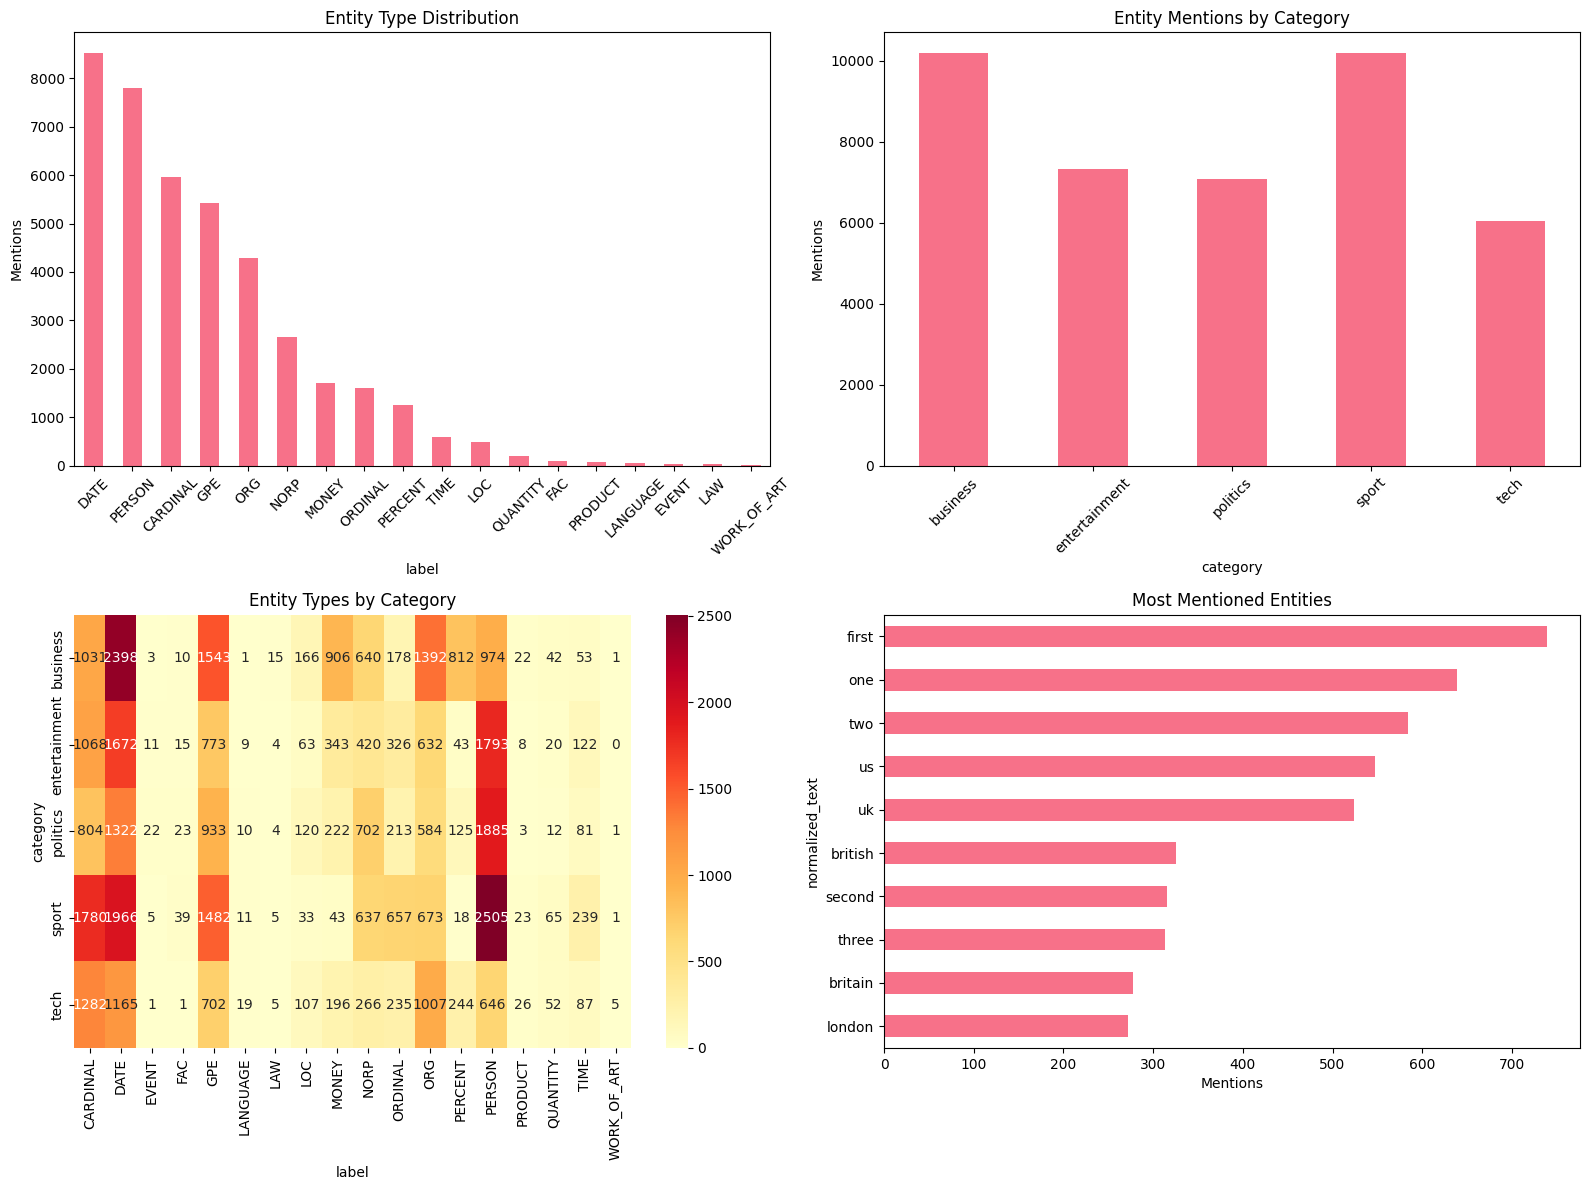


ENTITY DISTRIBUTION BY CATEGORY (%)


label,CARDINAL,DATE,EVENT,FAC,GPE,LANGUAGE,LAW,LOC,MONEY,NORP,ORDINAL,ORG,PERCENT,PERSON,PRODUCT,QUANTITY,TIME,WORK_OF_ART
category,,,,,,,,,,,,,,,,,,
business,10.12,23.54,0.03,0.10,15.15,0.01,0.15,1.63,8.89,6.28,1.75,13.66,7.97,9.56,0.22,0.41,0.52,0.01
entertainment,14.59,22.84,0.15,0.20,10.56,0.12,0.05,0.86,4.68,5.74,4.45,8.63,0.59,24.49,0.11,0.27,1.67,0.00
politics,11.38,18.71,0.31,0.33,13.20,0.14,0.06,1.70,3.14,9.93,3.01,8.26,1.77,26.68,0.04,0.17,1.15,0.01
sport,17.48,19.31,0.05,0.38,14.56,0.11,0.05,0.32,0.42,6.26,6.45,6.61,0.18,24.60,0.23,0.64,2.35,0.01
tech,21.20,19.27,0.02,0.02,11.61,0.31,0.08,1.77,3.24,4.40,3.89,16.66,4.04,10.68,0.43,0.86,1.44,0.08


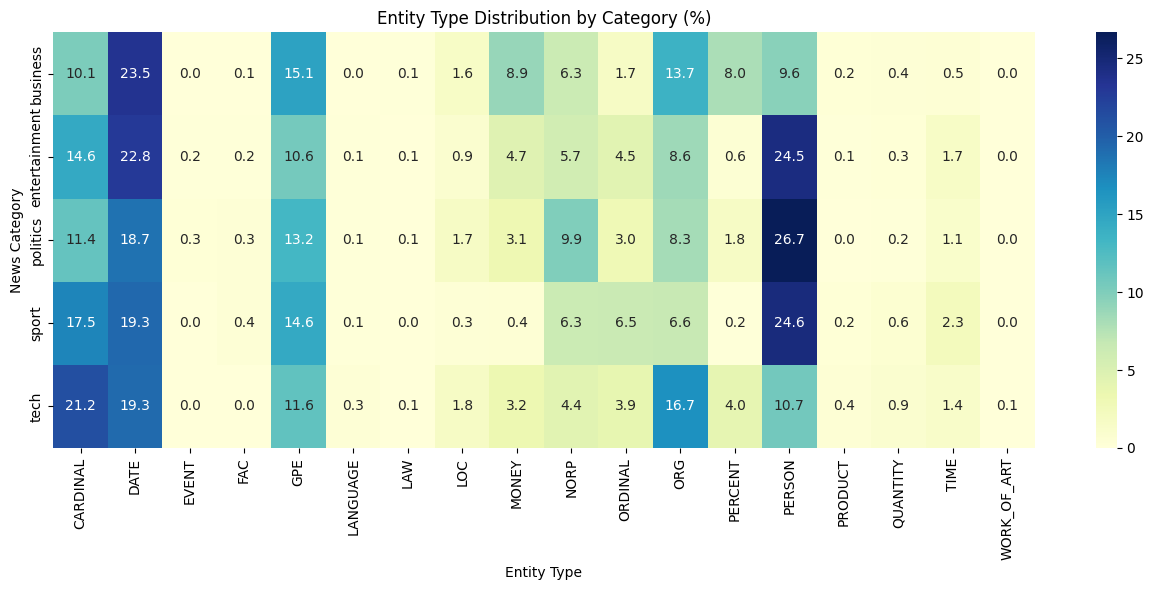


ENTITY CO-OCCURRENCE NETWORK
Nodes: 30
Edges: 222


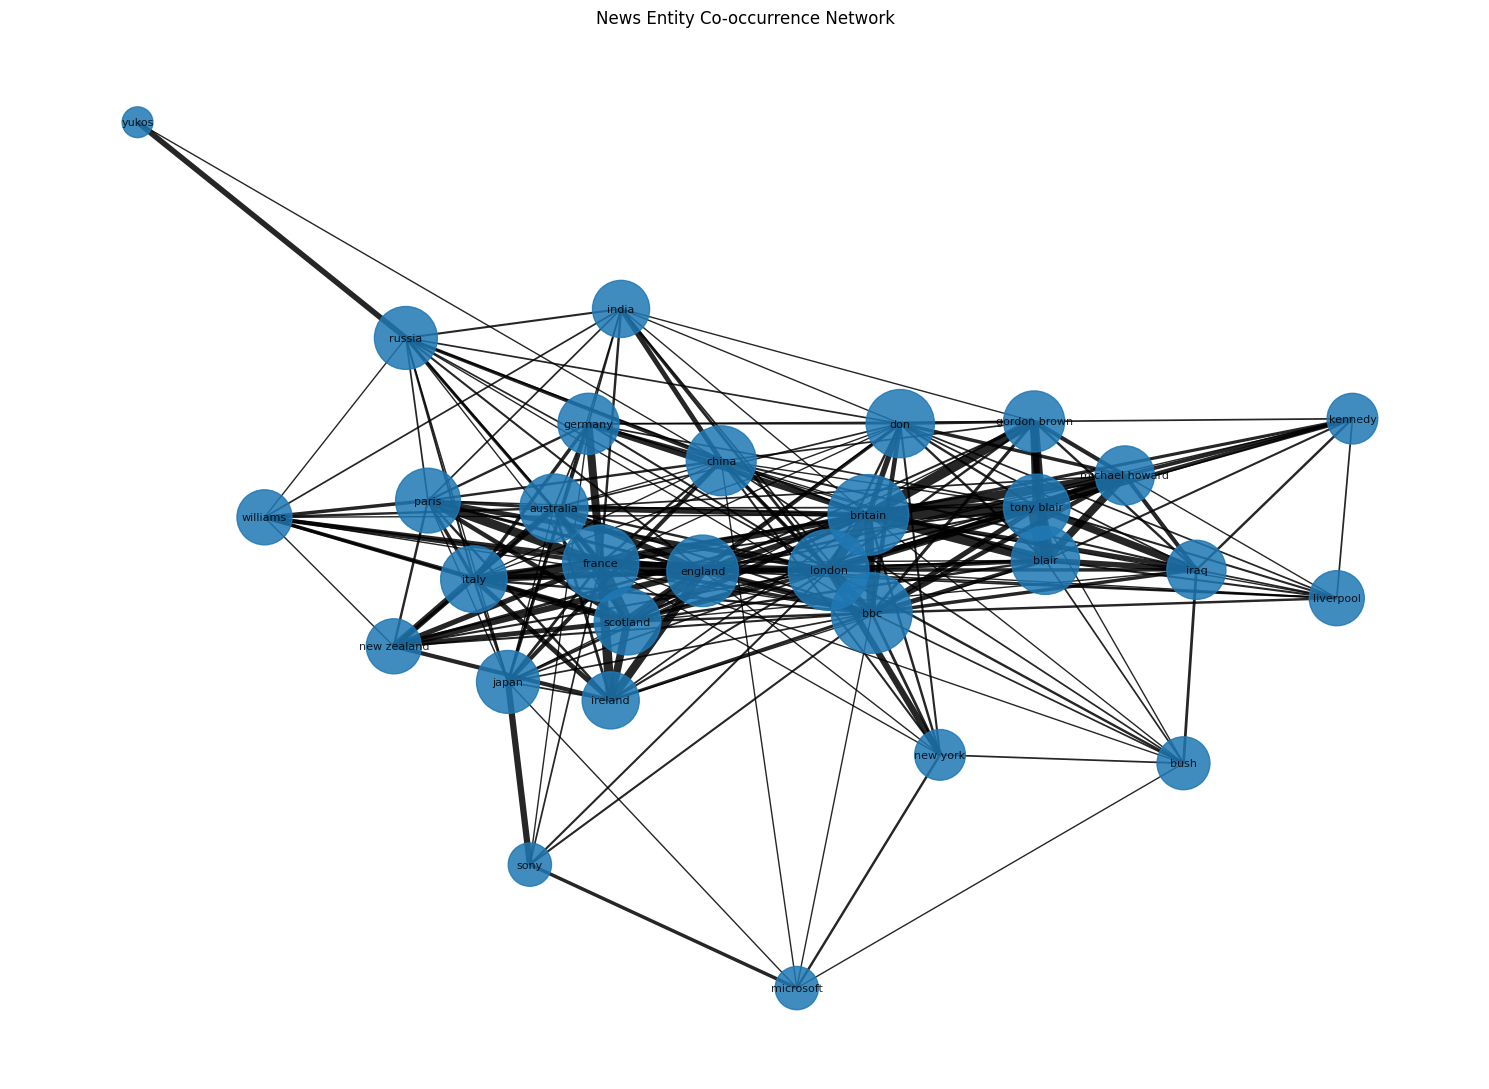


ENTITY RELATIONSHIP TABLE


,Entity A,Entity B,Shared Articles
0,blair,tony blair,51
1,britain,tony blair,37
2,britain,london,29
3,england,scotland,29
4,england,france,29
5,france,scotland,29
6,blair,britain,29
7,michael howard,tony blair,28
8,britain,gordon brown,27
9,france,ireland,25


These relationships represent article-level co-occurrence, not verified real-world links.

TEMPORAL ENTITY ANALYSIS
Temporal analysis unavailable: no valid publication dates.

ENTITY SENTIMENT ASSOCIATIONS

FREQUENT ENTITY SENTIMENT ASSOCIATIONS


,Articles,Avg_Sentiment
normalized_text,,
first,462,0.5444
one,451,0.3812
two,417,0.4450
us,297,0.3223
uk,294,0.4255
second,238,0.5104
three,224,0.4400
british,184,0.5237
third,182,0.5641


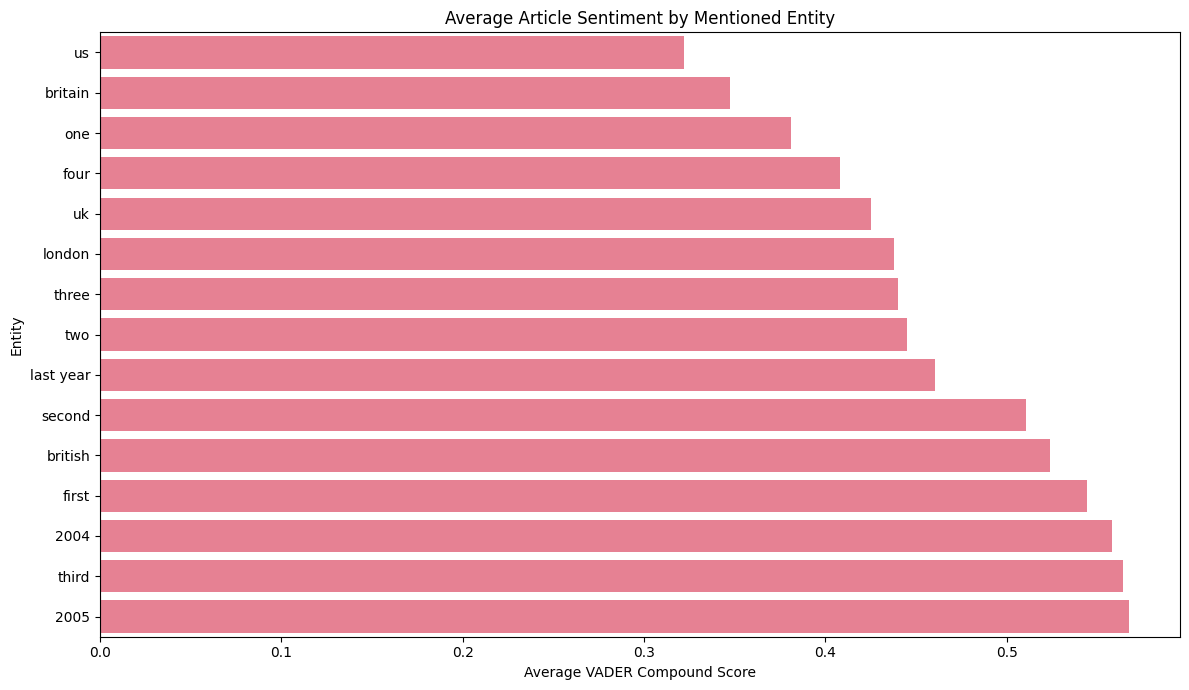

These scores represent sentiment of articles mentioning an entity, not sentiment directed toward that entity.

MANUAL NER EVALUATION
Reviewed predictions: 30
Span agreement: 70.00%
Label agreement: 80.00%
Both correct: 60.00%

AGREEMENT BY ENTITY TYPE


,Reviewed,Correct,Agreement
label,,,
DATE,6,6,1.0
GPE,6,6,1.0
MONEY,6,1,0.167
ORG,6,2,0.333
PERSON,6,3,0.5


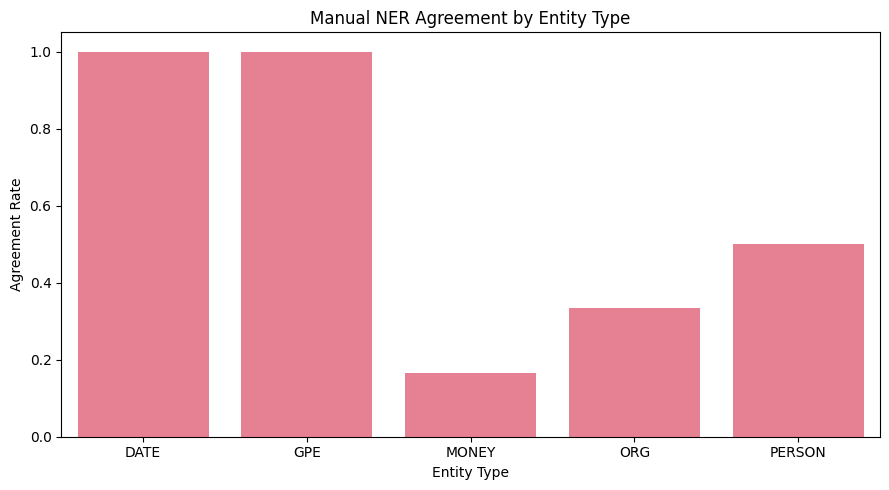


INCORRECT ENTITY PREDICTIONS


,text,label,context,reviewer_label,error_type,notes
1,william hill,PERSON,actor scott is new bond favourite bookmaker [...,ORG,wrong_label,"William Hill is a bookmaker, not a person. The..."
2,lisa raymond 7-5 6-3,PERSON,njury. in the only main draw men s or women s ...,NaN,wrong_boundary,"Lisa Raymond is a tennis player, so PERSON is ..."
3,alan s,PERSON,must be bad for public confidence in the syst...,NaN,wrong_boundary,"The entity refers to a person, Sir Alan, so PE..."
7,ulrich,ORG,u member states. of course we applaud humanit...,PERSON,wrong_boundary,"Ulrich refers to Ulrich Schulte-Strathaus, a p..."
8,reuters news,ORG,agreed in a court in the spanish capital madr...,NaN,wrong_boundary,"Reuters is a news agency, so ORG is the correc..."
10,quirksville,ORG,the airline s name was changed to anonymous a...,GPE,wrong_label,Quirksville is a fictional city mentioned in t...
11,japan s,ORG,shi motors were charged with covering up safet...,GPE,wrong_boundary,"Japan is a country, so GPE is the correct enti..."
24,530,MONEY,by nearly 10%. the deal will help the carrier...,NaN,wrong_boundary,"The value refers to £530 million, so MONEY is ..."
25,million dollar,MONEY,uage film. swank who previously won the golde...,WORK_OF_ART,wrong_label,"""Million Dollar Baby"" is a movie title, not a ..."
26,180,MONEY,deputy prime minister (odpm) has said. the a...,NaN,wrong_boundary,"The value refers to a house price of £180,444,..."



COMMON NER ERROR TYPES


,Count
error_type,
wrong_boundary,8
wrong_label,4



Manual agreement describes reviewed predicted entities only. It does not measure full NER recall or F1.

BUSINESS INTELLIGENCE INSIGHTS
Most common entity type: DATE
Category with most entity mentions: business

Potential applications:
1. Monitor frequently mentioned organizations.
2. Explore entity co-occurrence patterns.
3. Compare entity types across news categories.
4. Examine article-level sentiment associations.
5. Identify common NER prediction errors.

ADVANCED NAMED ENTITY ANALYSIS COMPLETE
Entity mentions: 40,803
Entity types: 18
News categories: 5
Network nodes: 30
Network edges: 222

Analysis includes:
✓ Entity type and category distributions
✓ Entity co-occurrence network
✓ Relationship frequency analysis
✓ Temporal data availability check
✓ Article-level sentiment associations
✓ Manual NER quality review

NER analysis complete.


In [ ]:
# # Analyze entity patterns
# if not entities_df.empty:
#     print("📊 NAMED ENTITY ANALYSIS")
#     print("=" * 50)

#     # Entity type distribution
#     entity_counts = entities_df['label'].value_counts()
#     print("\n🏷️ Entity type distribution:")
#     print(entity_counts)

#     # Entity types by category
#     entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
#     print("\n📰 Entity types by news category:")
#     print(entity_by_category)

#     # Most frequent entities
#     print("\n🔥 Most frequent entities:")
#     frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
#     for (entity, label), count in frequent_entities.items():
#         print(f"  {entity} ({label}): {count} mentions")

#     # Visualizations
#     fig, axes = plt.subplots(2, 2, figsize=(15, 12))

#     # 1. Entity type distribution
#     entity_counts.plot(kind='bar', ax=axes[0,0])
#     axes[0,0].set_title('Entity Type Distribution')
#     axes[0,0].tick_params(axis='x', rotation=45)

#     # 2. Entities per category
#     entities_per_category = entities_df.groupby('category').size()
#     entities_per_category.plot(kind='bar', ax=axes[0,1])
#     axes[0,1].set_title('Total Entities per Category')
#     axes[0,1].tick_params(axis='x', rotation=45)

#     # 3. Entity type heatmap by category
#     if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
#         sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
#         axes[1,0].set_title('Entity Types by Category Heatmap')
#     else:
#         axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
#                       ha='center', va='center', transform=axes[1,0].transAxes)
#         axes[1,0].set_title('Entity Types by Category')

#     # 4. Top entities
#     top_entities = entities_df['text'].value_counts().head(10)
#     top_entities.plot(kind='barh', ax=axes[1,1])
#     axes[1,1].set_title('Most Mentioned Entities')

#     plt.tight_layout()
#     plt.show()

#     # 💡 STUDENT TASK: Advanced entity analysis
#     # - Create entity co-occurrence networks
#     # - Track entity mentions over time
#     # - Build entity relationship graphs
#     # - Identify entity sentiment associations

# else:
#     print("⚠️ Skipping entity analysis due to insufficient data.")
#     print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")


# ============================================================
# MODULE 8: ADVANCED NAMED ENTITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from collections import Counter
from itertools import combinations

if entities_df.empty:
    raise ValueError(
        "No named entities available. "
        "Run the entity extraction section first."
    )

# ------------------------------------------------------------
# 1. Entity frequency and category analysis
# ------------------------------------------------------------

print("ADVANCED NAMED ENTITY ANALYSIS")
print("=" * 60)

entities_df["normalized_text"] = (
    entities_df["text"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

entity_counts = entities_df["label"].value_counts()

entity_by_category = pd.crosstab(
    entities_df["category"],
    entities_df["label"]
)

entities_per_category = (
    entities_df.groupby("category").size()
)

frequent_entities = (
    entities_df.groupby(
        ["normalized_text", "label"]
    )
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\nENTITY TYPE DISTRIBUTION")
display(entity_counts.to_frame("Mentions"))

print("\nENTITY TYPES BY CATEGORY")
display(entity_by_category)

print("\nMOST FREQUENT ENTITIES")
display(frequent_entities.to_frame("Mentions"))

# ------------------------------------------------------------
# 2. Entity distribution visualizations
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2, figsize=(16, 12)
)

entity_counts.plot(
    kind="bar",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Entity Type Distribution")
axes[0, 0].set_ylabel("Mentions")
axes[0, 0].tick_params(axis="x", rotation=45)

entities_per_category.plot(
    kind="bar",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Entity Mentions by Category")
axes[0, 1].set_ylabel("Mentions")
axes[0, 1].tick_params(axis="x", rotation=45)

sns.heatmap(
    entity_by_category,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Entity Types by Category")

top_entities = (
    entities_df["normalized_text"]
    .value_counts()
    .head(10)
    .sort_values()
)

top_entities.plot(
    kind="barh",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Most Mentioned Entities")
axes[1, 1].set_xlabel("Mentions")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Normalized entity distributions
# ------------------------------------------------------------

entity_category_percent = (
    entity_by_category.div(
        entity_by_category.sum(axis=1),
        axis=0
    ).fillna(0) * 100
)

print("\nENTITY DISTRIBUTION BY CATEGORY (%)")
display(entity_category_percent.round(2))

plt.figure(figsize=(13, 6))

sns.heatmap(
    entity_category_percent,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Entity Type Distribution by Category (%)")
plt.xlabel("Entity Type")
plt.ylabel("News Category")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Entity co-occurrence network
# ------------------------------------------------------------

print("\nENTITY CO-OCCURRENCE NETWORK")
print("=" * 60)

network_types = ["PERSON", "ORG", "GPE"]

network_entities = entities_df[
    entities_df["label"].isin(network_types)
    & (entities_df["normalized_text"].str.len() > 2)
].copy()

top_network_entities = (
    network_entities["normalized_text"]
    .value_counts()
    .head(30)
    .index
)

network_entities = network_entities[
    network_entities["normalized_text"].isin(
        top_network_entities
    )
]

cooccurrence_counts = Counter()

for _, group in network_entities.groupby("article_id"):

    unique_entities = sorted(
        group["normalized_text"].unique()
    )

    for entity_a, entity_b in combinations(
        unique_entities, 2
    ):
        cooccurrence_counts[
            (entity_a, entity_b)
        ] += 1

entity_graph = nx.Graph()

for (entity_a, entity_b), weight in (
    cooccurrence_counts.items()
):
    if weight >= 2:
        entity_graph.add_edge(
            entity_a,
            entity_b,
            weight=weight
        )

print(f"Nodes: {entity_graph.number_of_nodes()}")
print(f"Edges: {entity_graph.number_of_edges()}")

if entity_graph.number_of_nodes() > 0:

    plt.figure(figsize=(15, 11))

    positions = nx.spring_layout(
        entity_graph,
        seed=42,
        weight="weight"
    )

    node_sizes = [
        250 + 120 * entity_graph.degree(node)
        for node in entity_graph.nodes()
    ]

    edge_widths = [
        0.5 + entity_graph[u][v]["weight"] * 0.25
        for u, v in entity_graph.edges()
    ]

    nx.draw_networkx(
        entity_graph,
        pos=positions,
        node_size=node_sizes,
        width=edge_widths,
        font_size=8,
        with_labels=True,
        alpha=0.85
    )

    plt.title("News Entity Co-occurrence Network")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

else:
    print("Insufficient repeated co-occurrences.")

# ------------------------------------------------------------
# 5. Entity relationship analysis
# ------------------------------------------------------------

relationship_df = pd.DataFrame(
    [
        {
            "Entity A": entity_a,
            "Entity B": entity_b,
            "Shared Articles": count
        }
        for (entity_a, entity_b), count
        in cooccurrence_counts.most_common(20)
    ],
    columns=[
        "Entity A", "Entity B", "Shared Articles"
    ]
)

print("\nENTITY RELATIONSHIP TABLE")
display(relationship_df)

print(
    "These relationships represent article-level "
    "co-occurrence, not verified real-world links."
)

# ------------------------------------------------------------
# 6. Temporal entity analysis
# ------------------------------------------------------------

print("\nTEMPORAL ENTITY ANALYSIS")
print("=" * 60)

temporal_available = False

if "date" in df.columns:

    date_lookup = df[
        ["article_id", "date"]
    ].copy()

    date_lookup["date"] = pd.to_datetime(
        date_lookup["date"],
        errors="coerce"
    )

    temporal_entities = entities_df.merge(
        date_lookup,
        on="article_id",
        how="left",
        validate="many_to_one"
    ).dropna(subset=["date"])

    if not temporal_entities.empty:
        temporal_available = True

        temporal_entities["month"] = (
            temporal_entities["date"]
            .dt.to_period("M")
            .astype(str)
        )

        top_temporal_entities = (
            temporal_entities["normalized_text"]
            .value_counts()
            .head(5)
            .index
        )

        temporal_counts = (
            temporal_entities[
                temporal_entities["normalized_text"].isin(
                    top_temporal_entities
                )
            ]
            .groupby(["month", "normalized_text"])
            .size()
            .unstack(fill_value=0)
        )

        display(temporal_counts)

        temporal_counts.plot(
            kind="line",
            marker="o",
            figsize=(12, 6)
        )

        plt.title("Entity Mentions Over Time")
        plt.xlabel("Month")
        plt.ylabel("Mentions")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

if not temporal_available:
    print(
        "Temporal analysis unavailable: "
        "no valid publication dates."
    )

# ------------------------------------------------------------
# 7. Entity sentiment associations
# ------------------------------------------------------------

print("\nENTITY SENTIMENT ASSOCIATIONS")
print("=" * 60)

entity_sentiment_df = entities_df.merge(
    sentiment_df[
        ["article_id", "full_sentiment", "full_label"]
    ],
    on="article_id",
    how="left",
    validate="many_to_one"
)

# Use one article-level sentiment value per entity
# to avoid counting repeated mentions as independent
# article observations.
entity_article_sentiment = (
    entity_sentiment_df.drop_duplicates(
        ["normalized_text", "article_id"]
    )
)

entity_sentiment_summary = (
    entity_article_sentiment.groupby(
        "normalized_text"
    )
    .agg(
        Articles=("article_id", "nunique"),
        Avg_Sentiment=("full_sentiment", "mean")
    )
)

entity_sentiment_summary = (
    entity_sentiment_summary[
        entity_sentiment_summary["Articles"] >= 5
    ]
    .sort_values(
        "Articles",
        ascending=False
    )
)

print("\nFREQUENT ENTITY SENTIMENT ASSOCIATIONS")
display(entity_sentiment_summary.head(20).round(4))

if not entity_sentiment_summary.empty:

    top_sentiment_entities = (
        entity_sentiment_summary.head(15)
        .sort_values("Avg_Sentiment")
    )

    plt.figure(figsize=(12, 7))

    sns.barplot(
        x=top_sentiment_entities["Avg_Sentiment"],
        y=top_sentiment_entities.index
    )

    plt.axvline(
        0,
        color="gray",
        linestyle="--"
    )

    plt.title(
        "Average Article Sentiment by Mentioned Entity"
    )
    plt.xlabel("Average VADER Compound Score")
    plt.ylabel("Entity")
    plt.tight_layout()
    plt.show()

print(
    "These scores represent sentiment of articles "
    "mentioning an entity, not sentiment directed "
    "toward that entity."
)

# ------------------------------------------------------------
# 8. Manual NER evaluation
# ------------------------------------------------------------

print("\nMANUAL NER EVALUATION")
print("=" * 60)

if "completed_review_df" not in globals():
    raise RuntimeError(
        "Manual review data is unavailable. "
        "Run the manual validation section first."
    )

ner_errors = pd.DataFrame()

if completed_review_df.empty:

    print("No predictions have been manually reviewed.")
    print(
        "Complete the annotation CSV and rerun "
        "the manual validation and analysis sections."
    )

else:

    reviewed = completed_review_df.copy()

    reviewed["span_correct"] = (
        reviewed["correct_span"] == "yes"
    )

    reviewed["label_correct"] = (
        reviewed["correct_label"] == "yes"
    )

    reviewed["fully_correct"] = (
        reviewed["span_correct"]
        & reviewed["label_correct"]
    )

    span_agreement = reviewed["span_correct"].mean()
    label_agreement = reviewed["label_correct"].mean()
    full_agreement = reviewed["fully_correct"].mean()

    print(f"Reviewed predictions: {len(reviewed)}")
    print(f"Span agreement: {span_agreement:.2%}")
    print(f"Label agreement: {label_agreement:.2%}")
    print(f"Both correct: {full_agreement:.2%}")

    per_type = (
        reviewed.groupby("label")
        .agg(
            Reviewed=("fully_correct", "size"),
            Correct=("fully_correct", "sum"),
            Agreement=("fully_correct", "mean")
        )
    )

    print("\nAGREEMENT BY ENTITY TYPE")
    display(per_type.round(3))

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=per_type.index,
        y=per_type["Agreement"]
    )

    plt.title("Manual NER Agreement by Entity Type")
    plt.xlabel("Entity Type")
    plt.ylabel("Agreement Rate")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

    ner_errors = reviewed[
        ~reviewed["fully_correct"]
    ].copy()

    print("\nINCORRECT ENTITY PREDICTIONS")

    display(
        ner_errors[
            [
                "text", "label", "context",
                "reviewer_label", "error_type", "notes"
            ]
        ]
    )

    if ner_errors["error_type"].notna().any():

        print("\nCOMMON NER ERROR TYPES")

        display(
            ner_errors["error_type"]
            .value_counts()
            .to_frame("Count")
        )

    print(
        "\nManual agreement describes reviewed "
        "predicted entities only. It does not "
        "measure full NER recall or F1."
    )

# ------------------------------------------------------------
# 9. Business intelligence insights
# ------------------------------------------------------------

print("\nBUSINESS INTELLIGENCE INSIGHTS")
print("=" * 60)

most_common_type = entity_counts.idxmax()
category_with_most_entities = (
    entities_per_category.idxmax()
)

print(f"Most common entity type: {most_common_type}")

print(
    "Category with most entity mentions: "
    f"{category_with_most_entities}"
)

print("\nPotential applications:")
print("1. Monitor frequently mentioned organizations.")
print("2. Explore entity co-occurrence patterns.")
print("3. Compare entity types across news categories.")
print("4. Examine article-level sentiment associations.")
print("5. Identify common NER prediction errors.")

# ------------------------------------------------------------
# 10. Analysis summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ADVANCED NAMED ENTITY ANALYSIS COMPLETE")
print("=" * 60)

print(f"Entity mentions: {len(entities_df):,}")
print(f"Entity types: {entities_df['label'].nunique()}")
print(f"News categories: {entities_df['category'].nunique()}")
print(f"Network nodes: {entity_graph.number_of_nodes()}")
print(f"Network edges: {entity_graph.number_of_edges()}")

print("\nAnalysis includes:")
print("✓ Entity type and category distributions")
print("✓ Entity co-occurrence network")
print("✓ Relationship frequency analysis")
print("✓ Temporal data availability check")
print("✓ Article-level sentiment associations")
print("✓ Manual NER quality review")

print("\nNER analysis complete.")




## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM
COMPREHENSIVE ANALYSIS REPORT

📊 DATASET OVERVIEW
------------------------------------------------------------
Total Articles: 1440
Total Categories: 5
Categories: business, entertainment, politics, sport, tech
Average Article Length: 2234 characters
Average Words per Article: 385 words

Category distribution:


,Category,Articles
0,sport,342
1,business,335
2,politics,266
3,entertainment,263
4,tech,234



🤖 CLASSIFICATION PERFORMANCE
------------------------------------------------------------
Selected Model: Naive Bayes
Test Accuracy: 0.9444
Test Macro F1: 0.9403
Training CV Macro F1: 0.9701


,Model,Accuracy,Macro F1,CV Macro F1
0,Naive Bayes,0.9444,0.9403,0.9701
1,Logistic Regression,0.9271,0.9236,0.9099
2,SVM,0.9583,0.9557,0.9583



😊 SENTIMENT INSIGHTS
------------------------------------------------------------
Highest Average Sentiment: entertainment
Lowest Average Sentiment: politics
Overall Average Sentiment: 0.3902


,Category,Average Compound
0,business,0.2381
1,entertainment,0.5900
2,politics,0.0541
3,sport,0.5492
4,tech,0.5330



🔍 NAMED ENTITY INSIGHTS
------------------------------------------------------------
Total Entity Mentions: 40,803
Unique Entity Names: 11,995
Entity Types: CARDINAL, DATE, EVENT, FAC, GPE, LANGUAGE, LAW, LOC, MONEY, NORP, ORDINAL, ORG, PERCENT, PERSON, PRODUCT, QUANTITY, TIME, WORK_OF_ART
Average Entity Mentions per Article: 28.34

Top mentioned entities:


,Entity,Mentions
0,first,739
1,one,639
2,two,584
3,us,547
4,uk,524
5,british,326
6,second,316
7,three,313
8,britain,277
9,london,272



🧠 LINGUISTIC PATTERNS
------------------------------------------------------------

Top TF-IDF terms by category:
business: firm, company, market, year, share
entertainment: film, star, award, best, actor
politics: labour, election, party, government, blair
sport: game, win, play, player, match
tech: use, people, user, technology, computer

POS patterns:
Highest noun proportion: entertainment
Highest verb proportion: politics
Highest number proportion: business

Syntax patterns:
Longest average sentences: politics
Highest average dependency distance: sport

📊 COMPREHENSIVE NEWSBOT DASHBOARD


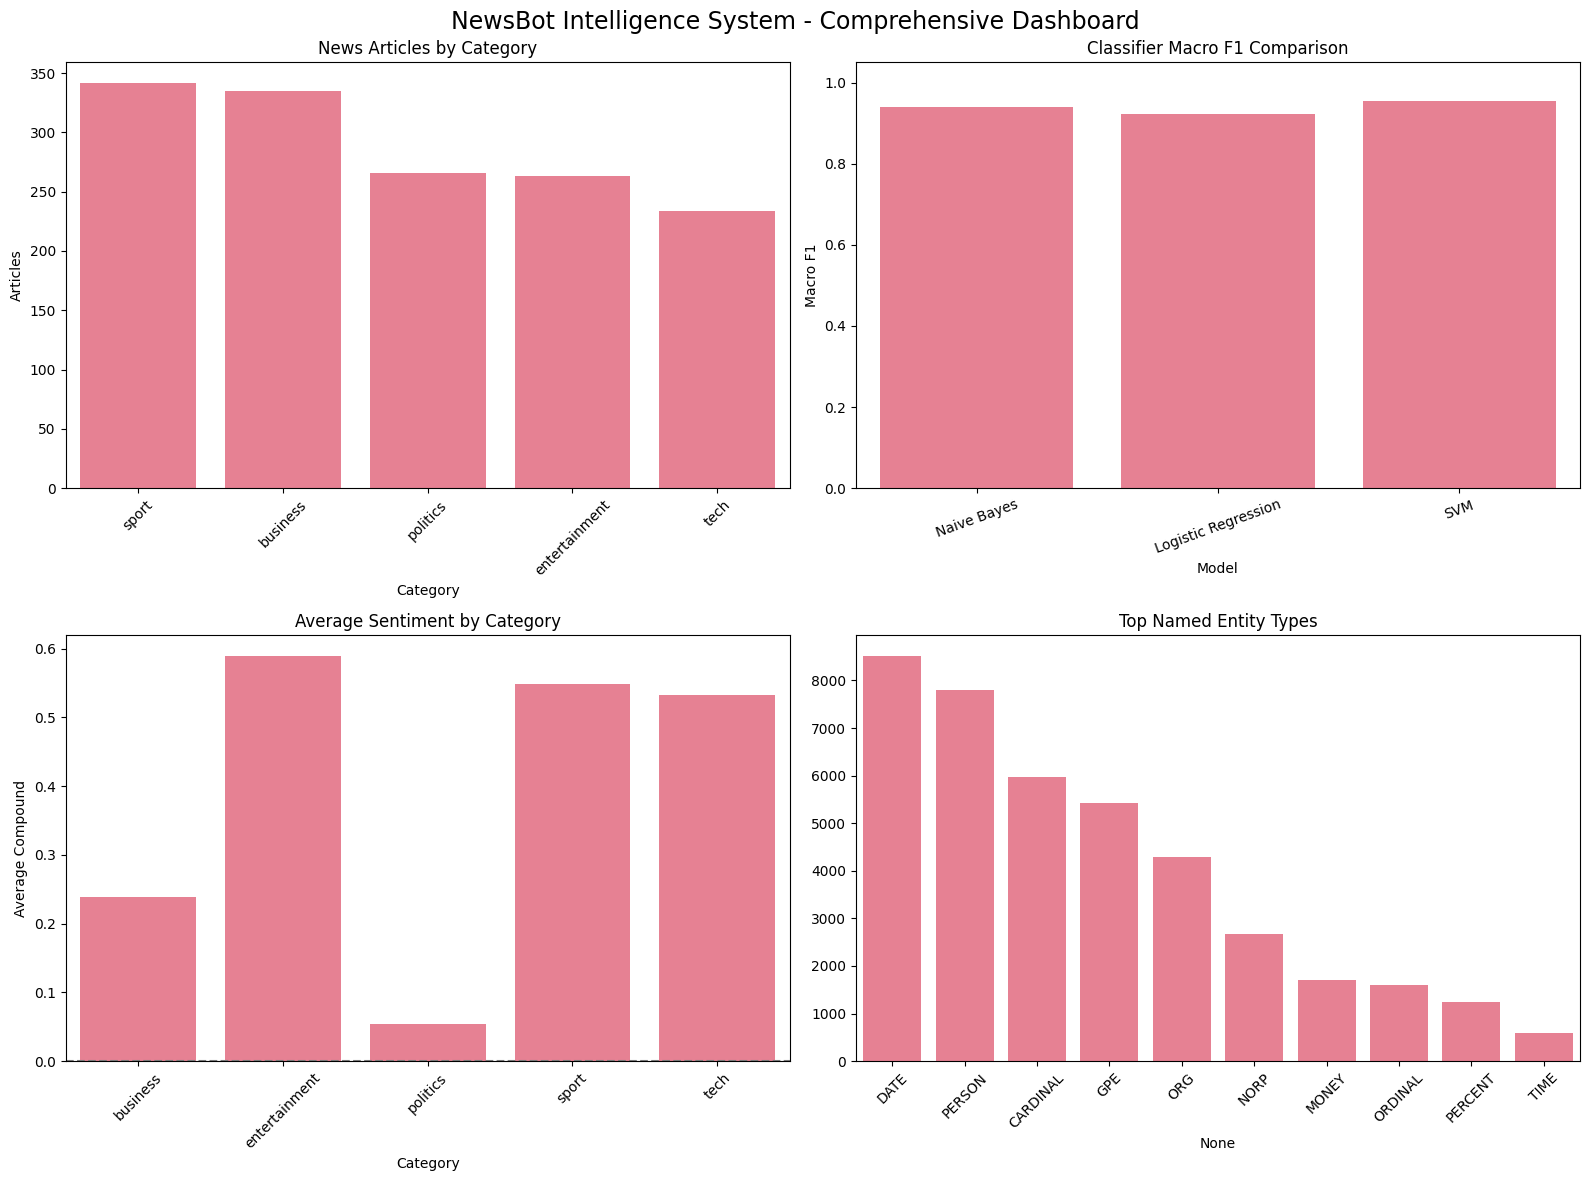


💡 BUSINESS RECOMMENDATIONS
1. Classification performance is promising for a prototype. Validate on unseen external news articles before deployment.

2. entertainment has the highest average VADER sentiment score. Review representative articles to understand the underlying language.

3. politics has the lowest average VADER sentiment score. Monitor patterns without assuming negative sentiment means biased coverage.

4. Use named entities to support article search, organization monitoring, and discovery of frequently co-mentioned entities.

5. Combine TF-IDF, sentiment, and linguistic features only when validation shows measurable improvement over a simpler TF-IDF baseline.

6. The BBC dataset lacks publication dates and independent headlines. Temporal analysis and headline comparisons require richer metadata.

📁 Analysis saved to: /content/newsbot_comprehensive_analysis.json

✅ NEWSBOT COMPREHENSIVE ANALYSIS COMPLETE
Articles analyzed: 1440
News categories: 5
Classifiers compared: 3
Se

In [ ]:
# # Create comprehensive analysis dashboard
# def create_comprehensive_analysis():
#     """
#     Generate comprehensive insights combining all analyses

#     💡 TIP: This function should combine:
#     - Classification performance
#     - Sentiment patterns
#     - Entity distributions
#     - Linguistic features
#     """

#     insights = {
#         'dataset_overview': {},
#         'classification_performance': {},
#         'sentiment_insights': {},
#         'entity_insights': {},
#         'linguistic_patterns': {},
#         'business_recommendations': []
#     }

#     # 🚀 YOUR CODE HERE: Generate comprehensive insights

#     # Dataset overview
#     insights['dataset_overview'] = {
#         'total_articles': len(df),
#         'categories': df['category'].unique().tolist(),
#         'category_distribution': df['category'].value_counts().to_dict(),
#         'avg_article_length': df['full_text'].str.len().mean(),
#         'avg_words_per_article': df['full_text'].str.split().str.len().mean()
#     }

#     # Classification performance
#     insights['classification_performance'] = {
#         'best_model': best_model_name,
#         'best_accuracy': results[best_model_name]['accuracy'],
#         'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
#     }

#     # Sentiment insights
#     sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
#     insights['sentiment_insights'] = {
#         'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
#         'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
#         'sentiment_by_category': sentiment_by_cat,
#         'overall_sentiment': sentiment_df['full_sentiment'].mean()
#     }

#     # Entity insights
#     if not entities_df.empty:
#         entity_by_cat = entities_df.groupby('category').size().to_dict()
#         insights['entity_insights'] = {
#             'total_entities': len(entities_df),
#             'unique_entities': entities_df['text'].nunique(),
#             'entity_types': entities_df['label'].unique().tolist(),
#             'entities_per_category': entity_by_cat,
#             'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
#         }

#     # Generate business recommendations
#     recommendations = []

#     # Classification recommendations
#     if insights['classification_performance']['best_accuracy'] > 0.8:
#         recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
#     else:
#         recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

#     # Sentiment recommendations
#     pos_cat = insights['sentiment_insights']['most_positive_category']
#     neg_cat = insights['sentiment_insights']['most_negative_category']
#     recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
#     recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

#     # Entity recommendations
#     if 'entity_insights' in insights and insights['entity_insights']:
#         recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

#     insights['business_recommendations'] = recommendations

#     return insights

# # Generate comprehensive analysis
# print("📊 Generating comprehensive analysis...")
# analysis_results = create_comprehensive_analysis()

# print("✅ Analysis complete!")
# print("\n" + "=" * 60)
# print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
# print("=" * 60)

# # Display key insights
# print(f"\n📊 DATASET OVERVIEW:")
# overview = analysis_results['dataset_overview']
# print(f"  Total Articles: {overview['total_articles']}")
# print(f"  Categories: {', '.join(overview['categories'])}")
# print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
# print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

# print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
# perf = analysis_results['classification_performance']
# print(f"  Best Model: {perf['best_model']}")
# print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

# print(f"\n😊 SENTIMENT INSIGHTS:")
# sent = analysis_results['sentiment_insights']
# print(f"  Most Positive Category: {sent['most_positive_category']}")
# print(f"  Most Negative Category: {sent['most_negative_category']}")
# print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

# if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
#     print(f"\n🔍 ENTITY INSIGHTS:")
#     ent = analysis_results['entity_insights']
#     print(f"  Total Entities: {ent['total_entities']}")
#     print(f"  Unique Entities: {ent['unique_entities']}")
#     print(f"  Entity Types: {', '.join(ent['entity_types'])}")

# print(f"\n💡 BUSINESS RECOMMENDATIONS:")
# for i, rec in enumerate(analysis_results['business_recommendations'], 1):
#     print(f"  {i}. {rec}")



# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# COMPREHENSIVE ANALYSIS DASHBOARD
# Midterm Project - Modules 1-8 Integration
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# STEP 1: Generate comprehensive analysis
# ------------------------------------------------------------

def create_comprehensive_analysis():
    """
    Combine results from all eight NLP modules.

    Includes:
    - Dataset overview
    - Classification performance
    - Sentiment patterns
    - Named entity analysis
    - TF-IDF and linguistic patterns
    - Business intelligence recommendations
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # --------------------------------------------------------
    # DATASET OVERVIEW
    # --------------------------------------------------------

    category_counts = df['category'].value_counts()

    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': sorted(
            df['category'].unique().tolist()
        ),
        'category_distribution': category_counts.to_dict(),
        'avg_article_length': float(
            df['full_text'].str.len().mean()
        ),
        'avg_words_per_article': float(
            df['full_text'].str.split().str.len().mean()
        ),
        'total_categories': int(
            df['category'].nunique()
        )
    }

    # --------------------------------------------------------
    # CLASSIFICATION PERFORMANCE
    # --------------------------------------------------------

    model_comparison = {}

    for name, result in results.items():

        model_comparison[name] = {
            'accuracy': float(result['accuracy']),
            'macro_f1': float(result.get(
                'f1_macro',
                f1_score(
                    y_test,
                    result['predictions'],
                    average='macro',
                    zero_division=0
                )
            )),
            'cv_mean': float(result['cv_mean']),
            'cv_std': float(result['cv_std'])
        }

    selected_result = model_comparison[best_model_name]

    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': selected_result['accuracy'],
        'best_macro_f1': selected_result['macro_f1'],
        'best_cv_f1': selected_result['cv_mean'],
        'model_comparison': model_comparison,
        'training_articles': len(y_train),
        'testing_articles': len(y_test)
    }

    # --------------------------------------------------------
    # SENTIMENT INSIGHTS
    # --------------------------------------------------------

    sentiment_by_cat = (
        sentiment_df.groupby('category')['full_sentiment']
        .mean()
        .to_dict()
    )

    sentiment_distribution = (
        pd.crosstab(
            sentiment_df['category'],
            sentiment_df['full_label'],
            normalize='index'
        )
        .mul(100)
        .round(2)
    )

    insights['sentiment_insights'] = {
        'most_positive_category': max(
            sentiment_by_cat,
            key=sentiment_by_cat.get
        ),
        'most_negative_category': min(
            sentiment_by_cat,
            key=sentiment_by_cat.get
        ),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': float(
            sentiment_df['full_sentiment'].mean()
        ),
        'sentiment_distribution': (
            sentiment_distribution.to_dict()
        )
    }

    # --------------------------------------------------------
    # NAMED ENTITY INSIGHTS
    # --------------------------------------------------------

    if not entities_df.empty:

        entity_by_cat = (
            entities_df.groupby('category')
            .size()
            .to_dict()
        )

        # Normalize entity text for consistent counting
        normalized_entities = (
            entities_df['text']
            .astype(str)
            .str.lower()
            .str.replace(r'\s+', ' ', regex=True)
            .str.strip()
        )

        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': int(
                normalized_entities.nunique()
            ),
            'entity_types': sorted(
                entities_df['label'].unique().tolist()
            ),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': (
                normalized_entities.value_counts()
                .head(10)
                .to_dict()
            ),
            'entity_type_distribution': (
                entities_df['label']
                .value_counts()
                .to_dict()
            ),
            'avg_entities_per_article': (
                len(entities_df) / len(df)
            )
        }

    # --------------------------------------------------------
    # LINGUISTIC PATTERNS
    # --------------------------------------------------------

    linguistic_insights = {}

    # TF-IDF category-specific terms
    if 'category_terms' in globals():

        linguistic_insights['top_terms_by_category'] = {
            category: terms.head(5).index.tolist()
            for category, terms in category_terms.items()
        }

    # POS patterns
    if 'grouped_pos_percent' in globals():

        linguistic_insights['pos_patterns'] = {
            'highest_noun_category': (
                grouped_pos_percent['Nouns'].idxmax()
            ),
            'highest_verb_category': (
                grouped_pos_percent['Verbs'].idxmax()
            ),
            'highest_number_category': (
                grouped_pos_percent['Numbers'].idxmax()
            )
        }

    # Syntactic patterns
    if (
        'complexity_summary' in globals()
        and not complexity_summary.empty
    ):

        linguistic_insights['syntax_patterns'] = {
            'longest_sentences_category': (
                complexity_summary[
                    'avg_sentence_length'
                ].idxmax()
            ),
            'highest_dependency_distance_category': (
                complexity_summary[
                    'avg_dependency_distance'
                ].idxmax()
            )
        }

    insights['linguistic_patterns'] = linguistic_insights

    # --------------------------------------------------------
    # BUSINESS INTELLIGENCE RECOMMENDATIONS
    # --------------------------------------------------------

    recommendations = []

    accuracy = insights[
        'classification_performance'
    ]['best_accuracy']

    macro_f1 = insights[
        'classification_performance'
    ]['best_macro_f1']

    # Classification recommendations
    if accuracy >= 0.90 and macro_f1 >= 0.90:

        recommendations.append(
            "Classification performance is promising "
            "for a prototype. Validate on unseen "
            "external news articles before deployment."
        )

    elif accuracy >= 0.80:

        recommendations.append(
            "Classification performance is reasonable "
            "for a baseline. Review category-level "
            "errors and improve weaker classes."
        )

    else:

        recommendations.append(
            "Classification performance needs improvement. "
            "Consider feature engineering, parameter tuning, "
            "and additional labeled training data."
        )

    # Sentiment recommendations
    pos_cat = insights[
        'sentiment_insights'
    ]['most_positive_category']

    neg_cat = insights[
        'sentiment_insights'
    ]['most_negative_category']

    recommendations.append(
        f"{pos_cat} has the highest average VADER "
        "sentiment score. Review representative articles "
        "to understand the underlying language."
    )

    recommendations.append(
        f"{neg_cat} has the lowest average VADER "
        "sentiment score. Monitor patterns without "
        "assuming negative sentiment means biased coverage."
    )

    # Entity recommendations
    if insights['entity_insights']:

        recommendations.append(
            "Use named entities to support article search, "
            "organization monitoring, and discovery of "
            "frequently co-mentioned entities."
        )

    # Linguistic recommendations
    recommendations.append(
        "Combine TF-IDF, sentiment, and linguistic features "
        "only when validation shows measurable improvement "
        "over a simpler TF-IDF baseline."
    )

    # Dataset limitation
    recommendations.append(
        "The BBC dataset lacks publication dates and "
        "independent headlines. Temporal analysis and "
        "headline comparisons require richer metadata."
    )

    insights['business_recommendations'] = recommendations

    return insights


# ------------------------------------------------------------
# STEP 2: Generate comprehensive analysis
# ------------------------------------------------------------

print("📊 Generating comprehensive analysis...")

analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")


# ------------------------------------------------------------
# STEP 3: Display comprehensive report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("📈 NEWSBOT INTELLIGENCE SYSTEM")
print("COMPREHENSIVE ANALYSIS REPORT")
print("=" * 70)

# Dataset overview
overview = analysis_results['dataset_overview']

print("\n📊 DATASET OVERVIEW")
print("-" * 60)

print(f"Total Articles: {overview['total_articles']}")
print(f"Total Categories: {overview['total_categories']}")
print(f"Categories: {', '.join(overview['categories'])}")

print(
    f"Average Article Length: "
    f"{overview['avg_article_length']:.0f} characters"
)

print(
    f"Average Words per Article: "
    f"{overview['avg_words_per_article']:.0f} words"
)

print("\nCategory distribution:")
display(
    pd.DataFrame(
        list(overview['category_distribution'].items()),
        columns=['Category', 'Articles']
    )
)


# ------------------------------------------------------------
# STEP 4: Classification performance
# ------------------------------------------------------------

perf = analysis_results['classification_performance']

print("\n🤖 CLASSIFICATION PERFORMANCE")
print("-" * 60)

print(f"Selected Model: {perf['best_model']}")
print(f"Test Accuracy: {perf['best_accuracy']:.4f}")
print(f"Test Macro F1: {perf['best_macro_f1']:.4f}")
print(f"Training CV Macro F1: {perf['best_cv_f1']:.4f}")

model_summary_df = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': metrics['accuracy'],
        'Macro F1': metrics['macro_f1'],
        'CV Macro F1': metrics['cv_mean']
    }
    for name, metrics in perf['model_comparison'].items()
])

display(model_summary_df.round(4))


# ------------------------------------------------------------
# STEP 5: Sentiment insights
# ------------------------------------------------------------

sent = analysis_results['sentiment_insights']

print("\n😊 SENTIMENT INSIGHTS")
print("-" * 60)

print(
    f"Highest Average Sentiment: "
    f"{sent['most_positive_category']}"
)

print(
    f"Lowest Average Sentiment: "
    f"{sent['most_negative_category']}"
)

print(
    f"Overall Average Sentiment: "
    f"{sent['overall_sentiment']:.4f}"
)

sentiment_summary_df = pd.DataFrame({
    'Category': list(
        sent['sentiment_by_category'].keys()
    ),
    'Average Compound': list(
        sent['sentiment_by_category'].values()
    )
})

display(sentiment_summary_df.round(4))


# ------------------------------------------------------------
# STEP 6: Entity insights
# ------------------------------------------------------------

ent = analysis_results['entity_insights']

if ent:

    print("\n🔍 NAMED ENTITY INSIGHTS")
    print("-" * 60)

    print(f"Total Entity Mentions: {ent['total_entities']:,}")
    print(f"Unique Entity Names: {ent['unique_entities']:,}")
    print(f"Entity Types: {', '.join(ent['entity_types'])}")

    print(
        f"Average Entity Mentions per Article: "
        f"{ent['avg_entities_per_article']:.2f}"
    )

    print("\nTop mentioned entities:")

    display(
        pd.DataFrame(
            list(ent['most_mentioned_entities'].items()),
            columns=['Entity', 'Mentions']
        )
    )


# ------------------------------------------------------------
# STEP 7: Linguistic patterns
# ------------------------------------------------------------

print("\n🧠 LINGUISTIC PATTERNS")
print("-" * 60)

linguistic = analysis_results['linguistic_patterns']

if 'top_terms_by_category' in linguistic:

    print("\nTop TF-IDF terms by category:")

    for category, terms in (
        linguistic['top_terms_by_category'].items()
    ):
        print(f"{category}: {', '.join(terms)}")

if 'pos_patterns' in linguistic:

    pos_insights = linguistic['pos_patterns']

    print("\nPOS patterns:")
    print(
        f"Highest noun proportion: "
        f"{pos_insights['highest_noun_category']}"
    )
    print(
        f"Highest verb proportion: "
        f"{pos_insights['highest_verb_category']}"
    )
    print(
        f"Highest number proportion: "
        f"{pos_insights['highest_number_category']}"
    )

if 'syntax_patterns' in linguistic:

    syntax_insights = linguistic['syntax_patterns']

    print("\nSyntax patterns:")
    print(
        f"Longest average sentences: "
        f"{syntax_insights['longest_sentences_category']}"
    )
    print(
        f"Highest average dependency distance: "
        f"{syntax_insights['highest_dependency_distance_category']}"
    )


# ------------------------------------------------------------
# STEP 8: Visual dashboard
# ------------------------------------------------------------

print("\n📊 COMPREHENSIVE NEWSBOT DASHBOARD")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Dataset category distribution
category_data = pd.Series(
    overview['category_distribution']
)

sns.barplot(
    x=category_data.index,
    y=category_data.values,
    ax=axes[0, 0]
)

axes[0, 0].set_title('News Articles by Category')
axes[0, 0].set_xlabel('Category')
axes[0, 0].set_ylabel('Articles')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Classification performance
sns.barplot(
    data=model_summary_df,
    x='Model',
    y='Macro F1',
    ax=axes[0, 1]
)

axes[0, 1].set_title('Classifier Macro F1 Comparison')
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].tick_params(axis='x', rotation=20)

# 3. Average sentiment by category
sns.barplot(
    data=sentiment_summary_df,
    x='Category',
    y='Average Compound',
    ax=axes[1, 0]
)

axes[1, 0].set_title('Average Sentiment by Category')
axes[1, 0].axhline(0, color='gray', linestyle='--')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Entity type distribution
if ent:

    entity_type_data = pd.Series(
        ent['entity_type_distribution']
    ).head(10)

    sns.barplot(
        x=entity_type_data.index,
        y=entity_type_data.values,
        ax=axes[1, 1]
    )

    axes[1, 1].set_title('Top Named Entity Types')
    axes[1, 1].tick_params(axis='x', rotation=45)

else:
    axes[1, 1].text(
        0.5, 0.5,
        'No entity data available',
        ha='center',
        va='center',
        transform=axes[1, 1].transAxes
    )
    axes[1, 1].set_title('Named Entity Analysis')

plt.suptitle(
    'NewsBot Intelligence System - Comprehensive Dashboard',
    fontsize=17
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 9: Business recommendations
# ------------------------------------------------------------

print("\n💡 BUSINESS RECOMMENDATIONS")
print("=" * 60)

for i, recommendation in enumerate(
    analysis_results['business_recommendations'], 1
):
    print(f"{i}. {recommendation}\n")


# ------------------------------------------------------------
# STEP 10: Save dashboard results
# ------------------------------------------------------------

import json

def json_converter(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    raise TypeError(
        f"Object of type {type(obj).__name__} "
        "is not JSON serializable"
    )

report_path = "/content/newsbot_comprehensive_analysis.json"

with open(report_path, 'w', encoding='utf-8') as f:
    json.dump(
        analysis_results,
        f,
        indent=4,
        ensure_ascii=False,
        default=json_converter
    )

print(f"📁 Analysis saved to: {report_path}")


# ------------------------------------------------------------
# STEP 11: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ NEWSBOT COMPREHENSIVE ANALYSIS COMPLETE")
print("=" * 70)

print(f"Articles analyzed: {len(df)}")
print(f"News categories: {df['category'].nunique()}")
print(f"Classifiers compared: {len(results)}")
print(f"Selected model: {best_model_name}")

print("\nIntegrated modules:")
print("✓ Module 1: Dataset and Business Context")
print("✓ Module 2: Text Preprocessing")
print("✓ Module 3: TF-IDF Analysis")
print("✓ Module 4: POS Pattern Analysis")
print("✓ Module 5: Syntax and Semantic Analysis")
print("✓ Module 6: Sentiment Analysis")
print("✓ Module 7: Multi-Class Classification")
print("✓ Module 8: Named Entity Recognition")

print("\nDashboard and business recommendations generated.")
print("Ready for final NewsBot system integration.")


## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:
# class NewsBotIntelligenceSystem:
#     """
#     Complete NewsBot Intelligence System

#     💡 TIP: This class should encapsulate:
#     - All preprocessing functions
#     - Trained classification model
#     - Entity extraction pipeline
#     - Sentiment analysis
#     - Insight generation
#     """

#     def __init__(self, classifier, vectorizer, sentiment_analyzer):
#         self.classifier = classifier
#         self.vectorizer = vectorizer
#         self.sentiment_analyzer = sentiment_analyzer
#         self.nlp = nlp  # spaCy model

#     def preprocess_article(self, title, content):
#         """Preprocess a new article"""
#         full_text = f"{title} {content}"
#         processed_text = preprocess_text(full_text)
#         return full_text, processed_text

#     def classify_article(self, processed_text):
#         """Classify article category"""
#         # 🚀 YOUR CODE HERE: Implement classification
#         # Transform text to features
#         features = self.vectorizer.transform([processed_text])

#         # Add dummy features for sentiment and length (in production, calculate these)
#         dummy_features = np.zeros((1, 7))  # 4 sentiment + 3 length features
#         features_combined = np.hstack([features.toarray(), dummy_features])

#         # Predict category and probability
#         prediction = self.classifier.predict(features_combined)[0]
#         probabilities = self.classifier.predict_proba(features_combined)[0]

#         # Get class probabilities
#         class_probs = dict(zip(self.classifier.classes_, probabilities))

#         return prediction, class_probs

#     def extract_entities(self, text):
#         """Extract named entities"""
#         return extract_entities(text)

#     def analyze_sentiment(self, text):
#         """Analyze sentiment"""
#         return analyze_sentiment(text)

#     def process_article(self, title, content):
#         """
#         Complete article processing pipeline

#         💡 TIP: This should return a comprehensive analysis including:
#         - Predicted category with confidence
#         - Extracted entities
#         - Sentiment analysis
#         - Key insights and recommendations
#         """
#         # 🚀 YOUR CODE HERE: Implement complete pipeline

#         # Step 1: Preprocess
#         full_text, processed_text = self.preprocess_article(title, content)

#         # Step 2: Classify
#         category, category_probs = self.classify_article(processed_text)

#         # Step 3: Extract entities
#         entities = self.extract_entities(full_text)

#         # Step 4: Analyze sentiment
#         sentiment = self.analyze_sentiment(full_text)

#         # Step 5: Generate insights
#         insights = self.generate_insights(category, entities, sentiment, category_probs)

#         return {
#             'title': title,
#             'content': content[:200] + '...' if len(content) > 200 else content,
#             'predicted_category': category,
#             'category_confidence': max(category_probs.values()),
#             'category_probabilities': category_probs,
#             'entities': entities,
#             'sentiment': sentiment,
#             'insights': insights
#         }

#     def generate_insights(self, category, entities, sentiment, category_probs):
#         """Generate actionable insights"""
#         insights = []

#         # Classification insights
#         confidence = max(category_probs.values())
#         if confidence > 0.8:
#             insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
#         else:
#             insights.append(f"⚠️ Uncertain classification - consider manual review")

#         # Sentiment insights
#         if sentiment['compound'] > 0.1:
#             insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
#         elif sentiment['compound'] < -0.1:
#             insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
#         else:
#             insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

#         # Entity insights
#         if entities:
#             entity_types = set([e['label'] for e in entities])
#             insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

#             # Highlight important entities
#             important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
#             if important_entities:
#                 key_entities = [e['text'] for e in important_entities[:3]]
#                 insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
#         else:
#             insights.append("ℹ️ No named entities detected")

#         return insights

# # Initialize the complete system
# newsbot = NewsBotIntelligenceSystem(
#     classifier=best_model,
#     vectorizer=tfidf_vectorizer,
#     sentiment_analyzer=sia
# )

# print("🤖 NewsBot Intelligence System initialized!")
# print("✅ Ready to process new articles")



# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM: END-TO-END INTEGRATION
# NewsBot Intelligence System - Midterm Project
# Compatible with updated Cells 23, 24, and 25
# ============================================================

import numpy as np
import pandas as pd
import spacy

from collections import Counter
from nltk import word_tokenize, pos_tag
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# STEP 1: Define complete NewsBot system
# ------------------------------------------------------------

class NewsBotIntelligenceSystem:
    """
    End-to-end NewsBot Intelligence System.

    Integrates:
    - Text preprocessing
    - TF-IDF and numerical feature extraction
    - News classification
    - Sentiment analysis
    - POS analysis
    - Named entity recognition
    - Syntactic relationship extraction
    - Actionable insights

    The trained sklearn Pipeline handles TF-IDF
    and numerical scaling automatically.
    """

    def __init__(
        self,
        classifier,
        vectorizer=None,
        sentiment_analyzer=None,
        model_name=None
    ):

        # Classifier must be the complete fitted pipeline
        if not isinstance(classifier, Pipeline):
            raise TypeError(
                "Expected a fitted sklearn Pipeline. "
                "Run updated Cells 23 and 24 first."
            )

        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = (
            sentiment_analyzer
            if sentiment_analyzer is not None
            else sia
        )

        self.model_name = (
            model_name
            if model_name is not None
            else classifier.named_steps[
                'classifier'
            ].__class__.__name__
        )

        self.nlp = nlp

        self.sentiment_columns = [
            'full_sentiment',
            'pos_score',
            'neu_score',
            'neg_score'
        ]

        self.length_feature_names = [
            'character_count',
            'word_count',
            'title_length'
        ]

        self.pos_feature_names = list(
            available_pos_features
        )

        # Reuse the input schema established during feature preparation.
        self.input_columns = list(
            X_train_raw.columns
        )

        self.model_classes = (
            classifier.named_steps[
                'classifier'
            ].classes_
        )

    # --------------------------------------------------------
    # STEP 2: Preprocess article
    # --------------------------------------------------------

    def preprocess_article(self, title, content):
        """
        Prepare article text for classification.

        BBC training used article content without
        duplicating the generated title.
        """

        title = str(title or '').strip()
        content = str(content or '').strip()

        # Prefer content to match BBC training structure
        full_text = content if content else title

        processed_text = preprocess_text(full_text)

        return full_text, processed_text

    # --------------------------------------------------------
    # STEP 3: Sentiment analysis
    # --------------------------------------------------------

    def analyze_sentiment(self, text):
        """
        Analyze original text using VADER.
        """

        if not isinstance(text, str) or not text.strip():
            return {
                'compound': 0.0,
                'pos': 0.0,
                'neu': 1.0,
                'neg': 0.0,
                'sentiment_label': 'neutral'
            }

        scores = self.sentiment_analyzer.polarity_scores(
            text
        )

        if scores['compound'] >= 0.05:
            scores['sentiment_label'] = 'positive'

        elif scores['compound'] <= -0.05:
            scores['sentiment_label'] = 'negative'

        else:
            scores['sentiment_label'] = 'neutral'

        return scores

    # --------------------------------------------------------
    # STEP 4: POS feature extraction
    # --------------------------------------------------------

    def extract_pos_features(self, text):
        """
        Extract grouped POS proportions using
        the same method as Module 4.
        """

        tokens = word_tokenize(text)

        tokens = [
            token for token in tokens
            if any(char.isalnum() for char in token)
        ]

        if not tokens:
            return {
                name: 0.0
                for name in self.pos_feature_names
            }

        tagged_tokens = pos_tag(tokens)

        group_counts = Counter(
            get_pos_group(tag)
            for _, tag in tagged_tokens
        )

        total = len(tagged_tokens)

        return {
            name: (
                group_counts.get(
                    name.replace('GROUP_', ''), 0
                ) / total
            )
            for name in self.pos_feature_names
        }

    # --------------------------------------------------------
    # STEP 5: Build model input features
    # --------------------------------------------------------

    def build_feature_dataframe(
        self,
        title,
        full_text,
        processed_text,
        sentiment
    ):
        """
        Build a one-row DataFrame matching the
        exact input schema used during model training.
        """

        # BBC training titles were generated using
        # the first 100 characters of article content.
        # Match that title-length definition at inference.
        title_length_proxy = len(full_text[:100])

        features = {
            'processed_text': processed_text,

            'full_sentiment': sentiment['compound'],
            'pos_score': sentiment['pos'],
            'neu_score': sentiment['neu'],
            'neg_score': sentiment['neg'],

            'character_count': len(full_text),
            'word_count': len(full_text.split()),
            'title_length': title_length_proxy
        }

        # Add POS features
        features.update(
            self.extract_pos_features(full_text)
        )

        # Create DataFrame in training column order
        feature_df = pd.DataFrame(
            [features]
        )

        feature_df = feature_df.reindex(
            columns=self.input_columns,
            fill_value=0
        )

        # Validate numeric features
        numeric_columns = [
            col for col in feature_df.columns
            if col != 'processed_text'
        ]

        if not np.isfinite(
            feature_df[numeric_columns]
            .to_numpy(dtype=float)
        ).all():
            raise ValueError(
                "Invalid numerical features detected."
            )

        return feature_df

    # --------------------------------------------------------
    # STEP 6: Classify article
    # --------------------------------------------------------

    def classify_article(
        self,
        processed_text,
        title="",
        full_text=None
    ):
        """
        Classify using the complete fitted Pipeline.

        The pipeline automatically applies TF-IDF
        and numerical scaling.
        """

        if full_text is None:
            full_text = str(processed_text)

        sentiment = self.analyze_sentiment(
            full_text
        )

        model_input = self.build_feature_dataframe(
            title,
            full_text,
            processed_text,
            sentiment
        )

        prediction = self.classifier.predict(
            model_input
        )[0]

        # All configured classifiers support
        # predict_proba().
        probabilities = self.classifier.predict_proba(
            model_input
        )[0]

        category_probs = {
            str(category): float(probability)
            for category, probability in zip(
                self.model_classes,
                probabilities
            )
        }

        return prediction, category_probs

    # --------------------------------------------------------
    # STEP 7: Named entity recognition
    # --------------------------------------------------------

    def extract_entities(self, text):
        """
        Extract named entities using spaCy.
        """

        if not isinstance(text, str) or not text.strip():
            return []

        doc = self.nlp(text)

        entities = []

        for ent in doc.ents:

            entities.append({
                'text': ent.text,
                'label': ent.label_,
                'start': ent.start_char,
                'end': ent.end_char,
                'description': (
                    spacy.explain(ent.label_)
                    or ent.label_
                )
            })

        return entities

    # --------------------------------------------------------
    # STEP 8: Syntax analysis
    # --------------------------------------------------------

    def extract_syntax_insights(self, text):
        """
        Extract sentence structure and
        subject-verb-object relationships.
        """

        if not isinstance(text, str) or not text.strip():
            return {
                'sentences': 0,
                'noun_phrases': [],
                'action_patterns': []
            }

        doc = self.nlp(text)

        sentences = list(doc.sents)

        noun_phrases = [
            chunk.text
            for chunk in doc.noun_chunks
        ]

        # Reuse the extraction function from Module 5
        actions = extract_action_patterns(doc)

        return {
            'sentences': len(sentences),
            'noun_phrases': noun_phrases[:10],
            'action_patterns': actions[:10]
        }

    # --------------------------------------------------------
    # STEP 9: Generate insights
    # --------------------------------------------------------

    def generate_insights(
        self,
        category,
        entities,
        sentiment,
        category_probs
    ):
        """
        Generate interpretable article insights.
        """

        insights = []

        confidence = max(
            category_probs.values()
        )

        # Classification insight
        if confidence >= 0.80:

            insights.append(
                f"High model confidence for "
                f"{category} ({confidence:.2%})."
            )

        else:

            insights.append(
                f"Predicted category: {category}. "
                f"Consider manual review "
                f"(confidence: {confidence:.2%})."
            )

        # Sentiment insight
        compound = sentiment['compound']

        if compound >= 0.05:

            insights.append(
                f"Positive sentiment detected "
                f"({compound:.3f})."
            )

        elif compound <= -0.05:

            insights.append(
                f"Negative sentiment detected "
                f"({compound:.3f})."
            )

        else:

            insights.append(
                f"Neutral sentiment detected "
                f"({compound:.3f})."
            )

        # Entity insight
        if entities:

            entity_types = {
                entity['label']
                for entity in entities
            }

            insights.append(
                f"Found {len(entities)} entity mentions "
                f"across {len(entity_types)} entity types."
            )

            important_entities = [
                entity['text']
                for entity in entities
                if entity['label'] in [
                    'PERSON', 'ORG', 'GPE'
                ]
            ]

            important_entities = list(
                dict.fromkeys(important_entities)
            )

            if important_entities:

                insights.append(
                    "Key entities: " +
                    ", ".join(important_entities[:5])
                )

        else:

            insights.append(
                "No named entities detected."
            )

        return insights

    # --------------------------------------------------------
    # STEP 10: Complete article processing
    # --------------------------------------------------------

    def process_article(self, title, content):
        """
        Run complete NewsBot analysis.
        """

        title = str(title or '')
        content = str(content or '')

        # 1. Preprocess
        full_text, processed_text = (
            self.preprocess_article(
                title,
                content
            )
        )

        if not processed_text.strip():
            raise ValueError(
                "Article must contain meaningful text."
            )

        # 2. Classify
        category, category_probs = (
            self.classify_article(
                processed_text,
                title=title,
                full_text=full_text
            )
        )

        # 3. Named entities
        entities = self.extract_entities(
            full_text
        )

        # 4. Sentiment
        sentiment = self.analyze_sentiment(
            full_text
        )

        # 5. Syntax
        syntax = self.extract_syntax_insights(
            full_text
        )

        # 6. Insights
        insights = self.generate_insights(
            category,
            entities,
            sentiment,
            category_probs
        )

        return {
            'title': title,
            'content': (
                content[:200] + '...'
                if len(content) > 200
                else content
            ),
            'predicted_category': str(category),
            'category_confidence': float(
                max(category_probs.values())
            ),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'syntax': syntax,
            'insights': insights
        }


# ------------------------------------------------------------
# STEP 11: Initialize NewsBot
# ------------------------------------------------------------

print("🤖 INITIALIZING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia,
    model_name=best_model_name
)

print("✅ NewsBot initialized successfully!")
print(f"Selected model: {best_model_name}")

print(
    f"Input columns: "
    f"{len(newsbot.input_columns)}"
)

print(
    f"Model classes: "
    f"{newsbot.model_classes.tolist()}"
)

# ------------------------------------------------------------
# STEP 12: Validate model input compatibility
# ------------------------------------------------------------

print("\n🔍 PIPELINE COMPATIBILITY CHECK")
print("=" * 60)

assert isinstance(
    newsbot.classifier,
    Pipeline
)

assert 'features' in newsbot.classifier.named_steps
assert 'classifier' in newsbot.classifier.named_steps

# Create a sample input with real feature calculations
validation_text = (
    "The technology company introduced a new "
    "computer processor for artificial intelligence."
)

validation_full, validation_processed = (
    newsbot.preprocess_article(
        "New AI Processor",
        validation_text
    )
)

validation_sentiment = newsbot.analyze_sentiment(
    validation_full
)

validation_features = newsbot.build_feature_dataframe(
    "New AI Processor",
    validation_full,
    validation_processed,
    validation_sentiment
)

# Validate that the fitted pipeline can predict
validation_prediction = newsbot.classifier.predict(
    validation_features
)

print(
    f"Input DataFrame shape: "
    f"{validation_features.shape}"
)

print(
    f"Validation prediction: "
    f"{validation_prediction[0]}"
)

print("✓ Input schema matches training")
print("✓ No manual TF-IDF transformation")
print("✓ No duplicate numerical scaling")
print("✓ Fitted pipeline accepts new articles")
print("✓ Classification and NLP components ready")

print("\nReady for NewsBot End-to-End Testing")



🤖 INITIALIZING NEWSBOT INTELLIGENCE SYSTEM
✅ NewsBot initialized successfully!
Selected model: Naive Bayes
Input columns: 17
Model classes: ['business', 'entertainment', 'politics', 'sport', 'tech']

🔍 PIPELINE COMPATIBILITY CHECK
Input DataFrame shape: (1, 17)
Validation prediction: tech
✓ Input schema matches training
✓ No manual TF-IDF transformation
✓ No duplicate numerical scaling
✓ Fitted pipeline accepts new articles
✓ Classification and NLP components ready

Ready for NewsBot End-to-End Testing


🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM
Retrieved 513 words from www.nasa.gov
Retrieved 154 words from www.federalreserve.gov

EXTERNAL SOURCE RETRIEVAL


,Source,Status,Words,Reason
0,https://www.nasa.gov/news-release/nasa-identif...,Retrieved,513,
1,https://www.federalreserve.gov/newsevents/pres...,Retrieved,154,



EXTERNAL ARTICLE CONTENT VERIFICATION

Source: https://www.nasa.gov/news-release/nasa-identifies-more-than-40-space-technologies-for-collaboration/
Word count: 513
Expected category: Tech

First 500 characters:
NASA selected 41 proposals from 37 companies to advance technologies in support of the agency’s goals to establish a long-term presence on the Moon and enable human exploration of Mars. These American companies, picked from NASA’s 2025 Announcement of Collaboration Opportunity (ACO), will mature technologies creating solutions for space transportation, planetary surface operations, and lunar surface infrastructure. “We are empowering American industry to become active partners in NASA’s missions

Last 200 characters:
ine. For more information about NASA’s space technology investments, visit: Jennifer Dooren / Rob Margetta Headquarters, Washington 202-358-1600 jennifer.m.dooren@nasa.gov / robert.j.margetta@nasa.gov
------------------------------------------------------------

So

,Article,Test Type,Group,Source,Expected,Predicted,Confidence,Sentiment,Sentiment Score,Entity Count,Correct,Status
0,1,Business / Technology,Synthetic,Synthetic demonstration,Business,business,0.359741,positive,0.6597,6,True,Success
1,2,Sports,Synthetic,Synthetic demonstration,Sport,sport,0.615628,positive,0.5574,7,True,Success
2,3,Ambiguous: Science / Politics,Synthetic,Synthetic demonstration,None,business,0.328930,positive,0.2263,1,None,Success
3,4,Business,Synthetic,Synthetic demonstration,Business,business,0.975106,positive,0.6808,0,True,Success
4,5,Entertainment,Synthetic,Synthetic demonstration,Entertainment,entertainment,0.792523,positive,0.4767,0,True,Success
5,6,Politics,Synthetic,Synthetic demonstration,Politics,politics,0.698981,neutral,0.0000,0,True,Success
6,7,Technology,Synthetic,Synthetic demonstration,Tech,tech,0.649294,positive,0.7906,0,True,Success
7,8,External: Technology,External,https://www.nasa.gov/news-release/nasa-identif...,Tech,tech,0.504780,positive,0.9966,44,True,Success
8,9,External: Economic policy,External,https://www.federalreserve.gov/newsevents/pres...,Business,business,0.893334,positive,0.9493,16,True,Success


Total tests: 9
Successful: 9
Failed: 0
Agreement with assigned labels: 100.00%
Note: These labels are illustrative. This is not a formal external benchmark.
Synthetic assigned-label agreement: 100.00% (n=6)
External assigned-label agreement: 100.00% (n=2)
Small manually labeled examples are not benchmark accuracy.

🌐 EXTERNAL ARTICLE VALIDATION
External texts retrieved: 2
External tests executed successfully: 2


,Article,Expected,Predicted,Confidence,Correct,Status
7,8,Tech,tech,0.504780,True,Success
8,9,Business,business,0.893334,True,Success



📊 TESTING VISUALIZATIONS


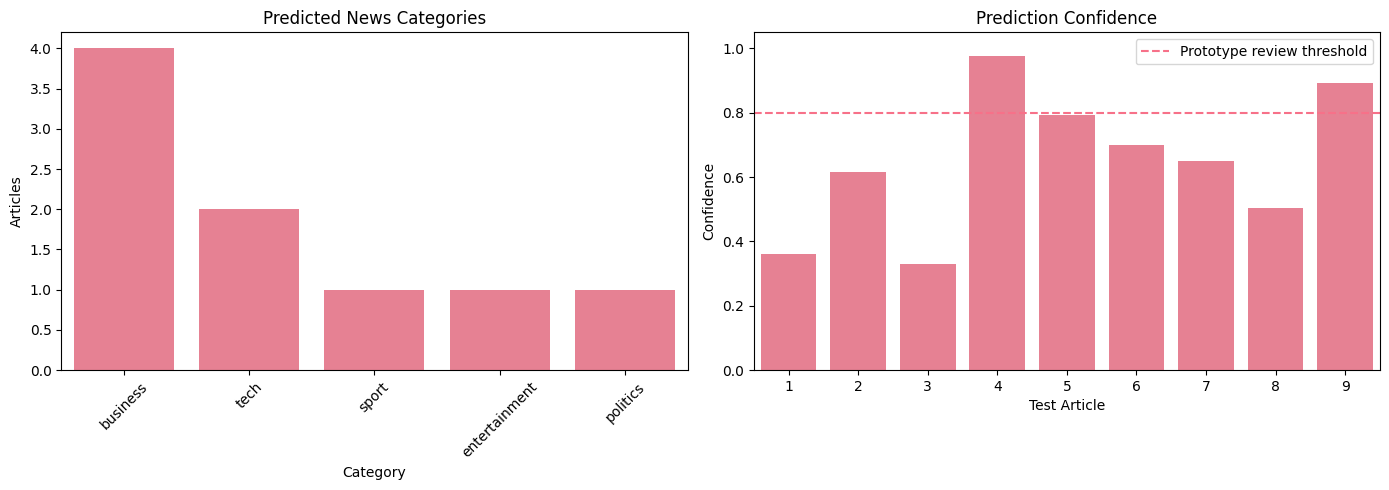


🛡️ EDGE CASE TESTING


,Test,Status
0,Empty article,Rejected
1,Whitespace only,Rejected



💡 SYSTEM STRENGTHS
1. Integrates multiple NLP techniques.
2. Classifies articles into five BBC categories.
3. Extracts named entities and sentiment.
4. Generates structured article insights.
5. Supports end-to-end processing of new text.

⚠️ SYSTEM LIMITATIONS
1. BBC-trained model may not generalize to all sources.
2. Short articles provide limited classification context.
3. Ambiguous articles can overlap multiple categories.
4. VADER sentiment may misinterpret complex language.
5. spaCy NER may produce incorrect entity labels.
6. Model confidence is not guaranteed accuracy.

🚀 FUTURE IMPROVEMENTS
1. Evaluate more genuine external articles.
2. Improve classification with validated features.
3. Calibrate model probabilities.
4. Improve entity recognition for news domains.
5. Add real publication dates for trend analysis.
6. Build an interactive NewsBot interface.

Results saved to: /content/newsbot_testing_results.csv

NEWSBOT SYSTEM TESTING SUMMARY
Total tests: 9
Successful tests: 9
F

In [ ]:
# # Test the complete system with new articles
# print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
# print("=" * 60)

# # Test articles (you can modify these or add your own)
# test_articles = [
#     {
#         'title': 'Microsoft Acquires AI Startup for $2 Billion',
#         'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
#     },
#     {
#         'title': 'Lakers Win Championship in Overtime Thriller',
#         'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
#     },
#     {
#         'title': 'New Climate Change Report Shows Alarming Trends',
#         'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
#     }
# ]

# # Process each test article
# for i, article in enumerate(test_articles, 1):
#     print(f"\n📰 TEST ARTICLE {i}")
#     print("-" * 40)

#     # Process the article
#     result = newsbot.process_article(article['title'], article['content'])

#     # Display results
#     print(f"📰 Title: {result['title']}")
#     print(f"📝 Content: {result['content']}")
#     print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

#     print(f"\n📊 Category Probabilities:")
#     for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
#         print(f"  {cat}: {prob:.3f}")

#     print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

#     if result['entities']:
#         print(f"\n🔍 Entities Found ({len(result['entities'])}):")
#         for entity in result['entities'][:5]:  # Show first 5
#             print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
#     else:
#         print(f"\n🔍 No entities detected")

#     print(f"\n💡 Insights:")
#     for insight in result['insights']:
#         print(f"  {insight}")

# print("\n" + "=" * 60)
# print("🎉 NewsBot Intelligence System testing complete!")
# print("✅ System successfully processed all test articles")

# # 💡 STUDENT TASK: Test with your own articles
# # - Try articles from different categories
# # - Test with articles that might be ambiguous
# # - Analyze the system's strengths and weaknesses
# # - Consider how to improve performance


# ============================================================
# NEWSBOT END-TO-END TESTING AND EXTERNAL VALIDATION
# Midterm Project - Final System Demonstration
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# ------------------------------------------------------------
# STEP 1: Define demonstration articles
# ------------------------------------------------------------

# These are synthetic examples for testing.
# They are not verified real-world news articles.

test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': (
            "Microsoft Corporation announced today the acquisition "
            "of an artificial intelligence startup for $2 billion. "
            "CEO Satya Nadella said the deal will strengthen "
            "Microsoft's position in the AI market and enhance "
            "its cloud computing services."
        ),
        'expected_category': 'Business',
        'source': 'Synthetic demonstration',
        'test_type': 'Business / Technology'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': (
            "The Los Angeles Lakers defeated the Boston Celtics "
            "108-102 in overtime to win the NBA championship. "
            "LeBron James scored 35 points and was named Finals MVP."
        ),
        'expected_category': 'Sport',
        'source': 'Synthetic demonstration',
        'test_type': 'Sports'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': (
            "Scientists at the United Nations released a comprehensive "
            "climate report showing accelerating global warming. "
            "The report warns that immediate action is needed "
            "to prevent environmental damage."
        ),
        'expected_category': None,
        'source': 'Synthetic demonstration',
        'test_type': 'Ambiguous: Science / Politics'
    },
    {
        'title': 'Central Bank Announces Interest Rate Decision',
        'content': (
            "The central bank announced changes to interest rates "
            "following new inflation and economic growth reports. "
            "Financial analysts expect the decision to influence "
            "business investment, lending, and stock markets."
        ),
        'expected_category': 'Business',
        'source': 'Synthetic demonstration',
        'test_type': 'Business'
    },
    {
        'title': 'Streaming Platform Announces New Drama Series',
        'content': (
            "A streaming platform announced a new television drama "
            "featuring award-winning actors and directors. "
            "Entertainment critics expect the series to attract "
            "international audiences."
        ),
        'expected_category': 'Entertainment',
        'source': 'Synthetic demonstration',
        'test_type': 'Entertainment'
    },
    {
        'title': 'Government Announces New Education Policy',
        'content': (
            "The government introduced a new education policy "
            "during a parliamentary debate. Lawmakers discussed "
            "public funding, national priorities, and legislation "
            "before a scheduled vote."
        ),
        'expected_category': 'Politics',
        'source': 'Synthetic demonstration',
        'test_type': 'Politics'
    },
    {
        'title': 'Technology Company Develops New AI Processor',
        'content': (
            "A technology company introduced a new artificial "
            "intelligence processor designed to improve computer "
            "performance. Engineers explained that the chip "
            "uses advanced semiconductor technology to accelerate "
            "machine learning and cloud computing applications."
        ),
        'expected_category': 'Tech',
        'source': 'Synthetic demonstration',
        'test_type': 'Technology'
    }
]

# ------------------------------------------------------------
# STEP 2: Retrieve genuine external-source texts
# ------------------------------------------------------------
# These official publications are external to the BBC corpus.
# Labels are manually assigned to the closest BBC category.
# The Federal Reserve source is a policy statement, not news reporting.
# Retrieval failures are logged and NEVER replaced with invented text.

import re
import requests
from bs4 import BeautifulSoup

external_sources = [
    {
        'title': 'NASA Identifies More Than 40 Space Technologies for Collaboration',
        'source': 'https://www.nasa.gov/news-release/nasa-identifies-more-than-40-space-technologies-for-collaboration/',
        'expected_category': 'Tech',
        'test_type': 'External: Technology'
    },
    {
        'title': 'Federal Reserve Issues FOMC Statement',
        'source': 'https://www.federalreserve.gov/newsevents/pressreleases/monetary20260916a.htm',
        'expected_category': 'Business',
        'test_type': 'External: Economic policy'
    }
]

MIN_EXTERNAL_WORDS = 150


def fetch_external_text(url):
    """
    Retrieve external article text for NewsBot evaluation.

    Decode source bytes correctly, prefer article-specific
    content, remove common boilerplate, and validate length.
    """

    import re
    import unicodedata
    from urllib.parse import urlparse
    from bs4 import BeautifulSoup

    response = requests.get(
        url,
        timeout=25,
        headers={
            "User-Agent": "Mozilla/5.0",
            "Accept": "text/html"
        }
    )
    response.raise_for_status()

    # Prefer UTF-8; use detected encoding if needed.
    try:
        html_text = response.content.decode("utf-8-sig")
    except UnicodeDecodeError:
        html_text = response.content.decode(
            response.apparent_encoding or "utf-8",
            errors="replace"
        )

    soup = BeautifulSoup(html_text, "html.parser")

    # Remove non-article elements.
    for tag in soup([
        "script", "style", "nav", "footer",
        "header", "aside", "form", "noscript",
        "button", "svg"
    ]):
        tag.decompose()

    for selector in [
        ".breadcrumb",
        ".breadcrumbs",
        ".related-content",
        ".related-links",
        ".social-share",
        ".share-tools",
        ".sidebar",
        ".cookie-banner"
    ]:
        for tag in soup.select(selector):
            tag.decompose()

    domain = urlparse(url).netloc.lower()

    # Use source-specific containers where possible.
    if "federalreserve.gov" in domain:
        selectors = [
            "#article",
            "#content",
            "main",
            "article"
        ]
    elif "nasa.gov" in domain:
        selectors = [
            "article .entry-content",
            ".entry-content",
            "article",
            "main"
        ]
    else:
        selectors = [
            "article",
            "[itemprop='articleBody']",
            ".entry-content",
            "main"
        ]

    containers = []

    for selector in selectors:
        containers = soup.select(selector)
        if containers:
            break

    if not containers:
        raise ValueError(
            "No article content container found."
        )

    def extract_paragraphs(container):
        paragraphs = []

        for p in container.find_all("p"):
            text = p.get_text(" ", strip=True)

            text = unicodedata.normalize("NFKC", text)
            text = re.sub(r"\s+", " ", text).strip()

            if len(text.split()) < 6:
                continue

            lower = text.lower()

            excluded = [
                "skip to main content",
                "share this page",
                "follow us on",
                "subscribe to",
                "privacy policy",
                "cookie policy",
                "back to top",
                "all rights reserved"
            ]

            if any(phrase in lower for phrase in excluded):
                continue

            paragraphs.append(text)

        return list(dict.fromkeys(paragraphs))

    candidates = [
        extract_paragraphs(container)
        for container in containers
    ]

    paragraphs = max(
        candidates,
        key=lambda items: sum(
            len(text.split()) for text in items
        ),
        default=[]
    )

    content = " ".join(paragraphs).strip()
    word_count = len(content.split())

    if word_count < MIN_EXTERNAL_WORDS:
        raise ValueError(
            f"Only {word_count} article words extracted; "
            f"minimum is {MIN_EXTERNAL_WORDS}."
        )

    # Reject common character-encoding corruption.
    suspicious = ["â€", "Ã¢", "ï¿½", "\ufffd"]

    if any(value in content for value in suspicious):
        raise ValueError(
            "Possible text encoding corruption detected."
        )

    print(f"Retrieved {word_count} words from {domain}")

    return content


external_articles = []
external_collection_log = []
for item in external_sources:
    try:
        content = fetch_external_text(item['source'])
        external_articles.append({**item, 'content': content})
        external_collection_log.append({
            'Source': item['source'], 'Status': 'Retrieved',
            'Words': len(content.split()), 'Reason': ''
        })
    except (requests.RequestException, ValueError) as error:
        external_collection_log.append({
            'Source': item['source'], 'Status': 'Unavailable',
            'Words': 0, 'Reason': str(error)
        })

print("\nEXTERNAL SOURCE RETRIEVAL")
display(pd.DataFrame(external_collection_log))

# ------------------------------------------------------------
# External article content verification
# ------------------------------------------------------------

print("\nEXTERNAL ARTICLE CONTENT VERIFICATION")
print("=" * 60)

for article in external_articles:
    content = article["content"]

    print(f"\nSource: {article['source']}")
    print(f"Word count: {len(content.split())}")
    print(f"Expected category: {article['expected_category']}")

    print("\nFirst 500 characters:")
    print(content[:500])

    print("\nLast 200 characters:")
    print(content[-200:])

    print("-" * 60)

test_articles.extend(external_articles)
print(f"Total test articles: {len(test_articles)}")
print(f"External articles retrieved: {len(external_articles)}/2")
if len(external_articles) < 2:
    print("External evaluation is incomplete. Replace unavailable URLs "
          "with accessible genuine sources and rerun.")

# ------------------------------------------------------------
# STEP 3: Test each article
# ------------------------------------------------------------

test_results = []
detailed_results = []

for i, article in enumerate(test_articles, 1):

    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 60)

    try:
        result = newsbot.process_article(
            article['title'],
            article['content']
        )

        detailed_results.append(result)

        predicted = str(
            result['predicted_category']
        ).strip()

        expected = article['expected_category']

        # Compare normalized BBC category labels.
        correct = (
            predicted.lower() == str(expected).strip().lower()
            if expected is not None
            else None
        )

        confidence = result['category_confidence']
        sentiment = result['sentiment']
        entities = result['entities']
        syntax = result.get('syntax', {})

        print(f"Title: {result['title']}")
        print(f"Source: {article['source']}")
        print(f"Test type: {article['test_type']}")
        print(f"Words: {len(article['content'].split())}")
        if article['source'].startswith(('https://', 'http://')):
            print(f"Retrieved text preview: {article['content'][:180]}...")

        print(f"\nExpected: {expected or 'Ambiguous'}")
        print(f"Predicted: {predicted}")
        print(f"Confidence: {confidence:.2%}")

        if correct is not None:
            print(
                f"Category Match: "
                f"{'YES' if correct else 'NO'}"
            )

        print("\n📊 Category Probabilities:")

        for category, probability in sorted(
            result['category_probabilities'].items(),
            key=lambda item: item[1],
            reverse=True
        ):
            print(f"  {category}: {probability:.2%}")

        print(
            f"\n😊 Sentiment: "
            f"{sentiment['sentiment_label']} "
            f"({sentiment['compound']:.3f})"
        )

        print(f"\n🔍 Named Entities: {len(entities)}")

        for entity in entities[:5]:
            print(
                f"  {entity['text']} "
                f"({entity['label']})"
            )

        print("\n🌳 Syntax Analysis:")
        print(
            f"  Sentences: {syntax.get('sentences', 0)}"
        )
        print(
            f"  Noun phrases: "
            f"{syntax.get('noun_phrases', [])[:3]}"
        )
        print(
            f"  Action patterns: "
            f"{syntax.get('action_patterns', [])[:3]}"
        )

        print("\n💡 Insights:")

        for insight in result['insights']:
            print(f"  - {insight}")

        test_results.append({
            'Article': i,
            'Test Type': article['test_type'],
            'Group': ('External' if article['source'].startswith(('https://', 'http://')) else 'Synthetic'),
            'Source': article['source'],
            'Expected': expected,
            'Predicted': predicted,
            'Confidence': confidence,
            'Sentiment': sentiment['sentiment_label'],
            'Sentiment Score': sentiment['compound'],
            'Entity Count': len(entities),
            'Correct': correct,
            'Status': 'Success'
        })

    except Exception as e:

        print(f"❌ Processing failed: {e}")

        test_results.append({
            'Article': i,
            'Test Type': article['test_type'],
            'Group': ('External' if article['source'].startswith(('https://', 'http://')) else 'Synthetic'),
            'Source': article['source'],
            'Expected': article['expected_category'],
            'Predicted': None,
            'Confidence': np.nan,
            'Sentiment': None,
            'Sentiment Score': np.nan,
            'Entity Count': 0,
            'Correct': None,
            'Status': 'Failed'
        })

# ------------------------------------------------------------
# STEP 4: Create testing summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("📋 NEWSBOT TESTING SUMMARY")
print("=" * 60)

test_results_df = pd.DataFrame(test_results)

display(test_results_df)

successful_tests = (
    test_results_df['Status'] == 'Success'
).sum()

failed_tests = (
    test_results_df['Status'] == 'Failed'
).sum()

print(f"Total tests: {len(test_results_df)}")
print(f"Successful: {successful_tests}")
print(f"Failed: {failed_tests}")

# Calculate agreement only for labeled successful tests
evaluated_tests = test_results_df[
    (test_results_df['Status'] == 'Success') &
    (test_results_df['Correct'].notna())
].copy()

if not evaluated_tests.empty:

    agreement = (
        evaluated_tests['Correct'].astype(bool).mean()
        * 100
    )

    print(
        f"Agreement with assigned labels: "
        f"{agreement:.2f}%"
    )

    print(
        "Note: These labels are illustrative. "
        "This is not a formal external benchmark."
    )

# Compare synthetic and external agreement separately.
for group_name in ['Synthetic', 'External']:
    group_results = test_results_df[
        (test_results_df['Group'] == group_name) &
        (test_results_df['Status'] == 'Success') &
        (test_results_df['Correct'].notna())
    ]
    if group_results.empty:
        print(f"{group_name} assigned-label agreement: unavailable")
    else:
        score = group_results['Correct'].astype(bool).mean()
        print(f"{group_name} assigned-label agreement: "
              f"{score:.2%} (n={len(group_results)})")
print("Small manually labeled examples are not benchmark accuracy.")

# ------------------------------------------------------------
# STEP 5: External article validation
# ------------------------------------------------------------

print("\n🌐 EXTERNAL ARTICLE VALIDATION")
print("=" * 60)

external_df = test_results_df[
    test_results_df['Group'] == 'External'
].copy()

print(f"External texts retrieved: {len(external_articles)}")
print(f"External tests executed successfully: {(external_df['Status'] == 'Success').sum()}")

if not external_df.empty:
    display(
        external_df[
            [
                'Article', 'Expected', 'Predicted',
                'Confidence', 'Correct', 'Status'
            ]
        ]
    )

if len(external_df) < 2:
    print(
        "⚠️ Add at least two genuine external articles "
        "with source URLs before final submission."
    )

# ------------------------------------------------------------
# STEP 6: Visualize results
# ------------------------------------------------------------

print("\n📊 TESTING VISUALIZATIONS")
print("=" * 60)

successful_df = test_results_df[
    test_results_df['Status'] == 'Success'
].copy()

if not successful_df.empty:

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.countplot(
        data=successful_df,
        x='Predicted',
        order=successful_df['Predicted'].value_counts().index,
        ax=axes[0]
    )

    axes[0].set_title('Predicted News Categories')
    axes[0].set_xlabel('Category')
    axes[0].set_ylabel('Articles')
    axes[0].tick_params(axis='x', rotation=45)

    sns.barplot(
        data=successful_df,
        x='Article',
        y='Confidence',
        ax=axes[1]
    )

    axes[1].axhline(
        0.80,
        linestyle='--',
        label='Prototype review threshold'
    )

    axes[1].set_title('Prediction Confidence')
    axes[1].set_xlabel('Test Article')
    axes[1].set_ylabel('Confidence')
    axes[1].set_ylim(0, 1.05)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# STEP 7: Test empty input
# ------------------------------------------------------------

print("\n🛡️ EDGE CASE TESTING")
print("=" * 60)

edge_cases = [
    ('Empty article', '', ''),
    ('Whitespace only', ' ', '   ')
]

edge_case_results = []

for name, title, content in edge_cases:

    try:
        newsbot.process_article(title, content)
        status = 'Processed'

    except ValueError:
        status = 'Rejected'

    except Exception as e:
        status = f'Error: {e}'

    edge_case_results.append({
        'Test': name,
        'Status': status
    })

display(pd.DataFrame(edge_case_results))

# ------------------------------------------------------------
# STEP 8: Strengths and limitations
# ------------------------------------------------------------

print("\n💡 SYSTEM STRENGTHS")
print("=" * 60)

print("1. Integrates multiple NLP techniques.")
print("2. Classifies articles into five BBC categories.")
print("3. Extracts named entities and sentiment.")
print("4. Generates structured article insights.")
print("5. Supports end-to-end processing of new text.")

print("\n⚠️ SYSTEM LIMITATIONS")
print("=" * 60)

print("1. BBC-trained model may not generalize to all sources.")
print("2. Short articles provide limited classification context.")
print("3. Ambiguous articles can overlap multiple categories.")
print("4. VADER sentiment may misinterpret complex language.")
print("5. spaCy NER may produce incorrect entity labels.")
print("6. Model confidence is not guaranteed accuracy.")

print("\n🚀 FUTURE IMPROVEMENTS")
print("=" * 60)

print("1. Evaluate more genuine external articles.")
print("2. Improve classification with validated features.")
print("3. Calibrate model probabilities.")
print("4. Improve entity recognition for news domains.")
print("5. Add real publication dates for trend analysis.")
print("6. Build an interactive NewsBot interface.")

# ------------------------------------------------------------
# STEP 9: Save testing results
# ------------------------------------------------------------

output_path = '/content/newsbot_testing_results.csv'

test_results_df.to_csv(output_path, index=False)

print(f"\nResults saved to: {output_path}")

# ------------------------------------------------------------
# STEP 10: Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("NEWSBOT SYSTEM TESTING SUMMARY")
print("=" * 60)

print(f"Total tests: {len(test_results_df)}")
print(f"Successful tests: {successful_tests}")
print(f"Failed tests: {failed_tests}")
print(f"External articles: {len(external_df)}")

if failed_tests == 0:
    print("All processed article tests executed successfully.")
else:
    print("Review failed tests before submission.")

if len(external_df) < 2:
    print("External evaluation remains incomplete; verify sources and rerun.")
else:
    print("Two external texts were retrieved; check the execution status above.")

print("\nReady for final project review.")



In [36]:

# ============================================================
# EXPORT SAVED NOTEBOOK FIGURES FOR GITHUB
# ============================================================

from pathlib import Path
from IPython.display import display
import pandas as pd
import base64
import json
import re
import zipfile


# ------------------------------------------------------------
# 1. Locate the saved notebook
# ------------------------------------------------------------

from pathlib import Path

# Search both Colab local storage and mounted Google Drive.
search_dirs = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

candidates = []

for directory in search_dirs:
    if directory.exists():
        candidates.extend(
            directory.rglob("*.ipynb")
        )

if not candidates:
    raise FileNotFoundError(
        "No notebook file found in Colab or mounted Drive. "
        "Use File > Download > Download .ipynb, "
        "then upload the notebook into Colab's Files panel."
    )

# Prefer the NewsBot notebook over unrelated notebooks.
newsbot_candidates = [
    path for path in candidates
    if "NewsBot" in path.name
]

if newsbot_candidates:
    candidates = newsbot_candidates

NOTEBOOK_PATH = max(
    candidates,
    key=lambda path: path.stat().st_mtime
)

print(f"Source notebook: {NOTEBOOK_PATH}")


# ------------------------------------------------------------
# 2. Create output folder
# ------------------------------------------------------------

FIGURES_DIR = Path("/content/newsbot_figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. Read notebook and extract saved PNG outputs
# ------------------------------------------------------------

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

exported = []
figure_number = 0

for cell_index, cell in enumerate(notebook["cells"]):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    # Derive a descriptive section label.
    heading = next(
        (
            line.strip("# =-").strip()
            for line in source.splitlines()
            if re.search(
                r"MODULE \d+|ANALYSIS|EVALUATION|TESTING",
                line,
                re.IGNORECASE
            )
        ),
        f"section_{cell_index + 1}"
    )

    section_name = re.sub(
        r"[^a-z0-9]+",
        "_",
        heading.lower()
    ).strip("_")[:55]

    for output in cell.get("outputs", []):

        data = output.get("data", {})
        png_data = data.get("image/png")

        if not png_data:
            continue

        figure_number += 1

        filename = (
            f"figure_{figure_number:02d}_"
            f"{section_name}.png"
        )

        image_path = FIGURES_DIR / filename

        encoded = (
            "".join(png_data)
            if isinstance(png_data, list)
            else png_data
        )

        image_path.write_bytes(
            base64.b64decode(encoded)
        )

        exported.append({
            "Figure": figure_number,
            "Notebook Cell": cell_index + 1,
            "Filename": filename
        })

# ------------------------------------------------------------
# 4. Create a ZIP archive
# ------------------------------------------------------------

zip_path = Path("/content/newsbot_figures.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for image_path in sorted(FIGURES_DIR.glob("*.png")):
        archive.write(
            image_path,
            arcname=image_path.name
        )

# ------------------------------------------------------------
# 5. Display export summary
# ------------------------------------------------------------

print("\nFIGURE EXPORT SUMMARY")
print("=" * 60)
print(f"Figures exported: {len(exported)}")
print(f"Output folder: {FIGURES_DIR}")
print(f"ZIP archive: {zip_path}")

if exported:
    display(pd.DataFrame(exported))
else:
    print(
        "No embedded PNG outputs found. "
        "Save the notebook with its chart outputs first."
    )

print("\nExport completed.")


Source notebook: /content/drive/MyDrive/Colab Notebooks/Midterm_NewsBot_Intelligence_System_student.ipynb

FIGURE EXPORT SUMMARY
Figures exported: 42
Output folder: /content/newsbot_figures
ZIP archive: /content/newsbot_figures.zip


,Figure,Notebook Cell,Filename
0,1,8,figure_01_student_task_add_your_own_explorator...
1,2,8,figure_02_student_task_add_your_own_explorator...
2,3,8,figure_03_student_task_add_your_own_explorator...
3,4,11,figure_04_combine_title_and_content_for_full_a...
4,5,11,figure_05_combine_title_and_content_for_full_a...
5,6,11,figure_06_combine_title_and_content_for_full_a...
6,7,13,figure_07_convert_to_dataframe_for_easier_anal...
7,8,13,figure_08_convert_to_dataframe_for_easier_anal...
8,9,13,figure_09_convert_to_dataframe_for_easier_anal...
9,10,16,figure_10_your_code_here_implement_pos_analysi...



Export completed.



# Final Project Review: Results, Findings, and Lessons Learned

## 1. Project Outcome

I independently developed NewsBot Intelligence System as a functional NLP prototype integrating eight modules into a complete news-analysis workflow.

The system combines text preprocessing, TF-IDF, POS tagging, syntactic analysis, sentiment and emotion associations, machine learning classification, and named entity recognition.

My objective was not to maximize the number of features or algorithms. I wanted to understand how different NLP techniques contribute to a practical system, where they provide useful information, and where their limitations become visible.

## 2. Classification Performance

After removing 50 exact duplicate articles, the final BBC dataset contained 1,440 articles across five categories.

I used 1,152 articles for training and 288 for held-out testing.

| Metric | Result |
|---|---:|
| Selected classifier | Multinomial Naive Bayes |
| Five-fold CV macro F1 | 97.01% |
| Held-out test accuracy | 94.44% |
| Held-out test macro F1 | 94.03% |

Naive Bayes was selected using training cross-validation macro F1, not held-out test accuracy.

SVM achieved higher held-out accuracy, approximately 95.83%, but the model-selection decision was kept separate from the final test evaluation.

The model configurations used different feature sets. Naive Bayes relied on TF-IDF, while Logistic Regression and SVM were also evaluated with additional numerical features. Therefore, these results compare model configurations rather than algorithms under identical conditions.

### Key Finding: More Features Do Not Guarantee Better Results

One of the most interesting findings came from feature engineering.

TF-IDF-only Logistic Regression achieved approximately 97.12% cross-validation macro F1 and performed better than its combined-feature alternatives in the feature experiment.

This challenged my initial assumption that adding sentiment, text length, and POS features would necessarily improve classification.

For the BBC dataset, topic-specific vocabulary already provides a strong predictive signal. Additional features may improve interpretation without improving classification accuracy.

This distinction matters when designing an NLP system. A feature should have a clear purpose, and its predictive contribution should be measured rather than assumed.

## 3. Sentiment and Emotion Analysis

VADER identified differences in sentiment polarity across news categories.

Entertainment had the highest average sentiment score in the recorded analysis, while Politics had the lowest.

The NRC experiment analyzed 150 articles, with 30 sampled articles from each category.

All 150 sampled articles contained matched emotion vocabulary. Trust had the highest average NRC association across the five categories.

These scores describe lexical associations, not verified human emotions or evidence of media bias.

## 4. Named Entity Recognition

spaCy extracted approximately 40,803 entity mentions across 18 entity types.

The entity co-occurrence network contained 30 nodes and 222 edges, illustrating how frequently mentioned entities appear together in news coverage.

### Manual NER Validation

I manually reviewed all 30 selected entity predictions, examining both entity boundaries and predicted labels.

| Metric | Result |
|---|---:|
| Predictions reviewed | 30/30 |
| Correct entity boundaries | 21/30 (70.00%) |
| Correct entity labels | 24/30 (80.00%) |
| Both boundary and label correct | 18/30 (60.00%) |

The manual review revealed several meaningful error patterns.

**Entity-type ambiguity:** William Hill, a bookmaker, was incorrectly classified as PERSON rather than ORG.

**Boundary errors:** Lisa Raymond's name incorrectly included a tennis score. Other extracted entities contained possessive endings or incomplete monetary values.

**Contextual misclassification:** The movie title "Million Dollar Baby" was partially interpreted as MONEY, while "thirty per cent" was incorrectly labeled as MONEY instead of PERCENT.

These examples show that identifying an entity is not the same as correctly understanding its meaning or boundaries.

The agreement percentages are based on a manually reviewed sample of predicted entities. They are not full NER precision, recall, or F1 scores.

## 5. End-to-End NewsBot Testing

The integrated system successfully processed nine demonstration articles, including seven synthetic examples and two external-source texts.

| External Source | Expected Category | Prediction | Model Probability |
|---|---|---|---:|
| NASA technology announcement | Tech | Tech | 50.48% |
| Federal Reserve monetary-policy statement | Business | Business | 89.33% |

Both external predictions matched their manually assigned categories.

However, two examples are insufficient to establish reliable external classification accuracy.

The NASA example is particularly useful because its predicted category was correct, but the model probability was only 50.48%.

A correct prediction does not necessarily indicate high confidence. This reinforces the importance of exposing uncertainty and allowing human review.

The external tests demonstrate that NewsBot can process text outside the BBC dataset, but a larger independently labeled dataset is required to evaluate generalization.

## 6. Limitations

The main limitations are:

- The BBC dataset may not reflect current news topics and writing styles.
- Original publication dates and independent headlines are unavailable.
- Classification probabilities have not been formally calibrated.
- Lexicon-based sentiment and emotion methods may miss sarcasm and complex context.
- Named entity recognition can produce incorrect labels and incomplete boundaries.
- Entity co-occurrence does not establish verified real-world relationships.
- External evaluation is limited to two demonstration examples.
- Manual NER agreement is based on a selected sample of 30 predicted entities.

The system is a functional academic prototype, not a production-ready news intelligence platform.

## 7. Individual Contribution

This midterm was completed independently.

I handled the complete implementation, including:

- Dataset selection, exploration, and cleaning
- Text preprocessing and TF-IDF feature engineering
- POS tagging and syntactic analysis
- VADER sentiment and NRC emotion analysis
- Model training, cross-validation, and evaluation
- Named entity recognition and manual review
- Entity co-occurrence analysis and visualizations
- End-to-end NewsBot integration and testing
- GitHub documentation and project organization

**GitHub Repository:**
https://github.com/iamhuongthn/ITAI-2373-NLP-NewsBot-Intelligence-System

## 8. Future Improvements

My next priorities would be to:

1. Evaluate classification against a larger external news dataset.
2. Improve confidence calibration and uncertainty reporting.
3. Strengthen named entity boundary detection and contextual labeling.
4. Compare additional feature combinations using consistent evaluation conditions.
5. Add publication metadata and temporal analysis.
6. Build an interactive interface for article search and analysis.

## Final Reflection

The most important lesson from this project is that a more complex NLP pipeline does not automatically produce a better predictive model.

TF-IDF provided a strong foundation for classification. Sentiment, syntax, and entity recognition added different forms of information and interpretability, but their contributions were not interchangeable.

The manual NER review was particularly valuable. While the automated extraction produced thousands of entities, reviewing just 30 predictions revealed errors that aggregate extraction counts could not show.

I learned that strong evaluation requires more than reporting accuracy. It requires understanding the data, controlling leakage, comparing features fairly, inspecting errors, and communicating uncertainty.

NewsBot demonstrates how traditional NLP and machine learning can work together using accessible tools and limited computational resources.

More importantly, it demonstrates the difference between building a system that produces outputs and building one whose outputs can be meaningfully evaluated.


## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*